# 第 1 周：2026-11-09（周一）到 11-15（周日）

**视频功能记忆（部件级，记忆方向）** · 伦敦时间的自然周，一周只有这一份 notebook · 2026-11-20 整理

这一周的所有 notebook 都合在这一份里：最前面是 11-16 写的周报（这一周的总结），后面按时间放各个 notebook 的全文。
每一部分原样并入，图和数字是当时运行的结果，没有重跑。只改了两处：标题降了一级；指向别的 notebook 的链接改成指向本文件里对应的部分。
原来的单独文件已从仓库里删掉，在提交 `3f2baae` 里还能找到。11-09 以前（10-29 起）的工作只有文档，见 `docs/research/`。
下一周的内容在 [第 2 周 notebook](week2_2026-11-16_to_11-22.ipynb)。

| 部分 | 日期 | 内容 | 原文件 |
| --- | --- | --- | --- |
| [1. 周报：11-09 到 11-15](#w1-summary) | 11-16 生成 | 这一周的总结：时间线、阶段 1 的结果、关口 G1、要你决定的事 | `report/2026-11-16_weekly_summary.ipynb` |
| [2. 组会的数据报告](#w1-datasets) | 11-09 | 英文；候选数据集，SceneFun3D 和 EPIC-KITCHENS + VISOR 各一个场景 | `report/2026-11-09_datasets_report.ipynb` |
| [3. E0/E1 的逐步演示](#w1-demo) | 11-09 | 投影、对齐、DINOv2 特征、体素记忆、读取；用 Redwood 小样本，不是 SceneFun3D | `notebooks/01_step_by_step_demo.ipynb` |
| [4. SceneFun3D 的数据链路检查（E0）](#w1-e0) | 11-09 | 场景 421069 的数据、方向、深度单位和跨帧对齐 | `notebooks/02_scenefun3d_e0.ipynb` |
| [5. 记忆 pipeline 的演示](#w1-memdemo) | 11-10 | 英文；视频 → 记忆 → 查询 → 人形走近并操作 | `report/2026-11-10_mem_pipeline_demo.ipynb` |
| [6. S1-01 从视频到可执行的 affordance](#w1-s1-01) | 11-10 | 只用视频、深度和位姿算接触点、法向、站立点（ORACLE 版） | `notebooks/mem/S1_01_video_inputs_to_actionable_affordance.ipynb` |
| [7. S1-02 人形走近并操作](#w1-s1-02) | 11-10 | 用 S1-01 的结果摆人形（ORACLE 版） | `notebooks/mem/S1_02_humanoid_approach.ipynb` |
| [8. pipeline 工作文档](#w1-pipeline) | 11-11 建，11-13 最后修改 | 各环节的想法、要求、缺口，以及你的批注格（✏️） | `notebooks/mem/pipeline.ipynb` |
| [9. 每个环节的示例](#w1-examples) | 11-11 | 每个环节在场景 421069 上的一个真实数据示例 | `notebooks/mem/pipeline_examples.ipynb` |
| [10. 阶段 1 结果](#w1-phase1) | 11-12 到 11-13 | token 写在哪里：30 个验证场景上五种写法的对照，关口 G1 | `notebooks/mem/phase1_results.ipynb` |

<sub>重跑某一部分：`git show 3f2baae:<原文件> > <原文件>` 取回原文件，在它原来的文件夹里执行（`bash scripts/run_notebooks.sh <原文件>`），或用它的 builder 重新生成；再用 `python scripts/merge_notebooks.py --config configs/report/week1.yaml` 合并。</sub>

<a id="w1-summary"></a>

# 第 1 部分 · 周报：11-09 到 11-15

<sub>原文件 `report/2026-11-16_weekly_summary.ipynb`（11-16 生成）· 生成方式：`notebooks/builders/build_report_2026_11_16_weekly.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## 周报：2026-11-09 到 2026-11-15（第 1 到第 10 轮）
**视频功能记忆（部件级，记忆方向）** · 写给项目负责人 · 2026-11-16 生成

## 先读这里：用大白话讲这一周

> 这一节写给"没有跟着每一轮讨论"的读者。它只讲大局：我们想回答什么问题、这一周做了什么、为什么这么做、结果怎样、下一步为什么这么选。后面的各节是细节和证据，这一节里的每个数字在后面都能找到出处。

### 1. 我们想回答什么问题

**一个例子。** 你拿着手机（或戴着眼镜）在家里走一圈，录一段视频。过了几天，你问："床头柜最上面那个抽屉怎么打开？"系统要在录下的画面里，指出你该用手碰的那个小部件：抽屉的拉手。它还可以告诉你往哪个方向拉。

**我们要做的是一个"记忆"。** 视频只录一次，存成一份记忆；之后可以问很多次，每次都很快地找到答案，不用把整段视频重新看一遍。

**我们的核心想法（"功能记忆"）。** 一般的记忆按"画面里看起来有什么"来存，比如"这里有床头柜"。我们的想法是按"能对什么做什么"来存，比如"这里有一个可以拉的拉手、一个可以转的旋钮"。我们想知道：这样存，是不是更容易找到要操作的那个部件。

### 2. 先认识几个词

| 词 | 用大白话说 |
| --- | --- |
| 关键帧 | 从视频里挑出来的几十张画面，记忆就存在这些画面上（每个房间 40 张） |
| 部件图（affordance map） | 在画面上标出哪些小部件能操作：拉手、旋钮、开关、插座等 |
| 检索 | 来了一个问题，从几十张画面里挑出最相关的几张（我们挑 3 张） |
| 视觉语言模型 | 能看图回答问题的 AI 模型。我们用开源的 Qwen3-VL，有 4B 和 8B 两个大小（8B 更大） |
| 编号框 | 在图上把候选部件框起来、编上号，让模型直接说"选 3 号" |
| ORACLE（标注） | 用人工标好的部件图代替模型预测。它回答的是"如果部件图完美，最好能做到哪"，是上限，不是方法的真实水平 |
| 对照 | 只拿掉一个因素，看结果变了多少，用来判断功劳到底归谁 |
| 事先写定的规则 | 每个实验跑之前，就写好"怎样算成功"。这样不能看了结果再找说法 |
| 关口（G1、G2） | 事先定好的检查点，过了才往下走。G1：理想条件下这个想法行不行（已过）。G2：用现成工具时主张还站不站得住、要不要训练模型、投哪个会议（还没到） |
| SAM 3 | Meta 公司公开的分割模型：给它一个词（比如 handle），它就在图里把对应的东西框出来 |
| 端到端 | 从问题一路走到最后选出部件，看最后答对没有；不只看中间挑画面那一步 |
| 掌舵代理、审稿代理 | 掌舵代理是帮你推进项目、写这份周报的 AI 助手；审稿代理是只读文件、专门挑毛病的独立 AI 审稿人 |
| 第 N 轮 | 每次向你汇报结果、请你做决定的一轮讨论；这一周从第 1 轮到第 10 轮 |

### 3. 这一周的研究路线（按时间讲）

**第一步：先在理想条件下看这个想法行不行（阶段 1，11 月 12 日）。** 在 30 个真实房间、390 个问题上，用标注的部件图建记忆，看能不能挑对画面。结果：第一张就挑对的比例，按功能存是 66%，只按整张画面是 46%，存同样多的普通分割区域（不管能不能操作）是 47%。所以这个想法在理想条件下成立，关口 G1 通过。补充检查发现，大约一半的好处来自一个很简单的信息："这张画面上有没有可操作的部件"。

**第二步：和"传统做法"比（第 7 轮，你的要求）。** 传统做法是让视觉语言模型直接看原视频（40 帧）自己找部件。结果（用的是标注的部件图，是上限）：用我们的记忆，模型选对部件的比例是 53%，直接看原视频只有 28%。读取时我们的记忆还快 4 到 5 倍（只算读取时的模型调用，不含建记忆的时间），看的图少十几倍。看起来很好。

**第三步：追问这 25 个百分点到底是谁的功劳（第 9 轮）。** 我们的做法其实给了模型两样东西：一是记忆挑出的画面，二是画面上的部件编号框。审稿代理问：功劳是哪一样的？于是加了一个对照 c4：给模型同样的部件编号框，但画面不用记忆挑，只按普通的语义相似度挑。结果 c4 也有 48%，只比记忆少 4 到 7 个百分点（两边都用标注的部件图，是上限）。4B 和 8B 两个模型都一样。**结论：这 25 个百分点几乎都是"部件编号框"的功劳，记忆挑画面只贡献了一小部分。** 另外，按"动作类型"（拉、转、按）来检索也没有用：即使直接告诉它真实的动作类型，也只多 3.8 个百分点（标注的部件图，上限）。

**第四步：调研发现，有两件事别人已经做了（第 9 到 10 轮）。** 一是"从视频建部件图"，已有 FunGraph、Functional-SLAM 等工作。二是"给模型看编号框让它选"，已有 Set-of-Mark、AffordBot 等做法。所以"给模型看编号框"不能当作我们的新贡献；"新的部件图构建方法"算不算贡献，是一个推迟的决定（账本 DF-4），等 SAM 3 的结果出来再定。

**第五步：重新想记忆什么时候才有用（第 10 轮评估）。** 在一个房间里，按普通语义挑画面已经够用了，记忆没什么用武之地。记忆真正该起作用的，是"难找"的时候：录得很长、有很多相似的部件（比如一排一模一样的抽屉）。你采纳了这个新主张。

**第六步：第一次检验新主张，没过（阶段 2b）。** 做法是把多个房间的画面混在一起，故意让检索变难，看功能记忆的优势会不会变大。结果（标注的部件图，上限）：功能记忆一直比普通语义多挑对 12 到 18 个百分点的画面，但这个差距不随难度变大。按事先写定的规则，判为"检索这一步不支持新主张"。

**第七步：你选了两件并行的事（现在）。** 一是用现成工具 SAM 3 建部件图，看不用人工标注时还剩多少（示例图的 6 张关键帧里，SAM 3 的框几乎都落在部件上）。二是在混合之后让模型最后选部件，看端到端的结果。

In [1]:
# the research path of the week, one box per step of the section above (done / failed / running)
import textwrap

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

STEPS = [("1 Phase 1: idea works with annotated maps (66% vs 46%)", "done"),
         ("2 vs raw-video VLM: 53% vs 28%", "done"),
         ("3 Control c4: the gain is the part boxes (48% vs 53%)", "done"),
         ("4 Survey: map building and numbered marks already exist", "done"),
         ("5 New claim: memory helps when retrieval is hard", "done"),
         ("6 Phase 2b: gap steady (12\u201318 pts), does not grow", "failed"),
         ("7 Now: SAM 3 maps + end-to-end pooled test → gate G2", "running")]
STATUS_STYLE = {"done": ("#d7f0d2", "#2e7d32"), "failed": ("#f9d6d5", "#c0392b"), "running": ("#d5e6fb", "#1f5fae")}
WIDTH, GAP, HEIGHT = 2.35, 0.45, 1.85
fig, axis = plt.subplots(figsize=(19, 3.0))
for i, (label, status) in enumerate(STEPS):
    x = i * (WIDTH + GAP)
    fill, edge = STATUS_STYLE[status]
    axis.add_patch(FancyBboxPatch((x, 0), WIDTH, HEIGHT, boxstyle="round,pad=0.05", fc=fill, ec=edge, lw=2.2))
    axis.text(x + WIDTH / 2, HEIGHT - 0.15, status, ha="center", va="top", fontsize=12, weight="bold", color=edge)
    axis.text(x + WIDTH / 2, HEIGHT / 2 - 0.12, textwrap.fill(label, 17), ha="center", va="center", fontsize=12.5, color="#0b0b0b",
              linespacing=1.25)
    if i < len(STEPS) - 1:
        axis.annotate("", xy=(x + WIDTH + GAP - 0.04, HEIGHT / 2), xytext=(x + WIDTH + 0.04, HEIGHT / 2),
                      arrowprops={"arrowstyle": "-|>", "color": "#52514e", "lw": 1.8})
axis.set_xlim(-0.15, len(STEPS) * (WIDTH + GAP) - GAP + 0.15)
axis.set_ylim(-0.15, HEIGHT + 0.15)
axis.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

<Figure size 1900x300 with 1 Axes>

### 4. 现在站在哪里

- **最可靠的发现：** 给模型看部件编号框，它找对要操作的部件的比例从约 28% 翻到约 50%。这是"部件图"的价值，不是"记忆检索"的价值。目前这个结果用的是标注的部件图，所以是上限。
- **两个最大的未知：**
  1. 用现成工具建的部件图够不够好？SAM 3 正在跑，示例图看起来很好。
  2. 在难找的时候，记忆能不能帮模型最后选对部件？端到端测试正在排队。
- **另外两条线：**
  - B（问"我做过什么"）暂停了，因为只靠手腕跟踪找不出"拿起、放下"的时刻。
  - C（告诉你怎么动）：第一次试跑发现模型的答题格式不对，改好后已重新排队试跑；全部场景还没开始跑。

### 5. 下一步为什么这么选

- **为什么先做 SAM 3 的检查：** 到现在为止，所有好结果都用的是人工标注的部件图。真正的系统没有标注，必须自己建图。
  - 如果现成工具就能建出好的部件图，系统就可以用"现成工具 + 记忆 + 模型"搭起来。那时论文的价值就要看记忆在"难找"时有没有用。
  - 如果现成工具不行，"把部件图建好"本身可能成为贡献。它算不算贡献，本来就是推迟到这一步再定的（账本 DF-4）。
- **为什么还要做端到端的混合测试：** 检索这一步的差距虽然不变大，但模型最后是从挑出的 3 张画面里选部件。房间混得越多，普通语义挑出的 3 张里"一张对的都没有"的情况就越多，这时给再好的编号框也救不回来。所以最后选对部件的差距，有可能随难度变大。这个测试是在第一步没过之后才加的，解读时要更谨慎。
- **两个结果出来以后：**
  - 如果它们支持主张：下一步是阶段 3，去现成的公开基准上做正式的测试（下载要你批）。
  - 如果都不支持：到关口 G2，由你在三条路里选：
    1. 改成做"新的部件图构建方法"：要训练模型。
    2. 换投稿方向，例如 WACV 的应用方向。
    3. 停下来重新想。

### 6. 掌舵代理的看法（一句话）

这一周的结论比一周前更清楚，也更保守：**部件图是真正起作用的东西；"按功能组织的记忆"能不能成为论文的核心，取决于正在跑的两个检查。** 下周最要紧的是拿到这两个结果，而不是再加新的标注对照。

---

**下面是细节。**

## 细节和证据

下面第 0 到第 9 节是各项的细节和证据，节号自成一套；下文说的"第 x 节"都指这一套。

**配套文档：** [章程](../helm/CHARTER.md) · [账本](../helm/LEDGER.md)（每轮的问题和你的原话）· [审稿台账](../helm/REVIEW.md) · [第 10 轮评估](../helm/assessments/2026-11-13.md) · [讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md) §11–§26 · [阶段 1 结果 notebook](#w1-phase1)

**这份 notebook 只报告，不替你做决定。** 开头的"先读这里"由掌舵代理撰写，原样收入；要你决定的事集中在第 0 节末尾和第 7 节。写这份周报的代理自己的推断，都标为"推断"。

**读数的约定**
- **百分比：** 除非另说，都是 SceneFun3D 验证集（split 0）30 个场景里 390 个"可回答"任务中的比例。"可回答"指任务要找的部件在我们挑的 40 张关键帧里至少有一张看得到；445 个任务里有 390 个。一个任务的例子："Open the top drawer of the cabinet"。
- **个百分点（点）：** 两个比例之差。例如 54.4% 减 47.7% 是 +6.7 个百分点。
- **方括号 [a, b]：** 按场景重抽样得到的 95% 置信区间。直观地说：换一批同类的场景，结果大概率落在这个范围里。**区间下沿**就是 a。
- **ORACLE（上限）：** 用数据集的标注代替还没做出来的部件图（affordance map，即"画面上哪里可以操作、用什么动作"）。这类数字说明"如果部件图是对的，能做到多少"，不说明方法现在能做到多少。表格里有一列"部件图"注明。
- **出处：** 数字后面的 §x.y 是讨论稿的节号。结果文件都在服务器的 `runs/` 下，不进 git。附录 A 列出每个关键数字取自哪个文件，并在运行时逐个核对。
- **模型：** 4B、8B 指视觉语言模型 Qwen3-VL-4B 和 Qwen3-VL-8B；都是现成的公开模型，没有训练。图里的标签用英文。

<sub>重新运行：在仓库根目录执行 `python notebooks/builders/build_report_2026_11_16_weekly.py report/2026-11-16_weekly_summary.ipynb`，再执行 `jupyter nbconvert --to notebook --execute --inplace report/2026-11-16_weekly_summary.ipynb`。只用 CPU，约一分钟；需要服务器上 `runs/` 里的结果文件。</sub>

In [2]:
import contextlib
import io
import json
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++) if an import below pulls it in
try:
    with contextlib.redirect_stdout(io.StringIO()):
        sys.path.insert(0, str(ROOT))
        from report import pipeline_flowchart as FC  # switches matplotlib to Agg; switched back below
        from report import mem_phase1_helpers as R
finally:
    os.dup2(_saved_fd, 1)
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

plt.switch_backend("module://matplotlib_inline.backend_inline")
set_matplotlib_formats("png")
plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 200)
RUNS = ROOT / "runs"
FILES = {  # short name -> result file under runs/ (written by the scripts named in each section)
    "phase1": "mem_phase1/summary.json", "diag": "mem_phase1/diagnostics.json", "c4b": "mem_phase1/controls_summary.json",
    "c8b": "mem_phase1/controls_8b_summary.json", "by_action": "mem_phase1/controls_by_action.json",
    "a": "mem_phase1/control_a.json", "ceiling": "mem_phase1/frame_ceiling.json", "errors": "mem_phase1/map_errors.json",
    "errors_centre": "mem_phase1/map_errors_centre.json", "key": "mem_phase1/action_key.json",
    "pooled": "mem_phase1/pooled_retrieval.json", "b0": "hdepic/b0_events.json", "b0_swapped": "hdepic/b0_events_swapped.json",
    "b1": "hdepic/b1_hand_events.json", "c0": "mem_c0/summary.json", "c1_4b": "mem_c1/preview/4b_summary.json",
    "c1_8b": "mem_c1/preview/8b_summary.json"}
missing = [rel for rel in FILES.values() if not (RUNS / rel).is_file()]
if missing:
    raise FileNotFoundError(f"result files missing under runs/: {missing}")
D = {name: json.loads((RUNS / rel).read_text()) for name, rel in FILES.items()}


def get(name, *path):
    value = D[name]
    for key in path:
        value = value[key]
    return value


def rate(d):  # '66.2% [60.0, 73.3]'
    return f"{100 * d['rate']:.1f}% [{100 * d['low']:.1f}, {100 * d['high']:.1f}]"


def diff(d):  # '+18.8 [+12.9, +24.9]'
    return f"{100 * d['rate']:+.1f} [{100 * d['low']:+.1f}, {100 * d['high']:+.1f}]".replace("-", "−")


def show(fig):
    display(fig)
    plt.close(fig)


INK, MUTED, GRID = R.INK, R.MUTED, R.GRID
BOX, NOBOX, GENERIC, MEMORY = R.POLICY_COLOUR[R.A.P4], "#e34948", R.POLICY_COLOUR[R.A.P3], "#1baf7a"
print(f"{len(FILES)} result files read; phase 1: {get('phase1', 'scenes')} scenes, {get('phase1', 'tasks')} of "
      f"{get('phase1', 'tasks_all')} tasks answerable")

17 result files read; phase 1: 30 scenes, 390 of 445 tasks answerable


In [3]:
# small figures of this report; the phase-1 and control-c figures come from report/mem_phase1_helpers.py


def headline_figure(c4b, c8b):
    arms = [("c3", "c3: raw video, 40 even frames;\nVLM picks a frame, draws a box"),
            ("c1s", "c1': 3 keyframes chosen by meaning;\nVLM picks one, draws a box"),
            ("c2s", "c2': the memory's 3 keyframes;\nVLM picks one, draws a box"),
            ("c4", "c4: annotated part boxes on 3 keyframes\nchosen by meaning; VLM picks a number"),
            ("p4n", "P4: annotated part boxes on the memory's\n3 keyframes; VLM picks a number")]
    fig, axis = plt.subplots(figsize=(11.5, 4.9))
    for row, (arm, _) in enumerate(arms):
        colour = BOX if arm in ("c4", "p4n") else NOBOX
        for offset, summary, model, alpha in ((-0.2, c4b, "4B", 0.5), (0.2, c8b, "8B", 1.0)):
            d = summary["arms"][arm]["right_part"]
            axis.barh(row + offset, 100 * d["rate"], height=0.36, color=colour, alpha=alpha)
            axis.plot([100 * d["low"], 100 * d["high"]], [row + offset] * 2, color=INK, lw=1.1)
            axis.text(100 * d["high"] + 1.0, row + offset, f"{100 * d['rate']:.1f}% ({model})", va="center", fontsize=8.5, color=INK)
    axis.set_yticks(range(len(arms)), [label for _, label in arms], fontsize=9, color=INK)
    axis.invert_yaxis()
    axis.axhline(2.5, color=MUTED, lw=0.8, ls="--")
    axis.set_xlim(0, 80)
    axis.set_title("Share of tasks where the chosen box lies on the target part (%); light = 4B, dark = 8B; line = 95% interval\n"
                   "red: no part boxes, the VLM draws its own box; blue (below the dashed line): numbered annotated part boxes (ORACLE)",
                   fontsize=10, loc="left", color=INK)
    R._clean(axis)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "390 tasks, 30 SceneFun3D scenes. c4 and P4 use annotated part maps (ORACLE, upper bounds); c2' and P4 "
                        "take keyframes picked by the memory, whose keyframe flag also comes from the annotations.")
    return fig


def timeline_figure():
    days = ["11-09\nMon", "11-10\nTue", "11-11\nWed", "11-12\nThu", "11-13\nFri", "11-14\nSat", "11-15\nSun", "11-16\nMon"]
    commits = [5, 9, 7, 7, 24, 24, 2, 1]
    events = ["dataset report;\nlocal prototype", "rounds 1-2;\nS1 steps 1-5;\nrepository split", "rounds 3-4;\n15 pipeline\nblocks",
              "rounds 5-6;\nphase-1 spec;\nhelm charter", "phase 1;\nrounds 7-9;\ncontrols c, a, b,\nd, c+; R7-B",
              "(work of 11-13\nafter midnight)\nc4, 8B; B-0, B-1,\nC-0; round 10; 2b", "answer 'c+a';\n2b end-to-end\nplanned",
              "queue 'b';\ngate seen,\n'a' (after\nthe week)"]
    fig, axis = plt.subplots(figsize=(12, 4.3))
    colours = [MUTED if i in (0, 7) else BOX for i in range(len(days))]
    axis.bar(range(len(days)), commits, color=colours, width=0.6)
    for x, (n, text) in enumerate(zip(commits, events)):
        axis.text(x, n + 0.8, f"{n}", ha="center", va="bottom", fontsize=9, color=INK, weight="bold")
        axis.text(x, n + 3.2, text, ha="center", va="bottom", fontsize=7.8, color=MUTED, linespacing=1.15)
    axis.set_xticks(range(len(days)), days, fontsize=9, color=INK)
    axis.set_ylim(0, 44)
    axis.set_ylabel("commits", fontsize=9, color=MUTED)
    axis.set_title("Commits per day (commit timestamps) and what happened; rounds by the ledger's dates", fontsize=10, loc="left",
                   color=INK)
    R._clean(axis, grid="y")
    fig.tight_layout()
    return fig


def bars_and_differences(rows, keys, labels, colours, diff_rows, diff_keys, diff_labels, diff_colours, left_title, right_title,
                         note, rule_at=None, rule_text=""):
    height = 0.62 * max(len(keys), len(diff_keys)) + 1.6
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, height), gridspec_kw={"width_ratios": [1.1, 1]})
    R._rate_bars(left, rows, keys, labels, colours)
    left.set_title(left_title, fontsize=10, loc="left", color=INK)
    R._difference_dots(right, diff_rows, diff_keys, diff_labels, diff_colours)
    right.set_title(right_title, fontsize=10, loc="left", color=INK)
    if rule_at is not None:
        right.axvline(rule_at, color=MUTED, lw=1, ls="--")
        right.text(rule_at - 0.3, len(diff_keys) - 0.55, rule_text, fontsize=8, color=MUTED, ha="right", va="bottom")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, note)
    return fig


def map_error_figure(errors, centre):
    keeps, alarms = ["1", "0.75", "0.5", "0.25"], ["0", "0.5", "1", "2"]
    fig, axes = plt.subplots(2, 2, figsize=(10, 7.8))
    for row, (data, rule) in enumerate(((errors, "false alarm = generic region with IoU < 0.5 to every part (pre-set rule)"),
                                        (centre, "stricter re-run: no generic region whose centre lies on a part"))):
        for col, (order, title) in enumerate((("random", "parts dropped at random"), ("smallest_first", "smallest parts dropped first"))):
            axis = axes[row, col]
            grid = np.array([[100 * data["grid"][order][k][a]["rate"] for a in alarms] for k in keeps])
            axis.imshow(grid, cmap="Blues", vmin=40, vmax=70)
            for i, k in enumerate(keeps):
                for j, a in enumerate(alarms):
                    better = data["grid"][order][k][a]["against_p3"]["verdict"] == "clearly better"
                    axis.text(j, i, f"{grid[i, j]:.1f}" + ("" if better else "\n= P3"), ha="center", va="center", fontsize=9,
                              color="white" if grid[i, j] > 60 else INK, weight="normal" if better else "bold")
            axis.set_xticks(range(4), ["0", "0.5x", "1x", "2x asked"], fontsize=9)
            axis.set_yticks(range(4), ["100%", "75%", "50%", "25%"], fontsize=9)
            axis.set_xlabel("false alarms, as a multiple of the true parts", fontsize=8.5, color=MUTED)
            axis.set_ylabel("share of true parts kept", fontsize=8.5, color=MUTED)
            axis.set_title(f"{title}\n{rule}", fontsize=8.8, loc="left", color=INK)
    fig.suptitle("First keyframe right (%) when the annotated part map is damaged; '= P3' marks cells not clearly better than generic "
                 f"regions (P3 {100 * errors['p3']:.1f}%, whole keyframes {100 * errors['p0']:.1f}%)", fontsize=10, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.95))
    R._oracle_note(fig, "Perturbed annotations, retrieval only, no VLM. The 2x column held 1.46x (1.39x in the stricter re-run) on average.")
    return fig


def pooled_figure(pooled):
    sizes = pooled["pool_sizes"]
    per = pooled["per_size"]
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6))
    for arm, colour in (("semantic", R.POLICY_COLOUR[R.A.P0]), ("function index", BOX), ("function index + action key", "#eda100")):
        rows = [per[str(k)][arm]["top3"] for k in sizes]
        left.fill_between(sizes, [100 * r["low"] for r in rows], [100 * r["high"] for r in rows], color=colour, alpha=0.12, lw=0)
        left.plot(sizes, [100 * r["rate"] for r in rows], "-o", color=colour, lw=2, ms=6, mec="white", label=arm,
                  ls="--" if "key" in arm else "-")
    left.set_ylabel("right keyframe among the top 3 (%)", fontsize=9, color=MUTED)
    left.legend(frameon=False, fontsize=9)
    left.set_title("Retrieval when K scenes are pooled into one memory", fontsize=10, loc="left", color=INK)
    for offset, key, colour, label in ((-0.06, "function index minus semantic (top3)", BOX, "function index − semantic"),
                                       (0.06, "function index + action key minus function index (top3)", "#eda100",
                                        "action key − function index")):
        rows = [per[str(k)][key] for k in sizes]
        xs = [k * 2 ** offset for k in sizes]
        right.errorbar(xs, [100 * r["rate"] for r in rows], yerr=[[100 * (r["rate"] - r["low"]) for r in rows],
                       [100 * (r["high"] - r["rate"]) for r in rows]], fmt="o", color=colour, capsize=3, label=label)
    reading = pooled["readings"]["function index minus semantic"]["slope_per_doubling"]
    right.axhline(0, color=INK, lw=0.8)
    right.set_ylabel("paired difference, points (95% interval)", fontsize=9, color=MUTED)
    right.set_title(f"Gap per K; slope of the gap: {diff(reading)} points per doubling", fontsize=10, loc="left", color=INK)
    right.legend(frameon=False, fontsize=9, loc="center right")
    for axis in (left, right):
        axis.set_xscale("log", base=2)
        axis.set_xticks(sizes, [str(k) for k in sizes])
        axis.minorticks_off()
        axis.set_xlabel("K: scenes pooled into one memory (the target scene + K-1 others)", fontsize=9, color=MUTED)
        R._clean(axis, grid="y")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "Annotated part maps (ORACLE) on both sides; retrieval only, no VLM. 390 tasks; 5 draws of the other scenes per K > 1.")
    return fig


def hdepic_figure(b0, b0s, b1):
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
    for x, (summary, label, colour) in enumerate(((b0["summary"], "as written", NOBOX), (b0s["summary"], "box axes swapped (post hoc)", BOX))):
        for offset, key, n in ((-0.18, "tied_share", "questions"), (0.18, "reproduced_share", "rule_questions")):
            left.bar(x + offset, 100 * summary[key], width=0.32, color=colour, alpha=1.0 if offset < 0 else 0.55)
            left.text(x + offset, 100 * summary[key] + 1.5, f"{100 * summary[key]:.1f}%", ha="center", fontsize=8.5, color=INK)
        left.text(x, 108, label, ha="center", va="bottom", fontsize=9, color=colour, weight="bold")
    left.axhline(90, color=INK, lw=1, ls="--")
    left.text(-0.55, 91, "bar: 90%", fontsize=8.5, color=INK, ha="left", va="bottom")
    left.set_xticks([-0.18, 0.18, 0.82, 1.18], ["questions\ntied", "answers\nreproduced", "questions\ntied", "answers\nreproduced"],
                    fontsize=8.5)
    left.set_xlim(-0.6, 1.6)
    left.set_ylim(0, 125)
    left.set_title("B-0 (kitchen P02, 242 questions): questions tied to annotated\nevents; rule answers reproduced (of 54)", fontsize=10,
                   loc="left", color=INK)
    R._clean(left, grid="y")
    summary = b1["summary"]
    right.add_patch(plt.Rectangle((50, 60), 50, 40, color=BOX, alpha=0.08, lw=0))
    right.text(52, 97, "pass: precision >= 50% with recall >= 60%", fontsize=8.5, color=BOX, va="top")
    curve = summary["curve"]
    right.plot([100 * curve[k]["precision"] for k in curve], [100 * curve[k]["recall"] for k in curve], "-o", color=MUTED, ms=5)
    offsets = {"0.05": (6, -4), "0.1": (6, -4), "0.15": (8, -12), "0.2": (-46, 3), "0.3": (6, 2)}
    for k in curve:
        right.annotate(f"{k} m/s", (100 * curve[k]["precision"], 100 * curve[k]["recall"]), textcoords="offset points",
                       xytext=offsets.get(k, (6, -3)), fontsize=7.5, color=MUTED)
    right.plot(100 * summary["precision"], 100 * summary["recall"], "o", color=NOBOX, ms=10, label="pre-set operating point (0.15 m/s)")
    shift = summary["control_shift_15s"]
    right.plot(100 * shift["precision"], 100 * shift["recall"], "s", color=INK, ms=7, label="control: detections shifted by 15 s")
    ceiling = 100 * summary["palm_within_30cm_at_0"] * summary["clock_check_palm_to_object"]["n_at_0"] / summary["truths"]
    right.axhline(ceiling, color=INK, lw=0.8, ls=":")
    right.text(99, ceiling + 1, f"about {ceiling:.0f}%: a tracked palm is within 30 cm at the annotated moment", fontsize=8, ha="right")
    right.set_xlim(0, 100)
    right.set_ylim(0, 100)
    right.set_xlabel("precision (%)", fontsize=9, color=MUTED)
    right.set_ylabel("recall (%)", fontsize=9, color=MUTED)
    right.set_title(f"B-1: pick-ups and put-downs from the hand track alone ({summary['truths']:,} annotated)", fontsize=10, loc="left",
                    color=INK)
    right.legend(frameon=False, fontsize=8.5, loc="lower right")
    R._clean(right, grid="both")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "HD-EPIC kitchen P02, CPU only; annotations used only for scoring. B is paused since round 10.")
    return fig


def c_figure(c0, c1_4b, c1_8b):
    fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [0.8, 1.4]})
    criteria = c0["criteria"]
    rows = [("every target part has a motion", criteria["motions_for_every_part"]["share"], criteria["motions_for_every_part"]["threshold"]),
            ("motion arrow >= 20 px on the keyframe", criteria["arrow_at_least_20px"]["share"], criteria["arrow_at_least_20px"]["threshold"]),
            ("scorer gives the truth 100%", 1.0 if criteria["scorer_gives_truth_100"]["holds"] else 0.0, 1.0)]
    for y, (label, share, bar) in enumerate(rows):
        left.barh(y, 100 * share, height=0.5, color=MEMORY)
        left.plot([100 * bar] * 2, [y - 0.32, y + 0.32], color=INK, lw=2)
        left.text(2, y, f"{100 * share:.1f}%  (bar {100 * bar:.0f}%)", va="center", fontsize=9, color="white")
    left.set_yticks(range(3), [r[0] for r in rows], fontsize=9)
    left.invert_yaxis()
    left.set_xlim(0, 105)
    left.set_title("C-0: action records, 390 tasks (all three bars met)", fontsize=10, loc="left", color=INK)
    R._clean(left)
    fields = [("contact", "contact on\nthe part"), ("label", "affordance\nlabel"), ("type", "motion type"),
              ("line_ok", "direction line\nwithin 20 deg"), ("joint", "joint success\n(all of these)")]
    arms = [(c1_4b, "M", "M (memory), 4B choice", BOX, 0.5), (c1_4b, "M4", "M4 (no memory), 4B choice", GENERIC, 0.5),
            (c1_8b, "M", "M (memory), 8B choice", BOX, 1.0), (c1_8b, "M4", "M4 (no memory), 8B choice", GENERIC, 1.0)]
    width = 0.19
    for i, (summary, arm, label, colour, alpha) in enumerate(arms):
        xs = np.arange(len(fields)) + (i - 1.5) * width
        values = [summary["arms"][arm][f]["rate"] for f, _ in fields]
        right.bar(xs, [100 * v for v in values], width=width, color=colour, alpha=alpha, label=label)
        for x, f in zip(xs, [f for f, _ in fields]):
            d = summary["arms"][arm][f]
            right.plot([x, x], [100 * d["low"], 100 * d["high"]], color=INK, lw=0.9)
    right.set_xticks(range(len(fields)), [label for _, label in fields], fontsize=9)
    right.set_ylim(0, 100)
    right.set_ylabel("share of 380 tasks (%)", fontsize=9, color=MUTED)
    right.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
    right.set_title("C-1 CPU preview: memory (M) vs the same annotated boxes on frames picked without it (M4)", fontsize=10, loc="left",
                    color=INK)
    R._clean(right, grid="y")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    R._oracle_note(fig, "M and M4 both take the contact point and label from annotated regions (ORACLE). The preview has no V or G arm "
                        "(they need the GPU) and is not in the draft yet.")
    return fig

### 0. 总览：状态、数字和出处

开头的"先读这里"讲了大局。这一节只把状态和关键数字列在一处，每一条指向后面的细节和讨论稿的节号。

**北极星和贡献类型（章程）：** NeurIPS 2027 主会为主目标；是否先投 ICCV 2027、WACV 的 Applications track 是否加入，都到关口 G2 定。贡献类型是应用：构建一条新的 pipeline，核心不完全在算法创新（你 2026-11-12 的定义）。贡献必须"主要做memory system而不是robotics"（你的原话，2026-11-10），想法本身要立得住、不是插件。
- **方向（你的原话，2026-11-10）：** "我构建的mem system包含的不只是semantic的内容更是每个object possible的action结果……我希望探索这种action的sequence或者human和obj的affordance map能不能辅助用来帮助构建mmeory system，这种变为4d的search效果是否会比传统静态3d搜索好"

**项目现在在哪里**

| 项 | 现在的状态 |
| --- | --- |
| 阶段 | validate（验证）：在小规模上检验主张，还没到写论文的阶段 |
| 已过的关口 | 理解、方向、流程（限阶段 1 的范围）、主张、G1（第 7 轮："通过，按收窄后的含义"） |
| 没到的关口 | G2：主张是否成立、是否训练写入器、投哪个会议；G3："4D"是否留在标题里 |
| 采纳的主张 | 第 10 轮（2026-11-13，你回答"1 同意"）：一次走动视频写成的功能记忆，在检索变难的时候（录得长、相似部件多），比"按语义挑画面 + 同样的部件框"更可靠地找到要操作的部件，而且越难优势越大；在单个房间这种容易的情形，起作用的是部件图本身（评估第 4 节） |
| 这个主张的第一次检验 | 预测 2 的第一步（阶段 2b：把 30 个场景的关键帧混在一起检索）在**检索这一步没有通过**：功能索引一直比语义检索多 12 到 18 个百分点，但这个差不随混入的场景变多而变大（§26，ORACLE） |
| 章程提案 P-4 | 暂缓（你 2026-11-15 的原话："P-4 先不批"）。所以章程的"当前主线"一行仍按第 9 轮的方案乙写着；实际执行按账本里你第 10 轮和 11-15 的回答 |

**本周 5 个发现**（数字的出处见括号；附录 A 逐个核对）
1. **编号部件框最可靠：** 选对部件从约 28%（直接读 40 帧原视频：4B 28.5%、8B 27.7%）到约 50%（P4：4B 53.1%、8B 54.4%）；框来自标注，ORACLE；机制别人做过（第 3.2、3.4 节；§24.5、§24.8；评估第 5 节）。
2. **单个房间里记忆挑画面只多 4 到 7 个百分点：** P4 减 c4，4B +4.4 [−0.9, +9.6]，8B +6.7 [+1.8, +11.5]，按事先的规则都是"接近"；ORACLE（第 3.4 节；§24.8）。
3. **动作方向没有证据，不再当主张：** 动作类型之间 p = 0.16；动作键 +0.8 [−0.9, +2.4]，真值上限 +3.8 [+0.9, +7.5]；ORACLE（第 3.6 节；§24.5、§24.10）。
4. **2b：检索变难时优势没有变大：** 前 3 张里有对的，功能索引减语义从 +13.8 [+8.7, +19.2]（1 个场景）到 +11.8 [+8.3, +15.7]（16 个场景），斜率每翻一倍 −0.7 [−2.2, +0.7]；ORACLE，只看检索（第 3.7 节；§26）。
5. **B 停，C 往前走：** B-1 召回 27.6%、精度 15.5%，没过；C-0 通过；C-1 的 CPU 预览里 M 减 M4 只多 1 到 2 个百分点（ORACLE，预览没记进讨论稿）（第 3.8、3.9 节；§25.4）。

**11-16 和现在在跑什么**（详见第 7 节；截至 2026-11-16 晚上，服务器时间）
- 网络断后队列有 793 个作业；你答"b"：示例图和 C-1 试跑插到前面，2b 端到端仍排在你的作业后面。
- 示例图你看过，定"a，插到前面"：只用 SAM 3、Qwen 的检测不做，流程关口算通过；SAM 3 的全部运行已排在前面并开始写出结果（本 notebook 不读）。
- C-1 4B 试跑因答案格式 V、G、V'、G' 都是 0；改了 V 的提问（D-11，缓存 c1-v2），重新排队（第 3.9 节；§25.5）。

**下一个决定点：** SAM 3 版的 2a 按 §24.9 的读法看预测 1；2b 端到端按 §26.2 的读法看预测 2；两个都不支持时，到 G2 由你在"新的构建方法、换会议、重新想"之间选（评估第 10 节）；P-4 等这两个结果再改写。

**最大的风险**（评估第 7 节）：现成工具建的部件图漏掉小部件；或者检索变难时功能索引仍赢不了"语义挑画面 + 同样的部件图"。第 3.5 节的模拟里，先丢小部件、只剩四分之一时检索上的优势就没了（对标注的扰动，不是真实工具）。

**掌舵代理的看法：** 完整原文照录在细节部分的第 6 节（"Research scope 大局"），并在那里展开；开头"先读这里"的第 6 小节是它的一句话版本。

**一张图看本周最可靠的结果：** 横条是选对部件的比例。上面三组没有部件框（模型自己画框），下面两组给了标注的编号部件框。

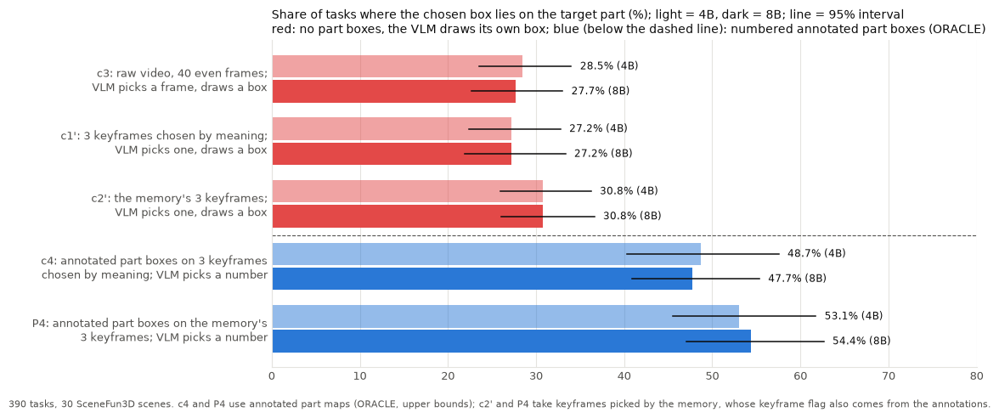

In [4]:
show(headline_figure(D["c4b"], D["c8b"]))

**怎么看：** 有没有部件框，差约 20 到 25 个百分点（上三组对下两组）。有了部件框之后，"记忆挑的画面"（P4）比"按语义挑的画面"（c4）只多几个点。没有部件框时，记忆挑的画面（c2'）比按语义挑的（c1'）也只多几个点。

### 1. 本周时间线

下图是每天的提交数和那天发生的事。**注意日期的口径：** 账本按工作日记录，第 7 到第 10 轮都记在 11-13；但 11-13 晚上的工作一直做到 11-14 凌晨，所以 11-14 的 24 个提交大多属于 11-13 的那几轮。

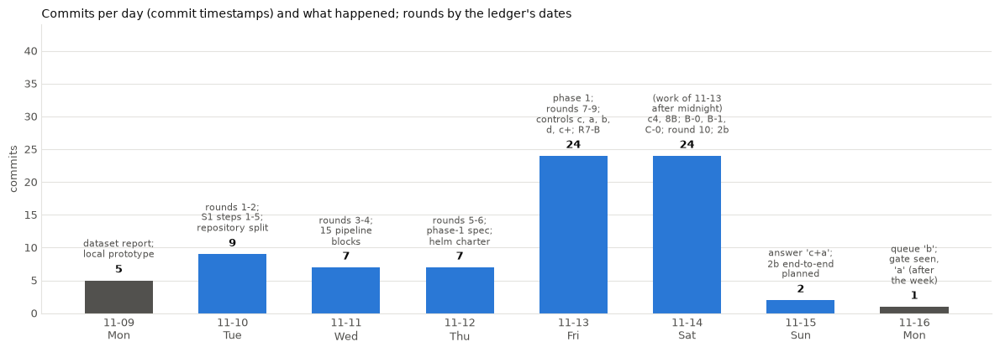

In [5]:
show(timeline_figure())

**按天看**

| 日期 | 做了什么 | 提交数 |
| --- | --- | --- |
| 11-09（周一） | 组会的数据报告（`report/2026-11-09_datasets_report.ipynb`）；本地原型：RGB-D 几何、DINOv2 特征、体素记忆；SceneFun3D 的读取和 E0 对齐检查。这一天记忆方向还没有单独分出来 | 5 |
| 11-10（周二） | 记忆方向开题（讨论稿 §1–§10）；第 1、2 轮；S1 第 1–5 步（ORACLE 版：只用视频、深度和位姿算接触点、表面朝向和站立点）；SMPL-X 人形和短动画；整条 pipeline 的演示 notebook；仓库拆分：VLA 方向移到独立仓库 `affordance-vla`；工作环境迁到实验室的服务器 | 9 |
| 11-11（周三） | 服务器环境；流程细化成 15 个环节（pipeline 工作 notebook）；第 3 轮（记忆带时间、不做稠密重建、存储倾向隐式）；第 4 轮（存储形式定为 L2） | 7 |
| 11-12（周四） | L2 记忆的代码，每个环节一个示例；第 5 轮（研究层面的评估和路线，提案）；第 6 轮（采纳"功能记忆"，以 NeurIPS 为主，批准阶段 1，规格和 G1 规则在跑之前写定）；接入 research-helm（章程、账本、提案 P-1）；阶段 1 的工具 | 7 |
| 11-13（周五） | 阶段 1 跑完并记录（§22）；审稿后的归因检查（§23）和三轮审稿；第 7 轮简报改写成一份白话文档、附流程图；G1 通过；第 8 轮复述你描述的论文；对照 c；R7-B 模拟；动作类型的检验；第二批 a、b、d、c+；第 9 轮简报和你的回答 | 24 |
| 11-14（周六，提交日期） | 账本记在 11-13 的工作：P-3 写进章程；现成工具的桌面核对；B-0、B-1、C-0；c4、c1'、c2'（4B 和 8B）；动作键检查；C-1 的代码和 M4；第 10 轮评估和你的回答；2b 的计划、代码和结果；P-4 | 24 |
| 11-15（周日） | 你对 2b 结果的回答"c+a；P-4 先不批"；§26.2 端到端版本的计划和代码 | 2 |
| 11-16（周一，本周之后） | 服务器网络断了一阵；你对队列位置的回答"b"；两个小作业插到前面并跑完；示例图给你看过，你定"a，插到前面"（只用 SAM 3），SAM 3 的全部运行排到前面；C-1 试跑发现答案格式问题，改了 V 的提问（D-11）并重新排队 | 1（只列到本 notebook 第一版之前的提交） |

**按轮看**（第 1–6 轮在接入 research-helm 之前完成，账本只做索引，没有逐字记下你的回答；这几轮写的是讨论稿记下的决定，有原话的标了引号）

| 轮 | 日期 | 问了什么 | 你的回答（原话，节选） | 之后做了什么 |
| --- | --- | --- | --- | --- |
| 1 | 11-10 | 核心主张、输入、人形的用途、定位、能否自录数据 | 无逐字记录；章程引用的原话："自录的非公开数据难以证明效果，也无法与其他基准对比" | 定位为"部件级 4D 功能记忆"；从视频开始，三维重建只当训练和评测的真值；人形只用于展示；以 H3（交互帮助构建）、H2（事件帮助检索）为主（§11）；设计 v0.2（§12） |
| 2 | 11-10 | 深度、位姿、人形展示、动作词表、顺序 | 无逐字记录 | 单目深度为主、LiDAR 作对比；允许设备位姿；用 SceneFun3D 的 9 类动作；依次推进 S1→S2→S3；逐步向导师汇报（§14） |
| 3 | 11-11 | 对需求的理解、"不做稠密重建"、精度分两档、阶段安排、总览 v2 | 无逐字记录 | 记忆带时间、记录实际发生的动作；不做稠密重建；先"找到并走到跟前"、再"碰到"；存储倾向隐式（§18） |
| 4 | 11-11 | 隐式到哪一档、哪些保持显式、几何量、谁来读记忆、用哪种特征 | 无逐字记录 | 存储形式 L2：每张关键帧的图，加部件 token 和薄的显式索引；接触点等几何在读取时现算（§19）；15 个环节各一个示例 |
| 5 | 11-12 | 确认总览 v2；你要一次研究层面的点评 | "流程基本理解，也大致没有问题"（章程引用）；同时认为作为研究课题还不够 | 评估和路线（提案）：主张"功能记忆"，预测 A（写在哪里）、B（事件）、C（代价），四个阶段、三个关口（§20） |
| 6 | 11-12 | 主张、目标会议、阶段 1、人形 | 无逐字记录 | 采纳"功能记忆"；NeurIPS 为主、ICCV 到 G2 定；批准阶段 1；人形降为补充材料里的演示；阶段 1 的规格和 G1 的判定规则在跑之前写定（§21） |
| 7 | 11-12 到 11-13 | 阶段 1 的结果：G1 是否通过、贡献怎么划分、补哪些对照、用什么真实场景讲 | "通过，按收窄后的含义"；"……最好还是使用传统的vlm模型直接读取原video来完成整体系统的对比"；"都做，但是先做c在做其他"；"我希望优先一和三，二作为补充说明"；另外要求"之后每次阶段性汇报的时候，都给我一个流程图" | G1 过；对照 c 里加了"直接读原视频"一组（D-6）；使用场景以家里的使用指导、无障碍与远程协助为主；以后每次阶段汇报附流程图、决定集中在一份文档 |
| 8 | 11-13 | 复述你在聊天里描述的论文（CA 新构建方法、CB 按功能搜索、CC 更快更准、CD 动作类更强），5 处确认 | "1 对；2 同意；4 参考其他模型的比较，尽量能够横向对齐；5 同意"；""action 的方向"指AC，但是为了能够具有平行比较的能力，希望能够同时做B" | 4 个调研代理（已有的构建方法、对手的设置、B 和 C 的可行性、四项贡献的撞车检查）；章程提案 P-2 |
| 9 | 11-13 | 对照 c 和调研之后：论文重心放在甲、乙、丙哪个；B、C 的头两步；换 8B；补 c4、c1'、c2' | "1 乙；1b 同意你的建议；2 批，并且先做问题 7 和问题 6a；3 批；4 可以；5 批；6a 批，插到队列前面；6b 同意你的建议；7 同意你的建议" | 收回第 8 轮"新构建方法是贡献"那一条，记为 DF-4；P-3 批准并写进章程；SAM 3 许可证"可以，同意许可证，从镜像下载"、GPU"批到 7 小时"；B-0 修补后"1 接受"；c4 接近 P4，按规则停下讨论（"同意你的建议"） |
| 10 | 11-13 | 评估：主张改成"检索变难时"；恢复问题 2 的检查；停的规则；2b；动作方向；B；C-1 的规则 | "1 同意；2 恢复；3 b；4 批；5 b；6 a；7 同意你的建议，a" | 2b 当天写计划、跑完：检索这一步没过；P-4 写好待批 |
| — | 11-15 | 2b 之后怎么走：(a) 测端到端；(b) 接受结果、到 G2；(c) 先只做现成工具的检查 | "c+a；P-4 先不批" | 两件都做；§26.2 的计划写明"这是第一步没过之后才加的检查"；代码写好、排队 |
| — | 11-16 | 网络断后队列里有 793 个作业：两个小作业要不要插到前面 | "b" | 示例图和 C-1 试跑插到前面；2b 端到端不动 |
| — | 11-16 | 看过示例图之后：(a) 只用 SAM 3 全部跑，Qwen 这次不做；(b) 先改 Qwen 的提示词再看；(c) 两个都跑 | "a，插到前面" | 流程关口算通过；只跑 SAM 3（以它为准），Qwen 的检测不做；这项检查的 GPU 作业插到前面 |

### 2. 流程图：现在的流程和第 10 轮的目标

**怎么看这张图**
- **下面两行是今天的流程。** "写入"每段视频做一次，结果就是记忆；"读取"每来一个问题做一次。
- **最上面一行是第 10 轮采纳的目标里要变的东西。** 灰色表示还没做；虚线指向它要替换或改变的那个方框。
- **颜色：** 绿色只用输入算；橙色暂时用标注（ORACLE）；蓝色是没训练的公开模型；灰色还没做。斜线表示这个方框吃的是 ORACLE 方框的输出，所以它的数字也是上限。
- **红框和红标签（Pred1、Pred2、Pred3）：** 第 10 轮主张的三个预测落在流程的哪里。图下面每一行的方括号是这个预测的证据现在到哪一步（照记录写，不是新结果）。灰色"design"一行是不声称的机制。

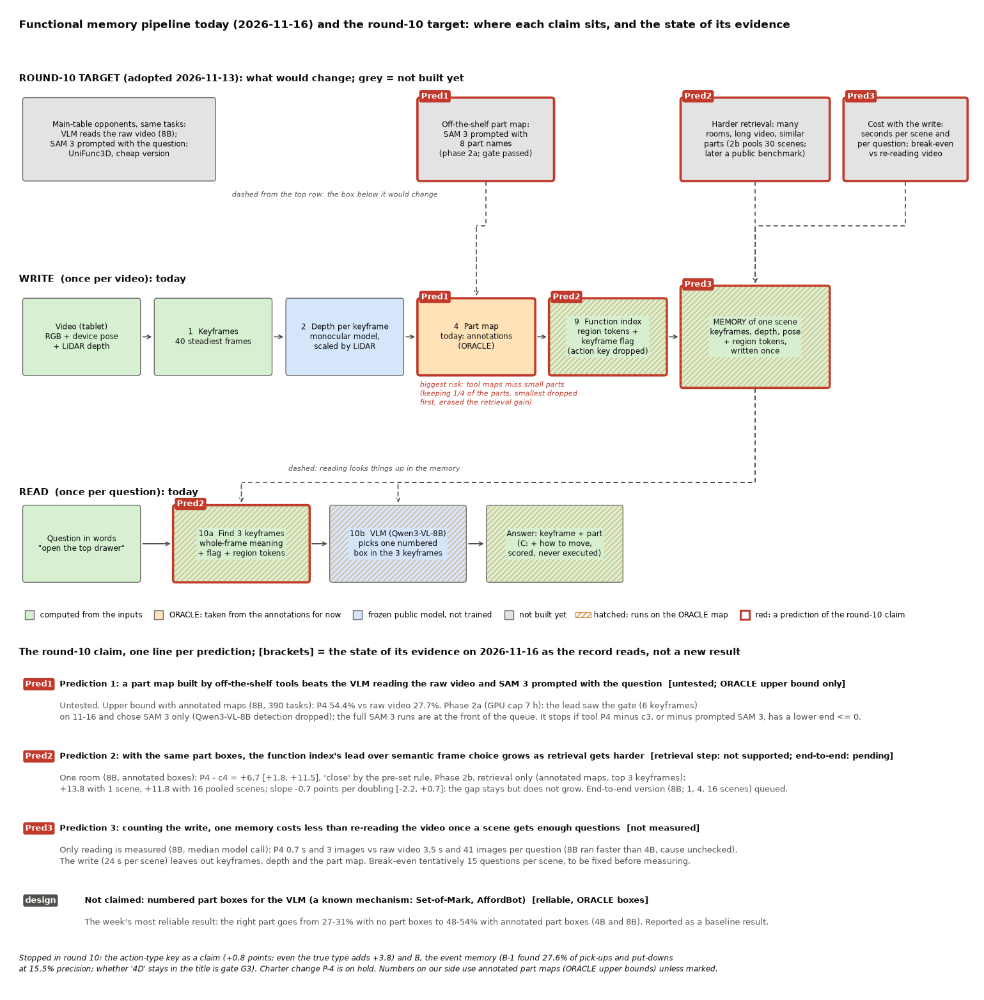

In [6]:
show(FC.draw(FC.CHARTS["now_target_r10"]))

| 标记 | 对应的预测 | 证据现在到哪一步 |
| --- | --- | --- |
| Pred1 | 预测 1：现成工具从视频建出的部件图，交给同一个视觉语言模型，比它直接读原视频、比"用问题文字直接提示 SAM 3"都更准 | **没测。** 阶段 2a 已批（GPU 上限 7 小时）；11-16 你看过示例图，定"a，插到前面"：只用 SAM 3，全部运行已排到前面。只有上限：标注部件图的 P4 54.4% 对直接读原视频 27.7%（8B，§24.8） |
| Pred2 | 预测 2：同样的部件框下，检索越难，功能索引比语义挑画面强得越多 | **检索这一步不支持**（2b，§26）：差一直在（+11.8 到 +17.8），斜率 −0.7 [−2.2, +0.7]。端到端版本排队中（§26.2） |
| Pred3 | 预测 3：把写入算进去，同一个场景问到一定次数之后，写一次的记忆比每次重读视频省 | **没测。** 只量了读：每个问题 P4 0.7 秒、3 张图，读原视频 3.5 秒、41 张图（8B 中位数，只算模型调用）。写入的 24 秒不含选关键帧、单目深度和建部件图。"划算点"暂定 15 个问题，测之前再定 |
| design（不声称） | 编号部件框 | 可靠（4B、8B 一致，约 28% → 约 50%），但别人做过，只当基线结果 |

### 3. 实验结果

每一项按同样的五步写：**问的是什么**；**事先定的规则**（都在跑之前写进讨论稿）；**数字**；**按规则的判定**；**这意味着什么**。

#### 3.1 阶段 1（P0–P4）和 §23 的归因检查

**问的是什么：** 记忆预算相同时，token 写在 affordance 区域上（P4），是否比其他写法更常把正确的关键帧排在第一位（预测 A）。五种写法只有"token 写在哪里"不同：P0 只有整帧；P1 均匀网格；P2 随机位置；P3 通用区域（SAM 分出的、不知道哪里能操作的区域）；P4 affordance 区域。打个比方：在一本 40 页的相册里找"能开灯的开关"。P0 一页页看整张照片；P4 事先告诉你哪几页有可操作的东西，并把它们框出来。

**事先定的规则（§21.6，预算为 1 倍）：** "通过"要两条：P4 的"第一个关键帧对"高于 P3，差的区间不含 0；端到端选对部件的比例 P4 不低于 P3。"部分通过"：P4 只高于随机位置 P2。"不通过"：P4 不高于 P2。

**数字（ORACLE，§22.3；Qwen3-VL-4B 读图，阶段 1 的提示词和打分标准）：**

,第一个关键帧对,前 3 个关键帧里有,端到端选对部件（4B）,部件图
写法,,,,
P4 affordance 区域,"66.2% [60.0, 73.3]","84.4% [79.1, 90.1]","53.6% [46.2, 61.6]",标注（ORACLE）
P3 通用区域,"47.3% [39.5, 55.9]","69.2% [61.8, 76.4]","10.3% [7.5, 13.4]",不用部件图
P0 只有整帧,"45.6% [37.4, 54.5]","70.5% [64.3, 77.3]",没有做,不用部件图
P2 随机位置,"38.5% [32.0, 45.6]","64.0% [57.3, 70.8]",没有做,不用部件图


P4 minus P3, first keyframe right: +18.8 [+12.9, +24.9] points; rule category: passed (whether G1 passes is the lead's decision)


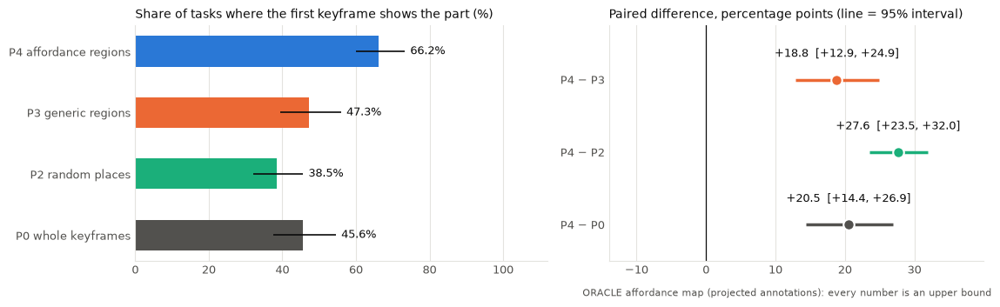

In [7]:
names = {"P4": "P4 affordance 区域", "P3": "P3 通用区域", "P0": "P0 只有整帧", "P2": "P2 随机位置"}
rows = []
for key, label in names.items():
    top3 = get("phase1", "right_keyframe_in_top3", key)
    reading = get("phase1", "reading", {"P4": "P4 affordance regions", "P3": "P3 generic regions"}[key]) if key in ("P4", "P3") else None
    rows.append({"写法": label, "第一个关键帧对": rate(get("phase1", "first_keyframe_right", key)), "前 3 个关键帧里有": rate(top3),
                 "端到端选对部件（4B）": rate(reading) if reading else "没有做", "部件图": "标注（ORACLE）" if key == "P4" else "不用部件图"})
display(pd.DataFrame(rows).set_index("写法"))
print("P4 minus P3, first keyframe right:", diff(get("phase1", "first_keyframe_right", "P4 minus P3")), "points;",
      "rule category:", get("phase1", "rule_21_6_category"), "(whether G1 passes is the lead's decision)")
show(R.headline_figure(D["phase1"]))

**审稿之后加的归因检查（§23，只用 CPU，计划在算之前写定）：** P4 同时得到了两样东西：token 的内容，和"哪些关键帧里有可操作部件"这一帧级标记（下文叫"比特"）。下图把两样分开。带斜线的两组拿到了和 P4 完全相同的关键帧。

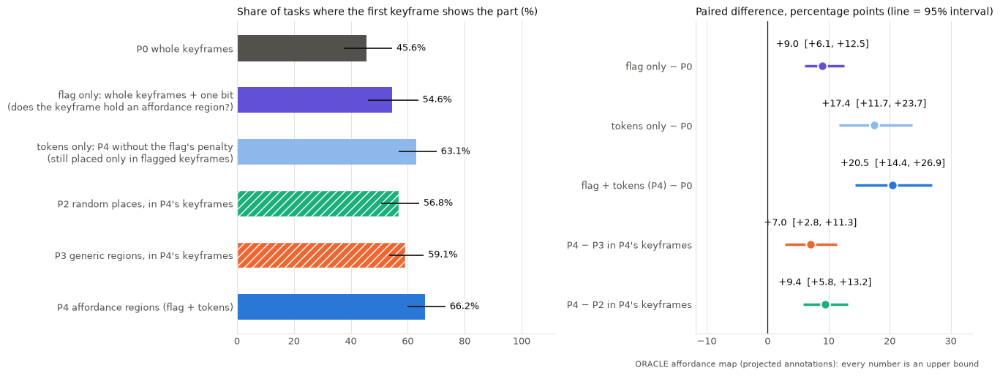

In [8]:
show(R.attribution_figure(D["diag"]))

| 成对比较（第一个关键帧对，ORACLE，§23.3） | 差（个百分点） |
| --- | --- |
| 只用比特（不写任何 token）减 P0 | +9.0 [+6.1, +12.5] |
| 只用 token（去掉空关键帧的扣分）减 P0 | +17.4 [+11.7, +23.7]（仍带着一部分比特的作用） |
| 两样都用（P4）减 P0 | +20.5 [+14.4, +26.9] |
| 同一批关键帧里，P4 减通用区域 | +7.0 [+2.8, +11.3]；token 的权重降到 0.5 或 0.25 时缩到 +1.3 到 +4.9 |

**按规则的判定：** 属于"通过"一档；§23 属于判读表的第一行（帧级信息之外，token 写在 affordance 区域上还有贡献）。你在第 7 轮的回答是"通过，按收窄后的含义"。

**这意味着什么：**
- 在 ORACLE 下，"按功能标记关键帧"本身就值 9 个点。"token 写在哪里"本身约 7 个点，而且随打分方式变化。
- 端到端 53.6% 对 10.3% 的大差距，主要来自"给模型的候选是什么"：给模型看的框里有一个在目标部件上的任务，P4 是 83.6%，P3 只有 20.0%。
- 作为参照，随便挑一张关键帧，对的概率是 9.2%。
- 没成立的：选相机转得慢的帧没有多看到部件（481 个对均匀取帧的 501 个，共 561 个标注部件）；从一张画面现算的接触点，3 厘米以内的只有 38.5%（按 481 个真实部件算，§22.5）。

#### 3.2 对照 c：不用记忆，让模型自己找（第一批，§24.1–24.5）

**问的是什么：** 你在第 7 轮要求"使用传统的vlm模型直接读取原video来完成整体系统的对比"。不用我们的记忆，同一个 4B 模型自己找部件，能不能接近 P4？
- **P4：** 记忆挑 3 张关键帧，标注区域加编号框，模型选编号。
- **c3：** 直接读原视频：按时间均匀取 40 帧，模型先挑一帧，再在这一帧的原分辨率上画框。
- **c2：** 记忆挑的 3 张关键帧，没有框，模型一次看 3 张、自己画框。
- **c1：** 按整张画面的语义挑 3 张，没有框，模型自己画框。

**事先定的规则（§24.3）：** 统一的"对"：框的中心落在目标部件上（部件向外放宽 8 个像素）。P4 减某组的区间下沿低于 5 个百分点算"接近"；差本身大于 10、只是区间太宽才低于 5，算"说不清"。c1 或 c3 接近 P4：不用记忆也能做到，停下来讨论。P4 领先：在 ORACLE 下是意料之中，只报告为"阶段 2 有多少余地"。

,给模型看什么,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,"53.1% [45.5, 61.7]",69.2%,1.2,3,—,—,标注（ORACLE，上限）
c3,均匀的 40 帧原视频；先挑帧再画框,"28.5% [23.5, 34.0]",54.4%,5.7,41,"+24.6 [+19.2, +31.5]",落后于 P4,不用（不是上限）
c2,记忆挑的 3 张；一次看 3 张、自己画框,"17.2% [13.4, 21.3]",66.9%,3.2,3,"+35.9 [+29.3, +43.2]",落后于 P4,不用；画面由记忆挑（用到标注的关键帧标记）
c1,按语义挑的 3 张；一次看 3 张、自己画框,"15.1% [11.7, 19.0]",59.2%,3.1,3,"+37.9 [+31.2, +45.4]",落后于 P4,不用（不是上限）


c2 minus c1 (choosing keyframes with the memory, the model draws): +2.1 [−1.1, +5.4] points
c3's 40 even frames show the target in 383 of 390 tasks (98.2%)


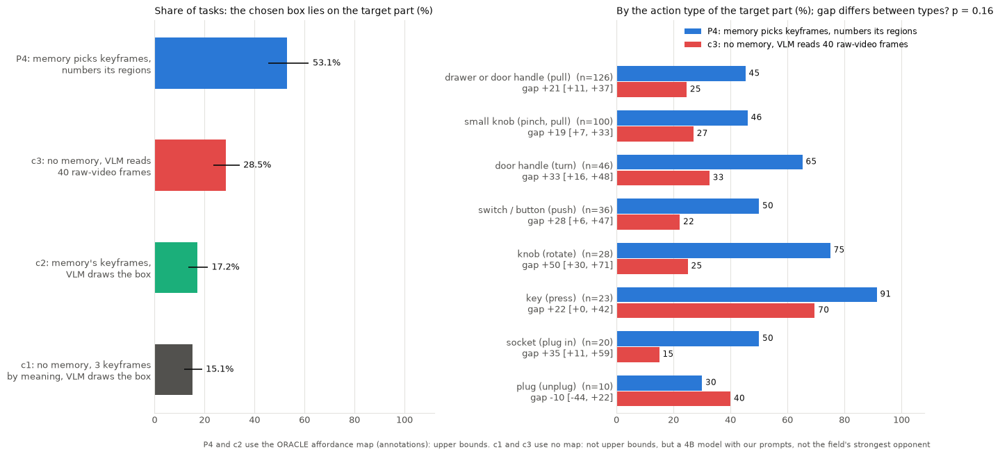

In [9]:
VERDICT = {"behind": "落后于 P4", "close": "接近", "unclear": "说不清"}


def arm_table(summary, arms):
    rows = []
    for arm, label, what, part_map in arms:
        a = summary["arms"][arm]
        against = summary["against_p4"].get(arm)
        rows.append({"组": label, "给模型看什么": what, "选对部件": rate(a["right_part"]), "选中的画面里有目标": f"{100 * a['right_frame']['rate']:.1f}%",
                     "每题秒数（中位数）": a["seconds_per_question"], "每题图数": int(a["images_per_question"]),
                     "P4 减这一组": diff(against) if against else "—",
                     "按规则": VERDICT.get(against["verdict"], against["verdict"]) if against else "—", "部件图": part_map})
    return pd.DataFrame(rows).set_index("组")


ORACLE_MAP, NO_MAP = "标注（ORACLE，上限）", "不用（不是上限）"
MEMORY_FRAMES = "不用；画面由记忆挑（用到标注的关键帧标记）"
display(arm_table(D["c4b"], [
    ("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
    ("c3", "c3", "均匀的 40 帧原视频；先挑帧再画框", NO_MAP),
    ("c2", "c2", "记忆挑的 3 张；一次看 3 张、自己画框", MEMORY_FRAMES),
    ("c1", "c1", "按语义挑的 3 张；一次看 3 张、自己画框", NO_MAP)]))
print("c2 minus c1 (choosing keyframes with the memory, the model draws):", diff(get("c4b", "choosing_keyframes")), "points")
print(f"c3's 40 even frames show the target in {get('ceiling', 'shown_in_uniform_frames')} of {get('ceiling', 'tasks')} tasks "
      f"({100 * get('ceiling', 'share'):.1f}%)")
show(R.controls_figure(D["c4b"], D["by_action"]["actions"], between_types_p=get("by_action", "heterogeneity_p4_minus_c3", "p_value")))

图的右半边按目标部件的动作类型拆开，第 3.6 节再讲。

**按规则的判定：** 没有一组"接近"。P4 减 c3 是 +24.6 [+19.2, +31.5]，P4 减 c1 是 +37.9 [+31.2, +45.4]：都"落后于 P4"，只算阶段 2 的余地。c2 减 c1 是 +2.1 [−1.1, +5.4]：只靠记忆挑画面、让模型自己画框，看不出帮助。

**这意味着什么：**
- P4 的领先主要来自**标注给出的部件框**，不能算成记忆的功劳（第 9 轮审稿的阻断项 V-38）。
- c3 低不是因为画面里没有目标：均匀的 40 帧在 98.2% 的任务里看得到目标部件。
- 读法有影响：画面挑对时，c3（先挑一帧、再在原分辨率上画框）框对约 52%（28.5 ÷ 54.4），c2（一次看 3 张直接画）只有约 26%（17.2 ÷ 66.9）。所以第 9 轮又补了 c1'、c2'（第 3.4 节）。

#### 3.3 第二批：a、b、d、c+（4B，§24.7）

**问的是什么：**
- **a（只做检索）：** 把全部通用区域、或全部网格档位都写进记忆，能不能在检索上追上 P4？
- **b：** P3 的通用区域用 5 个随机种子，和 P4 同样的读法、中性提示词。
- **d：** 在全部通用区域里得分最高的 40 个上加编号框，模型挑。
- **c+：** 不用记忆，把我们挑的 40 张关键帧给模型，先挑一张再画框（读法同 c3）。

**事先定的规则：** 沿用 §24.3。a 接近 P4 说明"全写进去也行"，P4 只赢在存得少；c+ 减 c3 是"我们挑的关键帧"对"均匀取帧"的价值，不算记忆的价值。

,给模型看什么,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,"53.1% [45.5, 61.7]",69.2%,1.20,3,—,—,标注（ORACLE，上限）
c+,我们挑的 40 张关键帧；先挑帧再画框,"26.4% [21.9, 31.7]",52.3%,4.40,41,"+26.7 [+20.8, +33.5]",落后于 P4,不用（不是上限）
d,记忆挑的 3 张上得分最高的 40 个通用区域,"14.1% [11.4, 17.1]",55.4%,0.80,3,"+39.0 [+31.3, +47.5]",落后于 P4,不用（通用区域）
b,和 P4 一样多的通用区域（5 个种子）,"11.4% [8.4, 15.0]",48.0%,0.84,3,"+41.6 [+34.5, +50.3]",落后于 P4,不用（通用区域）


,第一个关键帧对,每个场景的 token（中位数）,P4 减这一组
记忆里写什么,,,
P4 affordance 区域,"66.2% [60.0, 73.3]",63,—
a：全部网格档位,"53.6% [45.3, 62.2]",2960,"+12.6 [+6.1, +18.7]"
a：全部通用区域,"50.0% [44.1, 56.2]",2265,"+16.2 [+11.4, +21.7]"
P3 通用区域（1 倍）,"47.4% [39.9, 55.7]",63,—
P0 只有整帧,"45.6% [37.4, 54.5]",0,—


c+ minus c3 (our keyframes vs even frames, no memory): −2.1 [−6.6, +2.7] points


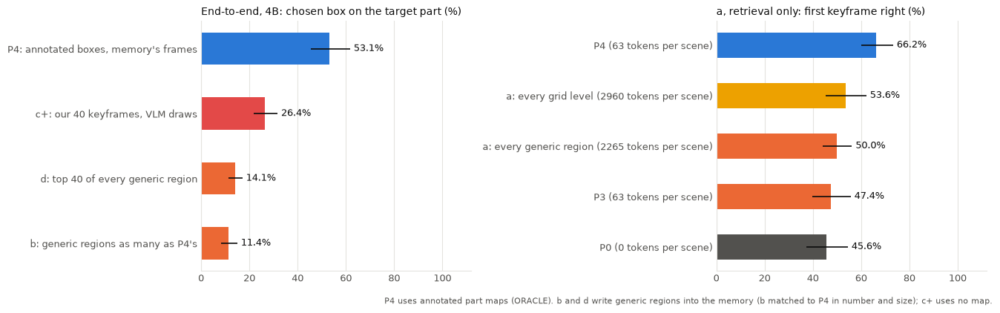

In [10]:
display(arm_table(D["c4b"], [
    ("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
    ("cplus", "c+", "我们挑的 40 张关键帧；先挑帧再画框", NO_MAP),
    ("d", "d", "记忆挑的 3 张上得分最高的 40 个通用区域", "不用（通用区域）"),
    ("b", "b", "和 P4 一样多的通用区域（5 个种子）", "不用（通用区域）")]))
a_names = {"P4": "P4 affordance 区域", "a: every grid level": "a：全部网格档位", "a: every generic region": "a：全部通用区域",
           "P3": "P3 通用区域（1 倍）", "P0": "P0 只有整帧"}
display(pd.DataFrame([{"记忆里写什么": label, "第一个关键帧对": rate(get("a", "arms", key)),
                       "每个场景的 token（中位数）": int(get("a", "arms", key, "tokens_per_scene")),
                       "P4 减这一组": diff(get("a", "against_p4", key)) if key.startswith("a:") else "—"}
                      for key, label in a_names.items()]).set_index("记忆里写什么"))
print("c+ minus c3 (our keyframes vs even frames, no memory):", diff(get("c4b", "our_keyframes_vs_even_frames")), "points")
rows = {arm: get("c4b", "arms", arm, "right_part") for arm in ("p4n", "cplus", "d", "b")}
a_rows = {key: get("a", "arms", key) for key in a_names}
fig, (left, right) = plt.subplots(1, 2, figsize=(13.5, 4.2))
R._rate_bars(left, rows, list(rows), ["P4: annotated boxes, memory's frames", "c+: our 40 keyframes, VLM draws",
                                      "d: top 40 of every generic region", "b: generic regions as many as P4's"], [BOX, NOBOX, GENERIC, GENERIC])
left.set_title("End-to-end, 4B: chosen box on the target part (%)", fontsize=10, loc="left", color=INK)
R._rate_bars(right, a_rows, list(a_rows), [f"{key} ({int(a_rows[key]['tokens_per_scene'])} tokens per scene)"
                                           for key, label in a_names.items()], [BOX, R.POLICY_COLOUR[R.A.P1], GENERIC, GENERIC, MUTED])
right.set_title("a, retrieval only: first keyframe right (%)", fontsize=10, loc="left", color=INK)
fig.tight_layout(rect=(0, 0.04, 1, 1))
R._oracle_note(fig, "P4 uses annotated part maps (ORACLE). b and d write generic regions into the memory (b matched to P4 in number and size); c+ uses no map.")
show(fig)

*（上图只画了端到端的四组；检索那一组 a 见上面第二张表。）*

**按规则的判定：** 四组都"落后于 P4"。c+ 减 c3 是 −2.1 [−6.6, +2.7]。a：全部网格档位 53.6%、全部通用区域 50.0%，都低于 P4 的 66.2%（ORACLE）。

**这意味着什么：** 在 ORACLE 下，标注的部件框比任何通用区域的框都好得多，不论只放和 P4 一样多（b）还是全部写进去（d）。P4 不只存得少（每个场景约 63 个 token，对两三千个），检索也更准。把均匀帧换成我们挑的关键帧，对直接读画面的模型没有帮助。

#### 3.4 c4、c1'、c2'，以及换成 8B（§24.8）

**问的是什么：** 记忆本身值多少。
- **c4：** 同样的标注框，但画面不用记忆挑，而是按整张画面的语义挑 3 张（c1 的画面）。P4 减 c4 是"记忆挑画面"的价值（仍是上限：记忆挑画面时用到了标注的关键帧标记）。
- **c1'、c2'：** c1、c2 改用 c3 的读法（先挑一张，再在原分辨率上画框）。c2' 减 c1' 是同一种读法下"挑画面"的价值。
- **8B：** 换成 2026 年论文里默认的 Qwen3-VL-8B，在 390 个任务上把这几组都再跑一遍。

**事先定的规则（4B、8B 各读一次）：** P4 减 c4 的区间下沿低于 5 个百分点记为"接近"：第 9 轮选的方案乙以"按功能建索引"为重心，所以停下来讨论。c2' 减 c1' 的区间下沿大于 0 记为"有价值"，否则"看不出"。8B 的 c1 或 c3 接近 P4：停下来讨论。

Qwen3-VL-8B (4B for comparison):


,给模型看什么,4B 的结果,8B 减 4B,选对部件,选中的画面里有目标,每题秒数（中位数）,每题图数,P4 减这一组,按规则,部件图
组,,,,,,,,,,
P4,记忆挑的 3 张，标注区域加编号框,53.1%,"+1.3 [−2.7, +5.1]","54.4% [47.1, 62.6]",68.5%,0.7,3,—,—,标注（ORACLE，上限）
c4,按语义挑的 3 张，标注区域加编号框,48.7%,"−1.0 [−4.4, +2.3]","47.7% [40.9, 55.3]",60.5%,0.6,3,"+6.7 [+1.8, +11.5]",接近,标注（ORACLE，上限）
c2',记忆挑的 3 张；先挑一张再画框,30.8%,"+0.0 [−3.6, +4.0]","30.8% [26.1, 36.6]",65.6%,1.7,4,"+23.6 [+18.2, +29.5]",落后于 P4,不用；画面由记忆挑（用到标注的关键帧标记）
c3,均匀的 40 帧原视频；先挑帧再画框,28.5%,"−0.8 [−5.6, +5.0]","27.7% [22.6, 33.0]",58.5%,3.5,41,"+26.7 [+21.5, +32.7]",落后于 P4,不用（不是上限）
c1',按语义挑的 3 张；先挑一张再画框,27.2%,"+0.0 [−3.8, +3.9]","27.2% [21.9, 33.3]",54.1%,1.7,4,"+27.2 [+21.3, +33.6]",落后于 P4,不用（不是上限）
c1,按语义挑的 3 张；一次看 3 张、自己画框,15.1%,"−3.3 [−6.0, −0.8]","11.8% [8.7, 15.2]",58.7%,2.2,3,"+42.6 [+35.4, +50.5]",落后于 P4,不用（不是上限）


c2' minus c1' (choosing keyframes, same reading):  4B +3.6 [−0.9, +8.1]   8B +3.6 [−0.8, +8.2]


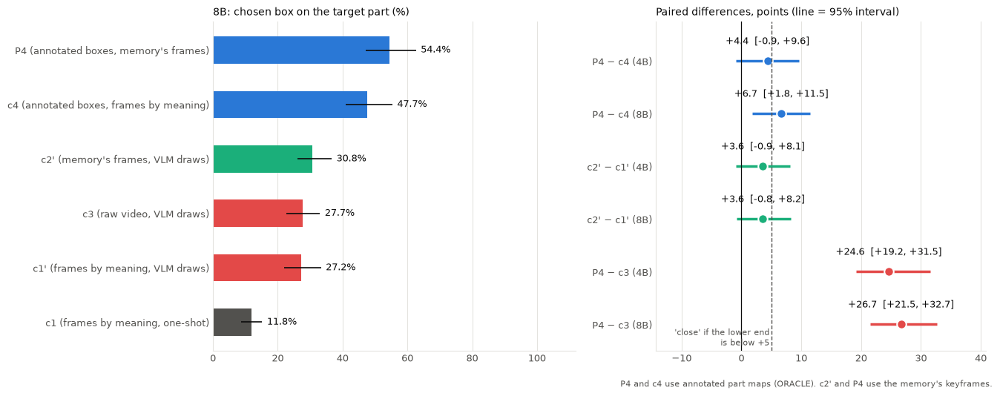

In [11]:
arms8 = [("p4n", "P4", "记忆挑的 3 张，标注区域加编号框", ORACLE_MAP),
         ("c4", "c4", "按语义挑的 3 张，标注区域加编号框", ORACLE_MAP),
         ("c2s", "c2'", "记忆挑的 3 张；先挑一张再画框", MEMORY_FRAMES),
         ("c3", "c3", "均匀的 40 帧原视频；先挑帧再画框", NO_MAP),
         ("c1s", "c1'", "按语义挑的 3 张；先挑一张再画框", NO_MAP),
         ("c1", "c1", "按语义挑的 3 张；一次看 3 张、自己画框", NO_MAP)]
table8 = arm_table(D["c8b"], arms8)
table8.insert(1, "4B 的结果", [f"{100 * get('c4b', 'arms', arm, 'right_part', 'rate'):.1f}%" for arm, *_ in arms8])
table8.insert(2, "8B 减 4B", [diff(get("c8b", "against_4b", arm)) for arm, *_ in arms8])
print("Qwen3-VL-8B (4B for comparison):")
display(table8)
print("c2' minus c1' (choosing keyframes, same reading):  4B", diff(get("c4b", "choosing_keyframes_same_reading")),
      "  8B", diff(get("c8b", "choosing_keyframes_same_reading")))
diffs = {"P4 − c4 (4B)": get("c4b", "against_p4", "c4"), "P4 − c4 (8B)": get("c8b", "against_p4", "c4"),
         "c2' − c1' (4B)": get("c4b", "choosing_keyframes_same_reading"), "c2' − c1' (8B)": get("c8b", "choosing_keyframes_same_reading"),
         "P4 − c3 (4B)": get("c4b", "against_p4", "c3"), "P4 − c3 (8B)": get("c8b", "against_p4", "c3")}
rows = {arm: get("c8b", "arms", arm, "right_part") for arm in ("p4n", "c4", "c2s", "c3", "c1s", "c1")}
show(bars_and_differences(
    rows, list(rows), ["P4 (annotated boxes, memory's frames)", "c4 (annotated boxes, frames by meaning)", "c2' (memory's frames, VLM draws)",
                       "c3 (raw video, VLM draws)", "c1' (frames by meaning, VLM draws)", "c1 (frames by meaning, one-shot)"],
    [BOX, BOX, MEMORY, NOBOX, NOBOX, R.POLICY_COLOUR[R.A.P0]], diffs, list(diffs), list(diffs),
    [BOX, BOX, MEMORY, MEMORY, NOBOX, NOBOX], "8B: chosen box on the target part (%)", "Paired differences, points (line = 95% interval)",
    "P4 and c4 use annotated part maps (ORACLE). c2' and P4 use the memory's keyframes.", rule_at=5,
    rule_text="'close' if the lower end\nis below +5"))

**按规则的判定：**
- **c4 接近 P4，4B 和 8B 都是：** 4B +4.4 [−0.9, +9.6]，8B +6.7 [+1.8, +11.5]。8B 的区间下沿大于 0 但低于 5：记忆挑画面有一点用，但不到"明显不接近"的程度。按规则停下讨论，这就是第 10 轮评估的起点。
- **c2' 减 c1'：** 4B +3.6 [−0.9, +8.1]，8B +3.6 [−0.8, +8.2]：同一种读法下，记忆挑画面看不出价值。
- **8B 没有接近 P4 的不用记忆的组。** 换成 8B 几乎没有变化：各组 8B 减 4B 都在 ±3.3 个百分点以内。c1'、c2' 的 4B、8B 总数恰好相同，记录里核对过：780 个答案全都不一样，只是总数巧合（§24.8）。

**这意味着什么：** 不论 4B 还是 8B，P4 比直接读原视频高出的约 25 个百分点，几乎都来自"有部件的框"（affordance map 本身），而不是记忆挑画面。按事先的规则，这一条让第 9 轮的方案乙（以按功能建索引为重心）失去了大半支撑。

**时间（只算模型调用，中位数，不含写入）：** 8B 的 P4 每题 0.7 秒、3 张图；c3 3.5 秒、41 张图。4B 的 P4 1.2 秒、c3 5.7 秒。8B 反而比 4B 快，原因没查（可能是不同的卡、不同的负载），这些时间只能粗看。

#### 3.5 R7-B：漏检和误检的模拟（§24.6）

**问的是什么：** 自己建的部件图会漏掉部件（漏检），也会把不能操作的地方当成部件（误检）。漏多少、错多少以内，按功能建的记忆在检索上仍然比通用区域好？只用 CPU，扰动的是标注。

**事先定的规则：** 每一格和 P3（通用区域，47.4%）成对比较：区间下沿大于 0 记为"明显好于 P3"。**门槛：** 误检为真部件数的 0.5 倍时，从留 100% 往下，一直明显好于 P3 的最低留存比例。如果留 100%、误检 0.5 倍时已经不明显好于 P3，说明对误检很敏感。

**数字：** 下图上排是事先写定的规则；下排是第 9 轮第 2 次审稿后的更严的重算（中心落在任何部件上的通用区域都不算误检；规则在算之前写定）。格子里是"第一个关键帧对"的比例，标"= P3"的格子不明显好于 P3。

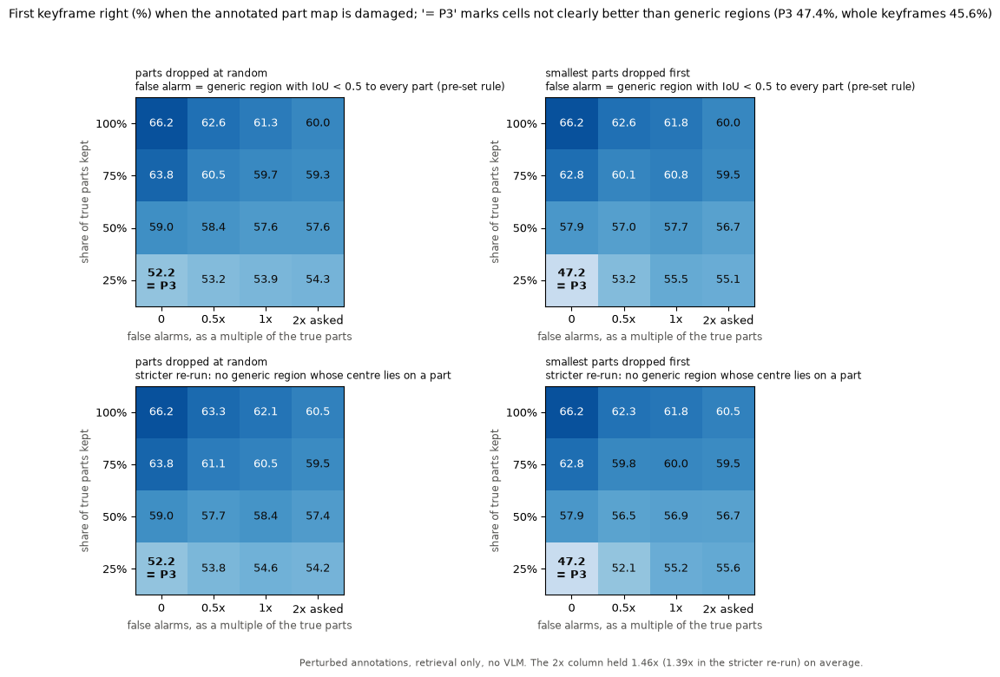

kept 100%, false alarms 0.5x, minus P3: +15.2 [+10.4, +20.3] points; thresholds (pre-set rule): {'random': 0.25, 'smallest_first': 0.25} ; stricter re-run: {'random': 0.25, 'smallest_first': 0.25}


In [12]:
show(map_error_figure(D["errors"], D["errors_centre"]))
cell = get("errors", "grid", "random", "1", "0.5")
print("kept 100%, false alarms 0.5x, minus P3:", diff(cell["against_p3"]), "points;",
      "thresholds (pre-set rule):", get("errors", "threshold_keep_share"), "; stricter re-run:", get("errors_centre", "threshold_keep_share"))

**按规则的判定：** 两种丢法的门槛都是 25%，也就是试到的最低一档。留 100%、误检 0.5 倍时仍明显好于 P3（+15.2 [+10.4, +20.3]），按读法记为"在检索这一步对误检不敏感"。更严的重算结论不变（留 100%、误检 0.5 倍：随机丢 63.3%、先丢小的 62.3%，原来都是 62.6%）。

**这意味着什么：**
- 在检索这一步，**漏检比误检要紧**：误检到 1 倍时少 4 到 5 个百分点；漏掉一半部件时少 7 到 8 个；先丢小的、只剩四分之一时（47.2%），和 P3 看不出差别。
- 措辞要窄（第 10 轮评估的审稿 V-73）："对误检不敏感"只指检索这一步、误检和部件一样大的时候，而且一部分来自"空关键帧扣 3 分"这个常数（只留 25% 时加误检分数反而上升）。读图那一步对误检可能敏感得多：b、d 在通用区域的框里挑，只有 11% 到 14%。
- 真实工具的误检常常是整个物体的大框，这里模拟不到；要靠阶段 2a 的真实输出来量。

#### 3.6 动作类型：差距在动作类型之间是否不同（p = 0.16），和按动作类型检索（§24.5、§24.10）

**问的是什么：** 你在第 7 轮写过，希望"一些关于action的方向上又格外高的performance"。两个检查：
1. **检验（§24.5，规格之外，计算前写定）：** P4 对 c3 的差距（第 3.2 节图的右半边），在动作类型之间是否真的不同。在每个场景内部打乱动作标签 10,000 次，看实际的离散程度是否大于随机分组。规则：p < 0.05 记为"确实不同"，否则"看不出不同"。
2. **动作键检索（§24.10，只用 CPU，上限）：** 给每个区域加一个"功能的键"（例如 "rotate a knob or a dial"），检索时按任务文字匹配这个键。五组：不加键（就是 P4）、动作短语、只有部件词、只有动词、真值动作类型（按真值筛选的上限）。规则：动作短语减不加键的区间下沿大于 0 记为"有用"；真值减不加键本身不到 5 个百分点，记为"按动作类型检索的余地很小"。

test: 389 tasks, 8 action types, 10,000 shuffles within scenes, p = 0.159


,第一个关键帧对,减不加键
检索键,,
no key (= P4),"66.2% [60.0, 73.3]",—
action phrase,"66.9% [60.7, 74.0]","+0.8 [−0.9, +2.4]"
part words only,"66.7% [60.1, 74.4]","+0.5 [−1.1, +2.3]"
verb only,"66.7% [60.9, 73.6]","+0.5 [−0.6, +1.7]"
true action type (upper bound),"70.0% [63.4, 77.5]","+3.8 [+0.9, +7.5]"


verb only minus part words only: +0.0 [−2.4, +2.2] points


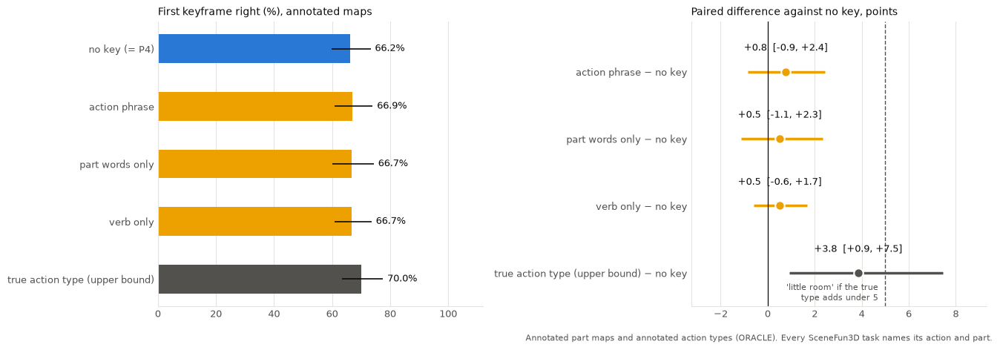

In [13]:
het = get("by_action", "heterogeneity_p4_minus_c3")
print(f"test: {het['tasks']} tasks, {het['action_types']} action types, {het['shuffles']:,} shuffles within scenes, p = {het['p_value']:.3f}")
key_names = {"no key": "no key (= P4)", "action phrase": "action phrase", "part words only": "part words only", "verb only": "verb only",
             "true type": "true action type (upper bound)"}
rows = {key: get("key", "arms", key) for key in key_names}
against = {key: get("key", "against_no_key", key) for key in key_names if key != "no key"}
display(pd.DataFrame([{"检索键": label, "第一个关键帧对": rate(rows[key]), "减不加键": diff(against[key]) if key in against else "—"}
                      for key, label in key_names.items()]).set_index("检索键"))
print("verb only minus part words only:", diff(get("key", "verb_minus_part")), "points")
show(bars_and_differences(
    rows, list(rows), list(key_names.values()), [BOX, "#eda100", "#eda100", "#eda100", MUTED], against, list(against),
    [f"{key_names[k]} − no key" for k in against], ["#eda100", "#eda100", "#eda100", MUTED],
    "First keyframe right (%), annotated maps", "Paired difference against no key, points", "Annotated part maps and annotated action "
    "types (ORACLE). Every SceneFun3D task names its action and part.", rule_at=5, rule_text="'little room' if the true\ntype adds under 5"))

**按规则的判定：** 检验 p = 0.16（389 个任务、8 个动作类型），记为"看不出不同"。动作短语 +0.8 [−0.9, +2.4]，记为"看不出有用"；真值 +3.8 [+0.9, +7.5]，不到 5 个点，记为"余地很小"；动词和部件词没有差别（0.0 [−2.4, +2.2]）。

**这意味着什么：**
- SceneFun3D 的每个任务都点明了动作和部件（"Rotate the knob…"），所以按语义检索本身已经带上了动作的信息；动作类型又几乎就是部件类型（转的是旋钮、拉的是拉手）。
- 第 10 轮你选了 (b)：在 2b 里再加一组，看相似部件多时动作键有没有用。结果也没有用（第 3.7 节）。所以按评估，"按动作类型检索"不再当主张，动作方向改由 C（能直接拿去做的回答）来体现。

#### 3.7 阶段 2b：把多个场景的关键帧混在一起检索（§26）

**问的是什么：** 预测 2 的第一步：检索变难时，功能索引挑画面比语义挑画面强多少，这个差是否随难度变大。做法：对每个目标场景，把它的 40 张关键帧和另外 K − 1 个场景的关键帧混成一个记忆（K = 1、2、4、8、16；别的场景随机抽 5 次）。目标场景的任务只能在目标场景里找到对的；混进来的场景带来更多同类的部件（别的抽屉、别的开关）。两边用同样的标注部件图，只是挑画面的办法不同。

**事先定的规则：** 看"前 3 张里有没有对的"（读图那一步看的就是前 3 张）。功能索引减语义的差对 log2 K 的斜率，区间下沿大于 0，而且 K = 16 时差本身至少 5 个百分点，才算"支持"。动作键那一组同样读法。

,同动作类型的标注区域（中位数）,语义,功能索引,功能索引 + 动作键,功能索引减语义,动作键减功能索引
K（混进来的场景数）,,,,,,
1,16,"70.5% [64.3, 77.3]","84.4% [79.1, 90.1]","84.4% [78.9, 90.2]","+13.8 [+8.7, +19.2]","+0.0 [−1.7, +1.7]"
2,28,"59.9% [52.7, 67.2]","77.8% [73.1, 82.8]","76.9% [71.7, 82.6]","+17.8 [+12.8, +23.0]","−0.9 [−2.8, +0.9]"
4,71,"51.0% [43.3, 59.1]","68.2% [62.7, 74.0]","67.4% [61.8, 73.1]","+17.2 [+12.7, +21.9]","−0.8 [−3.0, +1.2]"
8,143,"40.9% [33.5, 48.9]","56.0% [49.9, 62.7]","55.3% [49.1, 61.9]","+15.1 [+11.0, +19.3]","−0.7 [−3.6, +1.7]"
16,283,"32.7% [25.3, 40.3]","44.6% [38.8, 51.2]","45.1% [38.5, 51.5]","+11.8 [+8.3, +15.7]","+0.5 [−2.0, +2.6]"


function index minus semantic: slope −0.7 [−2.2, +0.7] points per doubling, gap at K = 16 +11.8, supported: False
function index + action key minus function index: slope +0.1 [−0.7, +0.9] points per doubling, gap at K = 16 +0.5, supported: False


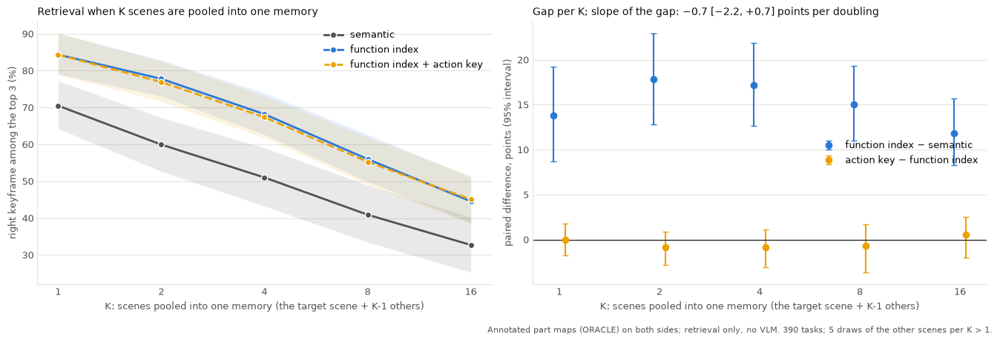

In [14]:
rows = []
for k in get("pooled", "pool_sizes"):
    per = get("pooled", "per_size", str(k))
    rows.append({"K（混进来的场景数）": k, "同动作类型的标注区域（中位数）": round(per["median_same_type_regions"]),
                 "语义": rate(per["semantic"]["top3"]), "功能索引": rate(per["function index"]["top3"]),
                 "功能索引 + 动作键": rate(per["function index + action key"]["top3"]),
                 "功能索引减语义": diff(per["function index minus semantic (top3)"]),
                 "动作键减功能索引": diff(per["function index + action key minus function index (top3)"])})
display(pd.DataFrame(rows).set_index("K（混进来的场景数）"))
for name, reading in get("pooled", "readings").items():
    print(f"{name}: slope {diff(reading['slope_per_doubling'])} points per doubling, gap at K = 16 "
          f"{100 * reading['gap_at_largest']:+.1f}, supported: {reading['supported']}")
show(pooled_figure(D["pooled"]))

**按规则的判定：** 斜率 −0.7 [−2.2, +0.7]，区间包含 0：**预测 2 的第一步在检索这一步不支持。** 差一直在（+11.8 到 +17.8），但不随难度变大。动作键那一组斜率 +0.1 [−0.7, +0.9]，K = 16 时 +0.5：相似部件多时也没有用。

**这意味着什么：**
- 只作描述：检索这一步，功能索引在每个 K 都多找到 12 到 18 个百分点的对画面。但在单个房间里，读图那一步有了部件框就把这个差抹掉了大半（c4，第 3.4 节）。K 变大时，语义挑的前 3 张里常常一张对的都没有（K = 16 时有对的只占 32.7%），读图就补不回来。所以端到端的差会不会随 K 变大，这次没测。
- **局限：** 混进来的是别的房间，房间本身的样子会帮语义检索把它们分开，比"同一个长视频里的相似部件"容易；标注的部件图，是上限。
- **这就是 §26.2 端到端版本的来由。** 它是第一步没过之后才加的检查，§26.2 和账本都写明了这一点：8B 读编号框，K = 1、4、16，每个 K 一组抽样；斜率区间下沿大于 0 且 K = 16 时差至少 5 个点，记为"端到端支持预测 2"，否则按评估第 10 节到关口 G2。K = 1 应当接近 8B 的 P4 和 c4（54.4%、47.7%），作为核对。现在排在你的作业后面。

#### 3.8 B-0、B-1：HD-EPIC 上问"做过什么"的头两步（§25.1、§25.2、§25.4）

**问的是什么：** B 是"做过什么"类的问题（例如"抽屉开了几次""这个物体被挪到了哪里"）。你在第 8 轮说"希望能够同时做B"以便平行比较。头两步只用 CPU，在厨房 P02 上：
- **B-0：** HD-EPIC 的 242 道题能不能对上标注里的事件，用论文的规则能不能重新算出答案。
- **B-1：** 不用标注，只靠 Aria 眼镜算出的手掌位置（第 9 轮你回答"可以"当输入），能不能找出"拿起、放下"的时刻。

**事先定的规则：** B-0：至少 90% 的题对得上、规则算出的答案至少 90% 对，才往下走；否则是数据问题，先修数据。B-1：精度至少 50% 时召回至少 60% 才往 B-2 走；否则不用标注的事件需要 GPU 上用画面的检测器，B 的代价要由你重新和 A、C 比。

,对上标注事件的题,规则答案对,判定
运行,,,
B-0 按写定的规则,41/242 (16.9%),6/54 (11.1%),数据问题
B-0 框的横纵坐标换过来（看到结果后加的修补）,228/242 (94.2%),51/54 (94.4%),"你接受后记为通过（""1 接受""）"


B-1: 3,593 annotated pick-ups and put-downs, 6,383 detections; recall 27.6%, precision 15.5% (bar: recall >= 60% at precision >= 50%) -> fail
     detections shifted by 15 s (chance): recall 12.4%, precision 7.0%
     a tracked palm within 30 cm of the object at the annotated moment: 52% of all annotated moments (2,494 have a palm reading, 74.9% of those)
     alignment check: wearer-to-object distance error, median 1.9 cm at offset 0 (best offset 0.0 s)


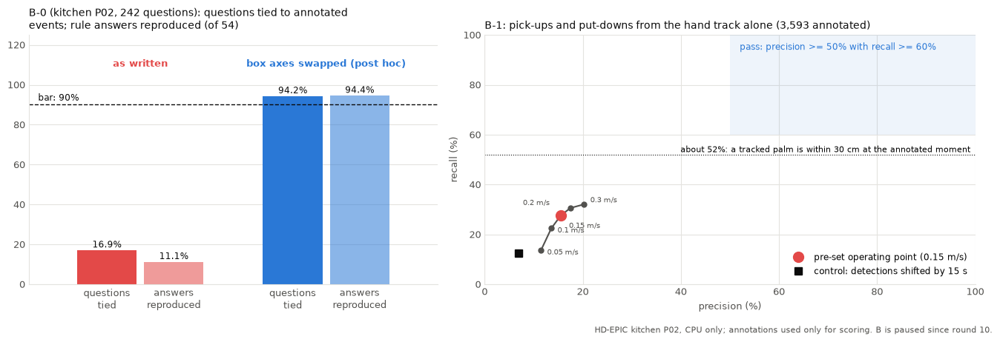

In [15]:
b0, b0s, b1 = get("b0", "summary"), get("b0_swapped", "summary"), get("b1", "summary")
display(pd.DataFrame([
    {"运行": "B-0 按写定的规则", "对上标注事件的题": f"{b0['tied']}/{b0['questions']} ({100 * b0['tied_share']:.1f}%)",
     "规则答案对": f"{b0['reproduced']}/{b0['rule_questions']} ({100 * b0['reproduced_share']:.1f}%)", "判定": "数据问题"},
    {"运行": "B-0 框的横纵坐标换过来（看到结果后加的修补）", "对上标注事件的题": f"{b0s['tied']}/{b0s['questions']} ({100 * b0s['tied_share']:.1f}%)",
     "规则答案对": f"{b0s['reproduced']}/{b0s['rule_questions']} ({100 * b0s['reproduced_share']:.1f}%)", "判定": "你接受后记为通过（\"1 接受\"）"}]).set_index("运行"))
ceiling = b1["palm_within_30cm_at_0"] * b1["clock_check_palm_to_object"]["n_at_0"] / b1["truths"]
print(f"B-1: {b1['truths']:,} annotated pick-ups and put-downs, {b1['detections']:,} detections; recall {100 * b1['recall']:.1f}%, "
      f"precision {100 * b1['precision']:.1f}% (bar: recall >= 60% at precision >= 50%) -> {b1['verdict']}")
print(f"     detections shifted by 15 s (chance): recall {100 * b1['control_shift_15s']['recall']:.1f}%, "
      f"precision {100 * b1['control_shift_15s']['precision']:.1f}%")
print(f"     a tracked palm within 30 cm of the object at the annotated moment: {100 * ceiling:.0f}% of all annotated moments "
      f"({b1['clock_check_palm_to_object']['n_at_0']:,} have a palm reading, {100 * b1['palm_within_30cm_at_0']:.1f}% of those)")
print(f"     alignment check: wearer-to-object distance error, median {100 * b1['clock_check_wearer_distance']['median_at_0']:.1f} cm "
      f"at offset 0 (best offset {b1['clock_check_wearer_distance']['best_offset_s']:.1f} s)")
show(hdepic_figure(D["b0"], D["b0_swapped"], D["b1"]))

**按规则的判定：**
- **B-0：** 按写定的规则判为数据问题（16.9% 和 11.1%）。原因：题目里的框和标注里的框是同一组数字，只是横、纵坐标的顺序反了（202 道带框的题里 201 道换过来就完全一样）。换过来以后 94.2% 和 94.4%，都过了 90%。**这个修补是看到结果之后加的**；哪一边的顺序是对的要看一帧视频才能确定，视频没下载。你回答"1 接受"，B-0 记为通过，原判定和修补都留在记录里。
- **B-1：** 召回 27.6%、精度 15.5%，**没过**。换别的速度门槛（只作描述）最多到召回 32.1%、精度 20.3%。只有约 52% 的标注时刻手部跟踪里恰好有一只手在物体 30 厘米以内（推断：由结果文件算出，见上面打印的数），所以光靠手部跟踪很难到 60%。

**这意味着什么：** B 没有不用标注的写入方法。第 10 轮你选了 (a)：B 先停，B-2（下载约 10 GB 视频）不做；标题里的"4D"仍按章程到关口 G3 定。为 B 搭好的东西（HD-EPIC 标注、手腕数据、轨迹对齐，对齐误差中位数 1.9 厘米）都留着。

#### 3.9 C-0 和 C-1 的 CPU 预览（§25.3、§25.5；预览不在讨论稿里）

**问的是什么：** C 是"能直接拿去做的回答"：除了"哪个部件"，还要答出接触点、动作类型、往哪个方向动、铰链在哪一侧。只对着 SceneFun3D 的标注打分，不真的执行（围栏的要求，也和兄弟项目 affordance-vla 分开）。
- **C-0（只用 CPU）：** 能不能从标注里为每个任务建一条"动作记录"当真值。
- **C-1（4B，GPU）：** 四组：V（普通视觉语言模型直接答）、G（几何规则）、M（我们的记忆：P4 挑出的帧和区域，接触点和类别来自标注，是上限）、O（真值，只用来核对打分程序）；第 10 轮评估的审稿后加了 M4（c4 的选择：同样的标注框，画面按语义挑，不用记忆）。

**事先定的规则：** C-0：至少 90% 的任务每个目标部件都有运动标注；至少 80% 的任务投到画面上的方向至少 20 像素；打分程序给真值打 100%。三条都满足才往 C-1 走。C-1 主结果：M 减 V 的"联合成功"（接触点在部件上、类型对、方向的直线误差在 20 度以内）区间下沿至少 10 个百分点，且在接触点对的任务上方向至少高 5 个点，C 才单独成立。M 减 M4 另报（账本 D-10），区间下沿低于 5 算"接近"。第 10 轮你回答"同意你的建议，a"：照原规则按 M 减 V 判定，M 减 M4 照样报告，并标明原规则包含标注的功劳。

**数字：** 下表是 C-1 的 **CPU 预览**：只有 M、M4、O 三组（V、G 要 GPU，还没跑），在 380 个任务上；4B 和 8B 指 M 和 M4 用的是哪个模型的 P4、c4 选择。预览的结果文件在 11-14 凌晨和 M4 的代码一起生成（账本记为第 10 轮那天的工作），还没有记进讨论稿，也没有审稿。

C-0: every target part has a motion 97.4% (bar 90%); arrow >= 20 px 94.1% (bar 80%); scorer gives the truth 100%: True -> continue to C-1


,接触点在部件上,affordance 标签对,运动类型对,方向直线误差 ≤ 20 度,转轴类别（转动的任务）,底线：转轴总是答竖直,联合成功
组,,,,,,,
M（4B 的选择）,"53.7% [46.2, 62.4]","83.2% [78.9, 87.4]","74.5% [68.2, 81.0]","49.2% [41.5, 56.6]","36.5% [28.2, 46.2]","82.4% [75.7, 88.6]","28.4% [22.8, 34.4]"
M4（4B 的选择）,"48.7% [40.1, 57.7]","74.2% [67.7, 80.4]","67.9% [61.0, 74.9]","46.3% [38.3, 54.3]","28.9% [19.7, 39.5]","82.4% [75.7, 88.6]","27.1% [21.1, 33.4]"
M（8B 的选择）,"54.5% [47.2, 62.8]","81.6% [76.6, 86.2]","70.3% [64.0, 76.9]","47.6% [39.8, 55.8]","34.0% [25.6, 44.0]","82.4% [75.7, 88.6]","30.0% [24.6, 35.9]"
M4（8B 的选择）,"47.6% [40.6, 55.4]","72.9% [67.0, 78.8]","66.8% [59.4, 74.1]","47.1% [38.8, 55.3]","27.7% [19.4, 37.5]","82.4% [75.7, 88.6]","28.2% [22.3, 34.5]"


M minus M4, joint success (4B): +1.3 [−3.5, +6.0] points -> close; scorer check on the truth (O): True
M minus M4, joint success (8B): +1.8 [−1.9, +5.4] points -> close; scorer check on the truth (O): True


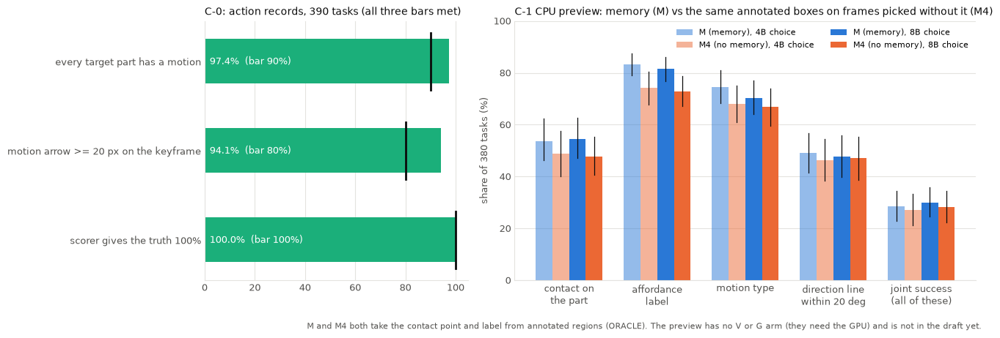

C-1 preview (4B choice), rotating tasks: 159; M's annotated label is a pull type on 84, and 73 of those get the axis class wrong
C-0: 129 of 160 annotated rotations have an axis up and down the image (vertical)


In [16]:
c0 = get("c0", "criteria")
print(f"C-0: every target part has a motion {100 * c0['motions_for_every_part']['share']:.1f}% (bar 90%); arrow >= 20 px "
      f"{100 * c0['arrow_at_least_20px']['share']:.1f}% (bar 80%); scorer gives the truth 100%: {c0['scorer_gives_truth_100']['holds']} "
      f"-> {get('c0', 'verdict')}")
fields = {"contact": "接触点在部件上", "label": "affordance 标签对", "type": "运动类型对", "line_ok": "方向直线误差 ≤ 20 度",
          "axis_class": "转轴类别（转动的任务）", "vertical_axis_class": "底线：转轴总是答竖直", "joint": "联合成功"}
rows = []
for model, name in (("4B", "c1_4b"), ("8B", "c1_8b")):
    for arm in ("M", "M4"):
        row = {"组": f"{arm}（{model} 的选择）"}
        row.update({label: rate(get(name, "arms", arm, field)) for field, label in fields.items()})
        rows.append(row)
display(pd.DataFrame(rows).set_index("组"))
for model, name in (("4B", "c1_4b"), ("8B", "c1_8b")):
    reading = get(name, "readings")
    print(f"M minus M4, joint success ({model}): {diff(reading['memory_value_M_minus_M4_joint'])} points -> {reading['memory_value_verdict']}; "
          f"scorer check on the truth (O): {get(name, 'scorer_check', 'holds')}")
show(c_figure(D["c0"], D["c1_4b"], D["c1_8b"]))
# why "always vertical" beats M on the axis class: rotating tasks whose annotated label is a pull type (the rule makes them translations)
PULL = {"hook_pull", "pinch_pull"}
rotating = pulled = pulled_axis_wrong = 0
for scene_file in sorted((RUNS / "mem_c1/preview/4b").glob("[0-9]*.json")):
    scene = json.loads(scene_file.read_text())
    for truth, memory in zip(scene["arms"]["O"], scene["arms"]["M"]):
        if (truth.get("prediction") or {}).get("type") != "rot":
            continue
        rotating += 1
        if (memory.get("prediction") or {}).get("label") in PULL:
            pulled += 1
            pulled_axis_wrong += not (memory.get("score") or {}).get("axis_class")
axes = get("c0", "sign_diagnostics", "axis_classes")
D["c1_rotations"] = {"rotating": rotating, "pulled": pulled, "pulled_axis_wrong": pulled_axis_wrong,
                     "vertical_in_c0": axes["up and down the image"], "rotations_in_c0": sum(axes.values())}
print(f"C-1 preview (4B choice), rotating tasks: {rotating}; M's annotated label is a pull type on {pulled}, "
      f"and {pulled_axis_wrong} of those get the axis class wrong")
print(f"C-0: {axes['up and down the image']} of {sum(axes.values())} annotated rotations have an axis up and down the image (vertical)")

**按规则的判定：**
- **C-0 通过：** 97.4% 和 94.1% 都过了门槛，打分程序给真值 100%、给故意答错的 0%。但**符号约定没通过核对**："按"类部件按计划的读法几乎都变成往外移动（80 个里只有 4 个对）。所以按事先的规则，C-1 只对方向的**直线**打分（不分推还是拉）。另一种读法（`motion_dir` 就是部件移动的方向）有 95.9% 对得上；你在第 9 轮回答"3 b"：主结果只比直线，"推还是拉"按这种读法另报，标明是计划之外加的。
- **C-1 的主判定（M 减 V）还没有。** 4B 在场景 421254（19 个任务）上的试跑（11-16，§25.5）：O 100%，M 37%、M4 32%、M' 47%，但 V、G、V'、G' 的联合成功都是 0（带撇号的是 §25.5 的诊断组：都改用目标部件像素最多的那一帧，把"挑帧"和"答动作"分开）。原因在答案格式，不在模型能力：模型在 `label` 里写部件名（"handle"、"knob"），读不出九类标签之一；`arrow_end` 照抄接触点，箭头长度为 0，没有方向。G 用的是 V 的接触点和标签，所以跟着是 0。全部运行之前只改了 V 的提问（账本 D-11）：逐条列出九个标签的原样字符串，要求 `label` 必须是其中之一；`arrow_end` 改为离接触点至少 50 个单位、表示部件往哪边动；附一个格式完整的例子；答案缓存换成 c1-v2。打分程序、读取规则、G、M、M4 和所有门槛都没改。试跑重新排队，先在 421254 上再跑，再跑其余场景。这和第 7 轮试跑后改提示词（D-7）是同一类修改：在全部运行之前、为了对普通模型公平。
- **预览里的 M 减 M4（只作描述）：** 4B +1.3 [−3.5, +6.0]，8B +1.8 [−1.9, +5.4]，按 D-10 的读法都是"接近"：给同样的标注框，记忆挑画面在 C 上也几乎没有多给什么。和第 3.4 节的 c4 是同一个结论。

**这意味着什么，和一个没解释的现象：**
- C 现在能说的只是"在标注的部件图下，记忆能给出接触点和类别"；它离"能直接拿去做"还远：联合成功只有约 28% 到 30%（ORACLE）。
- **"总是答竖直"的底线比 M 高，原因是事先写定的规则本身的一个弱点。** 预览里转轴类别 M 只对 34% 到 36%（M4 更低），而"总是答竖直"的底线是 82.4%。§25.5 的几何规则（G 和 M 都用）按标签定运动类型：拉类标签（hook_pull、pinch_pull）一律当平移。可是标注里有不少门的把手标成 hook_pull 或 pinch_pull，而门实际上是转动的；这些任务的运动类型就判错，转轴类别也跟着错。下面从预览的逐任务记录数出来：159 个转动的任务里，M 用到的标注标签是拉类的有 84 个，其中 73 个转轴类别判错。另一方面，标注里的转动大多是竖直的轴（C-0：160 个转动里 129 个），所以"总是答竖直"天然很高。这是计划里写定的规则的已知弱点，照计划记录，不在看结果之后改规则；C-1 的报告里要和这条底线并排写。

### 4. 主张怎么变的

| 时间 | 那时的主张 | 为什么改 | 依据 |
| --- | --- | --- | --- |
| 11-10，第 1 轮 | 定位"部件级 4D 功能记忆"；以 H3（交互帮助构建记忆）、H2（事件结构帮助检索）为主 | 记忆方向独立成仓库，第一次定位 | 讨论稿 §11；你的方向原话（第 0 节） |
| 11-12，第 6 轮 | **功能记忆：** 环境记忆按"能对什么做什么、做过什么"来组织和写入，而不是按帧、按物体或按融合的几何。三个可否证的预测：A（写在哪里）、B（事件）、C（代价） | 第 5 轮的评估：当时的原型"还不是一项研究贡献"，没有可以被否证的中心主张 | §20.2、§20.5、§21.1 |
| 11-13，第 7 轮 | 同上，G1 按收窄后的含义通过：按功能建索引在 ORACLE 下有效；"写在哪里"本身约 7 个百分点 | 阶段 1 的规则都满足，但 §23 把增益拆开后，大半是"哪些关键帧有部件"这一帧级信息 | §22.2、§23.3；第 3.1 节 |
| 11-13，第 8 轮 | **你描述的论文（CA 到 CD）：** CA 新的 affordance map 构建方法；CB 按功能搜索，不同于传统视觉语言模型读视频；CC 比它更快更准；CD 在动作类问题上格外强 | 你在聊天里写出了希望论文最后能说的贡献（"使用较为新颖的affordance map的方法，通过一个与传统vlm模型不同的搜索方式……"）；第 8 轮复述后你确认"1 对；2 同意" | `helm/rounds/R8.md`；账本 R8 |
| 11-13，第 9 轮 | **方案乙：** 重心放在按功能搜索、动作类问题和代价曲线；构建方法用现成的，算不算贡献等检查再定（DF-4）；C 是论文的一节，B 并行、不进主表 | 调研：CA 是四项里最弱的（FunGraph 已在画面上训练带动作类别的部件检测器；第 3 轮审稿找到的 Functional-SLAM 在线建部件、跨画面合并）；对照 c：P4 的领先来自标注框；CD-A 还没有证据（p = 0.16）。乙收回了你第 8 轮问题 2 的"同意"，所以交你定，你选了"乙" | `helm/rounds/R9.md` 第 4、5 节；§24.5 |
| 11-13，第 10 轮 | **"检索变难时"的部件级功能记忆**（第 0 节的原文），三个预测：1 现成工具建的部件图够用；2 检索越难、功能索引的优势越大；3 写入算进去仍然划算。动作方向改由 C 体现（先在 2b 里再试一次）；B 先停 | c4 接近 P4（4B +4.4、8B +6.7）；动作键只多 +0.8（真值 +3.8）；B-1 没过。评估写明：预测 2 是**看到 c4 之后才形成的假设**，讨论稿 §5 的 H1 到 H4 里没有对应，需要你认可；你回答"1 同意" | `helm/assessments/2026-11-13.md` 第 1、4 节；§24.8、§24.10、§25.4 |
| 11-13 到 11-15，2b 之后 | 主张没改，但它的第一步在检索这一步没过（差一直在、不随难度变大）。你选了"c+a"：先做现成工具的检查，同时测端到端；P-4 先不批 | 2b 的斜率区间包含 0 | §26；账本 2026-11-15 |

**一句话：** 主张从"按功能组织记忆"（宽）收窄到"按功能建索引在 ORACLE 下有效"，再被你扩成一篇有方法贡献的论文（CA 到 CD），又因为调研和对照收回到"现成构建器 + 按功能搜索"（乙），最后因为 c4 收窄到"只有检索变难时记忆才起作用"。每一步收窄都是事先写定的规则读出来的，不是看了结果改规则；唯一的例外是预测 2 本身，它是看到 c4 之后才提出的假设，评估里明说了。

### 5. 调研地图

**读到哪一层：** 摘要 < 方法部分 < 表格 < 全文。下表没有一篇是通读全文的；"掌舵代理核对过"指掌舵代理自己对照过原文的那一层，其余是调研代理或审稿代理读到的。完整记录在 `helm/evidence/` 的 7 个文件里。

| 方向 | 最近的工作（读到哪一层） | 已经被做了什么 | 留给本项目的空间 |
| --- | --- | --- | --- |
| 给模型看编号候选框 | Set-of-Mark、MOKA（方法）；AffordBot，NeurIPS 2025（方法，要点云和渲染视角）；ThinkAfford，2026-08（方法） | "编号框让模型找到部件"这个机制 | 不能声称；"有部件框从约 28% 到约 50%"只当基线结果报告 |
| 视觉语言模型的瓶颈在哪 | "Part Grounding, Not Action Knowledge"，2026-09（掌舵代理核对过摘要） | 瓶颈是找到部件，不是知道动作 | 和我们的结果一致（第 3.4、3.6 节）；也解释了动作键为什么没用 |
| 从视频建部件级功能图 | FunGraph，IROS 2025（表格：用投影的标注训练二维部件检测器，mAP50 26.7；零样本 GroundingDINO 0.7）；Functional-SLAM，CoRL 2026（掌舵代理核对过摘要和引言；在线建部件节点、跨画面合并、不存融合地图）；HHOpenFunGraph（表格，部件召回 70.1%，指标定义没核实）；OpenFunGraph（表格）；OP3DSG，ECCV 2026（方法） | "不需要问题、部件级、带动作类型"的部件图，在点云上和带位姿的画面上都有人做了 | 构建方法是四项里最弱的；算不算贡献等阶段 2a（DF-4） |
| SceneFun3D 上每个问题重新处理场景 | UniFunc3D，NeurIPS 2026（表格：读视频画面，AP25 44.04，每题 53 到 99 秒，8 张 H100）；Fun3DU（AP25 33.3，别人复现 23.4 和 12.56）；T-FunS3D（表格：建一次约 592 秒、之后每题 78 秒，AP25 34.5）；AFFORDMEM（AP25 41.66；它的表里"用问题文字直接提示 SAM 3"AP25 30.45，掌舵代理没核实）；TASA（每题 37.6 秒） | 高精度，但每题几十秒；"写一次、问很多次"T-FunS3D 已有（用点云） | 同一协议下并排（DF-5，阶段 3）；写入算全的代价曲线（预测 3） |
| 写一次的记忆（物体级） | 3D-Mem，CVPR 2025（表格）；VL-KnG（表格，约 10 个问题回本）；Video-EMem，2026-10（掌舵代理核对过摘要）；SpatialMem（arXiv 2601.14895，表格：物体级第一人称记忆，相同画面预算下检索证据画面，不到部件） | 物体级的"写一次、问很多次"和它的回本点 | 部件级；写入算全 |
| 记忆的优势随难度变大 | CapMem、MERIT，2026（表格：通用视频问答里，记忆的优势随视频变长而变大）；OpenGround / OpenTarget，2025-12（表格：同类部件很多时，给了真值候选的定位模型也会崩） | 通用视频问答里有；部件级没有找到（检索不是穷尽的） | 预测 2 的空间；OpenTarget（7,724 个问题、平均每个场景 8.35 个同类部件，调研代理读到，掌舵代理没核实）可能适合测"相似部件多" |
| 问"做过什么" | AMEGO，ECCV 2024（方法）；EgoSG，2026（摘要） | 物体和设施一级已有 | 部件级没有，但 B 没有不用标注的写入方法；B 已停 |
| 能直接拿去做的回答 | AffordBot（表格）；AFUN，2026-06（摘要）；SceneFun3D 的任务 3 | 每个问题给出动作类型、方向或接触点 | 从写一次的记忆里给出；它最接近兄弟项目，只对着标注打分 |

**调研代理归纳的"空白格"**（推断，来自 `field_2026-11-13_landscape_affordance_construction.md`）：同时满足"只用视频、不用扫描点云；部件级；封闭的动作词表；跨画面一个部件一条；写入便宜；以找全场景里所有部件为目标；按检索来评测"的工作没有找到。但 Functional-SLAM 已覆盖其中大部分，所以剩下的主要是"把部件图当回答问题的索引"和"写一次、问很多次的代价"。

**领域里的数字不能直接和我们的比：** 别人报告的是三维掩码的 AP（官方指标）；我们用的是二维的"框中心落在部件上"，没有已发表的对应（审稿 V-65）。要并排，得把框投到三维、按官方指标打分（DF-5）。

### 6. Research scope 大局

**围栏（章程第 3 节；P-4 没批，所以仍是第 9 轮改过的版本）**

| | 包括什么 | 本周的变化 |
| --- | --- | --- |
| 围栏内 | 室内环境的部件级功能记忆：从视频写入一次，按查询读取；在公开基准上与静态记忆、逐查询重新处理场景的方法对照；用现成的构建器建 affordance map（不训练）；能直接拿去做的回答，只对着标注打分 | 第 9 轮加了"用现成构建器""能直接拿去做的回答" |
| 边缘 | 人形展示（补充材料）；训练写入器或检测器（到 G2）；时间维度的事件记忆（B-0、B-1 已做；之后每一步另问）；新的构建方法作为论文贡献（等 DF-4） | 第 9 轮加了"检测器"和"新的构建方法作为论文贡献"；事件记忆：第 10 轮你选 B 先停（P-4 第 4 处会把这一点写进章程，暂缓） |
| 围栏外 | 训练 VLA 或机器人控制；自己录制数据；把稠密重建当作方法的输入 | 不变 |

**半径：** medium，限于三件事：用现成构建器替换环节 4 的标注；环节 10（检索）按动作类型检索；C 的检查和 B-0、B-1。主张本身的替代设计按 narrow，要改主张先问你。**推断：** "按动作类型检索"已经不再是主张，P-4 第 3 处会把半径改成"2a、2b、C"，暂缓。

**预测：活着的、没过的、没测的**

| 预测 | 来自 | 状态 | 依据 |
| --- | --- | --- | --- |
| A（写在哪里） | 第 6 轮，§20.5 | 在 ORACLE 下成立，含义收窄（G1） | §22–23 |
| B（事件好于只有时间戳） | 第 6 轮 | B-1 没过，B 先停 | §25.4 |
| C（写一次、查多次更省） | 第 6 轮 | 没测（只量了读） | §22.3、§24.8 |
| CD-A（动作类问题格外强） | 第 8 轮 | 没有证据，不再当主张 | §24.5、§24.10、§26 |
| 预测 1（现成工具的部件图够用） | 第 10 轮 | 没测；示例图你看过（11-16），只用 SAM 3，全部运行已排到前面 | §24.9 |
| 预测 2（检索越难优势越大） | 第 10 轮 | 检索这一步没过；端到端排队中 | §26、§26.2 |
| 预测 3（写入算进去仍划算） | 第 10 轮 | 没测；划算点暂定 15 个问题 | 评估第 4 节 |

**停止清单**（评估第 13 节建议、你在第 10 轮选定的）：按动作类型检索当作主张；B 和标题里的"4D"（"4D"到 G3 定）；为了归因再在标注部件图上加对照（2b 的上限检查除外）。更早停下的（§20.8）：打磨单个场景的示例、改进人形、给流程再加环节。

**一篇论文今天能说什么，还缺什么**（推断，依据评估第 1、3、9 节）
- **今天能写的一句话：** 在标注的部件图下、30 个 SceneFun3D 场景上，给视觉语言模型看编号的部件框，选对部件从约 28% 升到约 50%（4B、8B 一致）；单个房间里，记忆挑画面在此之上只多 4 到 7 个百分点。这是一个基线结果，机制别人做过，所以单独撑不起一篇论文。
- **还缺：** 一个不用标注的结果（预测 1，阶段 2a）；检索变难时端到端的优势（预测 2，先是 2b 端到端，最好再在现成基准上，例如 OpenTarget 或 HD-EPIC，下载要你批）；写入算全的代价曲线（预测 3）；同一协议下的已有系统（UniFunc3D 便宜版、直接提示 SAM 3；用扫描打分另问你，DF-5）；报告全部 445 个任务（看不到的算错，审稿 V-69）。
- **评估第 10 节的话：** 如果预测 2 不成立，剩下的是"部件图当记忆 + 代价"，也就是审稿人说的"检测器加编号框"，**很可能过不了章程里"想法本身要立得住、不是插件"这一条**。那时不是换个说法继续，而是到 G2 由你决定。

**会议**
- NeurIPS 2027 的日程和审稿指南还没公布（11-13 查过）。2026 年对"由应用驱动"类论文的指南要求：用例真实而有意义；任务、方法和指标贴合用例；和常用的非机器学习做法及基线比；分析为什么有效（评估第 12 节，读到 2026 年的指南）。
- 本项目的用例是你在第 7 轮选的：家里的使用指导、无障碍与远程协助为主，家用机器人作为补充说明（"我希望优先一和三，二作为补充说明"）。
- ICCV 2027 是否先投、WACV Applications 是否加入，都到 G2 定。CVPR 2027 已经赶不上（摘要登记 11-10 截止，§20.7）。

**掌舵代理的看法**（原文照录）

> 这一周把阶段 1 和它的补充对照都做完了，结论比一周前清楚、也比一周前保守。清楚的是：给视觉语言模型看部件的编号框，它选对要操作的部件的比例从约 28% 升到约 50%（标注的部件图，4B 和 8B 一致），这是这一周最可靠的结果。保守的是：在单个房间里，记忆本身（挑画面、按动作类型检索）在这之上只多几个百分点；第 10 轮把主张改成"检索变难时功能记忆才起作用"，但它的第一步（把多个场景混在一起检索）在检索这一步没有通过：功能索引一直比语义检索多 12 到 18 个百分点，但这个差不随难度变大。所以项目现在站在一个岔口：一是正在排队的"端到端"版本（混合之后模型最后能不能选对部件）和现成工具建图的检查，这两个结果决定主张还能不能站住；二是如果站不住，到关口 G2 由项目负责人在"做新的构建方法、换会议、重新想"之间选。下周最要紧的是拿到这两个结果，而不是再加新的标注对照。

**把这个看法展开**（依据评估第 10、11 节和 §24.9、§26.2 的读法，不是新的建议）：

| 两个结果 | 事先写定的读法 | 之后 |
| --- | --- | --- |
| 2b 端到端（§26.2） | 功能索引减语义（选对部件）对 log2 K 的斜率区间下沿大于 0，且 K = 16 时差至少 5 个点：端到端支持预测 2 | 支持：预测 2 还活着，下一步是现成基准（阶段 3，要你批下载）。不支持：按评估第 10 节到 G2 |
| 阶段 2a（§24.9） | 工具版 P4 减 c3、工具版 P4 减"直接提示 SAM 3"，有一个区间下沿不大于 0 就停下讨论；标注版 P4 减工具版 P4 的区间上沿低于 10 个点：现成工具够用 | 够用：支持"构建方法暂不算贡献"（DF-4）。差很多而且召回随写入预算明显上升：构建方法有事可做，交你重新考虑 DF-4 |
| G2 的三条路 | 做新的构建方法（在边缘，要训练）；换会议（WACV Applications 候选）；停下来重新想 | 都由你定 |

### 7. 进行中和下周

**队列**（GPU 作业只走队列；账本 2026-11-16）

| 作业 | 位置 | 状态（截至 2026-11-16 傍晚） |
| --- | --- | --- |
| 问题 2 检查的示例图：SAM 3、Qwen3-VL-8B 当检测器（3 个场景、6 张关键帧） | 11-16 按你的"b"插到前面 | 跑完，给你看过（下图）；你定"a，插到前面"，流程关口算通过 |
| 阶段 2a 全部运行：SAM 3 的部件图，以及用任务文字直接提示 SAM 3 的框；之后 8B 读图（GPU 上限 7 小时） | 11-16 按"a，插到前面"排到前面 | SAM 3 已开始写出结果文件（本 notebook 不读）；Qwen3-VL-8B 的检测不做 |
| C-1 试跑（场景 421254，4B） | 11-16 插到前面 | 跑过一次：V、G、V'、G' 因答案格式都是 0；改了 V 的提问（D-11，缓存 c1-v2），重新排队 |
| 2b 端到端（`200_mem_pooled_reading_*`，8B，约 2,340 次调用） | 排在你的作业后面 | 排队中；11-16 网络恢复时估计约 22 小时后轮到 |

**11-16 的经过：** 服务器网络断了一阵，恢复后队列里有 793 个作业，我们的都排在你的作业后面。你回答"b"：两个小作业（示例图、C-1 试跑）插到前面，2b 的端到端版本仍排在后面。示例图跑完后给你看了，你选了"a，插到前面"（选项是：(a) 只用 SAM 3 全部跑，Qwen 这次不做；(b) 先改 Qwen 的提示词再看；(c) 两个都跑）。§24.9 的读法照旧，"以哪个工具为准"一条因为只剩一个工具而不再需要。

**问题 2 检查的示例图**（`runs/mem_phase1/tool_maps/gate.png`，不进 git；这里缩小显示）：每一行是一个场景的两张关键帧，每张关键帧左边是 SAM 3（用 8 个部件名提示，橙色框），右边是 Qwen3-VL-8B（要它用 JSON 框出这 8 类部件，蓝色框）。实线框的中心落在标注部件上（放宽 8 个像素），虚线框没有；白色轮廓是标注的部件，只用来判断，没有给工具。图里每格标题写了框的个数和落在部件上的个数；按"落在部件上的 / 框的个数"写：SAM 3 在 6 张关键帧上是 16/16、19/19、5/6、4/6、4/4、4/4；Qwen3-VL-8B 是 0/0、9/19、0/0、0/1、2/5、0/0（3 张回答的是空列表，记录里写作 4 张，见第 8 节）。

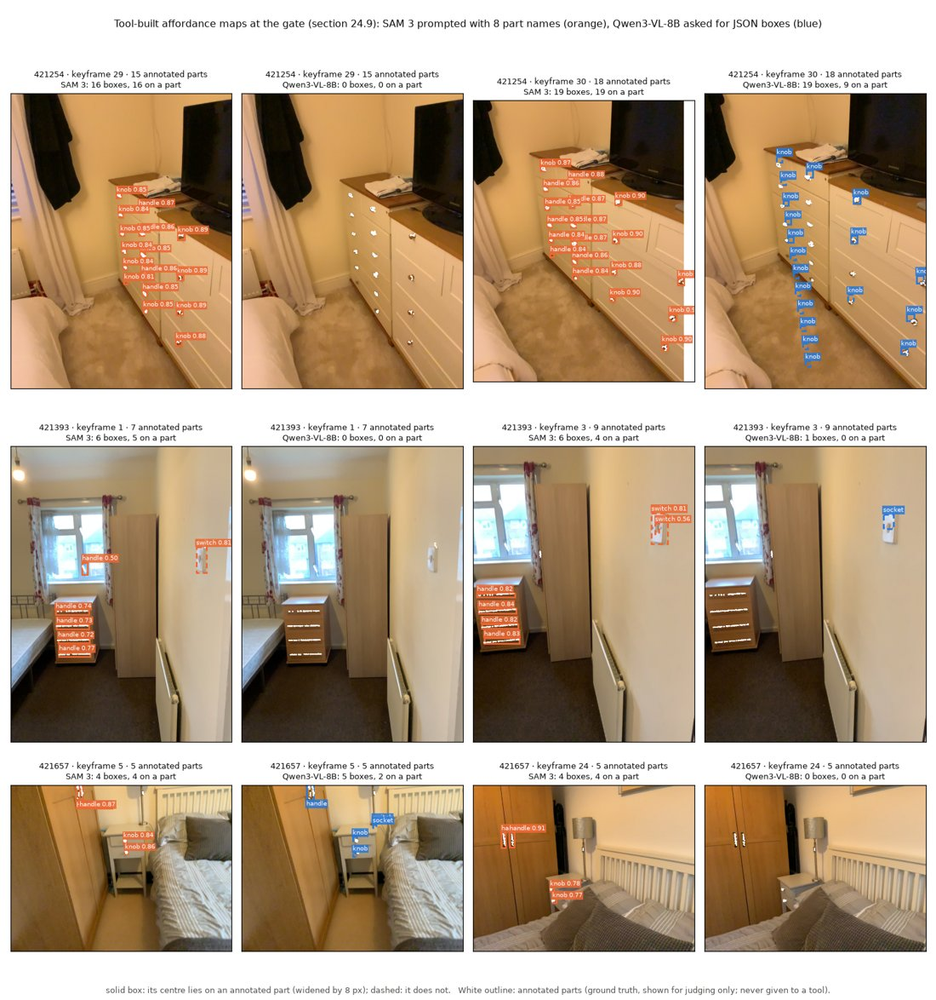

In [17]:
from io import BytesIO

from IPython.display import Image as ShowImage
from PIL import Image

gate_file = RUNS / "mem_phase1/tool_maps/gate.png"
if not gate_file.is_file():
    raise FileNotFoundError("runs/mem_phase1/tool_maps/gate.png is missing: run scripts/draw_tool_maps.py")
gate = Image.open(gate_file).convert("RGB")
gate = gate.resize((1100, round(gate.height * 1100 / gate.width)))
buffer = BytesIO()
gate.save(buffer, format="JPEG", quality=85)
display(ShowImage(data=buffer.getvalue(), format="jpeg"))

**等你定的**
1. **示例图：** 已定（11-16，"a，插到前面"）；这一条不再等你。
2. **P-4：** 暂缓；等 2b 端到端和 2a 的结果再改写。
3. **G2 的路（如果预测 2 端到端也不支持）：** 新的构建方法、换会议、重新想（第 6 节）。
4. **推迟的决定还在：** DF-3（阶段 2 的其余部分）；DF-4（构建方法算不算贡献，等 2a）；DF-5（和 UniFunc3D 并排，阶段 3，用扫描打分另问）；"4D"是否留在标题（G3）。
5. **流程上的一件事：** 账本记着距上次 distill（把做法沉淀成习惯）已经 5 轮，按规则该提议一次；还没提。

**下周按已批的计划要做的**（掌舵代理的下一步，账本开头）
- 2a：SAM 3 跑完后算召回和覆盖（CPU），再用 8B 读图（工具版 P4、工具版 c4、直接提示 SAM 3）；按 §24.9 的读法记录。Qwen3-VL-8B 的检测不做。
- C-1：用新的提问（c1-v2）重新试跑、检查，然后全部运行（4B；之后用 8B 再跑一遍 V），按 §25.5 记录。
- 2b 端到端轮到后跑完，按 §26.2 的读法记录。
- 每一项的读法都在跑之前写定；结果出来后各写一条记录，需要决定的集中到一份文档。

### 8. 风险和诚实说明

**ORACLE**
- 用了标注部件图的组都是上限：阶段 1 的 P4（检索和端到端）、对照里的 P4 和 c4、R7-B、动作键、2b、C-1 的 M 和 M4。阶段 1 的 P2、P3 和 b 的区域个数、大小按 P4 匹配，间接用到了标注。
- c2、c2' 自己画框，但它们的画面是记忆挑的，而记忆挑画面用到了标注的关键帧标记。
- 不用标注的组：c1、c1'、c3、c+，以及 B-1。它们不是上限，但只是 4B、8B 加我们定的读法，不是这个领域最强的对手。

**设定上的局限**
- **单个房间：** SceneFun3D 每个场景一个房间、40 张关键帧；评估的看法是，这是"语义检索已经够用"的容易情形（推断，看到 c4 之后才形成）。2b 混进来的是别的房间，比"同一段长视频里的相似部件"容易。
- **任务被挑过：** 390 个任务是按"我们的关键帧里看得到"选的（445 个里的 390 个）；审稿要求以后报告全部任务、看不到的算错（V-69）。
- **任务的写法：** SceneFun3D 的每个任务都点明了部件和动作，只问标注过的功能部件，对 affordance 的写法有利（§21.9）。
- **指标：** 二维的"框中心落在部件上"，没有已发表的对应；没有按官方的三维指标比过（V-65）。
- **模型：** 视觉语言模型只用了 Qwen3-VL 一家（4B、8B）；时间只算模型调用，8B 比 4B 快的原因没查。

**看到结果之后才加的东西**（每一处在记录里都写明了）
- §23 的归因检查和常数扫描：审稿之后加的（D-4），计划在算之前提交。
- R7-B 的更严的重算：审稿之后加的，规则在算之前写定。
- B-0 的坐标修补：按事先的规则先判为数据问题，修补是看到结果之后做的；你接受后才记为通过。
- 2b 的端到端版本：检索这一步没过之后才加的（§26.2 开头写明）。
- 预测 2 本身：看到 c4 之后才形成的假设（评估第 1 节）。
- C-1 的"推还是拉"：计划之外另报（你的"3 b"）。
- 在跑之前改过的读法：§24.9 读法 2（D-9，因为按原文"召回随预算上升"一定成立）；§24.9 停的规则（第 10 轮问题 3"b"）；C-1 加 M4（D-10）；对照的提示词和回答长度（D-7，试跑后、其余场景之前）。

**改正过的流程失误**
- 结果文件和 notebook 曾打印"G1: passed"，而过关由你决定；改成"规则的类别……过关由项目负责人决定"（V-14）。
- 第 7 轮简报开头说"改写后又审了一遍"时，那一轮还没审完；补上了各轮结论（V-31）。
- 第 9 轮简报初稿把标注框的功劳算成了记忆的（阻断项 V-38），改写后才交给你。
- 调研代理漏掉了 Functional-SLAM，第 3 轮审稿才找到；建议因此从丙改成乙。
- 讨论稿 §20.5 说 UniFunc3D 需要点云，实际输入是视频画面；加了带日期的更正（V-72）。
- "对误检不敏感"说得太宽，收窄为"检索这一步、误检和部件一样大时"（V-73）。
- 账本开头和章程 G1 一行曾经过时（V-71）；账本开头已每次提交更新，章程 G1 一行要随 P-4 一起改。
- 账本里引你的原话时把弯引号写成了直引号，加了更正（账本 R8）。
- 审稿循环两次到了章程允许的 3 轮上限，最后一轮的意见照改、没有再审（第 7 轮的贡献图、第 9 轮简报）；第 10 轮评估的审稿人没看到 §24.8、§24.10 的记录。

**本 notebook 自己的说明**
- C-1 的 CPU 预览（第 3.9 节）是服务器上已有的结果文件，讨论稿里还没有记录，也没审过；这里只作描述。
- 第 7 节显示了示例图；C-1 试跑的数字照 §25.5 的记录引用，没从文件读（重新试跑会覆盖那个文件）；11-16 晚上开始写出的 SAM 3 全部运行的结果，本 notebook 没读。
- **一处和记录对不上的地方：** 账本和 §24.9 写 Qwen3-VL-8B "有 4 张直接回答空列表"。按服务器上的答案文件，6 张里 3 张回答的是空列表；另一张只给了 1 个框、不在部件上，所以没有一个框落在部件上的是 4 张。第 7 节的说法按文件写。
- "总是答竖直"那一条（第 3.9 节）：第一版写成"原因没查"，现在按 §25.5 的规则解释清楚了，是事先写定的规则的弱点。
- 第 1–6 轮没有你的逐字回答（接入 research-helm 之前），时间线里写的是讨论稿记下的决定。

### 9. 附录

#### A. 数字和出处

下表每一行是正文里引用的一个数字：取自哪个结果文件的哪一项，运行时从文件重新算一遍，和正文写的对一下（"核对"一列）。格式：比例写成"值 [区间]"，差写成"个百分点 [区间]"。

In [18]:
SOURCES = [  # what the text quotes, the value as written, file, path in the file, format, section
    ("阶段 1：P4 第一个关键帧对", "66.2% [60.0, 73.3]", "phase1", ("first_keyframe_right", "P4"), "rate", "§22.3"),
    ("阶段 1：P3 第一个关键帧对", "47.3% [39.5, 55.9]", "phase1", ("first_keyframe_right", "P3"), "rate", "§22.3"),
    ("阶段 1：P0 第一个关键帧对", "45.6% [37.4, 54.5]", "phase1", ("first_keyframe_right", "P0"), "rate", "§22.3"),
    ("阶段 1：P2 第一个关键帧对", "38.5% [32.0, 45.6]", "phase1", ("first_keyframe_right", "P2"), "rate", "§22.3"),
    ("阶段 1：P4 减 P3", "+18.8 [+12.9, +24.9]", "phase1", ("first_keyframe_right", "P4 minus P3"), "diff", "§22.2"),
    ("阶段 1：端到端 P4（4B）", "53.6% [46.2, 61.6]", "phase1", ("reading", "P4 affordance regions"), "rate", "§22.2"),
    ("阶段 1：端到端 P3（4B）", "10.3% [7.5, 13.4]", "phase1", ("reading", "P3 generic regions"), "rate", "§22.2"),
    ("§23：只用比特减 P0", "+9.0 [+6.1, +12.5]", "diag", ("differences", "whole keyframes + which keyframes hold an affordance region minus P0 whole keyframes"), "diff", "§23.3"),
    ("§23：只用 token 减 P0", "+17.4 [+11.7, +23.7]", "diag", ("differences", "P4, no penalty for keyframes without a token minus P0 whole keyframes"), "diff", "§23.3"),
    ("§23：P4 减 P0", "+20.5 [+14.4, +26.9]", "diag", ("differences", "P4 affordance regions minus P0 whole keyframes"), "diff", "§22.4"),
    ("§23：同关键帧 P4 减 P3", "+7.0 [+2.8, +11.3]", "diag", ("differences", "P4 affordance regions minus P3 in the keyframes of P4"), "diff", "§23.3"),
    ("§23：框里有正确部件，P4", "83.6% [78.2, 89.3]", "diag", ("a_shown_box_is_on_the_target", "P4 affordance regions"), "rate", "§23.3"),
    ("§23：框里有正确部件，P3", "20.0% [13.8, 27.9]", "diag", ("a_shown_box_is_on_the_target", "P3 generic regions"), "rate", "§23.3"),
    ("随机挑一张关键帧", "9.2%", "diag", ("chance", "a random keyframe"), "pct", "§23.3"),
    ("对照 c：P4（4B）", "53.1% [45.5, 61.7]", "c4b", ("arms", "p4n", "right_part"), "rate", "§24.5"),
    ("对照 c：c3（4B）", "28.5% [23.5, 34.0]", "c4b", ("arms", "c3", "right_part"), "rate", "§24.5"),
    ("对照 c：c2（4B）", "17.2% [13.4, 21.3]", "c4b", ("arms", "c2", "right_part"), "rate", "§24.5"),
    ("对照 c：c1（4B）", "15.1% [11.7, 19.0]", "c4b", ("arms", "c1", "right_part"), "rate", "§24.5"),
    ("对照 c：P4 减 c3（4B）", "+24.6 [+19.2, +31.5]", "c4b", ("against_p4", "c3"), "diff", "§24.5"),
    ("对照 c：P4 减 c1（4B）", "+37.9 [+31.2, +45.4]", "c4b", ("against_p4", "c1"), "diff", "§24.5"),
    ("对照 c：c2 减 c1（4B）", "+2.1 [−1.1, +5.4]", "c4b", ("choosing_keyframes",), "diff", "§24.5"),
    ("c3 的 40 帧看得到目标", "98.2%", "ceiling", ("share",), "pct", "§24.5"),
    ("第二批：c+（4B）", "26.4% [21.9, 31.7]", "c4b", ("arms", "cplus", "right_part"), "rate", "§24.7"),
    ("第二批：d（4B）", "14.1% [11.4, 17.1]", "c4b", ("arms", "d", "right_part"), "rate", "§24.7"),
    ("第二批：b（4B）", "11.4% [8.4, 15.0]", "c4b", ("arms", "b", "right_part"), "rate", "§24.7"),
    ("第二批：c+ 减 c3", "−2.1 [−6.6, +2.7]", "c4b", ("our_keyframes_vs_even_frames",), "diff", "§24.7"),
    ("a：全部网格档位", "53.6% [45.3, 62.2]", "a", ("arms", "a: every grid level"), "rate", "§24.7"),
    ("a：全部通用区域", "50.0% [44.1, 56.2]", "a", ("arms", "a: every generic region"), "rate", "§24.7"),
    ("c4（4B）", "48.7% [40.3, 57.5]", "c4b", ("arms", "c4", "right_part"), "rate", "§24.8"),
    ("P4 减 c4（4B）", "+4.4 [−0.9, +9.6]", "c4b", ("against_p4", "c4"), "diff", "§24.8"),
    ("c2' 减 c1'（4B）", "+3.6 [−0.9, +8.1]", "c4b", ("choosing_keyframes_same_reading",), "diff", "§24.8"),
    ("P4（8B）", "54.4% [47.1, 62.6]", "c8b", ("arms", "p4n", "right_part"), "rate", "§24.8"),
    ("c4（8B）", "47.7% [40.9, 55.3]", "c8b", ("arms", "c4", "right_part"), "rate", "§24.8"),
    ("c3（8B）", "27.7% [22.6, 33.0]", "c8b", ("arms", "c3", "right_part"), "rate", "§24.8"),
    ("P4 减 c4（8B）", "+6.7 [+1.8, +11.5]", "c8b", ("against_p4", "c4"), "diff", "§24.8"),
    ("c2' 减 c1'（8B）", "+3.6 [−0.8, +8.2]", "c8b", ("choosing_keyframes_same_reading",), "diff", "§24.8"),
    ("每题秒数：P4（8B）", "0.7", "c8b", ("arms", "p4n", "seconds_per_question"), "raw", "§24.8"),
    ("每题秒数：c3（8B）", "3.5", "c8b", ("arms", "c3", "seconds_per_question"), "raw", "§24.8"),
    ("每题秒数：P4（4B）", "1.2", "c4b", ("arms", "p4n", "seconds_per_question"), "raw", "§24.5"),
    ("每题秒数：c3（4B）", "5.7", "c4b", ("arms", "c3", "seconds_per_question"), "raw", "§24.5"),
    ("写入秒数（每个场景）", "24.3", "phase1", ("write_s_per_scene",), "one", "§22.3"),
    ("R7-B：留 100%、误检 0.5 倍，减 P3", "+15.2 [+10.4, +20.3]", "errors", ("grid", "random", "1", "0.5", "against_p3"), "diff", "§24.6"),
    ("R7-B：随机丢、留 25%、无误检", "52.2%", "errors", ("grid", "random", "0.25", "0", "rate"), "pct", "§24.6"),
    ("R7-B：先丢小的、留 25%、无误检", "47.2%", "errors", ("grid", "smallest_first", "0.25", "0", "rate"), "pct", "§24.6"),
    ("R7-B 更严的重算：随机丢、留 100%、误检 0.5 倍", "63.3%", "errors_centre", ("grid", "random", "1", "0.5", "rate"), "pct", "§24.6"),
    ("R7-B 更严的重算：先丢小的、留 100%、误检 0.5 倍", "62.3%", "errors_centre", ("grid", "smallest_first", "1", "0.5", "rate"), "pct", "§24.6"),
    ("动作类型的检验 p", "0.16", "by_action", ("heterogeneity_p4_minus_c3", "p_value"), "p", "§24.5"),
    ("动作短语减不加键", "+0.8 [−0.9, +2.4]", "key", ("against_no_key", "action phrase"), "diff", "§24.10"),
    ("真值动作类型减不加键", "+3.8 [+0.9, +7.5]", "key", ("against_no_key", "true type"), "diff", "§24.10"),
    ("动词减部件词", "+0.0 [−2.4, +2.2]", "key", ("verb_minus_part",), "diff", "§24.10"),
    ("2b：K = 1，功能索引减语义", "+13.8 [+8.7, +19.2]", "pooled", ("per_size", "1", "function index minus semantic (top3)"), "diff", "§26"),
    ("2b：K = 16，功能索引减语义", "+11.8 [+8.3, +15.7]", "pooled", ("per_size", "16", "function index minus semantic (top3)"), "diff", "§26"),
    ("2b：K = 16，语义的前 3 张有对的", "32.7%", "pooled", ("per_size", "16", "semantic", "top3", "rate"), "pct", "§26"),
    ("2b：斜率（每翻一倍）", "−0.7 [−2.2, +0.7]", "pooled", ("readings", "function index minus semantic", "slope_per_doubling"), "diff", "§26"),
    ("2b：动作键的斜率", "+0.1 [−0.7, +0.9]", "pooled", ("readings", "function index + action key minus function index", "slope_per_doubling"), "diff", "§26"),
    ("B-0：对上标注事件（原规则）", "16.9%", "b0", ("summary", "tied_share"), "pct", "§25.4"),
    ("B-0：规则答案对（原规则）", "11.1%", "b0", ("summary", "reproduced_share"), "pct", "§25.4"),
    ("B-0：对上标注事件（修补后）", "94.2%", "b0_swapped", ("summary", "tied_share"), "pct", "§25.4"),
    ("B-0：规则答案对（修补后）", "94.4%", "b0_swapped", ("summary", "reproduced_share"), "pct", "§25.4"),
    ("B-1：召回", "27.6%", "b1", ("summary", "recall"), "pct", "§25.4"),
    ("B-1：精度", "15.5%", "b1", ("summary", "precision"), "pct", "§25.4"),
    ("C-0：每个目标部件都有运动", "97.4%", "c0", ("criteria", "motions_for_every_part", "share"), "pct", "§25.4"),
    ("C-0：方向至少 20 像素", "94.1%", "c0", ("criteria", "arrow_at_least_20px", "share"), "pct", "§25.4"),
    ("C-1 预览：M 减 M4，联合成功（4B）", "+1.3 [−3.5, +6.0]", "c1_4b", ("readings", "memory_value_M_minus_M4_joint"), "diff", "预览"),
    ("C-1 预览：M 减 M4，联合成功（8B）", "+1.8 [−1.9, +5.4]", "c1_8b", ("readings", "memory_value_M_minus_M4_joint"), "diff", "预览"),
    ("C-1 预览：转轴总是答竖直的底线", "82.4%", "c1_4b", ("arms", "M", "vertical_axis_class", "rate"), "pct", "预览"),
    ("C-1 预览：转动的任务", "159", "c1_rotations", ("rotating",), "raw", "预览"),
    ("C-1 预览：其中标注标签是拉类的", "84", "c1_rotations", ("pulled",), "raw", "预览"),
    ("C-1 预览：其中转轴类别判错", "73", "c1_rotations", ("pulled_axis_wrong",), "raw", "预览"),
    ("C-0：转动里竖直的轴", "129", "c1_rotations", ("vertical_in_c0",), "raw", "§25.4"),
    ("C-0：标注的转动", "160", "c1_rotations", ("rotations_in_c0",), "raw", "§25.4"),
    ("B-1：手部跟踪的上限（推算）", "52%", "b1", ("summary",), "b1_ceiling", "§25.4"),
]
DERIVED = {"c1_rotations": "mem_c1/preview/4b/*.json 的逐任务记录和 mem_c0/summary.json（本节现算）"}
FORMATS = {"rate": rate, "diff": diff, "pct": lambda v: f"{100 * v:.1f}%", "raw": lambda v: f"{v}", "one": lambda v: f"{v:.1f}",
           "p": lambda v: f"{v:.2f}", "b1_ceiling": lambda v: f"{100 * v['palm_within_30cm_at_0'] * v['clock_check_palm_to_object']['n_at_0'] / v['truths']:.0f}%"}


def how(name, path, kind):
    if kind != "b1_ceiling":
        return "直接取值"
    v = get(name, *path)
    share, n, truths = v["palm_within_30cm_at_0"], v["clock_check_palm_to_object"]["n_at_0"], v["truths"]
    return (f"推算，文件里没有这个数：有手掌读数的 {n:,} 个标注时刻里，{100 * share:.2f}% 有一只手掌在物体 30 厘米以内；"
            f"除以全部 {truths:,} 个标注时刻：{100 * share:.2f}% × {n:,} ÷ {truths:,} = {100 * share * n / truths:.1f}%")
rows = []
for label, written, name, path, kind, section in SOURCES:
    computed = FORMATS[kind](get(name, *path)).replace("-", "−")
    rows.append({"正文里的说法": label, "正文写的": written, "从文件算出": computed, "核对": "一致" if computed == written else "不一致",
                 "文件（runs/ 下）": FILES.get(name, DERIVED.get(name)), "取的哪一项": " → ".join(path), "怎么得到": how(name, path, kind),
                 "讨论稿": section})
sources = pd.DataFrame(rows).set_index("正文里的说法")
display(sources)
mismatches = sources[sources["核对"] != "一致"]
print(f"{len(sources) - len(mismatches)} of {len(sources)} quoted numbers match their result files")
assert mismatches.empty, mismatches

,正文写的,从文件算出,核对,文件（runs/ 下）,取的哪一项,怎么得到,讨论稿
正文里的说法,,,,,,,
阶段 1：P4 第一个关键帧对,"66.2% [60.0, 73.3]","66.2% [60.0, 73.3]",一致,mem_phase1/summary.json,first_keyframe_right → P4,直接取值,§22.3
阶段 1：P3 第一个关键帧对,"47.3% [39.5, 55.9]","47.3% [39.5, 55.9]",一致,mem_phase1/summary.json,first_keyframe_right → P3,直接取值,§22.3
阶段 1：P0 第一个关键帧对,"45.6% [37.4, 54.5]","45.6% [37.4, 54.5]",一致,mem_phase1/summary.json,first_keyframe_right → P0,直接取值,§22.3
阶段 1：P2 第一个关键帧对,"38.5% [32.0, 45.6]","38.5% [32.0, 45.6]",一致,mem_phase1/summary.json,first_keyframe_right → P2,直接取值,§22.3
阶段 1：P4 减 P3,"+18.8 [+12.9, +24.9]","+18.8 [+12.9, +24.9]",一致,mem_phase1/summary.json,first_keyframe_right → P4 minus P3,直接取值,§22.2
阶段 1：端到端 P4（4B）,"53.6% [46.2, 61.6]","53.6% [46.2, 61.6]",一致,mem_phase1/summary.json,reading → P4 affordance regions,直接取值,§22.2
阶段 1：端到端 P3（4B）,"10.3% [7.5, 13.4]","10.3% [7.5, 13.4]",一致,mem_phase1/summary.json,reading → P3 generic regions,直接取值,§22.2
§23：只用比特减 P0,"+9.0 [+6.1, +12.5]","+9.0 [+6.1, +12.5]",一致,mem_phase1/diagnostics.json,differences → whole keyframes + which keyframes hold an affordance region minus P0 whole keyframes,直接取值,§23.3
§23：只用 token 减 P0,"+17.4 [+11.7, +23.7]","+17.4 [+11.7, +23.7]",一致,mem_phase1/diagnostics.json,"differences → P4, no penalty for keyframes without a token minus P0 whole keyframes",直接取值,§23.3


72 of 72 quoted numbers match their result files


**不在我们结果文件里的数字**（来自调研或文档，读到哪一层见第 5 节）：UniFunc3D AP25 44.04、每题 53 到 99 秒（8 张 H100）；Fun3DU AP25 33.3（别人复现 23.4、12.56）；T-FunS3D AP25 34.5、每题 78 秒、建一次约 592 秒；AFFORDMEM AP25 41.66；直接提示 SAM 3 的 AP25 30.45（掌舵代理没核实）；FunGraph 二维 mAP50 26.7、零样本 GroundingDINO 0.7；Functional-SLAM 前三召回约 16%（审稿人读到）；HHOpenFunGraph 部件召回 70.1%（指标定义没核实）；VL-KnG 约 10 个问题回本；OpenTarget 7,724 个问题、平均每个场景 8.35 个同类部件（掌舵代理没核实）。出处：`helm/rounds/R9.md` 第 4 节、`helm/evidence/`、评估第 5、6 节。队列的数字（793 个作业、每小时约 35 个、约 22 小时）来自账本 2026-11-16。示例图的框数来自 `gate.png` 每格的标题。C-1 试跑的数字（O 100%、M 37%、M4 32%、M' 47%，V、G、V'、G' 都是 0）来自 §25.5 的"试跑后的修改（2026-11-16）"，没从文件读，因为重新试跑会覆盖那个文件。

#### B. 术语

| 术语 | 意思 |
| --- | --- |
| P0–P4 | 阶段 1 的五种写法，只有"token 写在哪里"不同：P0 只有整帧；P1 均匀网格；P2 随机位置；P3 通用区域（SAM 分出的，不知道哪里能操作）；P4 affordance 区域。对照里的"P4"（代码里叫 p4n）是同一份记忆加中性提示词和统一打分 |
| 第一个关键帧对 | 检索排在第 1 位的关键帧里有任务要找的部件；"前 3 张里有对的"同理 |
| 选对部件 | 模型选出或画出的框，中心落在目标部件上（部件向外放宽 8 个像素） |
| 比特（关键帧标记） | 每张关键帧一个"里面有没有可操作部件"的标记；在 ORACLE 下来自标注 |
| 编号框 | 在画面上给候选区域画框、标上编号，让模型回答编号 |
| c1、c2、c3、c4 | 第 7、9 轮的对照：c1 按语义挑 3 张、模型自己画框；c2 记忆挑 3 张、模型自己画框；c3 直接读 40 帧原视频；c4 按语义挑 3 张、给标注的编号框 |
| c1'、c2' | c1、c2 改用 c3 的读法：先挑一张，再在原分辨率上画框 |
| c+、a、b、d | 第二批对照：c+ 我们的 40 张关键帧、模型自己画框；a 全部通用区域或网格写进记忆（只看检索）；b 和 P4 一样多的通用区域（5 个种子）；d 得分最高的 40 个通用区域 |
| ORACLE | 用标注代替还没做出来的部件图；结果是上限 |
| 区间下沿 | 95% 置信区间的下端；"接近"的规则看它是否低于 5 个百分点 |
| 接近、说不清、落后于 P4 | §24.3 的读法：P4 减这一组的区间下沿低于 5 算接近；差本身大于 10 但下沿低于 5 算说不清；否则落后于 P4 |
| 4B、8B | Qwen3-VL-4B、Qwen3-VL-8B，现成的视觉语言模型，没有训练 |
| R7-B | 第 7 轮的选项 B：漏检和误检的模拟（§24.6） |
| 2a、2b | 阶段 2 的两部分：2a 现成工具建部件图（§24.9）；2b 把多个场景混在一起检索（§26），以及它的端到端版本（§26.2） |
| K | 2b 里混进一个记忆的场景数（目标场景加 K − 1 个别的） |
| B-0、B-1 | B（问"做过什么"）的头两步，HD-EPIC 厨房 P02（§25.1、§25.2） |
| C-0、C-1；V、G、M、M4、O；V'、G'、M' | C（能直接拿去做的回答）的头两步；C-1 的组：V 普通视觉语言模型、G 几何规则、M 我们的记忆、M4 同样的标注框但画面按语义挑、O 真值；带撇号的是诊断组，都改用目标部件像素最多的那一帧 |
| 预测 A、B、C | 第 6 轮主张的三个预测（§20.5）：写在哪里、事件、代价 |
| 预测 1、2、3 | 第 10 轮主张的三个预测（评估第 4 节） |
| CA、CB、CC、CD | 第 8 轮你描述的四项贡献：新构建方法、按功能搜索、更快更准、动作类更强（CD-A 点明动作、CD-B 做过什么、CD-C 能直接拿去做） |
| 甲、乙、丙 | 第 9 轮的三个方案：以构建方法为核心；按功能搜索、构建用现成的；两者结合 |
| 关口 | 理解、方向、流程、主张、G1（预算相同时 affordance 的 token 是否明显好于通用区域）、G2（主张是否成立、是否训练、投哪个会议）、G3（"4D"是否留在标题） |
| DF-1 到 DF-5 | 推迟的决定：DF-1 重建对照（已解决）；DF-2 关键帧选法（已解决）；DF-3 阶段 2 的其余部分；DF-4 构建方法算不算贡献；DF-5 和 UniFunc3D 并排 |
| D-1 到 D-11 | 掌舵代理在已批范围内自己定、你可以推翻的选择：D-1 LiDAR 为 0 时的尺度；D-2 填满窗口的区域的法线；D-3 全部重跑；D-4 规格外的检查；D-5 汇总的读法；D-6 加"直接读原视频"一组；D-7 提示词和回答长度；D-8 c+ 的 8B 先不跑等三件；D-9 读法 2 的修正；D-10 C-1 加 M4；D-11 C-1 试跑后改 V 的提问（c1-v2） |
| P-1 到 P-4 | 改章程或总控文档的提案：P-1 总控的当前主线（已批）；P-2（被 P-3 替代）；P-3 第 9 轮的改动（已批）；P-4 第 10 轮的改动（暂缓） |
| V-1 到 V-73 | 审稿台账 `helm/REVIEW.md` 里的问题编号 |
| 掌舵代理、distill | 按 research-helm 管理本项目的代理；distill 是把几轮里的做法沉淀成习惯，要你确认 |

#### C. 每天的提交

In [19]:
COMMITS = '''
11-09 15:19 d70db17 chore: add conda requirements, pytest setup and environment check
11-09 15:19 28144fc feat: add RGB-D geometry, DINOv2 features and voxel memory prototype
11-09 15:19 fe7d4d0 feat: add SceneFun3D loader, downloader and E0 alignment checks
11-09 15:19 8a03511 feat: add dataset report for the 9 November group meeting
11-09 15:19 53511fd docs: describe the local prototype in the README
11-10 11:44 77cec64 docs: start mem branch notes on 4D action-aware environment memory
11-10 12:04 d073bbc docs: record the Mac/remote compute split for SMPL-X visualisation
11-10 12:06 4dacf72 docs: note the A6000 server is Linux and where SMPL-X files go
11-10 12:45 0ec7c41 feat: add video-first inputs and actionable affordance helpers for S1
11-10 14:05 c0e9885 feat: add SMPL-X body model, humanoid placement and a small renderer
11-10 14:05 03eedb5 docs: add S1 notebooks (video inputs to humanoid display) and record results
11-10 14:21 01d6039 feat: add the S1 pipeline module, approach animation and demo helpers
11-10 14:21 cc3e364 docs: add a step-by-step demo notebook of the mem pipeline
11-10 15:08 5695b9d docs: record that this repository now carries only the memory direction
11-11 00:29 1464f34 feat: add server setup scripts and never pick CUDA automatically
11-11 00:29 a7f0a9e docs: describe the move to the A6000 server
11-11 01:28 2325adb chore: keep the notebook builders in the repository and add a run-all check
11-11 18:09 01081db docs: list the pipeline links to refine one by one (round-3 agenda)
11-11 18:51 1f85f2b docs: add the pipeline working notebook (idea, requirements and gaps per block)
11-11 20:06 2a818f6 docs: add the overview v2 proposal, related work and two new blocks to the pipeline notebook
11-11 22:25 60d03e7 docs: record the round-3 decisions and add the storage-form section (implicit memory) to the pipeline notebook
11-12 01:12 856ecbb feat: L2 memory (part tokens, keyframe search, VLM reading) with one worked example per pipeline block
11-12 01:12 628b79d docs: rewrite the pipeline document for the L2 memory and record the round-4 decisions
11-12 01:28 dabdf62 chore: track the report videos in git (third-party preview images stay out)
11-12 01:42 90502b5 docs: record round 5 and add the research assessment and roadmap (proposal)
11-12 19:39 2fb6472 docs: record round 6 and fix the phase-1 experiment specification before running it
11-12 23:32 f7698c5 docs: add the helm charter and ledger for the memory direction
11-12 23:58 2f1fe62 feat: phase-1 tooling (write policies, reconstruction baseline, keyframes-only download, per-scene runner)
11-13 00:18 280e2d3 docs: update the current mainline in the master-control document (P-1) and record the review-loop settings
11-13 00:35 69ae5c2 docs: record the contribution type and a candidate venue in the helm charter
11-13 07:07 9f23088 feat: phase-1 results tooling, follow-up diagnostics and two input edge-case fixes
11-13 07:07 856a4c4 docs: record the phase-1 results (provisional) and fix the plan of the follow-up checks before running them
11-13 08:15 8f0c789 feat: extend the phase-1 follow-up check and show it in the results notebook
11-13 08:15 53f5d99 docs: record the follow-up check, revise the phase-1 record after three review passes and open round 7
11-13 19:09 62b4f74 feat: pipeline flowchart and single-file brief for stage reports; split the phase-1 gain as flag only, tokens only, both
11-13 19:09 532f0f6 docs: rewrite the round-7 brief as one plain document with the pipeline flowchart and the contribution map
11-13 19:34 317f8fc docs: explain question 1 of round 7 in detail and add a reply guide
11-13 19:54 07d1099 docs: record the project lead's answers to round 7 and the passing of gate G1
11-13 20:04 cf57d75 docs: open round 8: restate the contribution the project lead described, for confirmation
11-13 20:10 f8f1afc feat: controls of round 7 (a vision-language model without the memory) and their plan, fixed before the run
11-13 20:15 003f211 docs: record the project lead's answer on the action direction (A and C, with B alongside)
11-13 20:20 a3fd78c fix: define the part in every prompt of the round-7 controls, after the pilot and before the full run
11-13 20:29 7af92f9 fix: longer answers for the box-drawing arms of the round-7 controls, before the full run
11-13 20:34 87325af docs: record the answers to round 8 and propose charter changes P-2
11-13 21:39 dc2d02f docs: amend the record of the first control batch after review, and fix two CPU checks before they run
11-13 21:49 e527cc4 docs: record the action-type test and the miss and false-alarm simulation, and the first review of round 9
11-13 21:56 5e6412c feat: second batch of the round-7 controls (b, d, c+ with the 4B model, a), planned before the run
11-13 21:58 d4c3f65 docs: plan a stricter false-alarm rule for the miss and false-alarm simulation, before computing it
11-13 22:03 78a8a06 docs: record the stricter false-alarm check, the second review of round 9 and the helm's decision D-8
11-13 22:21 560b14e docs: round 9, results of control c and the miss simulation, the field survey, and where the paper's contribution should sit
11-13 23:02 7bd63c6 docs: record the second batch of the round-7 controls (a, b, d, c+ with the 4B model)
11-13 23:54 2c9f822 docs: record the answers to round 9 (option B, the checks approved in the order the lead set)
11-14 00:01 3be0633 feat: controls c4, c1' and c2' and the 8B rerun of round 9, planned before the run
11-14 00:03 e5900e2 docs: plan the first steps of B (HD-EPIC) and C (action records) approved in round 9, before they run
11-14 00:10 72f5caa docs: propose charter changes P-3 after the answers to round 9 (replaces most of P-2)
11-14 00:19 5170ede docs: apply charter changes P-3 as approved by the lead (all but moving event memory inside the fence)
11-14 00:22 d622a45 docs: record the desk check of off-the-shelf tools for the tool-map check (round 9, question 2)
11-14 00:28 f1c9a50 feat: B-0 and B-1 on HD-EPIC kitchen P02 (round 9), and a skip option for the model fetcher
11-14 00:39 f26fca4 feat: C-0 action records on the 30 SceneFun3D validation scenes (round 9)
11-14 00:53 9b318fd docs: record the lead's answers on B-0, B-1 and C-1, and fix the amended plans of B-1 and C-1 before they run
11-14 00:55 33ae23e docs: plan the tool-map check of round 9 (question 2), before anything of it runs
11-14 01:01 052a4a1 docs: record the 4B results of the round-9 controls: c4 is close to P4, so the pre-set rule stops for discussion
11-14 01:05 1914526 feat: plan and code of the action-key retrieval check (upper bound, CPU), before it runs
11-14 01:24 f396558 feat: C-1 arms (plain VLM, geometry rule, memory, ground truth) as planned in section 25.5
11-14 01:34 e3b3d81 feat: B-1 with device poses read from the SLAM archives (trajectory files only): fails its bar
11-14 01:36 0e0d05c feat: code of the tool-map check (round 9, question 2), with rule 2 corrected before any tool ran
11-14 01:38 b96c02d fix: the tool-check test reads the recall gain under the rule's key (follows D-9)
11-14 03:15 6aa8fa0 docs: record the action-key retrieval check: no visible gain, and even the true type adds under 5 points
11-14 04:41 1f40f11 docs: record the 8B results of the round-9 controls: c4 is still close to P4, and the 8B model changes little
11-14 04:52 90cb176 docs: amend the C-1 plan before its full run: an arm M4 separates the memory from the annotation (D-10)
11-14 05:00 e7f448e docs: round-10 assessment (proposal), its outside views, and the 8B timings
11-14 05:02 937035b feat: C-1 arm M4 (c4's choice: annotated boxes on frames picked without the memory), per D-10
11-14 07:11 8938a1f docs: record the answers to the round-10 assessment, and amend the stop rule of the tool-map check before it runs
11-14 07:15 a624571 feat: plan and code of phase 2b (pooled-scene retrieval, CPU), before it runs
11-14 07:19 29e7aa7 docs: propose charter changes P-4 after the round-10 assessment was adopted
11-14 07:20 3b4490e docs: record phase 2b: the function index beats semantic retrieval by a steady 12 to 18 points, but the gap does not grow with pool size
11-15 16:31 ae8119e docs: record the answer after phase 2b, and plan its end-to-end version before it runs
11-15 16:54 60cc291 feat: end-to-end version of phase 2b (section 26.2): the 8B model reads numbered annotated boxes on pooled memories
11-16 18:28 adb3d5f docs: record the queue position the lead chose for the two small jobs
'''
commits = pd.DataFrame([dict(zip(("日期", "时间", "提交", "说明"), line.split(" ", 3))) for line in COMMITS.strip().splitlines()])
display(commits.groupby("日期").size().rename("提交数").to_frame().T)
print(f"{len(commits)} commits from 2026-11-09 to 2026-11-16 (commit timestamps; the last one is after the week)")
display(commits.set_index(["日期", "时间"]))

日期,11-09,11-10,11-11,11-12,11-13,11-14,11-15,11-16
提交数,5,9,7,7,24,24,2,1


79 commits from 2026-11-09 to 2026-11-16 (commit timestamps; the last one is after the week)


提交  \
日期    时间               
11-09 15:19  d70db17   
      15:19  28144fc   
      15:19  fe7d4d0   
      15:19  8a03511   
      15:19  53511fd   
11-10 11:44  77cec64   
      12:04  d073bbc   
      12:06  4dacf72   
      12:45  0ec7c41   
      14:05  c0e9885   
      14:05  03eedb5   
      14:21  01d6039   
      14:21  cc3e364   
      15:08  5695b9d   
11-11 00:29  1464f34   
      00:29  a7f0a9e   
      01:28  2325adb   
      18:09  01081db   
      18:51  1f85f2b   
      20:06  2a818f6   
      22:25  60d03e7   
11-12 01:12  856ecbb   
      01:12  628b79d   
      01:28  dabdf62   
      01:42  90502b5   
      19:39  2fb6472   
      23:32  f7698c5   
      23:58  2f1fe62   
11-13 00:18  280e2d3   
      00:35  69ae5c2   
      07:07  9f23088   
      07:07  856a4c4   
      08:15  8f0c789   
      08:15  53f5d99   
      19:09  62b4f74   
      19:09  532f0f6   
      19:34  317f8fc   
      19:54  07d1099   
      20:04  cf57d75   
      20:10  f8f1afc   
      20:15  003f211   
      20:20  a3fd78c   
      20:29  7af92f9   
      20:34  87325af   
      21:39  dc2d02f   
      21:49  e527cc4   
      21:56  5e6412c   
      21:58  d4c3f65   
      22:03  78a8a06   
      22:21  560b14e   
      23:02  7bd63c6   
      23:54  2c9f822   
11-14 00:01  3be0633   
      00:03  e5900e2   
      00:10  72f5caa   
      00:19  5170ede   
      00:22  d622a45   
      00:28  f1c9a50   
      00:39  f26fca4   
      00:53  9b318fd   
      00:55  33ae23e   
      01:01  052a4a1   
      01:05  1914526   
      01:24  f396558   
      01:34  e3b3d81   
      01:36  0e0d05c   
      01:38  b96c02d   
      03:15  6aa8fa0   
      04:41  1f40f11   
      04:52  90cb176   
      05:00  e7f448e   
      05:02  937035b   
      07:11  8938a1f   
      07:15  a624571   
      07:19  29e7aa7   
      07:20  3b4490e   
11-15 16:31  ae8119e   
      16:54  60cc291   
11-16 18:28  adb3d5f   

                                                                                                                                                   说明  
日期    时间                                                                                                                                               
11-09 15:19                                                                         chore: add conda requirements, pytest setup and environment check  
      15:19                                                                      feat: add RGB-D geometry, DINOv2 features and voxel memory prototype  
      15:19                                                                           feat: add SceneFun3D loader, downloader and E0 alignment checks  
      15:19                                                                                 feat: add dataset report for the 9 November group meeting  
      15:19                                                                                          docs: describe the local prototype in the README  
11-10 11:44                                                                        docs: start mem branch notes on 4D action-aware environment memory  
      12:04                                                                        docs: record the Mac/remote compute split for SMPL-X visualisation  
      12:06                                                                            docs: note the A6000 server is Linux and where SMPL-X files go  
      12:45                                                                     feat: add video-first inputs and actionable affordance helpers for S1  
      14:05                                                                      feat: add SMPL-X body model, humanoid placement and a small renderer  
      14:05                                                              docs: add S1 notebooks (video inputs to humanoid display) and record results  
      14:21                                                                     feat: add the S1 

<a id="w1-datasets"></a>

# 第 2 部分 · 组会的数据报告

<sub>原文件 `report/2026-11-09_datasets_report.ipynb`（11-09）· 生成方式：`notebooks/builders/build_report_2026_11_09.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## Datasets & data candidates
**Video-based environment memory with an affordance feature layer** · group meeting, 9 Nov 2026

- **Primary dataset: SceneFun3D.** One scene is on the Mac (0.9 GB) and passes all E0 alignment checks.
- **Pipeline mechanics work end to end on the Mac:** features → 3D memory → query (Lab 1).
- **Complement: EPIC-KITCHENS + VISOR.** One real kitchen video with hand–object contacts, narrations and camera poses (125 MB).

In [1]:
import contextlib
import io
import json
import os
import sys
from pathlib import Path

import imageio.v3 as iio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.scenefun3d import index_sequence, read_annotations, read_laser_scan, upright_cw_turns
from affordance3d.viz import subsample
from report.epic_helpers import (AlignedScene, contact_examples_figure, epic_3d_figure, overview_table,
                                 read_epic_fields, read_narrations, read_visor, render_visor_walkthrough)
from report.report_helpers import (camera_path, capability_table, label_colours, pick_task_examples, read_descriptions,
                                   render_walkthrough, scene_3d_figure, show_row, split_counts,
                                   task_examples_figure)

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
RUNS, ASSETS = ROOT / "runs", ROOT / "report" / "assets"
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
MIN_VISIBLE = 10  # annotated points passing the depth test for a part to count as "seen" (as in E0)

### 1 · Candidate landscape
> **This section:** what each candidate dataset or simulator provides, and what its data looks like.  
> **Most promising:** SceneFun3D is the only one with video, poses, functional parts *and* task language together. EPIC/VISOR and HOI4D add what it lacks: observed interaction and state change.

✓ provided · ~ partial / derived / proxy · – not provided. Condensed from the survey sheets in `docs/outputs/pipeline_v3_research_202611/` (official pages reviewed 2–5 Nov). **Only SceneFun3D has been checked against downloaded data.**

In [2]:
capability_table()

,type,Continuous video,Depth + poses,3D geometry,Functional-part labels,Language,Observed interaction,State change,Robot actions,role in plan,local
SceneFun3D,real,✓,✓,✓,✓,✓,–,–,–,E0 ✓ · E1 · E2 (12 scenes),1 scene local · E0 pass
EPIC-KITCHENS + VISOR (+2HANDS),real,✓,~,~,~,✓,✓,~,–,real-video history retrieval,1 video local (P28_101)
HOI4D,real,✓,✓,✓,–,–,✓,✓,–,interaction phases + geometry,survey
3RScan,real,✓,✓,✓,–,–,–,✓,–,real rescans: change / stale memory,survey
Aria Digital Twin,real,✓,✓,✓,–,–,~,✓,–,"dynamic objects, revisits",survey
UMD Part Affordance,real,–,~,–,✓,–,–,–,–,backup: local affordance head,survey
ContactPose,real,–,✓,✓,~,–,✓,–,–,aux: observed-contact check,survey
ManiSkill / SAPIEN,sim,✓,✓,✓,~,–,✓,✓,✓,E3: controlled occupancy / state,survey
AI2-THOR,sim,✓,✓,✓,~,–,~,✓,~,"E3 alt.: room revisits, object states",survey


#### What each candidate looks like (official project images, in table order)

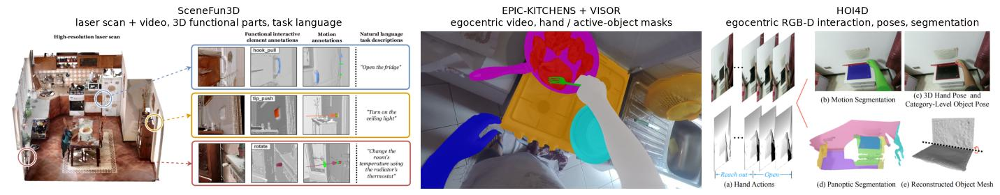

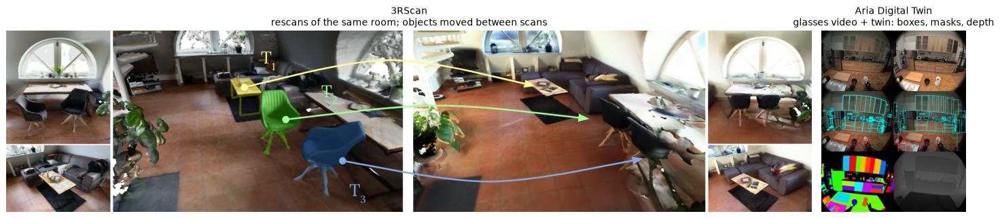

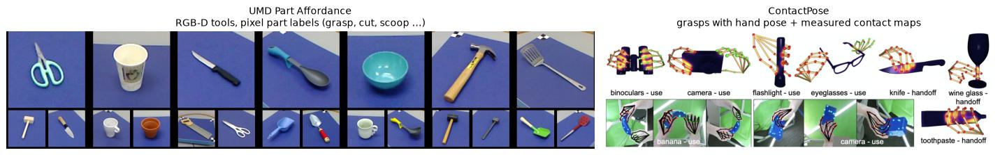

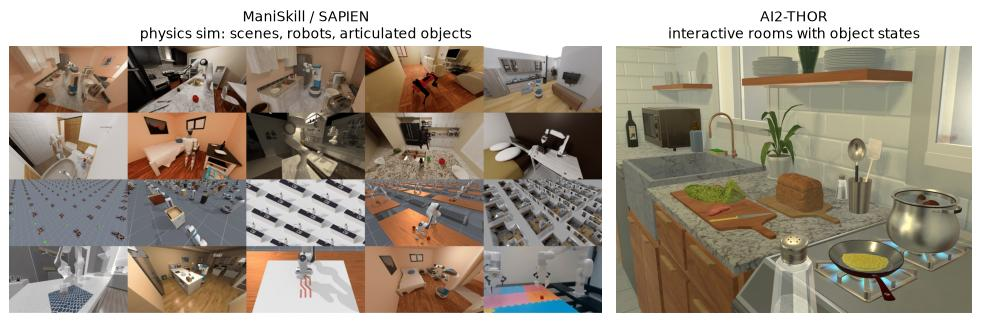

In [3]:
EXT = ASSETS / "external"  # official project images, not our results
for row, width in [
    ([(EXT / "scenefun3d.png", "SceneFun3D\nlaser scan + video, 3D functional parts, task language"),
      (EXT / "epic_visor.png", "EPIC-KITCHENS + VISOR\negocentric video, hand / active-object masks"),
      (EXT / "hoi4d.png", "HOI4D\negocentric RGB-D interaction, poses, segmentation")], 16),
    ([(EXT / "rio_3rscan.png", "3RScan\nrescans of the same room; objects moved between scans"),
      (EXT / "adt.jpg", "Aria Digital Twin\nglasses video + twin: boxes, masks, depth")], 16),
    ([(EXT / "umd.png", "UMD Part Affordance\nRGB-D tools, pixel part labels (grasp, cut, scoop …)"),
      (EXT / "contactpose.png", "ContactPose\ngrasps with hand pose + measured contact maps")], 16),
    ([(EXT / "maniskill.jpg", "ManiSkill / SAPIEN\nphysics sim: scenes, robots, articulated objects"),
      (EXT / "ai2thor.jpg", "AI2-THOR\ninteractive rooms with object states")], 11),
]:
    show_row(row, width=width, fontsize=11)
plt.show()

<sub>Sources: scenefun3d.github.io · epic-kitchens.github.io/VISOR · hoi4d.github.io · waldjohannau.github.io/RIO · projectaria.com/datasets/adt · users.umiacs.umd.edu/~fermulcm/affordance · github.com/facebookresearch/ContactPose · github.com/mani-skill/ManiSkill · github.com/allenai/ai2thor</sub>

**Later, for the VLA route (not first round):** H2RBench · HumanGen + RoboTwin · RH20T · LIBERO

### 2 · Where each dataset enters the plan
> **This section:** which data each experiment stage uses, and where it runs.  
> **Most promising:** SceneFun3D alone carries E0 → E2, so one loader and one download script cover everything until E3.

```text
E0  data + projection check         SceneFun3D, 1 scene                       Mac        ✅ done
E1  frozen features, memory readout SceneFun3D, dev scene + 1 check scene     Mac        ▶ next
E2  affordance layer vs controls    SceneFun3D, 12 scenes (8 / 2 / 2)         Isambard
E3  environment / state change      ManiSkill (alt. AI2-THOR, 3RScan)         later
 +  memory over real video          EPIC-KITCHENS + VISOR  or  HOI4D          later
backup: local affordance head       UMD Part Affordance
```

### 3 · Lab 1 · pipeline mechanics on a small RGB-D sample
> **This section:** the full memory loop on 5 frames: features → 3D memory with source frames → query → visible / out of view / occluded.  
> **Most promising:** the voxel memory with per-frame provenance and the coverage split are the skeleton E1 reuses directly. DINOv2 takes about 60 ms per frame on the Mac, so features are not the bottleneck.

Open3D Redwood sample: a synthetic living room, 5 RGB-D frames, odometry poses (not SceneFun3D) · `notebooks/01_step_by_step_demo.ipynb`
```text
RGB-D frame ─► DINOv2 ViT-S/14 patch features ─► back-project with depth + pose
            ─► 3 cm voxel memory (feature + which frames saw it)
            ─► query one patch: cosine match ─► visible now / out of view / occluded
```

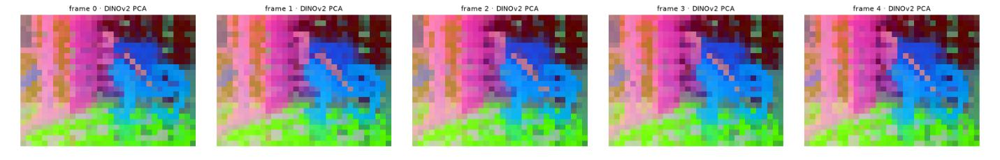

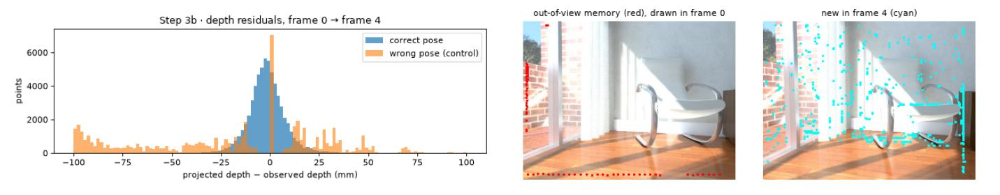

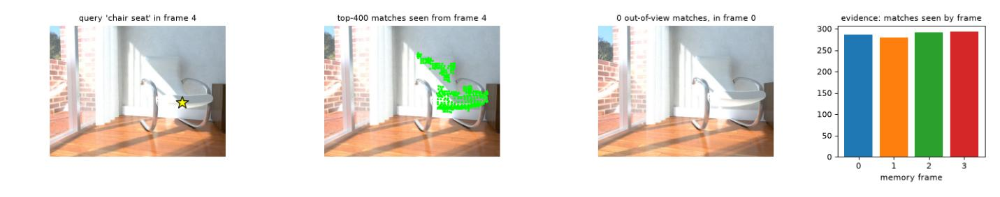

,value
"depth residual, frame 0 → 4 (median)",5.6 mm
same with a wrong pose (control),40.0 mm
"DINOv2 on Apple MPS, after warm-up",60 ms / frame
memory from 4 frames,"8,593 voxels, 13.0 MB"


In [4]:
R = RUNS / "demo_redwood"
show_row([(R / "step4_features.png", "")], width=16)
show_row([(R / "step3b_residuals.png", ""), (R / "step6_coverage.png", "")], width=16)
show_row([(R / "step7_query_chair_seat.png", "")], width=16)
plt.show()

m = json.loads((R / "metrics.json").read_text())
residuals, memory = m["e0_depth_residuals"], m["memory"]
pd.DataFrame({"value": {
    "depth residual, frame 0 → 4 (median)": f"{residuals['0 → 4']['median |Δz| (mm)']} mm",
    "same with a wrong pose (control)": f"{residuals['0 → 4 WRONG pose (control)']['median |Δz| (mm)']} mm",
    "DINOv2 on Apple MPS, after warm-up": f"{np.median(m['features_ms_per_frame'][1:]):.0f} ms / frame",
    "memory from 4 frames": f"{memory['voxels (3 cm)']:,} voxels, {memory['memory size (MB)']} MB",
}})

### 4 · SceneFun3D: the primary dataset
> **This section:** the scene we use: splits, the video, the 3D scan and the task language.  
> **Most promising:** task → part links give query/answer pairs for E1–E2 without extra labelling. The camera passes each part and moves on, which gives natural "seen earlier, out of view now" queries for memory readout.

Real indoor scenes: a Faro laser scan (5 mm), iPad RGB video with rendered depth and poses, 3D functional parts of 9 types, and language tasks. License: CC-BY-4.0 plus the ARKitScenes terms.

In [5]:
split_counts(ROOT / "third_party" / "scenefun3d" / "benchmark_file_lists").T

,train,val,test
scenes (visits),200,30,85
videos,527,82,220


In [6]:
SCENE = DATA / VISIT
scan_xyz, scan_rgb = read_laser_scan(SCENE / f"{VISIT}_laser_scan.ply")
crop = np.load(SCENE / f"{VISIT}_crop_mask.npy").astype(bool)
elements = read_annotations(SCENE / f"{VISIT}_annotations.json")
index = index_sequence(DATA, VISIT, VIDEO)
TURNS = upright_cw_turns(list(index.poses.values()))  # hires frames are already upright: 0 turns

heights, edges = np.histogram(scan_xyz[crop, 2], bins=200)
floor_z = edges[np.argmax(heights)]  # densest horizontal slab = floor
below_ceiling = np.flatnonzero(crop & (scan_xyz[:, 2] < floor_z + 1.6))  # display only: hide the ceiling
display_idx = below_ceiling[subsample(len(below_ceiling), 200_000)]
times = index.depth_times[::4]
print(f"{len(scan_xyz):,} scan points · {len(elements)} functional parts · {len(index.depth_times)} frames, "
      f"{float(index.depth_times[-1]) - float(index.depth_times[0]):.0f} s · rotation from poses: {TURNS} turns")

8,880,684 scan points · 38 functional parts · 1025 frames, 113 s · rotation from poses: 0 turns


#### Walkthrough of video 42444490 with ORACLE functional parts (every 4th frame)

In [7]:
VIDEO_PATH = ASSETS / "walkthrough_421069.mp4"
log = render_walkthrough(index, times, TURNS, pixel_step=4, elements=elements, scan_xyz=scan_xyz,
                         display_xy=scan_xyz[display_idx, :2], out_path=VIDEO_PATH, fps=12)
seen = (log.visible_points >= MIN_VISIBLE).any(axis=0)
duration = float(times[-1]) - float(times[0])
print(f"{len(times)} frames shown at {duration / (len(times) / 12):.1f}× real time · "
      f"{seen.sum()}/{len(elements)} functional parts seen at least once")
Video(str(VIDEO_PATH), embed=True, width=1100)

257 frames shown at 5.3× real time · 36/38 functional parts seen at least once


#### 3D: laser scan, functional parts, camera path (drag to rotate; click the legend to toggle)

In [8]:
centres, _ = camera_path(index, index.rgb_times)
scene_3d_figure(scan_xyz[display_idx], scan_rgb[display_idx], elements, scan_xyz, label_colours(elements), centres)

#### Language task → functional part

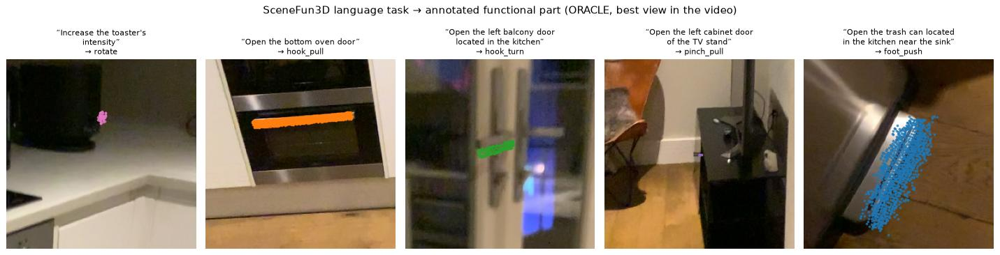

In [9]:
examples = pick_task_examples(read_descriptions(SCENE / f"{VISIT}_descriptions.json"), elements, seen, n=5)
task_examples_figure(examples, elements, log, index, TURNS, scan_xyz)
plt.show()

### 5 · Lab 2 · E0 alignment checks (20 frames, 720×960)
> **This section:** verifies that RGB, depth, intrinsics, poses and the 3D labels line up.  
> **Most promising:** projection is accurate to about 2 px at 720×960, so 3D part labels can be turned into per-frame 2D masks automatically. That gives training supervision and evaluation for E1–E2 without manual labelling, and the same checks rerun on every new scene.

Do RGB, depth, intrinsics, poses and annotations line up? · `notebooks/02_scenefun3d_e0.ipynb`

In [10]:
E0 = RUNS / "scenefun3d_e0"
manifest = json.loads((E0 / "manifest.json").read_text())
r, gate = manifest["results"], manifest["config"]["thresholds"]
checks = pd.DataFrame([
    {"check": "image orientation (from poses)", "measured": "0 turns, all frames within 30° of upright",
     "gate": f"< {gate['upright_max_abs_angle_deg']:.0f}°", "control": "metadata 'Left' would be 90° off",
     "result": "PASS" if r["upright"] else "FAIL"},
    {"check": "depth → laser scan distance (median)", "measured": f"{r['depth_to_scan_median_m'] * 1000:.1f} mm",
     "gate": f"< {gate['depth_to_scan_median_m'] * 1000:.0f} mm", "control": "wrong unit or frame → metres",
     "result": "PASS" if r["depth_to_scan_median_m"] < gate["depth_to_scan_median_m"] else "FAIL"},
    {"check": "SIFT reprojection into a frame 0.3–2 s later", "measured": f"{r['sift_median_px']:.2f} px "
     f"({r['sift_pairs_counted']}/20 pairs)", "gate": f"< {gate['sift_median_px']:.0f} px",
     "control": f"wrong pose: {r['sift_control_median_px']:.0f} px",
     "result": "PASS" if r["sift_median_px"] < gate["sift_median_px"] else "FAIL"},
    {"check": "ORACLE parts land on handles / knobs", "measured": "visual review", "gate": "same part in every view",
     "control": "–", "result": "PASS (foot_push: recheck)"},
]).set_index("check")
checks.style.map(lambda v: "background-color:#2e7d32;color:white;font-weight:bold" if str(v).startswith("PASS")
                 else "", subset=["result"])

,measured,gate,control,result
check,,,,
image orientation (from poses),"0 turns, all frames within 30° of upright",< 30°,metadata 'Left' would be 90° off,PASS
depth → laser scan distance (median),2.4 mm,< 10 mm,wrong unit or frame → metres,PASS
SIFT reprojection into a frame 0.3–2 s later,1.88 px (18/20 pairs),< 3 px,wrong pose: 146 px,PASS
ORACLE parts land on handles / knobs,visual review,same part in every view,–,PASS (foot_push: recheck)


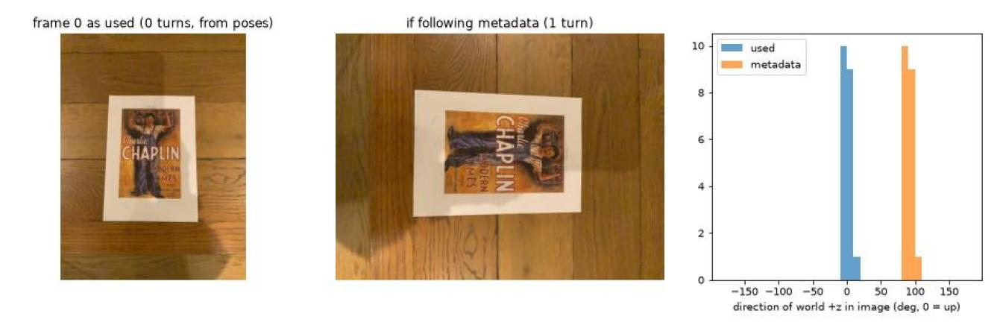

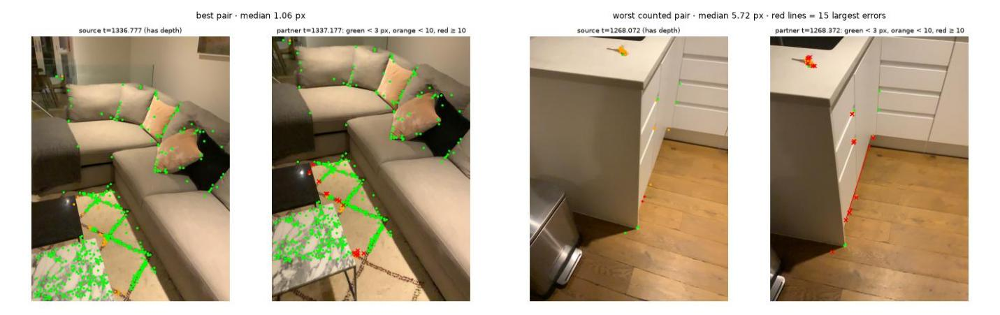

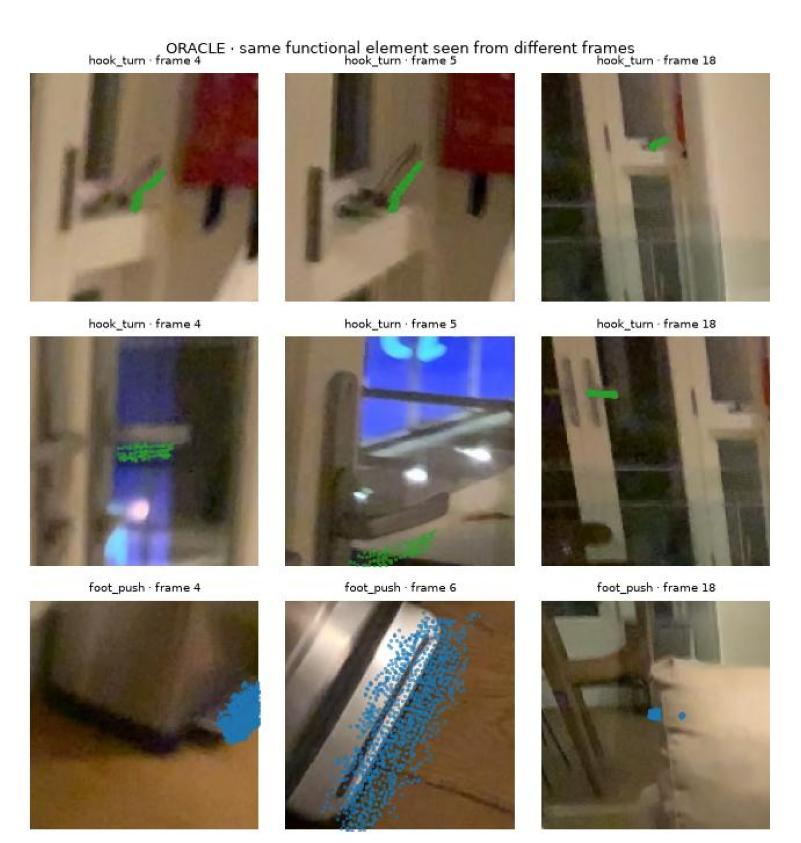

In [11]:
show_row([(E0 / "step2_orientation.jpg", "")], width=15)
show_row([(E0 / "step5_best_pair.jpg", ""), (E0 / "step5_worst_pair.jpg", "")], width=16)
crops = iio.imread(E0 / "step6b_multiview_crops.jpg")[:712]  # first three parts
show_row([(crops, "")], width=9)
plt.show()

**Findings**
- The ARKitScenes `sky_direction` metadata is wrong for hires frames, so rotation is derived from the poses.
- The largest errors are on thin or movable objects and depth edges (worst pair above: flowers, cabinet edge). Depth is rendered from the scan mesh, so these regions are unreliable for E1.
- Functional parts are small: a median of 106 scan points, i.e. a few cm.

### 6 · EPIC-KITCHENS + VISOR: one real kitchen video (P28_101)
> **This section:** what real interaction video looks like: 12 minutes of egocentric cooking with narrated actions, VISOR hand/object masks with contact links, and EPIC-Fields camera poses.  
> **Most promising:** contacts and narrations say *which object was touched, and when*. That is the "find my earlier interaction" query SceneFun3D cannot provide. EPIC-Fields poses place each interaction on a map, so it fits the same memory format as SceneFun3D.

Head-mounted camera, 1920×1080 · narrations from EPIC-KITCHENS-100 · VISOR manual masks on sparse frames · EPIC-Fields poses from structure-from-motion (no depth maps) · non-commercial licences.

In [12]:
EPIC = ROOT / "data" / "epic_visor"
visor = read_visor(EPIC / "P28_101" / "visor_annotations.json", EPIC / "P28_101" / "frames",
                   EPIC / "frame_mapping.json", "P28_101")
narrations, EPIC_FPS = read_narrations(EPIC / "EPIC_100_train.csv", "P28_101")
recon = read_epic_fields(EPIC / "P28_101" / "epic_fields.json")
kitchen = AlignedScene.from_recon(recon)  # rotated so that +z is up (from the head-mounted camera's image-down axis)
overview_table(visor, narrations, recon, EPIC_FPS)

,value
video,"P28_101 · 11 min 58 s · 50 fps · head-mounted,..."
narrated actions (EPIC-KITCHENS-100),120 (76 distinct)
VISOR annotated frames,201 in 34 short subsequences
VISOR masks,"1,049 masks, 32 hand / object classes"
frames with a hand–object contact,171
EPIC-Fields camera poses,"35,823 frames (99.8%)"
EPIC-Fields 3D points,"83,458 (SfM, arbitrary scale, no depth maps)"


#### Walkthrough: every VISOR-annotated frame in time order

In [13]:
EPIC_VIDEO = ASSETS / "walkthrough_P28_101.mp4"
render_visor_walkthrough(visor, narrations, kitchen, EPIC_FPS, EPIC_VIDEO, fps=8)
Video(str(EPIC_VIDEO), embed=True, width=1100)

#### 3D: EPIC-Fields points, camera path, and where each hand contact happened (hover a marker)

In [14]:
epic_3d_figure(kitchen, visor, EPIC_FPS)

#### Object → earlier interactions

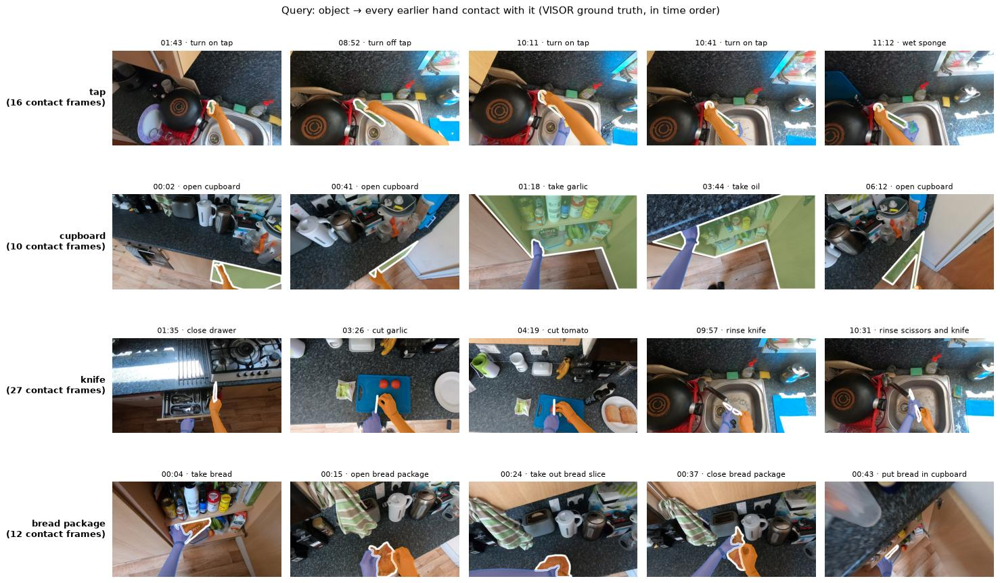

In [15]:
contact_examples_figure(visor, narrations, ["tap", "cupboard", "knife", "bread package"], EPIC_FPS)
plt.show()

<a id="w1-demo"></a>

# 第 3 部分 · E0/E1 的逐步演示

<sub>原文件 `notebooks/01_step_by_step_demo.ipynb`（11-09）· 生成方式：`notebooks/builders/build_01_step_by_step_demo.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## Step-by-step demo：RGB-D 视频 → 三维特征记忆 → 记忆读取

本 notebook 按[快速验证计划](../docs/research/环境记忆Affordance层_快速验证实验计划_Mac_Isambard_2026-11-05.md)中 **E0（空间投影与数据链路）** 和 **E1（冻结特征与小规模记忆读取）** 的顺序，把当前已实现的每一步单独运行并可视化。

| | 内容 |
|---|---|
| 数据 | Open3D 自带的 Redwood 客厅样例：**合成渲染场景**，5 帧 640×480 RGB-D（含模拟深度噪声）+ RGB-D 里程计估计的相机位姿；11 MB，首次运行自动下载到 `data/open3d/`。**不是 SceneFun3D。** |
| 模型 | 冻结 DINOv2 ViT-S/14（`facebook/dinov2-small`，固定 revision），Mac 上用 MPS。 |
| 记忆 | 3 cm 稀疏体素：位置、颜色、平均视觉特征，以及哪些帧观察过它（来源证据）。 |
| 输出 | 每个 3D 视图另存为 `runs/demo_redwood/*.html`（浏览器可离线打开），指标写入 `metrics.json`。 |

**能说明：** 深度、内参、位姿与像素之间的投影链路是否正确；冻结特征能否按像素写入三维记忆并保留来源帧；记忆能否按特征相似度读取，并区分当前可见、视野外和新观察。

**不能说明：** 这里没有 affordance 标签，也没有训练。查询读取的是普通视觉特征的相似度，对应计划中 C1“普通历史记忆”的机制，不是 affordance 层。样例相机只移动约 10 cm / 3°，真正位于视野外的历史体素很少，不能据此判断历史记忆的价值。这些都要在 SceneFun3D 上按 E0/E1 计划检验。

**运行：** `conda activate affordance3d`，在仓库根目录执行 `jupyter lab notebooks/01_step_by_step_demo.ipynb`，然后 Run All（M1 上约 1 分钟）。3D 图可拖动旋转、滚轮缩放，点击图例可显示/隐藏图层。

### Step 0 · 环境与参数

In [1]:
import json
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.features import DinoV2Extractor, fit_pca_coloring, DINO_ID, DINO_REVISION
from affordance3d.frames import load_redwood_sample
from affordance3d.geometry import backproject, depth_residuals, forward_warp, project
from affordance3d.memory import cosine_scores, coverage, fuse, observe
from affordance3d.viz import frustum_trace, image_row, points_trace, save_html, scene_figure

pio.renderers.default = "plotly_mimetype"  # saved outputs render in JupyterLab / VS Code
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")  # photo panels: JPEG keeps the saved notebook small
plt.rcParams["figure.dpi"] = 72
OUT = ROOT / "runs" / "demo_redwood"
OUT.mkdir(parents=True, exist_ok=True)

SAMPLE_STRIDE = 4             # sample every 4th pixel per axis (~1.5 cm apart at 2 m)
VOXEL_SIZE_M = 0.03
DEPTH_TOL_M = 0.05            # visibility test: projected vs observed depth
MEMORY_FRAMES = [0, 1, 2, 3]  # memory is built from this time prefix ...
CURRENT_FRAME = 4             # ... and read from this later view (never written into memory)
QUERIES = {"chair seat": (480, 280), "brick through window": (40, 200), "floor": (300, 440)}  # (u, v) in current frame
TOP_K = 400
FRAME_COLOURS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

import torch, open3d, transformers
print(f"python {sys.version.split()[0]} | torch {torch.__version__} (MPS available: {torch.backends.mps.is_available()}) "
      f"| transformers {transformers.__version__} | open3d {open3d.__version__}")
print("outputs ->", OUT.relative_to(ROOT))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


python 3.12.16 | torch 2.15.0 (MPS available: True) | transformers 5.22.1 | open3d 0.20.0
outputs -> runs/demo_redwood


### Step 1 · 读取 RGB-D 与相机（E0 输入）

每一帧统一成同一个记录：RGB、以米为单位的深度（0 表示无效）、内参 $K$、相机到世界的位姿。之后的步骤只依赖这个记录，换成 SceneFun3D 时只需要换读取函数。

检查项：深度单位（PNG 存的是毫米，这里除以 1000）、图像与深度尺寸一致、位姿方向（camera→world）。

,size (H×W),valid depth,depth range (m),camera position (m)
frame,,,,
0,480×640,87%,0.95 – 2.70,"[2.0, 2.0, -0.3]"
1,480×640,87%,0.98 – 2.70,"[2.0, 1.977, -0.3]"
2,480×640,87%,1.01 – 2.70,"[1.999, 1.954, -0.302]"
3,480×640,87%,1.03 – 2.68,"[1.999, 1.93, -0.303]"
4,480×640,88%,1.05 – 2.70,"[2.001, 1.905, -0.305]"


K =
[[525.    0.  319.5]
 [  0.  525.  239.5]
 [  0.    0.    1. ]]
camera motion frame 0 -> 4: 9.5 cm, 3.0 deg


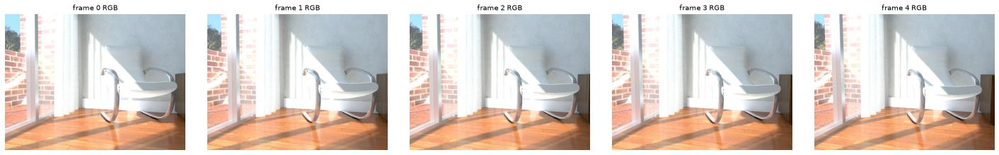

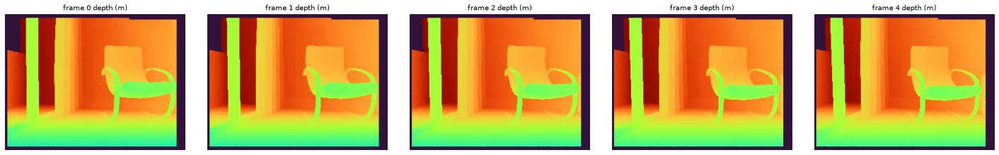

In [2]:
frames = load_redwood_sample(ROOT / "data" / "open3d")
current = frames[CURRENT_FRAME]

display(pd.DataFrame([{
    "frame": f.index,
    "size (H×W)": f"{f.image_hw[0]}×{f.image_hw[1]}",
    "valid depth": f"{(f.depth_m > 0).mean():.0%}",
    "depth range (m)": f"{f.depth_m[f.depth_m > 0].min():.2f} – {f.depth_m.max():.2f}",
    "camera position (m)": np.round(f.cam_to_world[:3, 3], 3).tolist(),
} for f in frames]).set_index("frame"))

relative = np.linalg.inv(frames[0].cam_to_world) @ current.cam_to_world
rotation_deg = np.degrees(np.arccos(np.clip((np.trace(relative[:3, :3]) - 1) / 2, -1, 1)))
print(f"K =\n{frames[0].intrinsics}")
print(f"camera motion frame 0 -> {CURRENT_FRAME}: {np.linalg.norm(relative[:3, 3]) * 100:.1f} cm, {rotation_deg:.1f} deg")

fig, _ = image_row([f.rgb for f in frames], [f"frame {f.index} RGB" for f in frames])
fig.savefig(OUT / "step1_rgb.png", dpi=80)
fig, _ = image_row([f.depth_m for f in frames], [f"frame {f.index} depth (m)" for f in frames], cmap="turbo")
fig.savefig(OUT / "step1_depth.png", dpi=80)
plt.show()

### Step 2 · 单帧反投影：像素 → 三维点

对每个有效深度像素 $(u, v)$：

$$x_w = R_{wc}\,\big(D(u,v)\,K^{-1}[u, v, 1]^\top\big) + t_{wc}$$

与《可行性与实现建议》§2.2 的公式相同。下图是第 0 帧每 2 个像素取 1 个得到的世界坐标点，黑色线框是相机位置和朝向。

In [3]:
points0, pixels0 = backproject(frames[0], stride=2)
colours0 = frames[0].rgb[pixels0[:, 1], pixels0[:, 0]] / 255.0
fig = scene_figure([points_trace(points0, colours0, name="frame 0 points"), frustum_trace(frames[0])],
                   f"Step 2 · frame 0 back-projected ({len(points0):,} points)")
save_html(fig, OUT / "step2_single_frame.html")
fig

### Step 3 · 多帧对齐检查（E0 核心）

三个互相印证的检查：

- **3a 叠加：** 5 帧各自反投影后按帧着色叠在一起；位姿正确时不同颜色互相重合，没有重影或错层。
- **3b 深度残差：** 把第 0 帧的点投影到第 j 帧，比较“投影得到的深度”和“第 j 帧实测深度”。同时设一个**对照组**：故意给第 4 帧用第 0 帧的位姿，模拟“位姿没读对”，确认这个指标真能发现错误。
- **3c 重投影图像：** 用深度和位姿把第 0 帧渲染到第 4 帧的视角，再与真实第 4 帧相减；正确时差异图接近全黑，错误位姿会在边缘处亮起。

In [4]:
traces = []
for f, colour in zip(frames, FRAME_COLOURS):
    pts, _ = backproject(f, stride=SAMPLE_STRIDE)
    traces += [points_trace(pts, colour, name=f"frame {f.index}", size=1.5, max_points=5000),
               frustum_trace(f, colour)]
fig = scene_figure(traces, "Step 3a · all frames overlaid, coloured by frame (aligned = colours coincide)")
save_html(fig, OUT / "step3a_overlay.html")
fig

,points compared,median |Δz| (mm),p90 |Δz| (mm),share < 1 cm
0 → 1,65654,5.2,14.6,77%
0 → 2,64580,5.3,15.5,77%
0 → 3,63686,5.4,15.9,76%
0 → 4,62908,5.6,16.4,75%
0 → 4 WRONG pose (control),66761,40.0,194.0,13%


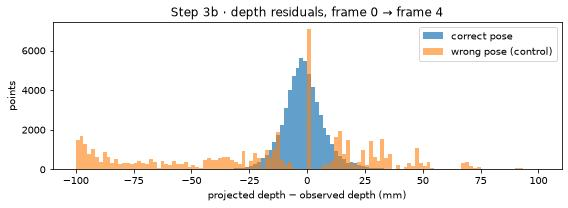

In [5]:
wrong_pose_current = replace(current, cam_to_world=frames[0].cam_to_world)  # deliberate error (control)

def residual_stats(residuals: np.ndarray) -> dict:
    magnitude = np.abs(residuals) * 1000
    return {"points compared": magnitude.size, "median |Δz| (mm)": round(float(np.median(magnitude)), 1),
            "p90 |Δz| (mm)": round(float(np.percentile(magnitude, 90)), 1),
            "share < 1 cm": f"{np.mean(magnitude < 10):.0%}"}

residuals = {f"0 → {f.index}": depth_residuals(frames[0], f, stride=2) for f in frames[1:]}
residuals[f"0 → {CURRENT_FRAME} WRONG pose (control)"] = depth_residuals(frames[0], wrong_pose_current, stride=2)
residual_table = pd.DataFrame({name: residual_stats(r) for name, r in residuals.items()}).T
display(residual_table)

fig, axis = plt.subplots(figsize=(8, 3))
bins = np.linspace(-100, 100, 121)
axis.hist(residuals[f"0 → {CURRENT_FRAME}"] * 1000, bins=bins, alpha=0.7, label="correct pose")
axis.hist(residuals[f"0 → {CURRENT_FRAME} WRONG pose (control)"] * 1000, bins=bins, alpha=0.6, label="wrong pose (control)")
axis.set_xlabel("projected depth − observed depth (mm)"); axis.set_ylabel("points"); axis.legend()
axis.set_title(f"Step 3b · depth residuals, frame 0 → frame {CURRENT_FRAME}")
fig.tight_layout(); fig.savefig(OUT / "step3b_residuals.png", dpi=80)
plt.show()

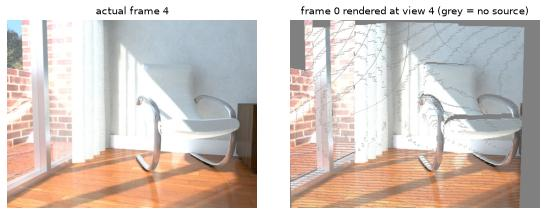

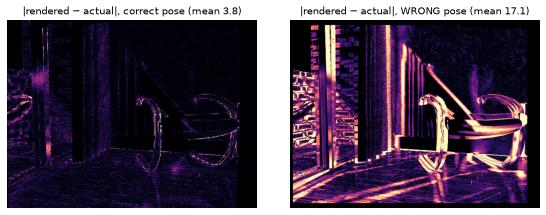

E0 on this sample: median residual 5.6 mm with the recorded poses vs 40.0 mm with the wrong-pose control; no mirroring or scale error is visible.
-> The projection chain works. This says nothing about any learned method.


In [6]:
warped, filled = forward_warp(frames[0], current)
warped_wrong, filled_wrong = forward_warp(frames[0], wrong_pose_current)

def colour_error(rendered: np.ndarray, mask: np.ndarray) -> np.ndarray:
    error = np.abs(rendered.astype(int) - current.rgb.astype(int)).mean(axis=-1)
    return np.where(mask, error, 0.0)

shown = np.where(filled[..., None], warped, 128).astype(np.uint8)  # grey = no source pixel
fig, _ = image_row([current.rgb, shown], [f"actual frame {CURRENT_FRAME}", "frame 0 rendered at view 4 (grey = no source)"])
fig.savefig(OUT / "step3c_warp.png", dpi=80)
error_ok, error_bad = colour_error(warped, filled), colour_error(warped_wrong, filled_wrong)
fig, _ = image_row([error_ok, error_bad],
                   [f"|rendered − actual|, correct pose (mean {error_ok[filled].mean():.1f})",
                    f"|rendered − actual|, WRONG pose (mean {error_bad[filled_wrong].mean():.1f})"],
                   cmap="magma", vmin=0, vmax=60)
fig.savefig(OUT / "step3c_error.png", dpi=80)
plt.show()

ok = residual_table.loc[f"0 → {CURRENT_FRAME}"]["median |Δz| (mm)"]
bad = residual_table.iloc[-1]["median |Δz| (mm)"]
print(f"E0 on this sample: median residual {ok} mm with the recorded poses vs {bad} mm with the wrong-pose control; "
      "no mirroring or scale error is visible.\n-> The projection chain works. This says nothing about any learned method.")

### Step 4 · 冻结 DINOv2 patch 特征（E1 编码器）

整帧缩放到 448×336（不裁剪，保证 patch 与原图位置一一对应），得到 32×24 = 768 个 patch，每个 384 维，对应原图约 20×20 像素。逐帧 batch=1 推理。

为了能“看见”384 维特征，把所有帧的 patch 一起做一次 PCA，取前 3 个主成分当作 RGB。因为是联合拟合，**同一种颜色在不同帧中代表相近的特征**；颜色本身没有语义含义。

W1109 15:17:36.632000 13374 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

device=mps  grid=24x32  dim=384
ms per frame: [732, 60, 60, 61, 63] (the first includes one-off warm-up)


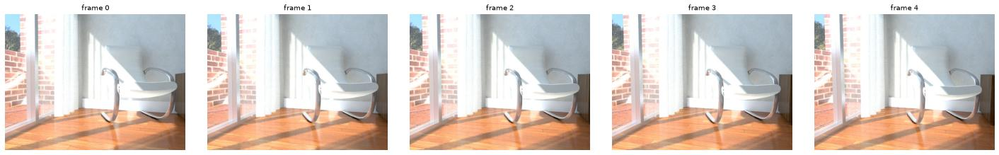

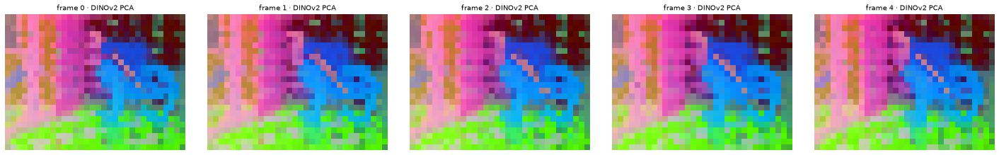

In [7]:
extractor = DinoV2Extractor()
patch_features, seconds = [], []
for f in frames:
    start = time.perf_counter()
    patch_features.append(extractor(f.rgb))
    seconds.append(time.perf_counter() - start)
grid_h, grid_w, dim = patch_features[0].grid.shape
print(f"device={extractor.device}  grid={grid_h}x{grid_w}  dim={dim}")
print("ms per frame:", [round(s * 1000) for s in seconds], "(the first includes one-off warm-up)")

coloring = fit_pca_coloring(np.concatenate([p.grid.reshape(-1, dim) for p in patch_features]))
fig, _ = image_row([f.rgb for f in frames], [f"frame {f.index}" for f in frames])
fig, _ = image_row([coloring.to_rgb(p.grid) for p in patch_features],
                   [f"frame {i} · DINOv2 PCA" for i in range(len(frames))], interpolation="nearest")
fig.savefig(OUT / "step4_features.png", dpi=80)
plt.show()

### Step 5 · 写入三维记忆（只用时间前缀）

只用第 0–3 帧建记忆；第 4 帧作为“当前观察”留给 Step 6–7，**不写入记忆**，避免读到未来。

每个采样像素：反投影得到三维位置 → 取所在 patch 的特征 → 落入 3 cm 体素 → 同一体素内取平均（静态场景下的普通融合基线）→ 记录哪些帧观察过它（来源证据）。

下面的 3D 图默认按真实颜色显示；**点击图例 “DINOv2 feature (PCA)”** 可切换到特征颜色，和 Step 4 的 2D 颜色一致。

In [8]:
observations = [observe(f, p, stride=SAMPLE_STRIDE) for f, p in zip(frames, patch_features)]
memory = fuse([observations[i] for i in MEMORY_FRAMES], VOXEL_SIZE_M)
frames_per_voxel = memory.seen_by.sum(axis=1)

memory_summary = {
    "frames written": str(MEMORY_FRAMES),
    "samples written": sum(len(observations[i].xyz) for i in MEMORY_FRAMES),
    "voxels (3 cm)": memory.n_voxels,
    "memory size (MB)": round(memory.nbytes / 2**20, 1),
    **{f"voxels seen by {k} frame(s)": int((frames_per_voxel == k).sum()) for k in range(1, len(MEMORY_FRAMES) + 1)},
}
display(pd.Series(memory_summary, name="value").to_frame())

fig = scene_figure(
    [points_trace(memory.xyz, memory.rgb, name="colour"),
     points_trace(memory.xyz, coloring.to_rgb(memory.features), name="DINOv2 feature (PCA)", visible="legendonly"),
     *[frustum_trace(frames[i], FRAME_COLOURS[i]) for i in MEMORY_FRAMES]],
    "Step 5 · voxel memory from frames 0–3 (click legend to switch colour / feature view)")
save_html(fig, OUT / "step5_memory.html")
fig

,value
frames written,"[0, 1, 2, 3]"
samples written,66840
voxels (3 cm),8593
memory size (MB),13.0
voxels seen by 1 frame(s),1771
voxels seen by 2 frame(s),1479
voxels seen by 3 frame(s),1576
voxels seen by 4 frame(s),3767


### Step 6 · 当前视角下的覆盖统计

以第 4 帧为当前视角，把记忆中的每个体素分成三类，并统计当前帧中的“新观察”：

| 类别 | 含义 |
|---|---|
| visible now | 记忆中有，当前画面里也看得到 |
| out of view | 记忆中有，但在当前画面外（历史证据） |
| occluded / depth mismatch | 投影在画面内，但深度对不上或缺失：真遮挡；当前帧该像素没有有效深度（右侧和底部的无效深度带）；体素平均位置落在前后两个表面之间（轮廓）；深度噪声 |
| new in current | 当前帧看到、但记忆中从未观察过的位置 |

因为相机移动很小，预计 out of view 只是第 0 帧上、左、下边缘的窄条。new in current 中真正的新内容是第 4 帧右边缘新露出的部分；零散分布在窗帘、窗户和椅子轮廓上的点，多半是深度噪声让采样落进了相邻的空体素，不是新物体。

,voxels,share
visible now,7992,93.0%
out of view,68,0.8%
occluded / depth mismatch,533,6.2%


new in current frame: 495 of 16786 samples (2.9%) fall in voxels the memory never observed


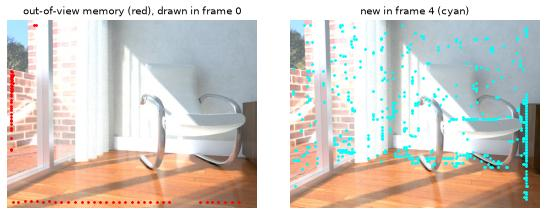

In [9]:
cov = coverage(memory, current, observations[CURRENT_FRAME], DEPTH_TOL_M)
coverage_counts = {"visible now": int(cov.visible_now.sum()), "out of view": int(cov.out_of_view.sum()),
                   "occluded / depth mismatch": int(cov.occluded.sum())}
display(pd.DataFrame({"voxels": coverage_counts,
                      "share": {k: f"{v / memory.n_voxels:.1%}" for k, v in coverage_counts.items()}}))
n_current = len(observations[CURRENT_FRAME].xyz)
print(f"new in current frame: {int(cov.new_in_current.sum())} of {n_current} samples "
      f"({cov.new_in_current.mean():.1%}) fall in voxels the memory never observed")

fig = scene_figure(
    [points_trace(memory.xyz[cov.visible_now], "lightgrey", name="visible now", size=1.5),
     points_trace(memory.xyz[cov.out_of_view], "red", name="out of view", size=4),
     points_trace(memory.xyz[cov.occluded], "orange", name="occluded / depth mismatch", size=3),
     frustum_trace(current, "black")],
    f"Step 6 · memory voxels relative to current frame {CURRENT_FRAME}")
save_html(fig, OUT / "step6_coverage.html")
fig.show()

uv_out, _, inside_out = project(memory.xyz[cov.out_of_view], frames[0])
current_obs = observations[CURRENT_FRAME]
uv_new, _, inside_new = project(current_obs.xyz[cov.new_in_current], current)
fig, axes = image_row([frames[0].rgb, current.rgb],
                      ["out-of-view memory (red), drawn in frame 0", f"new in frame {CURRENT_FRAME} (cyan)"])
axes[0].scatter(uv_out[inside_out, 0], uv_out[inside_out, 1], s=3, c="red")
axes[1].scatter(uv_new[inside_new, 0], uv_new[inside_new, 1], s=3, c="cyan")
fig.savefig(OUT / "step6_coverage.png", dpi=80)
plt.show()

### Step 7 · 记忆读取：用当前画面中的一个 patch 查询记忆（E1 机制）

取第 4 帧某个像素所在 patch 的特征作为查询，与记忆中每个体素的特征算余弦相似度，取最相近的 400 个体素，然后看：

1. 3D 相似度热图（亮 = 相似）；
2. 这些匹配中有多少在当前画面里、多少**只存在于历史中（视野外）**；
3. 来源证据：匹配体素由哪些过去帧观察到；把视野外的匹配画回它们的来源帧。

这是普通视觉特征的相似度读取，用于检验“写入—读取—追溯来源”的机制是否成立；它不代表 affordance 理解。

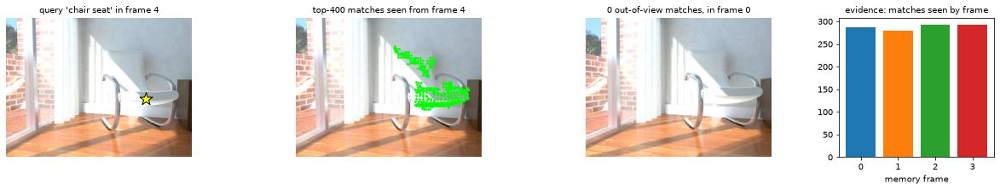

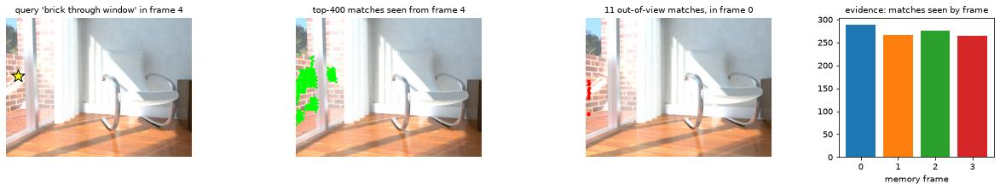

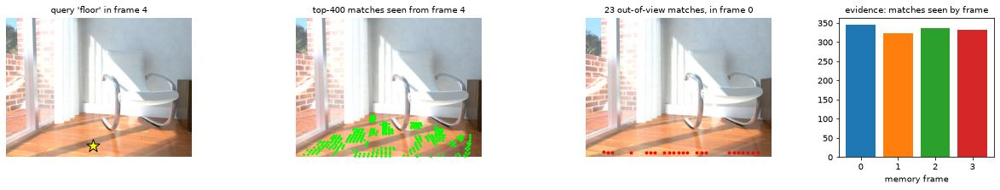

,"pixel (u, v)",best score,score of #400,visible now,out of view,occluded / mismatch
chair seat,"(480, 280)",0.919,0.528,362,0,38
brick through window,"(40, 200)",0.832,0.44,340,11,49
floor,"(300, 440)",0.978,0.666,346,23,31


In [10]:
def show_query(name: str, u: int, v: int, scores: np.ndarray, top: np.ndarray) -> plt.Figure:
    top_out = top[cov.out_of_view[top]]
    evidence = memory.seen_by[top].sum(axis=0)
    source = int(memory.frame_ids[np.argmax(memory.seen_by[top_out].sum(axis=0))]) if len(top_out) else 0
    uv_now, _, in_now = project(memory.xyz[top], current)
    uv_src, _, in_src = project(memory.xyz[top_out], frames[source])

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2), gridspec_kw={"width_ratios": [4, 4, 4, 2.4]})
    for axis, image, title in [(axes[0], current.rgb, f"query '{name}' in frame {CURRENT_FRAME}"),
                               (axes[1], current.rgb, f"top-{TOP_K} matches seen from frame {CURRENT_FRAME}"),
                               (axes[2], frames[source].rgb, f"{len(top_out)} out-of-view matches, in frame {source}")]:
        axis.imshow(image); axis.set_title(title, fontsize=10); axis.set_axis_off()
    axes[0].scatter([u], [v], s=250, c="yellow", marker="*", edgecolors="black")
    axes[1].scatter(uv_now[in_now, 0], uv_now[in_now, 1], s=3, c="lime")
    axes[2].scatter(uv_src[in_src, 0], uv_src[in_src, 1], s=8, c="red")
    axes[3].bar([str(i) for i in memory.frame_ids], evidence, color=[FRAME_COLOURS[i] for i in memory.frame_ids])
    axes[3].set_title("evidence: matches seen by frame", fontsize=10); axes[3].set_xlabel("memory frame")
    fig.tight_layout()
    return fig

query_results = {}
for name, (u, v) in QUERIES.items():
    query = patch_features[CURRENT_FRAME].at_pixels(np.array([[u, v]]))[0]
    scores = cosine_scores(memory, query)
    top = np.argsort(-scores)[:TOP_K]
    query_results[name] = {
        "pixel (u, v)": (u, v), "best score": round(float(scores.max()), 3),
        f"score of #{TOP_K}": round(float(scores[top[-1]]), 3),
        "visible now": int(cov.visible_now[top].sum()), "out of view": int(cov.out_of_view[top].sum()),
        "occluded / mismatch": int(cov.occluded[top].sum()),
    }
    slug = name.replace(" ", "_")
    fig3d = scene_figure([points_trace(memory.xyz, values=scores, name="cosine similarity", colorscale="Inferno",
                                       cmin=0.0, cmax=1.0),
                          points_trace(memory.xyz[top], "cyan", name=f"top-{TOP_K}", size=3, visible="legendonly"),
                          frustum_trace(current, "white")],
                         f"Step 7 · query '{name}': similarity of every memory voxel")
    fig3d.update_layout(scene_bgcolor="black")
    save_html(fig3d, OUT / f"step7_query_{slug}.html")
    fig3d.show()
    show_query(name, u, v, scores, top).savefig(OUT / f"step7_query_{slug}.png", dpi=80)
    plt.show()

display(pd.DataFrame(query_results).T)

### Step 8 · 汇总与输出

In [11]:
metrics = {
    "data": {"source": "Open3D SampleRedwoodRGBDImages (synthetic living room, odometry poses)",
             "frames": len(frames), "memory_frames": MEMORY_FRAMES, "current_frame": CURRENT_FRAME},
    "config": {"sample_stride": SAMPLE_STRIDE, "voxel_size_m": VOXEL_SIZE_M, "depth_tol_m": DEPTH_TOL_M,
               "model": DINO_ID, "revision": DINO_REVISION, "input_hw": list(extractor.input_hw),
               "device": extractor.device, "torch": torch.__version__},
    "e0_depth_residuals": residual_table.to_dict(orient="index"),
    "features_ms_per_frame": [round(s * 1000, 1) for s in seconds],
    "memory": {k: (v if isinstance(v, (int, float)) else str(v)) for k, v in memory_summary.items()},
    "coverage": {**coverage_counts, "new_in_current": int(cov.new_in_current.sum()), "current_samples": n_current},
    "queries": {k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in q.items()} for k, q in query_results.items()},
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False, default=int))

e0_median_mm = residual_table.loc[f"0 → {CURRENT_FRAME}", "median |Δz| (mm)"]
display(pd.DataFrame({
    "value": [f"{e0_median_mm} mm",
              f"{np.median(seconds[1:]) * 1000:.0f} ms/frame ({extractor.device})",
              f"{memory.n_voxels:,} voxels, {memory.nbytes / 2**20:.1f} MB",
              f"{coverage_counts['out of view']} voxels ({coverage_counts['out of view'] / memory.n_voxels:.1%})"],
}, index=["E0 median depth residual (0→4)", "DINOv2 ViT-S/14 @448×336", "memory (frames 0–3)",
          "history-only, outside current view"]))
print("saved:", *sorted(p.name for p in OUT.iterdir() if p.suffix in {".html", ".png", ".json"}), sep="\n  ")

,value
E0 median depth residual (0→4),5.6 mm
DINOv2 ViT-S/14 @448×336,60 ms/frame (mps)
memory (frames 0–3),"8,593 voxels, 13.0 MB"
"history-only, outside current view",68 voxels (0.8%)


saved:
  metrics.json
  step1_depth.png
  step1_rgb.png
  step2_single_frame.html
  step3a_overlay.html
  step3b_residuals.png
  step3c_error.png
  step3c_warp.png
  step4_features.png
  step5_memory.html
  step6_coverage.html
  step6_coverage.png
  step7_query_brick_through_window.html
  step7_query_brick_through_window.png
  step7_query_chair_seat.html
  step7_query_chair_seat.png
  step7_query_floor.html
  step7_query_floor.png


#### 结论与下一步

**这次运行说明了：** E0 投影链路在样例数据上正确（残差为毫米级，错误位姿对照被明显检出）；冻结 DINOv2 特征在 M1 的 MPS 上可用；特征可以写入带来源帧的三维体素记忆，并能按相似度读取，区分当前可见、视野外和新观察。

**没有说明：** 任何 affordance 能力（没有标签、没有训练）；历史记忆的价值（样例相机几乎不动，视野外部分很少）；真实传感器噪声或跨场景表现。

**下一步（按计划）：**
1. 检查一个 SceneFun3D train/val 序列的包大小，下载 1 个场景的 `hires_wide` / `hires_depth` / `hires_poses` 等资产；
2. 写一个 SceneFun3D 读取函数，输出同样的 `Frame` 记录，本 notebook 的 Step 1–7 即可原样运行，完成 E0（10–20 帧起步）；
3. E1：用开发场景的功能区域 GT 建立原型、在独立视图上读取，区分训练内检查与独立视图诊断。

<a id="w1-e0"></a>

# 第 4 部分 · SceneFun3D 的数据链路检查（E0）

<sub>原文件 `notebooks/02_scenefun3d_e0.ipynb`（11-09）· 生成方式：`notebooks/builders/build_02_scenefun3d_e0.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## E0 · SceneFun3D：数据链路与空间投影检查（场景 421069 / 序列 42444490）

**E0 要回答的问题：** 图像、深度、相机内外参和标注坐标是否对齐？（见[快速验证计划](../docs/research/环境记忆Affordance层_快速验证实验计划_Mac_Isambard_2026-11-05.md) §3）

| | 内容 |
|---|---|
| 数据 | SceneFun3D v1 train，visit 421069，video 42444490（该场景最长的一段）。`hires_wide` RGB、`hires_depth`（**Faro mesh 渲染深度**，不是传感器深度）、`hires_poses`（COLMAP 估计，**Faro 坐标系**）、逐帧内参；不混用 lowres/ARKit 路径。 |
| 场景选择 | 在 16 个候选 train 场景中按功能部件数量挑选：38 个部件，9 种类型全覆盖，压缩下载 0.9 GB。**帧按时间均匀抽取，不看标签。** |
| 分辨率 | 原图 1440×1920（宽×高，竖屏存储）；每 2 个像素取 1（720×960），内参精确缩放。 |
| GT 标注 | 功能区域标注只用于 **ORACLE 诊断**（Step 3、6），不进入任何记忆或模型。 |
| 阈值 | 下面的通过门槛是在这个开发场景上锁定的工程门槛，写入 manifest；不是统计结论。 |

**E0 通过只说明工程链路可用，不说明任何方法有效。**

运行：`conda activate affordance3d`；先下载数据 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490`（约 0.9 GB，可中断，重复执行即续传）；再在仓库根目录 `jupyter lab notebooks/02_scenefun3d_e0.ipynb`，Run All。

### Step 0 · 参数

In [1]:
import json
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.e0_checks import (epipolar_inliers, match_features, nearest_distances, reproject_matches,
                                    sift_features, visible_point_counts)
from affordance3d.geometry import backproject, project, rotate_frame_cw, visible_mask
from affordance3d.scenefun3d import (SKY_TO_CW_TURNS, index_sequence, load_frames, load_sequence, pick_partners,
                                     read_annotations, read_laser_scan, read_sky_direction, read_traj_poses,
                                     sky_angle_deg, upright_cw_turns)
from affordance3d.viz import Z_UP_VIEW, frustum_trace, image_row, points_trace, save_html, scene_figure, subsample

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams["figure.dpi"] = 72

VISIT, VIDEO = "421069", "42444490"
DATA = ROOT / "data" / "scenefun3d"  # python scripts/download_scenefun3d.py --visit 421069 --video 42444490
if not (DATA / VISIT / VIDEO / "hires_depth").is_dir():
    raise FileNotFoundError(f"scene data missing under {DATA}; run the download script first")
TOOLKIT = ROOT / "third_party" / "scenefun3d"
SCENE = DATA / VISIT
N_FRAMES = 20                 # plan: start with 10-20 frames, then 40-80
PIXEL_STEP = 2                # 1440x1920 (W x H) -> 720x960
DEPTH_TOL_M = 0.05            # visibility test (projected vs observed depth)
LIFT_STRIDE = 8               # pixel stride when lifting depth for the laser-scan check
MIN_VISIBLE_POINTS = 10       # an element counts as "seen" in a frame with at least this many visible points
PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S = 0.3, 2.0  # Step 5: partner frame 0.3-2 s after each sampled frame
EPIPOLAR_PX = 1.5             # Step 5: RANSAC fundamental-matrix threshold (image-only match filtering)
DISPLAY_CUT_M = 1.6           # 3D views only: hide scan points this far above the floor (ceiling)
THRESHOLDS = {                # E0 engineering gates, locked on this development scene
    "upright_max_abs_angle_deg": 30.0,
    "depth_to_scan_median_m": 0.01,
    "sift_median_px": 3.0,
    "sift_min_matches": 20,
    "control_ratio": 5.0,
}
OUT = ROOT / "runs" / "scenefun3d_e0"
OUT.mkdir(parents=True, exist_ok=True)

SKY_METADATA = read_sky_direction(TOOLKIT / "benchmark_file_lists" / "arkitscenes" / "metadata.csv", VIDEO)
TURNS_METADATA = SKY_TO_CW_TURNS[SKY_METADATA]
TURNS = upright_cw_turns(list(read_traj_poses(SCENE / VIDEO / "hires_poses.traj").values()))
print(f"data: {DATA.relative_to(ROOT)}")
print(f"ARKitScenes metadata: sky_direction = {SKY_METADATA} (would mean {TURNS_METADATA} clockwise turns)")
print(f"poses of the stored hires frames: {TURNS} clockwise turns needed -> using {TURNS}")

data: data/scenefun3d
ARKitScenes metadata: sky_direction = Left (would mean 1 clockwise turns)
poses of the stored hires frames: 0 clockwise turns needed -> using 0


### Step 1 · 资产清单与帧选择

从全部可用帧（同时具备 RGB、深度、内参和时间上足够近的位姿）中按时间均匀取 `N_FRAMES` 帧，保留时间顺序。

,files,size (MB)
asset,,
421069_annotations.json,1,1.7
421069_crop_mask.npy,1,8.9
421069_descriptions.json,1,0.0
421069_laser_scan.ply,1,133.2
42444490,1,0.1
42444490/hires_depth,1025,422.7
42444490/hires_poses.traj,1,0.1
42444490/hires_wide,1025,349.8
42444490/hires_wide_intrinsics,1025,0.0


,timestamp (s),pose gap (ms),size (H×W),valid depth,depth range (m)
frame,,,,,
0,1231.487,0.0,960×720,100%,0.31 – 0.51
1,1236.868,0.0,960×720,100%,0.95 – 2.01
2,1243.482,0.0,960×720,94%,0.81 – 2.78
3,1249.679,0.0,960×720,86%,0.80 – 1.87
4,1257.376,0.0,960×720,95%,0.68 – 4.62
5,1262.674,0.0,960×720,93%,0.72 – 4.18
6,1268.072,0.0,960×720,99%,0.65 – 1.95
7,1273.470,0.0,960×720,100%,0.77 – 2.12
8,1280.567,0.0,960×720,84%,0.58 – 1.63


1025 usable frames over 113 s; loaded 20 (one every ~5.9 s); raw (1920, 1440) -> processed (960, 720); load 1.0 s (50 ms/frame incl. full-res decode)


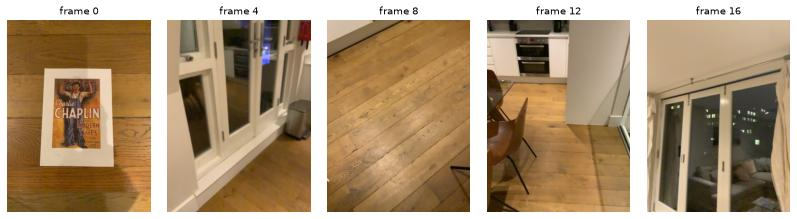

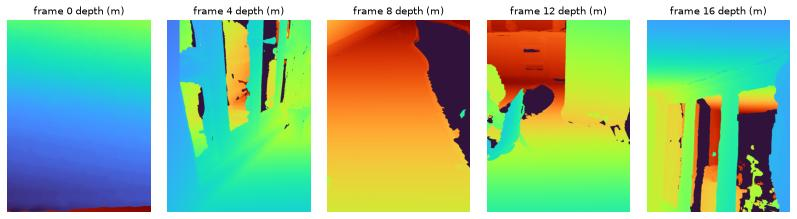

In [2]:
def describe(path: Path) -> dict:
    files = [p for p in path.glob("*") if p.is_file()] if path.is_dir() else [path]  # asset folders are flat
    return {"asset": path.relative_to(SCENE).as_posix(), "files": len(files),
            "size (MB)": round(sum(p.stat().st_size for p in files) / 1e6, 1)}

display(pd.DataFrame([describe(p) for p in sorted(SCENE.iterdir())] +
                     [describe(p) for p in sorted((SCENE / VIDEO).iterdir())]).set_index("asset"))

start = time.perf_counter()
sample = load_sequence(DATA, VISIT, VIDEO, N_FRAMES, TURNS, PIXEL_STEP)
load_seconds = time.perf_counter() - start
frames = sample.frames

display(pd.DataFrame([{
    "frame": f.index, "timestamp (s)": t, "pose gap (ms)": round(gap * 1000, 1),
    "size (H×W)": f"{f.image_hw[0]}×{f.image_hw[1]}",
    "valid depth": f"{(f.depth_m > 0).mean():.0%}",
    "depth range (m)": f"{f.depth_m[f.depth_m > 0].min():.2f} – {f.depth_m.max():.2f}",
} for f, t, gap in zip(frames, sample.timestamps, sample.pose_gaps_s)]).set_index("frame"))

span = float(sample.timestamps[-1]) - float(sample.timestamps[0])
print(f"{sample.n_frames_available} usable frames over {span:.0f} s; loaded {len(frames)} "
      f"(one every ~{span / (len(frames) - 1):.1f} s); raw {sample.raw_hw} -> processed {frames[0].image_hw}; "
      f"load {load_seconds:.1f} s ({load_seconds / len(frames) * 1000:.0f} ms/frame incl. full-res decode)")

shown = frames[:: max(1, len(frames) // 5)][:5]
fig, _ = image_row([f.rgb for f in shown], [f"frame {f.index}" for f in shown])
fig.savefig(OUT / "step1_rgb.jpg", dpi=72)
fig, _ = image_row([f.depth_m for f in shown], [f"frame {f.index} depth (m)" for f in shown], cmap="turbo")
fig.savefig(OUT / "step1_depth.jpg", dpi=72)
plt.show()

### Step 2 · 图像朝向核查

ARKitScenes 元数据说这段视频 `sky_direction = Left`，但那是针对横屏的低分辨率帧。SceneFun3D 的 hires 帧以 1440×1920 **竖屏**存储（见内参文件），朝向可能已经不同。所以转正所需的旋转量**由位姿决定**：计算世界 +z（Faro 坐标系 z 轴朝上，已由地面所在的水平层确认）在图像中的方向，0° 表示图像正上方；多帧投票。

如果旋转量对，处理后所有帧都应接近 0°。对照：如果照元数据旋转，会偏 90°。图像、深度、内参和位姿始终**一起**旋转（单元测试保证旋转前后反投影的世界点完全相同）。

,used (from poses),if following metadata
mean,0.065,90.065
min,-7.300,82.700
max,10.100,100.100


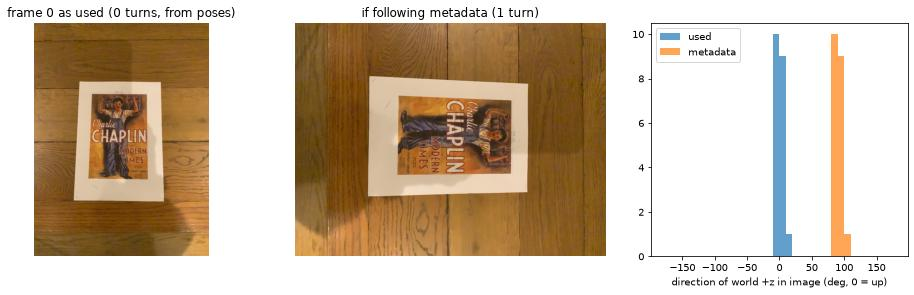

upright check: PASS


In [3]:
metadata_frames = [rotate_frame_cw(f, (TURNS_METADATA - TURNS) % 4) for f in frames]  # what the metadata would give
angles = pd.DataFrame({"used (from poses)": [sky_angle_deg(f.cam_to_world) for f in frames],
                       "if following metadata": [sky_angle_deg(f.cam_to_world) for f in metadata_frames]}).round(1)
display(angles.describe().loc[["mean", "min", "max"]])
upright_ok = bool(angles["used (from poses)"].abs().max() < THRESHOLDS["upright_max_abs_angle_deg"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 4, 3]})
axes[0].imshow(frames[0].rgb); axes[0].set_title(f"frame 0 as used ({TURNS} turns, from poses)")
axes[1].imshow(metadata_frames[0].rgb); axes[1].set_title(f"if following metadata ({TURNS_METADATA} turn)")
for axis in axes[:2]:
    axis.set_axis_off()
axes[2].hist(angles["used (from poses)"], bins=36, range=(-180, 180), alpha=0.7, label="used")
axes[2].hist(angles["if following metadata"], bins=36, range=(-180, 180), alpha=0.7, label="metadata")
axes[2].set_xlabel("direction of world +z in image (deg, 0 = up)"); axes[2].legend()
fig.tight_layout(); fig.savefig(OUT / "step2_orientation.jpg", dpi=72)
plt.show()
print("upright check:", "PASS" if upright_ok else "FAIL")

### Step 3 · RGB / 深度 / 功能区域对照（ORACLE）

把激光扫描上的人工功能标注点投影到图像里，只画出通过深度遮挡测试的点。**这里用了 GT，只用于判断几何是否对齐**：如果坐标系、位姿或旋转有问题，标注会偏离把手、旋钮、开关等部件。这一步需要人工看图确认。

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


laser scan: 8,880,684 points (7,921,109 after crop); 38 functional elements


,elements
rotate,11
plug_in,7
hook_turn,5
tip_push,5
hook_pull,4
key_press,2
pinch_pull,2
unplug,1
foot_push,1


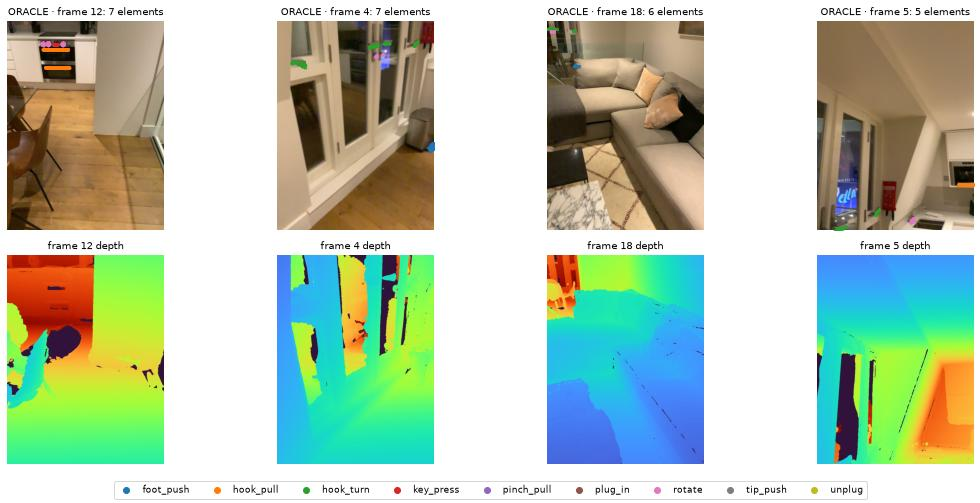

In [4]:
scan_xyz, scan_rgb = read_laser_scan(SCENE / f"{VISIT}_laser_scan.ply")
crop = np.load(SCENE / f"{VISIT}_crop_mask.npy").astype(bool)
elements = read_annotations(SCENE / f"{VISIT}_annotations.json")
labels = sorted({e.label for e in elements})
palette = plt.get_cmap("tab10")
LABEL_COLOURS = {label: palette(i) for i, label in enumerate(labels)}
print(f"laser scan: {len(scan_xyz):,} points ({crop.sum():,} after crop); {len(elements)} functional elements")
display(pd.Series([e.label for e in elements]).value_counts().rename("elements").to_frame())

def overlay_elements(axis, frame) -> int:
    drawn = 0
    for element in elements:
        points = scan_xyz[element.indices]
        visible = visible_mask(points, frame, DEPTH_TOL_M)
        if visible.sum() < MIN_VISIBLE_POINTS:
            continue
        uv, _, _ = project(points[visible], frame)
        axis.scatter(uv[:, 0], uv[:, 1], s=1, color=LABEL_COLOURS[element.label], alpha=0.6)
        drawn += 1
    return drawn

counts_per_frame = [sum(visible_mask(scan_xyz[e.indices], f, DEPTH_TOL_M).sum() >= MIN_VISIBLE_POINTS
                        for e in elements) for f in frames]
picked = [frames[i] for i in np.argsort(counts_per_frame)[::-1][:4]]  # frames showing the most elements
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for column, frame in enumerate(picked):
    axes[0, column].imshow(frame.rgb)
    n = overlay_elements(axes[0, column], frame)
    axes[0, column].set_title(f"ORACLE · frame {frame.index}: {n} elements", fontsize=10)
    axes[1, column].imshow(frame.depth_m, cmap="turbo")
    axes[1, column].set_title(f"frame {frame.index} depth", fontsize=10)
for axis in axes.flat:
    axis.set_axis_off()
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in LABEL_COLOURS.items()]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(OUT / "step3_oracle_overlay.jpg", dpi=72)
plt.show()

### Step 4 · 深度与激光扫描是否落在同一坐标系

把每帧深度（每 8 个像素取 1）反投影到世界坐标，计算到最近激光扫描点的距离。它检查**深度单位（毫米→米）和位姿是否在 Faro 坐标系**：单位错 1000 倍或坐标系不对，距离会是米级。

注意：SceneFun3D 的高分辨率深度本身就是用这些位姿从 Faro mesh 渲染的，所以这一项接近“自洽检查”；真正独立的对齐检查是 Step 5。

In [5]:
scan_crop = scan_xyz[crop]
lifted = [backproject(f, stride=LIFT_STRIDE)[0] for f in frames]
start = time.perf_counter()
distances = nearest_distances(np.concatenate(lifted), scan_crop)
kd_seconds = time.perf_counter() - start
per_frame = np.split(distances, np.cumsum([len(p) for p in lifted])[:-1])

depth_scan = pd.DataFrame([{
    "frame": f.index, "points": len(d), "median (mm)": round(np.median(d) * 1000, 1),
    "p90 (mm)": round(np.percentile(d, 90) * 1000, 1), "share < 1 cm": f"{np.mean(d < 0.01):.0%}",
} for f, d in zip(frames, per_frame)]).set_index("frame")
display(depth_scan.T)
depth_scan_median = float(np.median(distances))
depth_ok = depth_scan_median < THRESHOLDS["depth_to_scan_median_m"]
print(f"all frames: median {depth_scan_median * 1000:.1f} mm, p90 {np.percentile(distances, 90) * 1000:.1f} mm "
      f"({len(distances):,} points, KD-tree query {kd_seconds:.1f} s) ->", "PASS" if depth_ok else "FAIL")

heights, edges = np.histogram(scan_crop[:, 2], bins=200)
floor_z = float(edges[np.argmax(heights)])  # densest horizontal slab = floor
below_cut = np.flatnonzero(scan_crop[:, 2] < floor_z + DISPLAY_CUT_M)
scan_keep = below_cut[subsample(len(below_cut), 60_000)]  # display only: ceiling hidden so rooms are visible
print(f"floor at z = {floor_z:.2f} m; 3D views hide scan points more than {DISPLAY_CUT_M} m above the floor")
all_lifted = np.concatenate(lifted)
fig = scene_figure(
    [points_trace(scan_crop[scan_keep], scan_rgb[crop][scan_keep], name="laser scan (cropped)", size=1.2, max_points=60_000),
     points_trace(all_lifted, values=np.minimum(distances, 0.05) * 1000, name="depth points: distance to scan (mm)",
                  colorscale="Turbo", cmin=0, cmax=50, size=1.5, visible="legendonly"),
     *[frustum_trace(f, "black", depth=0.2) for f in frames]],
    "Step 4 · laser scan + cameras (click legend: depth points coloured by distance to scan)", height=620, view=Z_UP_VIEW)
save_html(fig, OUT / "step4_scan_and_cameras.html")
fig

frame,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
points,10800,10800,10157,9272,10286,10078,10733,10751,9076,10767,9784,10756,10377,8765,10556,10744,9267,10283,10769,10594
median (mm),2.8,2.2,2.2,2.5,2.5,2.2,2.3,2.2,2.1,2.2,2.5,2.7,2.7,2.4,2.5,2.2,2.3,2.4,2.3,2.1
p90 (mm),3.5,3.4,3.6,6.0,17.5,12.5,4.1,3.9,3.1,4.5,21.4,12.4,7.0,3.7,6.8,3.4,16.2,23.1,14.7,3.6
share < 1 cm,100%,95%,97%,93%,86%,89%,94%,94%,96%,93%,81%,89%,92%,96%,91%,96%,86%,84%,88%,92%


all frames: median 2.4 mm, p90 6.3 mm (204,615 points, KD-tree query 4.9 s) -> PASS
floor at z = 299.87 m; 3D views hide scan points more than 1.6 m above the floor


### Step 5 · 跨帧对应的像素误差（E0 核心，独立于标注）

做法：给每个抽样帧（源帧，有深度）配一个 0.3–2 s 之后的“搭档帧”（只需要 RGB 和位姿），保证两帧有足够重叠。

1. 用 SIFT 在两帧之间做特征匹配，**只用图像**；
2. 用 RANSAC 基础矩阵剔除几何上不可能的错配。这一步也只用图像，**不使用我们的位姿或深度**，所以不会让结果偏向位姿；
3. 用源帧的深度和位姿预测每个匹配点在搭档帧中的位置，与实际匹配位置比较。

RGB、深度、内参、位姿、旋转、时间戳配对中任何一项出错，误差都会变大；“平均偏移”接近 (0, 0) 说明没有整体平移或错位。对照组：给搭档帧故意换成源帧的位姿。少于 20 个已验证匹配的帧对不计入汇总（匹配太少时 RANSAC 也可能被错配骗过），但仍列在表中。

,source t,partner t,Δt (s),SIFT matches,epipolar-verified,with depth,median (px),p90 (px),share < 3 px,"mean offset (u, v)",control median (px)
frame,,,,,,,,,,,
0,1231.487,1231.870,0.38,495.0,446.0,446.0,3.09,4.7,47%,"(-0.4, +2.9)",20.6
1,1236.868,1237.268,0.40,78.0,58.0,58.0,2.03,3.0,88%,"(-0.2, -1.7)",213.0
2,1243.482,1243.882,0.40,219.0,145.0,145.0,5.14,12.5,8%,"(-1.5, +0.4)",151.6
3,1249.679,1250.079,0.40,47.0,25.0,22.0,4.26,14.4,32%,"(-1.5, +1.7)",155.2
4,1257.376,1257.776,0.40,73.0,43.0,43.0,2.23,10.9,67%,"(+0.8, +10.5)",156.4
5,1262.674,1263.074,0.40,72.0,45.0,36.0,1.57,2.6,92%,"(+1.0, +0.3)",141.0
6,1268.072,1268.372,0.30,57.0,26.0,21.0,5.72,8.2,33%,"(-3.2, +13.5)",183.3
7,1273.470,1273.869,0.40,89.0,51.0,50.0,2.15,5.1,70%,"(+0.8, -1.0)",215.5
8,1280.567,1280.967,0.40,86.0,67.0,64.0,1.18,1.8,97%,"(-2.1, -5.5)",163.5


18/20 pairs with >= 20 verified matches; median of pair medians 1.88 px (worst 5.72) vs control 146.3 px (2.5 s) -> PASS


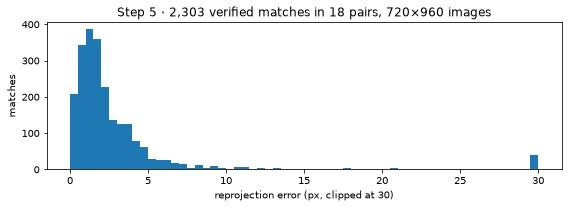

In [6]:
index = index_sequence(DATA, VISIT, VIDEO)
partner_times = pick_partners(sample.timestamps, index.rgb_times, PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S)

pair_rows, pair_results = [], []
start = time.perf_counter()
for src, src_t, partner_t in zip(frames, sample.timestamps, partner_times):
    if partner_t is None:
        pair_rows.append({"frame": src.index, "source t": src_t, "partner t": "-"})
        continue
    (dst,) = load_frames(index, [partner_t], TURNS, PIXEL_STEP, first_position=src.index)
    uv_a, uv_b = match_features(sift_features(src.rgb), sift_features(dst.rgb))
    verified = epipolar_inliers(uv_a, uv_b, EPIPOLAR_PX)
    result = reproject_matches(src, dst, uv_a[verified], uv_b[verified])
    control = reproject_matches(src, replace(dst, cam_to_world=src.cam_to_world), uv_a[verified], uv_b[verified])
    errors = result.errors_px
    pair_results.append((src, dst, result, src_t, partner_t))
    offset = np.mean(result.predicted_uv - result.dst_uv, axis=0) if len(errors) else (np.nan, np.nan)
    pair_rows.append({
        "frame": src.index, "source t": src_t, "partner t": partner_t,
        "Δt (s)": round(float(partner_t) - float(src_t), 2), "SIFT matches": len(uv_a),
        "epipolar-verified": int(verified.sum()), "with depth": len(errors),
        "median (px)": round(float(np.median(errors)), 2) if len(errors) else np.nan,
        "p90 (px)": round(float(np.percentile(errors, 90)), 1) if len(errors) else np.nan,
        "share < 3 px": f"{np.mean(errors < 3):.0%}" if len(errors) else "-",
        "mean offset (u, v)": f"({offset[0]:+.1f}, {offset[1]:+.1f})",
        "control median (px)": round(float(np.median(control.errors_px)), 1) if len(control.errors_px) else np.nan,
    })
sift_seconds = time.perf_counter() - start
pairs = pd.DataFrame(pair_rows).set_index("frame")
display(pairs)

usable = pairs[pairs["with depth"] >= THRESHOLDS["sift_min_matches"]]
sift_median = float(usable["median (px)"].median())
control_median = float(usable["control median (px)"].median())
sift_ok = sift_median < THRESHOLDS["sift_median_px"] and control_median > THRESHOLDS["control_ratio"] * sift_median
print(f"{len(usable)}/{len(pairs)} pairs with >= {THRESHOLDS['sift_min_matches']} verified matches; median of pair medians "
      f"{sift_median:.2f} px (worst {usable['median (px)'].max():.2f}) vs control {control_median:.1f} px "
      f"({sift_seconds:.1f} s) ->", "PASS" if sift_ok else "FAIL")

counted = [r for r in pair_results if len(r[2].errors_px) >= THRESHOLDS["sift_min_matches"]]
all_errors = np.concatenate([r[2].errors_px for r in counted]) if counted else np.empty(0)
fig, axis = plt.subplots(figsize=(8, 3))
axis.hist(np.clip(all_errors, 0, 30), bins=60, range=(0, 30))
axis.set_xlabel("reprojection error (px, clipped at 30)"); axis.set_ylabel("matches")
axis.set_title(f"Step 5 · {len(all_errors):,} verified matches in {len(counted)} pairs, "
               f"{frames[0].image_hw[1]}×{frames[0].image_hw[0]} images")
fig.tight_layout(); fig.savefig(OUT / "step5_error_hist.jpg", dpi=72)
plt.show()

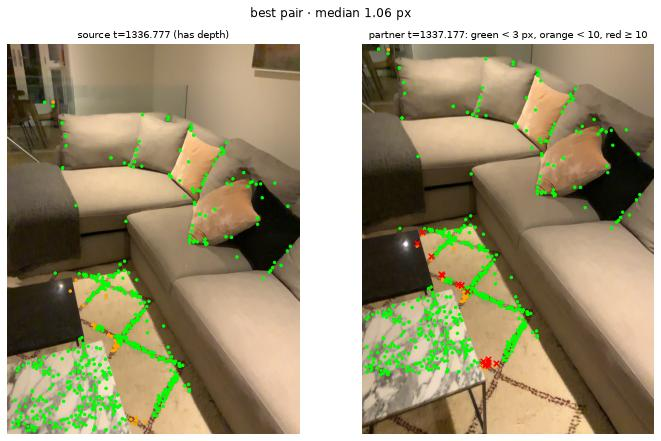

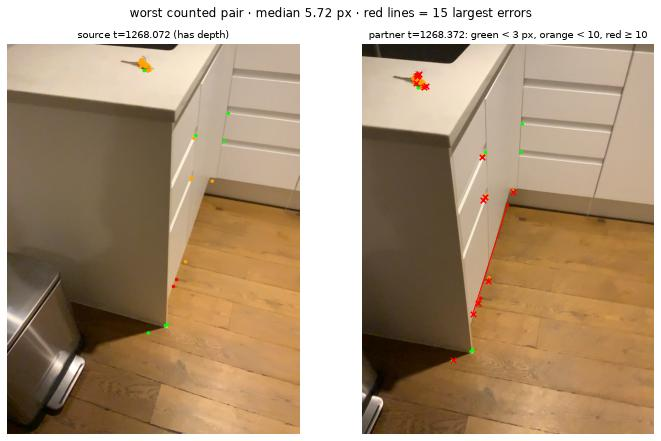

In [7]:
def show_pair(src, dst, result, src_t: str, dst_t: str, title: str) -> plt.Figure:
    errors = result.errors_px
    colours = np.where(errors < 3, "lime", np.where(errors < 10, "orange", "red"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 6.2))
    axes[0].imshow(src.rgb); axes[0].scatter(*result.src_uv.T, s=6, c=colours)
    axes[1].imshow(dst.rgb); axes[1].scatter(*result.dst_uv.T, s=6, c=colours)
    for i in np.argsort(errors)[::-1][:15]:  # mismatch examples: observed (dot) -> predicted (cross)
        axes[1].plot(*np.stack([result.dst_uv[i], result.predicted_uv[i]]).T, color="red", lw=1)
        axes[1].scatter(*result.predicted_uv[i], marker="x", c="red", s=30)
    axes[0].set_title(f"source t={src_t} (has depth)", fontsize=10)
    axes[1].set_title(f"partner t={dst_t}: green < 3 px, orange < 10, red ≥ 10", fontsize=10)
    for axis in axes:
        axis.set_axis_off()
    fig.suptitle(title); fig.tight_layout()
    return fig

ranked = sorted(counted, key=lambda r: np.median(r[2].errors_px))
if ranked:
    best, worst = ranked[0], ranked[-1]
    show_pair(*best, f"best pair · median {np.median(best[2].errors_px):.2f} px").savefig(OUT / "step5_best_pair.jpg", dpi=72)
    show_pair(*worst, f"worst counted pair · median {np.median(worst[2].errors_px):.2f} px · red lines = 15 largest errors"
              ).savefig(OUT / "step5_worst_pair.jpg", dpi=72)
    plt.show()

### Step 6 · 功能部件被观察到的情况（为 E1 做准备，ORACLE）

统计每个功能部件在哪些帧中可见（至少 10 个标注点通过深度遮挡测试）。E1 需要“历史中看到过、当前看不到”的部件，以及在多帧中可见的部件做跨视角检查。

,elements,median_points,seen_in_any,seen_in_2_plus
label,,,,
foot_push,1,1325.0,1,1
hook_pull,4,882.0,4,1
hook_turn,5,171.0,4,3
key_press,2,386.5,2,0
pinch_pull,2,20.0,0,0
plug_in,7,105.0,5,1
rotate,11,67.0,7,4
tip_push,5,30.0,2,0
unplug,1,158.0,1,0


26/38 elements seen in at least one of 20 frames; 10 in two or more


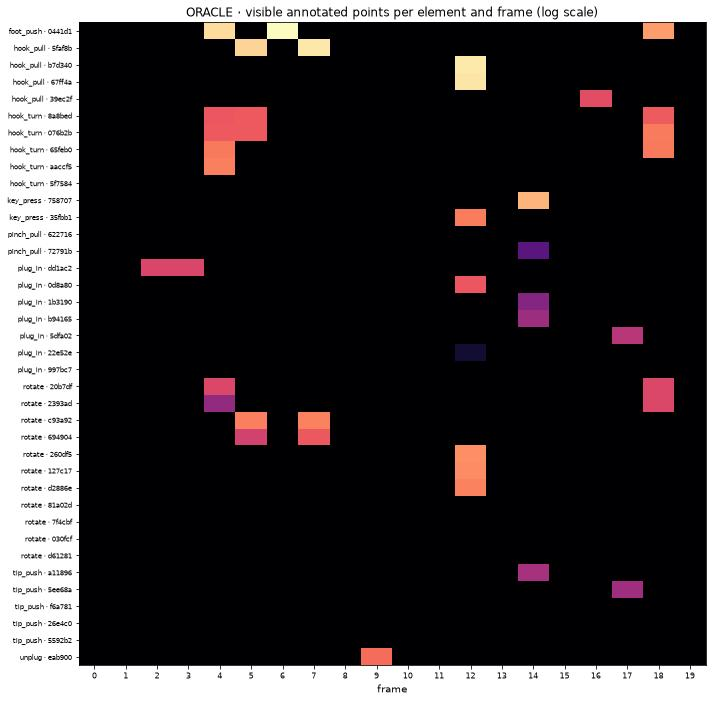

In [8]:
element_points = [scan_xyz[e.indices] for e in elements]
counts = visible_point_counts(element_points, frames, DEPTH_TOL_M)
seen = counts >= MIN_VISIBLE_POINTS
frames_per_element = seen.sum(axis=1)

summary = pd.DataFrame({"label": [e.label for e in elements], "points": [len(e.indices) for e in elements],
                        "frames seen": frames_per_element})
display(summary.groupby("label").agg(elements=("points", "size"), median_points=("points", "median"),
                                     seen_in_any=("frames seen", lambda s: int((s >= 1).sum())),
                                     seen_in_2_plus=("frames seen", lambda s: int((s >= 2).sum()))))
print(f"{int((frames_per_element >= 1).sum())}/{len(elements)} elements seen in at least one of {len(frames)} frames; "
      f"{int((frames_per_element >= 2).sum())} in two or more")

order = np.lexsort((-frames_per_element, [e.label for e in elements]))
fig, axis = plt.subplots(figsize=(10, 0.22 * len(elements) + 1.5))
axis.imshow(np.log1p(counts[order]), aspect="auto", cmap="magma")
axis.set_yticks(range(len(elements)), [f"{elements[i].label} · {elements[i].annot_id[:6]}" for i in order], fontsize=7)
axis.set_xticks(range(len(frames)), [f.index for f in frames], fontsize=8)
axis.set_xlabel("frame"); axis.set_title("ORACLE · visible annotated points per element and frame (log scale)")
fig.tight_layout(); fig.savefig(OUT / "step6_visibility.jpg", dpi=72)
plt.show()

#### 6b · 同一部件的多个观察（ORACLE，人工核对）

对在两帧以上可见的部件，并排放大显示它在不同帧中的位置（叠加的点是激光扫描上的人工标注，经深度遮挡测试后投影到图像）。**如果坐标、位姿和朝向都对，同一部件在每个视角下都应落在同一个把手、旋钮或开关上。**

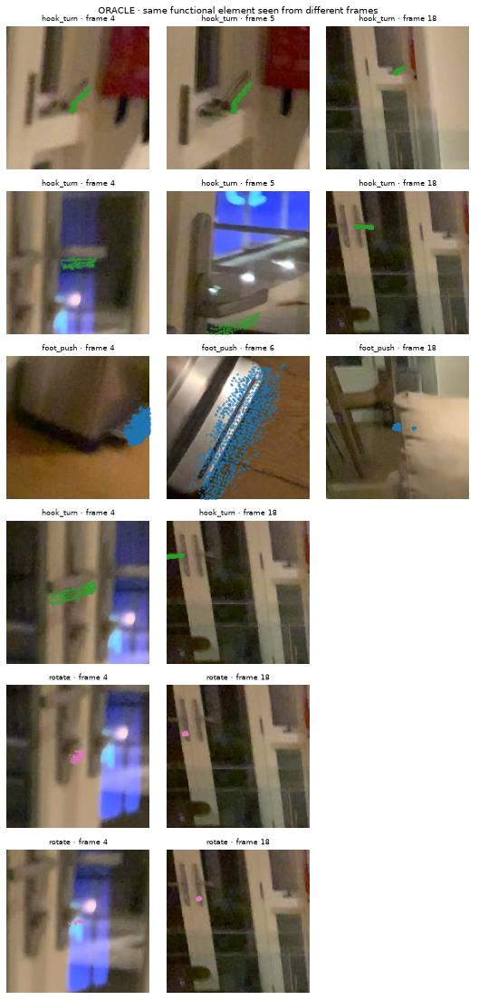

In [9]:
CROP_HALF = 70  # px at the processed resolution

def element_crop(frame, points: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    visible = visible_mask(points, frame, DEPTH_TOL_M)
    uv, _, _ = project(points[visible], frame)
    height, width = frame.image_hw
    centre_u, centre_v = np.median(uv, axis=0).round().astype(int)
    u0 = int(np.clip(centre_u - CROP_HALF, 0, width - 2 * CROP_HALF))
    v0 = int(np.clip(centre_v - CROP_HALF, 0, height - 2 * CROP_HALF))
    return frame.rgb[v0:v0 + 2 * CROP_HALF, u0:u0 + 2 * CROP_HALF], uv - [u0, v0]

multi_view = [i for i in np.argsort(-frames_per_element, kind="stable") if frames_per_element[i] >= 2][:6]
fig, axes = plt.subplots(max(1, len(multi_view)), 3, figsize=(7.5, 2.6 * max(1, len(multi_view))), squeeze=False)
for row, i in enumerate(multi_view):
    views = [frames[k] for k in np.flatnonzero(seen[i])][:3]
    for col in range(3):
        axis = axes[row, col]
        axis.set_axis_off()
        if col < len(views):
            crop, uv = element_crop(views[col], element_points[i])
            axis.imshow(crop)
            axis.scatter(uv[:, 0], uv[:, 1], s=3, color=LABEL_COLOURS[elements[i].label], alpha=0.5)
            axis.set_xlim(0, crop.shape[1]); axis.set_ylim(crop.shape[0], 0)  # long parts must not rescale the crop
            axis.set_title(f"{elements[i].label} · frame {views[col].index}", fontsize=8)
fig.suptitle("ORACLE · same functional element seen from different frames", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "step6b_multiview_crops.jpg", dpi=90)
plt.show()

In [10]:
traces = [points_trace(scan_crop[scan_keep], "lightgrey", name="laser scan", size=1, max_points=60_000)]
for label in labels:
    pts = np.concatenate([scan_xyz[e.indices] for e in elements if e.label == label])
    r, g, b, _ = LABEL_COLOURS[label]
    traces.append(points_trace(pts, f"rgb({int(r * 255)},{int(g * 255)},{int(b * 255)})", name=label, size=2.5))
traces += [frustum_trace(f, "black", depth=0.2) for f in frames]
fig = scene_figure(traces, "Step 6 · ORACLE functional elements by type + sampled cameras", height=620, view=Z_UP_VIEW)
save_html(fig, OUT / "step6_elements.html")
fig

### Step 7 · 资源与 E0 结论

In [11]:
frame_mb = sum(f.rgb.nbytes + f.depth_m.nbytes for f in frames) / 2**20
resources = {
    "frame load (full-res decode + subsample + rotate)": f"{load_seconds / len(frames) * 1000:.0f} ms/frame",
    "frames in memory": f"{frame_mb:.0f} MB for {len(frames)} frames at {frames[0].image_hw[0]}×{frames[0].image_hw[1]}",
    "laser scan": f"{len(scan_xyz):,} points",
    "depth → scan KD-tree check": f"{kd_seconds:.1f} s",
    "SIFT + reprojection": f"{sift_seconds / max(1, len(pairs)):.2f} s/pair",
    "scene data on disk": f"{sum(p.stat().st_size for p in SCENE.rglob('*') if p.is_file()) / 1e9:.2f} GB",
}
display(pd.Series(resources, name="value").to_frame())

checks = pd.DataFrame([
    {"check": "images upright (rotation from poses)", "result": "PASS" if upright_ok else "FAIL",
     "evidence": f"max |angle| {angles['used (from poses)'].abs().max():.1f}° (gate {THRESHOLDS['upright_max_abs_angle_deg']}°); "
                 f"metadata '{SKY_METADATA}' would be off by ~{abs(angles['if following metadata'].median()):.0f}°"},
    {"check": "depth units + Faro frame", "result": "PASS" if depth_ok else "FAIL",
     "evidence": f"median distance to scan {depth_scan_median * 1000:.1f} mm (gate {THRESHOLDS['depth_to_scan_median_m'] * 1000:.0f} mm)"},
    {"check": "cross-frame alignment (SIFT)", "result": "PASS" if sift_ok else "FAIL",
     "evidence": f"{sift_median:.2f} px vs wrong-pose control {control_median:.1f} px (gate {THRESHOLDS['sift_median_px']} px)"},
    {"check": "annotations on the right parts", "result": "VISUAL", "evidence": "inspect Step 3 (ORACLE overlay)"},
]).set_index("check")
display(checks)

manifest = {
    "experiment": "E0 SceneFun3D data and projection check",
    "data": {"dataset": "SceneFun3D v1 (train)", "visit_id": VISIT, "video_id": VIDEO,
             "sky_direction_metadata": SKY_METADATA, "cw_turns_from_poses": TURNS,
             "assets": sorted(p.relative_to(SCENE).as_posix() for p in SCENE.iterdir()) + sorted(p.name for p in (SCENE / VIDEO).iterdir()),
             "timestamps": sample.timestamps, "n_frames_available": sample.n_frames_available,
             "raw_hw": list(sample.raw_hw), "processed_hw": list(frames[0].image_hw)},
    "config": {"n_frames": N_FRAMES, "pixel_step": PIXEL_STEP, "depth_tol_m": DEPTH_TOL_M, "lift_stride": LIFT_STRIDE,
               "min_visible_points": MIN_VISIBLE_POINTS, "partner_gap_s": [PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S],
               "epipolar_px": EPIPOLAR_PX, "thresholds": THRESHOLDS},
    "gt_usage": "functional annotations used only for ORACLE overlays/visibility (Steps 3, 6); no model or memory input",
    "results": {"upright": upright_ok, "depth_to_scan_median_m": depth_scan_median, "sift_median_px": sift_median,
                "sift_control_median_px": control_median, "sift_pairs_counted": len(usable),
                "pairs": pairs.reset_index().to_dict(orient="records"),
                "elements_seen_any": int((frames_per_element >= 1).sum()),
                "elements_seen_2plus": int((frames_per_element >= 2).sum()), "n_elements": len(elements)},
    "resources": resources,
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=float))
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

,value
frame load (full-res decode + subsample + rotate),50 ms/frame
frames in memory,92 MB for 20 frames at 960×720
laser scan,"8,880,684 points"
depth → scan KD-tree check,4.9 s
SIFT + reprojection,0.12 s/pair
scene data on disk,0.92 GB


,result,evidence
check,,
images upright (rotation from poses),PASS,max |angle| 10.1° (gate 30.0°); metadata 'Left...
depth units + Faro frame,PASS,median distance to scan 2.4 mm (gate 10 mm)
cross-frame alignment (SIFT),PASS,1.88 px vs wrong-pose control 146.3 px (gate 3...
annotations on the right parts,VISUAL,inspect Step 3 (ORACLE overlay)


saved:
  manifest.json
  plotly.min.js
  step1_depth.jpg
  step1_rgb.jpg
  step2_orientation.jpg
  step3_oracle_overlay.jpg
  step4_scan_and_cameras.html
  step5_best_pair.jpg
  step5_error_hist.jpg
  step5_worst_pair.jpg
  step6_elements.html
  step6_visibility.jpg
  step6b_multiview_crops.jpg


#### 读结果的方式

- 三项自动检查都 PASS，且 Step 3 的 ORACLE 标注确实落在对应部件上 → **E0 工程链路可用**，可以把帧数扩到 40–80 帧（改 `N_FRAMES` 后 Run All），再进入 E1。
- 任何一项 FAIL → 先修数据和坐标，不启动模型或记忆实验（计划 §3 的继续条件）。
- 即使全部通过，也只说明投影链路可用；不说明任何特征或方法有效。

#### 本次运行记录（2026-11-06，完整数据 1025 帧中均匀取 20 帧，720×960）

以下数字和观察针对这次执行；改动帧数或参数后应重新核对。同日先在部分下载的数据（28 帧）上跑过一次，结论一致。

- **朝向：** ARKitScenes 元数据为 `Left`，但 hires 帧以竖屏存储时已经是正的；由位姿判断需要旋转 0 次。照元数据旋转会让所有帧偏 90°。**今后读取 SceneFun3D hires 帧应以位姿为准，不能直接使用 `sky_direction`。**
- **深度与扫描：** 到激光扫描的中位距离 2.4 mm（p90 6.3 mm），单位与 Faro 坐标系一致。
- **跨帧对齐：** 18/20 个帧对有足够的已验证匹配（最后一帧没有搭档帧，另一对只有 18 个匹配），误差中位数为 1.88 px（最差 5.72 px），错误位姿对照为 146 px。误差较大的帧对多数没有整体偏移，误差分散在各个方向。
- **误差来源（未证实）：** 细长物体（灯杆、电线）和靠垫上的误差明显更大，可能因为 5 mm 网格表达不了细物体，或者可移动物体在扫描和拍摄之间位置变了（渲染深度来自扫描时刻的几何）。最差的三对图像偏模糊、相机转得较快（约 30°/s），但在 18 对中与误差的相关性很弱（Spearman 约 0.2），不能确定是运动模糊。
- **一个方法修正：** 第一版只比较相邻抽样帧、不剔除错配，结果被大量 SIFT 错误匹配污染（预测位置落在图外）。改为“搭档帧 + 仅基于图像的对极检验”后，门槛（3 px）不变。
- **ORACLE 标注：** 水龙头阀门、烤箱门把手、门把手在不同视角下都落在同一实物上；foot_push 在远处视角下点很少，需人工复核。
- **对 E1 的提示：** 20 帧中 38 个部件有 26 个可见，10 个在两帧以上可见；部件中位数只有 106 个标注点（几厘米大小）。E1 需要扩到 40–80 帧，并重点检查小部件是否小于 DINOv2 的 patch 分辨率。

<a id="w1-memdemo"></a>

# 第 5 部分 · 记忆 pipeline 的演示

<sub>原文件 `report/2026-11-10_mem_pipeline_demo.ipynb`（11-10）· 生成方式：`notebooks/builders/build_mem_demo.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## mem pipeline demo: from a walkthrough video to a humanoid acting on a part
**mem branch** · one real scene (SceneFun3D 421069, video 42444490) · 10 Nov 2026 · a walk-through for discussion, before any training

- **What it shows:** every step of the planned pipeline on one scene, running the same code the experiments will use.
- **Real today:** the inputs (RGB, simple depth, device poses), the memory entries computed from them, the humanoid placement, and every score.
- **Placeholder today (marked ORACLE):** where a part is in the image, its action type, how it moves, and which part a query means. These come from SceneFun3D annotations now; training replaces them later.

```text
(1) video frames + simple depth + device pose                       inputs only, no reconstruction
        ↓
(2) per-frame part masks, action type, part motion                  ORACLE labels now → predicted after training
        ↓
(3) memory: one entry per functional part
    contact point · surface normal · motion · stand point · evidence keyframes
        ↓
(4) query in words → entry + evidence keyframe                      ORACLE match now → feature search later
        ↓
(5) humanoid walks up, faces the part, reaches, acts                 kinematic, SMPL-X
        ↓
(6) scores against the laser scan                                   ground truth, never an input
```

<sub>To re-run: download the scene (`python scripts/download_scenefun3d.py --visit 421069 --video 42444490`, then the same command with `--assets lowres_depth lowres_wide_intrinsics confidence lowres_poses transform motions`), put the SMPL-X model in `data/body_models/smplx/` (registration at smpl-x.is.tue.mpg.de, non-commercial licence, not redistributed here), then Run All. The monocular depth model downloads on first use (1.3 GB).</sub>

In [1]:
import contextlib
import io
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.io as pio
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.mem import pipeline as P
from affordance3d.mem.body import load_smplx
from report.mem_demo_helpers import (entries_figure, entries_table, humanoid_figure, inputs_figure, labels_figure,
                                     make_shots, memory_3d_figure, pick_keyframes, render_approach_video,
                                     retrieval_figure, scaled_mono_depths, scan_view, scoreboard, shots_table)

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
ASSETS = ROOT / "report" / "assets"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
MONO_CACHE = ROOT / "runs" / "mem_s1" / "mono" / "DA-V2_L"
N_KEYFRAMES = 40

### 1 · Inputs: what the memory is allowed to see
> **This step:** pick keyframes evenly in time and give each one a depth map and a camera pose from the device.
> **Status:** real. The laser scan, the depth rendered from it and the scan-registered poses are kept apart as ground truth.

The video is an iPad walkthrough (10 FPS RGB). Depth is a monocular estimate rescaled per frame by the iPad's own LiDAR; the pose is ARKit's. No mesh, no global fusion: 3D only ever comes from one frame's depth and pose.

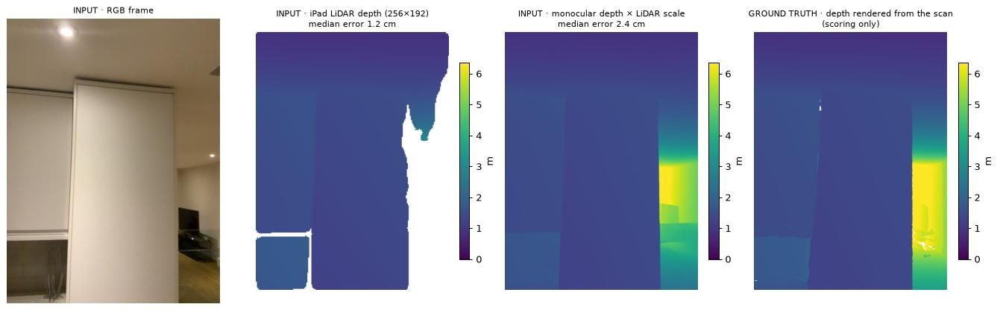

,role,what,detail
0,input,RGB video,1025 frames at 10 FPS; 40 keyframes used
1,input,depth,Depth Anything V2 (monocular) × per-frame LiDA...
2,input,camera pose,"ARKit, from the device"
3,ground truth,laser scan + annotations,"38 functional parts, 37 with a motion, 24 task..."
4,ground truth,"rendered depth, scan-registered poses","used to make labels and to score, never fed to..."


In [2]:
scene = P.load_scene(DATA, VISIT, VIDEO)
keyframes = pick_keyframes(scene, N_KEYFRAMES)
mono = scaled_mono_depths(scene, keyframes, MONO_ID, MONO_CACHE)
gt = P.gt_frames(scene, keyframes)  # ground-truth cameras: labels and scoring only
frames = [P.input_frame(scene, t, d) for t, d in zip(keyframes, mono)]

inputs_figure(scene, keyframes[18], mono[18], gt[18])
plt.show()
pd.DataFrame([
    ("input", "RGB video", f"{len(scene.vid.rgb_times)} frames at 10 FPS; {len(keyframes)} keyframes used"),
    ("input", "depth", "Depth Anything V2 (monocular) × per-frame LiDAR scale; LiDAR alone as a comparison"),
    ("input", "camera pose", "ARKit, from the device"),
    ("ground truth", "laser scan + annotations", f"{len(scene.elements)} functional parts, {len(scene.motions)} with a motion, {len(scene.tasks)} task descriptions"),
    ("ground truth", "rendered depth, scan-registered poses", "used to make labels and to score, never fed to the memory"),
], columns=["role", "what", "detail"])

### 2 · Per-frame labels: part, action type, motion
> **This step:** mark each functional part in the keyframes, with its action type (colour) and how it moves (arrow).
> **Status:** ORACLE. The scan annotations are projected into the frames with the ground-truth camera. After training, a model predicts these three things from the frame; the projections below become its training targets.

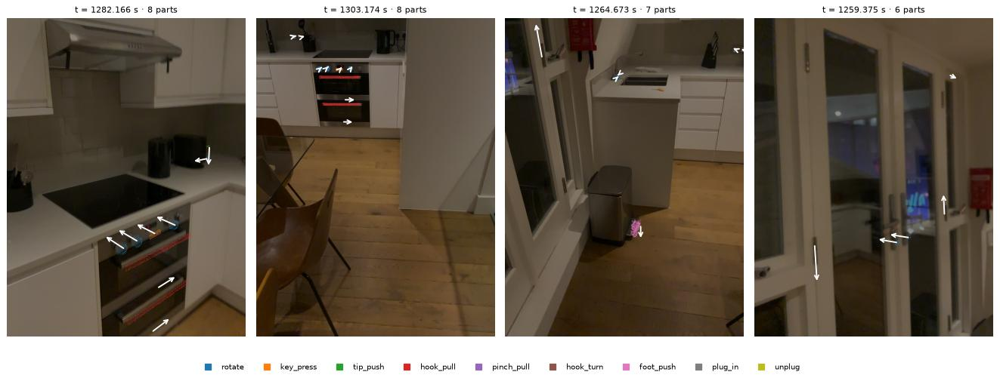

In [3]:
labels = P.label_maps(scene, gt)
labels_figure(scene, gt, labels, keyframes)
plt.show()

### 3 · Memory: one entry per functional part
> **This step:** for each part, take the keyframe where it is largest, lift its contact point with the input depth, fit the surface around it, and plan where a person stands to use it.
> **Status:** geometry is real (inputs only). Which pixels are the part, the action type and the motion are still the labels from step 2.

An entry is what later steps read: **where to touch** (red), **which way the surface faces** (cyan), **how the part moves** (yellow), **where to stand** (ring), and **which keyframes are the evidence**.

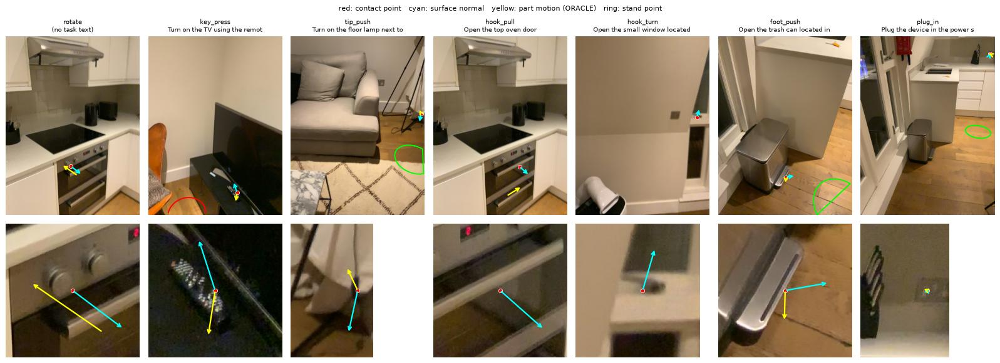

29 of 38 parts have an entry (the others were seen in fewer than 10 pixels)


,action,"task (the effect, from SceneFun3D)",best keyframe,seen in,motion,contact error,stand point
0,foot_push,Open the trash can located in the kitchen near...,1267.272 s,4 keyframes,slides,0.3 cm,free
1,hook_pull,Open the bottom oven door,1282.166 s,3 keyframes,rotates,9.0 cm,free
2,hook_pull,Open the glass door next to the black floor lamp,1326.381 s,1 keyframes,rotates,6.5 cm,free
3,hook_turn,Open the left balcony door located in the kitchen,1259.375 s,2 keyframes,rotates,12.0 cm,free
4,hook_turn,Open the right balcony door located in the kit...,1259.375 s,4 keyframes,rotates,14.5 cm,free
5,key_press,Turn on the TV using the remote control locate...,1321.167 s,4 keyframes,slides,5.4 cm,blocked in scan
6,key_press,–,1282.166 s,3 keyframes,slides,3.8 cm,free
7,plug_in,Plug the device in one of the sockets behind t...,1249.279 s,3 keyframes,slides,4.1 cm,free
8,plug_in,Plug the device in the power supply located ne...,1264.673 s,2 keyframes,slides,11.3 cm,free
9,rotate,Increase the toaster's intensity,1282.166 s,1 keyframes,rotates,42.8 cm,free


In [4]:
memory = P.build_memory(scene, keyframes, frames, labels)
view = scan_view(scene)  # ground-truth scan, for scoring and display
by_time, labels_by_time = dict(zip(keyframes, frames)), dict(zip(keyframes, labels))

entries_figure(scene, memory, by_time, view)
plt.show()
print(f"{len(memory.entries)} of {len(scene.elements)} parts have an entry (the others were seen in fewer than {P.MIN_PART_PIXELS} pixels)")
entries_table(scene, memory, view).groupby("action").head(2).reset_index(drop=True)

#### The memory in 3D (drag to rotate; hover a marker for its task). The scan is only the backdrop.

In [5]:
memory_3d_figure(scene, memory, view)

### 4 · Query → entry → evidence
> **This step:** a task in words returns the part to act on, how to act, and the keyframe that proves it was seen.
> **Status:** ORACLE match. The query must be one of SceneFun3D's task descriptions, and the task → part link is the annotated one. The planned replacement is a feature search over the memory.

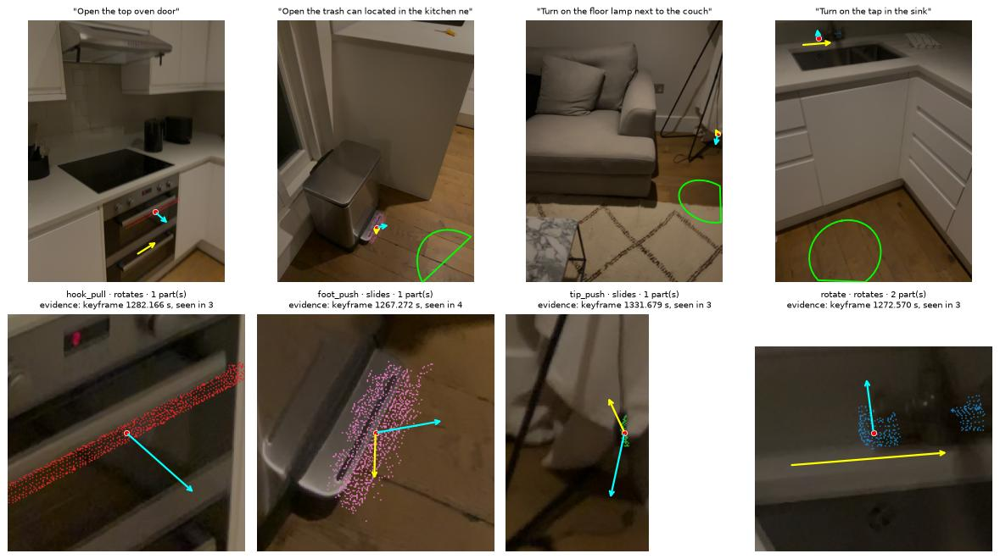

In [6]:
QUERIES = ["Open the top oven door", "Open the trash can located in the kitchen near the sink",
           "Turn on the floor lamp next to the couch", "Turn on the tap in the sink"]
retrieval_figure(scene, memory, QUERIES, by_time, labels_by_time, view)
plt.show()

### 5 · Humanoid: walk up, reach, act
> **This step:** the entry drives an SMPL-X body: stand at the stand point, face the part, squat if it is low, bring the hand (or foot) to the contact point. The display frame is searched over the whole video for the view that shows both the part and the person.
> **Status:** real given the entry. Kinematic only: no physics, no finger motion, a simple walk cycle.

Left: pasted into the real video frame, hidden behind furniture using the input depth. Right: the same body inside the laser scan, where magenta marks the true part.

In [7]:
body = load_smplx(ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz")
shots = make_shots(scene, memory, body, QUERIES, MONO_ID, MONO_CACHE)
CLIP = ASSETS / "mem_approach_demo.mp4"
render_approach_video(scene, memory, body, shots, view, CLIP)
Video(str(CLIP), embed=True, width=960)

#### Final pose of each query (still images of the clip above)

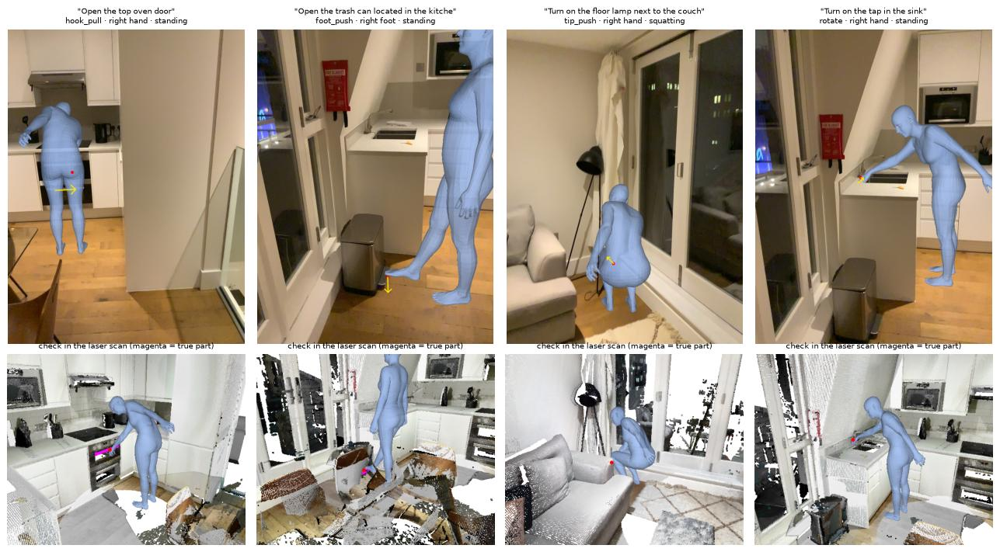

,query,acts with,hand/foot to true part,feet above true floor,body inside scan geometry
0,Open the top oven door,"right hand, standing",1.6 cm,+4.5 cm,0.0%
1,Open the trash can located in the kitchen near...,"right foot, standing",5.9 cm,+5.5 cm,0.0%
2,Turn on the floor lamp next to the couch,"right hand, squatting",8.6 cm,+2.3 cm,0.0%
3,Turn on the tap in the sink,"right hand, standing",6.8 cm,+4.9 cm,0.1%


In [8]:
humanoid_figure(scene, shots, body, view)
plt.show()
shots_table(scene, shots, view)

### 6 · Scores against the laser scan
> **This step:** how close the memory's contact points are to the true parts, and whether the planned stand points are really free.
> **Status:** real, but one scene and one video: these numbers show where the error comes from, they are not results.

In [9]:
lidar_frames = [P.input_frame(scene, t, P.lidar_depth(scene, t)) for t in keyframes]
scoreboard(scene, {"monocular × LiDAR scale (used above)": memory,
                   "iPad LiDAR only": P.build_memory(scene, keyframes, lidar_frames, labels)}, view)

,parts in memory,contact error (median),contact on the part (≤ 3 cm),stand point free in the scan
depth used to build the memory,,,,
monocular × LiDAR scale (used above),29 of 38,7.7 cm,14%,93%
iPad LiDAR only,24 of 38,2.8 cm,54%,75%


**What this run shows**
- With perfect knowledge of *which pixels* are the part, the remaining error is depth and pose: the contact point is off by a median of 7.7 cm with monocular depth and 2.8 cm with LiDAR. Parts are only a few cm wide, so depth at the part is the bottleneck for "position accurate".
- LiDAR is more accurate but has holes: it gives an entry for 24 parts, monocular depth for 29.
- The humanoid lands its hand or foot 2–9 cm from the true part in these four cases, with feet 2–6 cm above the true floor (ARKit height drift).

**What training changes**

| step | today | after training |
|---|---|---|
| 2 · part mask, action type, motion | projected annotations (ORACLE) | predicted per frame from RGB (+ depth) |
| 3 · memory entry | geometry from inputs, labels from step 2 | same geometry, predicted labels; evidence merged over keyframes |
| 4 · query → entry | annotated task → part link (ORACLE) | search over memory features |
| 5 · humanoid | simple walk cycle + IK | generated approach motion (LINGO / DartControl on the A6000 server) |

**To decide together**
1. Depth at small parts: prefer LiDAR near the part, fit the surrounding surface, or make the contact depth a prediction target?
2. The stand-point check treats unobserved space as free; it should only allow space that was observed to be free.
3. Which queries should step 4 support first: SceneFun3D task sentences only, or free text?
4. Is this the right picture for the humanoid (pose, view, level of detail), before investing in generated motion?

<a id="w1-s1-01"></a>

# 第 6 部分 · S1-01 从视频到可执行的 affordance

<sub>原文件 `notebooks/mem/S1_01_video_inputs_to_actionable_affordance.ipynb`（11-10）· 生成方式：`notebooks/builders/build_mem_s1_01.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## S1-01 · 从视频到可执行 affordance（oracle 版）｜SceneFun3D 场景 421069 / 视频 42444490

**这一步回答：** 只用视频、简单深度和设备自带位姿（不重建），能把功能部件放到多准的三维位置上？据此能不能算出"手放在哪、部件怎么动、人站在哪"？

| | 内容 |
|---|---|
| 测试时输入 | hires RGB（1440×1920，10 FPS）、iPad LiDAR 深度或单目深度、ARKit 位姿；**不用**激光扫描、`hires_depth`（由扫描渲染）、`hires_poses`（配准到扫描） |
| 真值用途 | 扫描上的部件和运动轴投影成**训练标签**（Step 3）；评测时用 Faro→ARKit 变换把预测换到扫描坐标系打分；`hires_depth` 只作 oracle 对照 |
| oracle 的含义 | 本 notebook 的部件位置和运动轴来自标签（Step 3），目的是先看清链路和误差来源；S1 第 7 步才换成模型预测 |
| 关键帧 | 按时间均匀取 `N_KEYFRAMES` 帧，不看标签；计算分辨率 720×960（每 2 像素取 1，内参精确缩放） |
| 对应文档 | [讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md) 第 12、15 节 |

运行：`conda activate affordance3d`；先下载 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490`，再加 ARKit 资产 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490 --assets lowres_depth lowres_wide_intrinsics confidence lowres_poses transform`（约 230 MB）；单目深度模型首次运行时下载到 Hugging Face 缓存（约 1.5 GB）。在仓库根目录打开本 notebook，Run All；深度预测缓存在 `runs/mem_s1/`。

### Step 0 · 参数

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.frames import Frame
from affordance3d.geometry import backproject, project, subsample_frame, transform_points
from affordance3d.mem.actionable import (BODY_RADIUS_M, FOOT_BODY_RADIUS_M, FOOT_STAND_DISTANCE_M, STAND_DISTANCE_M,
                                         distance_to_part, floor_height, is_free, plan_stand, surface_normal)
from affordance3d.mem.depth_models import MonoDepth, depth_errors
from affordance3d.mem.inputs import index_video
from affordance3d.mem.labels import BACKGROUND, part_label_map, projected_axis
from affordance3d.scenefun3d import evenly_spaced, index_sequence, load_frames, read_annotations, read_laser_scan

pio.renderers.default = "plotly_mimetype"
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "font.size": 9,
                     "font.sans-serif": ["PingFang SC", "Heiti SC", "Noto Sans CJK SC", "Arial Unicode MS", "DejaVu Sans"],
                     "axes.unicode_minus": False})

DATA = ROOT / "data" / "scenefun3d"
VISIT, VIDEO = "421069", "42444490"
N_KEYFRAMES = 40
PIXEL_STEP = 2  # 1440x1920 -> 720x960
MONO_MODELS = {
    "DA-V2 S": "depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf",
    "DA-V2 L": "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf",
}
# Depth Pro (apple/DepthPro-hf) was tried on 2026-11-10: on the M1 GPU its output was unusable (correlation with the
# true depth -0.21, field of view 39 deg vs the true 49 deg). Left out until it is re-checked on CUDA.
DEPTH_TOL_M = 0.05  # visibility test when projecting labels (as in E0)
ON_PART_M = 0.03  # a contact point within 3 cm of the part counts as "on the part"
NORMAL_WINDOW_PX = 24  # half-size of the depth window for the supporting-surface normal (720x960 pixels)
MIN_PART_PIXELS = 10  # parts seen in fewer pixels get no actionable entry (not enough evidence)
GT_NORMAL_RADIUS_M = 0.10  # scan neighbourhood (without the part itself) for the ground-truth normal
VOXEL_M = 0.05  # occupancy grid for the free-space check
SHOULDER_M, REACH_M, LOW_PART_M = 1.4, 0.75, 0.5
UP = np.array([0.0, 0.0, 1.0])  # gravity-up of the Faro frame (ground truth side)
OUT = ROOT / "runs" / "mem_s1"
OUT.mkdir(parents=True, exist_ok=True)
print(f"data: {DATA.relative_to(ROOT)}   outputs: {OUT.relative_to(ROOT)}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


data: data/scenefun3d   outputs: runs/mem_s1


### Step 1 · 输入是什么，真值是什么

ARKit 位姿和 LiDAR 深度按横屏存储；需要顺时针转几次才正，**只由 ARKit 位姿推算**（重力方向在图像中的朝向）。hires 帧本身按竖屏正向存储。COLMAP 位姿和渲染深度在后面只用于打分。

In [2]:
vid = index_video(DATA, VISIT, VIDEO)
gt_index = index_sequence(DATA, VISIT, VIDEO)  # COLMAP poses + depth rendered from the scan: ground truth only
times = [t for t in vid.rgb_times if t in gt_index.depth]
keyframes = [times[i] for i in evenly_spaced(len(times), N_KEYFRAMES)]

scan_xyz, scan_rgb = read_laser_scan(DATA / VISIT / f"{VISIT}_laser_scan.ply")
crop = np.load(DATA / VISIT / f"{VISIT}_crop_mask.npy")
elements = read_annotations(DATA / VISIT / f"{VISIT}_annotations.json")
motions = {m["annot_id"]: m for m in json.loads((DATA / VISIT / f"{VISIT}_motions.json").read_text())["motions"]}
descriptions = json.loads((DATA / VISIT / f"{VISIT}_descriptions.json").read_text())["descriptions"]
part_points = [scan_xyz[e.indices] for e in elements]
task_of = {}
for d in descriptions:
    for annot_id in d["annot_id"]:
        task_of.setdefault(annot_id, d["description"])

faro_to_arkit = vid.faro_to_arkit
arkit_to_faro = np.linalg.inv(faro_to_arkit)
# Input-side gravity: ARKit world +z, expressed in the Faro frame in which everything is scored.
UP_INPUT = arkit_to_faro[:3, :3] @ np.array([0.0, 0.0, 1.0])
display(pd.DataFrame([
    ("输入", "hires RGB", f"{len(vid.rgb_times)} 帧，1440×1920，10 FPS"),
    ("输入", "iPad LiDAR 深度 + 置信度", f"{len(vid.lidar_times)} 帧，256×192，60 FPS；只保留高置信度像素"),
    ("输入", "ARKit 位姿", f"{len(vid.arkit_times)} 个；转正需顺时针 {vid.cw_turns} 次（由 ARKit 位姿推算）"),
    ("输入", "单目深度", "从 hires RGB 预测，见下方候选"),
    ("真值", "hires_depth（由扫描渲染）", f"{len(gt_index.depth)} 帧，只作 oracle 与评测"),
    ("真值", "hires_poses（COLMAP，扫描坐标系）", f"{len(gt_index.poses)} 个，只作评测"),
    ("真值", "激光扫描与标注", f"{len(scan_xyz):,} 点；{len(elements)} 个部件，{len(motions)} 条运动"),
    ("真值", "Faro → ARKit 变换", "只用于把预测换到扫描坐标系打分"),
], columns=["用途", "资产", "规模"]))
print(f"关键帧：{len(keyframes)} 帧，从 {len(times)} 个同时具备输入和真值的帧中按时间均匀抽取")

,用途,资产,规模
0,输入,hires RGB,1025 帧，1440×1920，10 FPS
1,输入,iPad LiDAR 深度 + 置信度,7201 帧，256×192，60 FPS；只保留高置信度像素
2,输入,ARKit 位姿,1193 个；转正需顺时针 1 次（由 ARKit 位姿推算）
3,输入,单目深度,从 hires RGB 预测，见下方候选
4,真值,hires_depth（由扫描渲染）,1025 帧，只作 oracle 与评测
5,真值,hires_poses（COLMAP，扫描坐标系）,1025 个，只作评测
6,真值,激光扫描与标注,"8,880,684 点；38 个部件，37 条运动"
7,真值,Faro → ARKit 变换,只用于把预测换到扫描坐标系打分


关键帧：40 帧，从 1025 个同时具备输入和真值的帧中按时间均匀抽取


#### 1b · 深度：LiDAR 与单目模型，对照扫描渲染的真值

误差在两类像素上统计：全图，以及**功能部件像素**（Step 3 的标签，只用于评测）。部件只有几厘米大，部件处的误差决定接触点准不准。单目模型用设备已知的焦距（Depth Pro 先估计焦距，这里换成真实焦距）。

候选为 Depth Anything V2 metric indoor 的 Small 和 Large。Depth Pro 也试过，但在 M1 的 GPU 上输出不可信（与真值深度的相关系数为负、估计的视场角 39° 而真实为 49°），排查前不纳入比较。

每个单目模型还有一个"× LiDAR 尺度"版本：单目深度的形状通常不错，但绝对尺度可能偏；用同一帧 LiDAR 深度与预测之比的中位数逐帧缩放。LiDAR 是设备自带的输入，所以这一步不用真值。没有 LiDAR 的数据（如 HD-EPIC）可以改用设备 SLAM 的稀疏点定尺度。

In [3]:
image_hw = (1920, 1440)
gt_frames = load_frames(gt_index, keyframes, cw_turns=0, pixel_step=PIXEL_STEP)
label_maps = [part_label_map(part_points, f, DEPTH_TOL_M) for f in gt_frames]  # Step 3 labels, evaluation only
gt_depths = [f.depth_m for f in gt_frames]
lidar_depths = [vid.lidar_depth(t, image_hw)[::PIXEL_STEP, ::PIXEL_STEP] for t in keyframes]


def mono_depths(name: str, model_id: str) -> tuple[list[np.ndarray], float]:
    folder = OUT / "mono" / name.replace(" ", "_")
    folder.mkdir(parents=True, exist_ok=True)
    timing = folder / "seconds_per_frame.json"
    paths = [folder / f"{t}.npy" for t in keyframes]
    if not all(p.exists() for p in paths) or not timing.exists():
        model, seconds = MonoDepth(model_id), []
        for t, path in zip(keyframes, paths):
            rgb = plt.imread(vid.rgb_path(t))
            start = time.perf_counter()
            depth = model.predict(rgb, focal_px=float(vid.intrinsics(t)[0, 0]))
            seconds.append(time.perf_counter() - start)
            np.save(path, depth[::PIXEL_STEP, ::PIXEL_STEP].astype(np.float16))
        timing.write_text(json.dumps(float(np.median(seconds[1:]))))  # first frame includes warm-up
        del model
    return [np.load(p).astype(np.float32) for p in paths], json.loads(timing.read_text())


def lidar_scaled(depths: list[np.ndarray]) -> list[np.ndarray]:
    # Per-frame scale from the device's own LiDAR (an input): median of LiDAR / predicted depth.
    scaled = []
    for depth, lidar in zip(depths, lidar_depths):
        both = (lidar > 0) & (depth > 0)
        scaled.append(depth * np.median(lidar[both] / depth[both]))
    return scaled


sources = {"LiDAR": (lidar_depths, float("nan"))}
for name, model_id in MONO_MODELS.items():
    depths, seconds = mono_depths(name, model_id)
    sources[name] = (depths, seconds)
    sources[f"{name} × LiDAR 尺度"] = (lidar_scaled(depths), seconds)

rows = []
for name, (depths, seconds) in sources.items():
    every = [depth_errors(d, g) for d, g in zip(depths, gt_depths)]
    parts = [depth_errors(d, g, mask=labels >= 0) for d, g, labels in zip(depths, gt_depths, label_maps)]
    rows.append({"深度来源": name,
                 "全图 AbsRel": np.median([e["abs_rel"] for e in every]),
                 "全图中位误差 cm": 100 * np.median([e["median_abs_m"] for e in every]),
                 "全图 δ<1.25": np.median([e["delta1"] for e in every]),
                 "部件处中位误差 cm": 100 * np.nanmedian([e["median_abs_m"] for e in parts]),
                 "覆盖率（有深度的像素）": np.mean([np.mean(d > 0) for d in depths]),
                 "秒/帧（M1 MPS）": seconds})
depth_table = pd.DataFrame(rows).set_index("深度来源")
display(depth_table.style.format({"全图 AbsRel": "{:.3f}", "全图中位误差 cm": "{:.1f}", "全图 δ<1.25": "{:.2f}",
                                  "部件处中位误差 cm": "{:.1f}", "覆盖率（有深度的像素）": "{:.0%}",
                                  "秒/帧（M1 MPS）": "{:.2f}"}, na_rep="设备自带"))
MONO = depth_table.drop(index="LiDAR")["全图 AbsRel"].idxmin()
print(f"后续使用的单目深度：{MONO}（在这个开发场景上按全图 AbsRel 选出，换场景要重新核对）")

,全图 AbsRel,全图中位误差 cm,全图 δ<1.25,部件处中位误差 cm,覆盖率（有深度的像素）,秒/帧（M1 MPS）
深度来源,,,,,,
LiDAR,0.032,2.4,0.99,5.2,88%,设备自带
DA-V2 S,0.348,49.2,0.15,55.5,100%,0.21
DA-V2 S × LiDAR 尺度,0.071,5.3,0.94,13.0,100%,0.21
DA-V2 L,0.353,49.9,0.17,56.1,100%,1.53
DA-V2 L × LiDAR 尺度,0.057,4.7,0.94,11.2,100%,1.53


后续使用的单目深度：DA-V2 L × LiDAR 尺度（在这个开发场景上按全图 AbsRel 选出，换场景要重新核对）


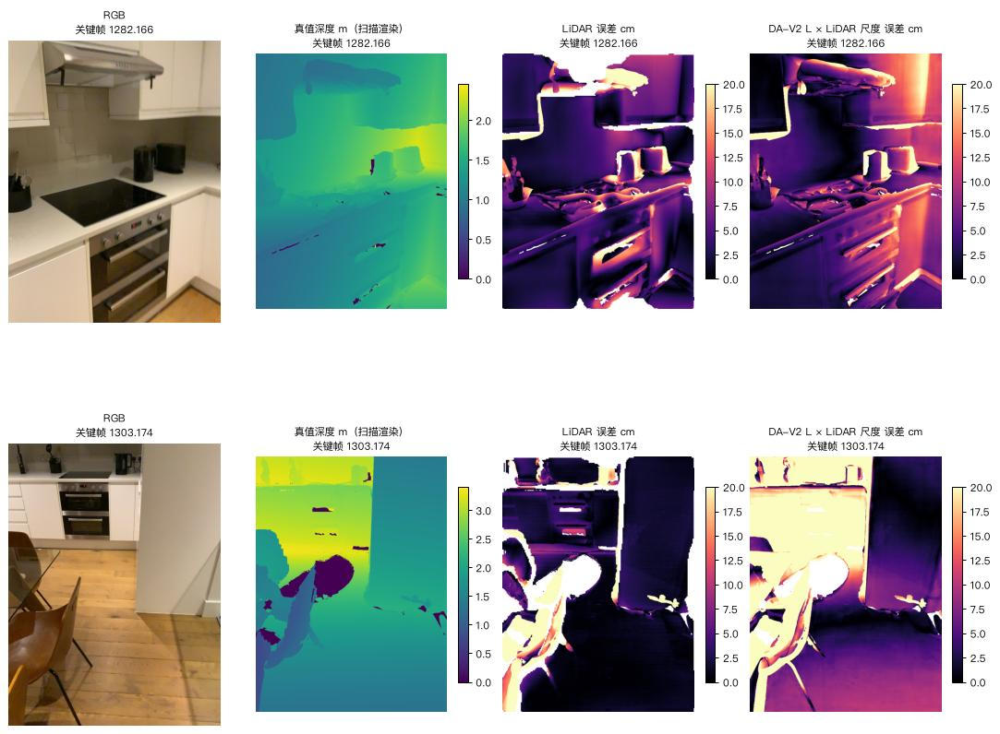

In [4]:
shown = sorted(range(len(keyframes)), key=lambda i: -(label_maps[i] >= 0).sum())[:2]
fig, axes = plt.subplots(len(shown), 4, figsize=(12, 5.2 * len(shown)))
for row, i in enumerate(shown):
    gt = gt_depths[i]
    panels = [(gt_frames[i].rgb, "RGB", None), (gt, "真值深度 m（扫描渲染）", "viridis")]
    for name in ("LiDAR", MONO):
        d = sources[name][0][i]
        err = np.where((gt > 0) & (d > 0), np.abs(d - gt) * 100, np.nan)
        panels.append((err, f"{name} 误差 cm", "magma"))
    for axis, (image, title, cmap) in zip(axes[row], panels):
        shown_image = axis.imshow(image, cmap=cmap, vmin=0 if cmap == "magma" else None,
                                  vmax=20 if cmap == "magma" else None)
        if cmap:
            plt.colorbar(shown_image, ax=axis, fraction=0.046)
        axis.set_title(f"{title}\n关键帧 {keyframes[i]}", fontsize=9)
        axis.axis("off")
plt.tight_layout()
plt.show()

### Step 2 · 轻量三维：不重建，只用逐帧深度和 ARKit 位姿

先看 ARKit 位姿本身离 COLMAP 真值多远，再把"深度误差"和"位姿误差"拆开：每个关键帧的深度点分别用 ARKit 位姿和 COLMAP 位姿放到扫描坐标系，量到激光扫描的距离。

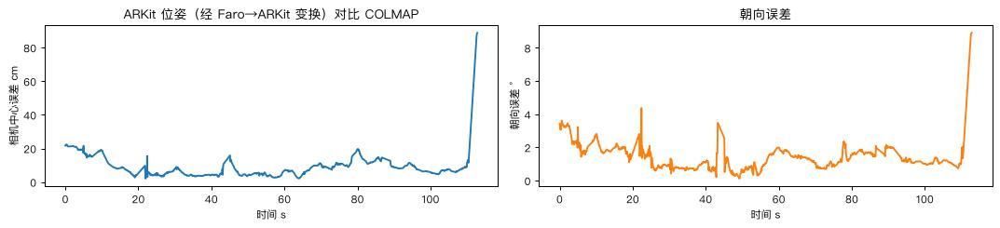

相机中心误差 cm：中位 7.2，p90 15.8，最大 88.9；朝向误差 °：中位 1.23，最大 8.91


In [5]:
pose_rows = []
for t in times:
    arkit = arkit_to_faro @ vid.arkit_pose(t)
    colmap = gt_index.poses[gt_index.matched[t][0]]
    relative = colmap[:3, :3].T @ arkit[:3, :3]
    pose_rows.append((float(t) - float(times[0]), 100 * np.linalg.norm(arkit[:3, 3] - colmap[:3, 3]),
                      np.degrees(np.arccos(np.clip((np.trace(relative) - 1) / 2, -1, 1)))))
pose_err = pd.DataFrame(pose_rows, columns=["t", "centre_cm", "rotation_deg"])
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].plot(pose_err.t, pose_err.centre_cm)
axes[0].set(xlabel="时间 s", ylabel="相机中心误差 cm", title="ARKit 位姿（经 Faro→ARKit 变换）对比 COLMAP")
axes[1].plot(pose_err.t, pose_err.rotation_deg, color="tab:orange")
axes[1].set(xlabel="时间 s", ylabel="朝向误差 °", title="朝向误差")
plt.tight_layout()
plt.show()
print("相机中心误差 cm：中位 {:.1f}，p90 {:.1f}，最大 {:.1f}；朝向误差 °：中位 {:.2f}，最大 {:.2f}".format(
    pose_err.centre_cm.median(), pose_err.centre_cm.quantile(0.9), pose_err.centre_cm.max(),
    pose_err.rotation_deg.median(), pose_err.rotation_deg.max()))

In [6]:
scan_cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(scan_xyz[crop]))
scan_cm = np.asarray(scan_cloud.voxel_down_sample(0.01).points)
scan_tree = cKDTree(scan_cm)


def input_frame(i: int, depth: np.ndarray, gt_pose: bool = False) -> Frame:
    pose = gt_frames[i].cam_to_world if gt_pose else arkit_to_faro @ vid.arkit_pose(keyframes[i])
    return Frame(i, gt_frames[i].rgb, depth, gt_frames[i].intrinsics, pose)  # pose in the Faro frame


decomposition = []
for name in ("LiDAR", MONO, "真值深度"):
    depths = gt_depths if name == "真值深度" else sources[name][0]
    for pose_name, gt_pose in (("ARKit 位姿", False), ("COLMAP 位姿（真值）", True)):
        distances = np.concatenate([scan_tree.query(backproject(input_frame(i, d, gt_pose), stride=8)[0])[0]
                                    for i, d in enumerate(depths)])
        decomposition.append({"深度": name, "位姿": pose_name, "到扫描中位距离 cm": 100 * np.median(distances),
                              "p90 cm": 100 * np.quantile(distances, 0.9)})
decomposition = pd.DataFrame(decomposition).pivot(index="深度", columns="位姿").round(1)
display(decomposition.loc[["LiDAR", MONO, "真值深度"]])

到扫描中位距离 cm                 p90 cm              
位姿                   ARKit 位姿 COLMAP 位姿（真值） ARKit 位姿 COLMAP 位姿（真值）
深度                                                                
LiDAR                     3.3           1.7      6.6           7.1
DA-V2 L × LiDAR 尺度        3.9           3.2     12.2          12.2
真值深度                      3.7           0.4      9.3           0.8

In [7]:
rng = np.random.default_rng(0)
shown_scan = scan_cm[rng.choice(len(scan_cm), 40000, replace=False)]
points, distances = [], []
for i, d in enumerate(sources[MONO][0]):
    p, _ = backproject(input_frame(i, d), stride=20)
    points.append(p)
    distances.append(scan_tree.query(p)[0])
points, distances = np.concatenate(points), np.concatenate(distances)
arkit_path = np.array([(arkit_to_faro @ vid.arkit_pose(t))[:3, 3] for t in times])
colmap_path = np.array([gt_index.poses[gt_index.matched[t][0]][:3, 3] for t in times])
fig = go.Figure([
    go.Scatter3d(x=shown_scan[:, 0], y=shown_scan[:, 1], z=shown_scan[:, 2], mode="markers",
                 marker=dict(size=1, color="lightgrey"), name="激光扫描（真值）"),
    go.Scatter3d(x=points[:, 0], y=points[:, 1], z=points[:, 2], mode="markers", name=f"{MONO} + ARKit 位姿",
                 marker=dict(size=1.5, color=np.minimum(distances * 100, 20), colorscale="Turbo", cmin=0, cmax=20,
                             colorbar=dict(title="到扫描 cm", len=0.6))),
    go.Scatter3d(x=arkit_path[:, 0], y=arkit_path[:, 1], z=arkit_path[:, 2], mode="lines",
                 line=dict(color="orange", width=4), name="ARKit 相机路径"),
    go.Scatter3d(x=colmap_path[:, 0], y=colmap_path[:, 1], z=colmap_path[:, 2], mode="lines",
                 line=dict(color="royalblue", width=4), name="COLMAP 相机路径（真值）"),
])
fig.update_layout(height=620, margin=dict(l=0, r=0, t=30, b=0), legend=dict(x=0, y=1),
                  scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False),
                  title=f"不重建的三维：{len(keyframes)} 个关键帧的单目深度点，颜色为到激光扫描的距离")
fig.show()

### Step 3 · 训练标签：把扫描上的部件和运动轴投到关键帧

标签用真值相机（COLMAP 位姿 + 渲染深度）生成，做遮挡检查，和 E0 相同。颜色表示 SceneFun3D 的 9 类动作；箭头是运动轴（转动部件为转轴，平移部件为推拉方向）。这些标签之后用来训练 affordance、动作类型和运动方向三个预测头。

In [8]:
ACTIONS = ["rotate", "key_press", "tip_push", "hook_pull", "pinch_pull", "hook_turn", "foot_push", "plug_in", "unplug"]
colour_of = dict(zip(ACTIONS, plt.get_cmap("tab10").colors))
seen_pixels = np.array([[(labels == p).sum() for labels in label_maps] for p in range(len(elements))])
visibility = pd.DataFrame({"动作": [e.label for e in elements], "可见关键帧数": (seen_pixels > 0).sum(axis=1),
                           "最多像素": seen_pixels.max(axis=1)})
summary = visibility.groupby("动作").agg(部件数=("动作", "size"), 至少一帧可见=("可见关键帧数", lambda s: int((s > 0).sum())),
                                         两帧以上可见=("可见关键帧数", lambda s: int((s > 1).sum())),
                                         最多像素中位数=("最多像素", "median"))
display(summary)
print(f"{(visibility['可见关键帧数'] > 0).sum()}/{len(elements)} 个部件至少在一个关键帧中可见；"
      f"可见部件在最佳关键帧中的像素数中位为 {visibility.loc[visibility['最多像素'] > 0, '最多像素'].median():.0f}（720×960）")

,部件数,至少一帧可见,两帧以上可见,最多像素中位数
动作,,,,
foot_push,1,1,1,1009.0
hook_pull,4,3,2,358.5
hook_turn,5,4,4,87.0
key_press,2,2,2,342.0
pinch_pull,2,2,1,4.5
plug_in,7,6,3,43.0
rotate,11,11,7,57.0
tip_push,5,4,1,23.0
unplug,1,0,0,0.0


33/38 个部件至少在一个关键帧中可见；可见部件在最佳关键帧中的像素数中位为 57（720×960）


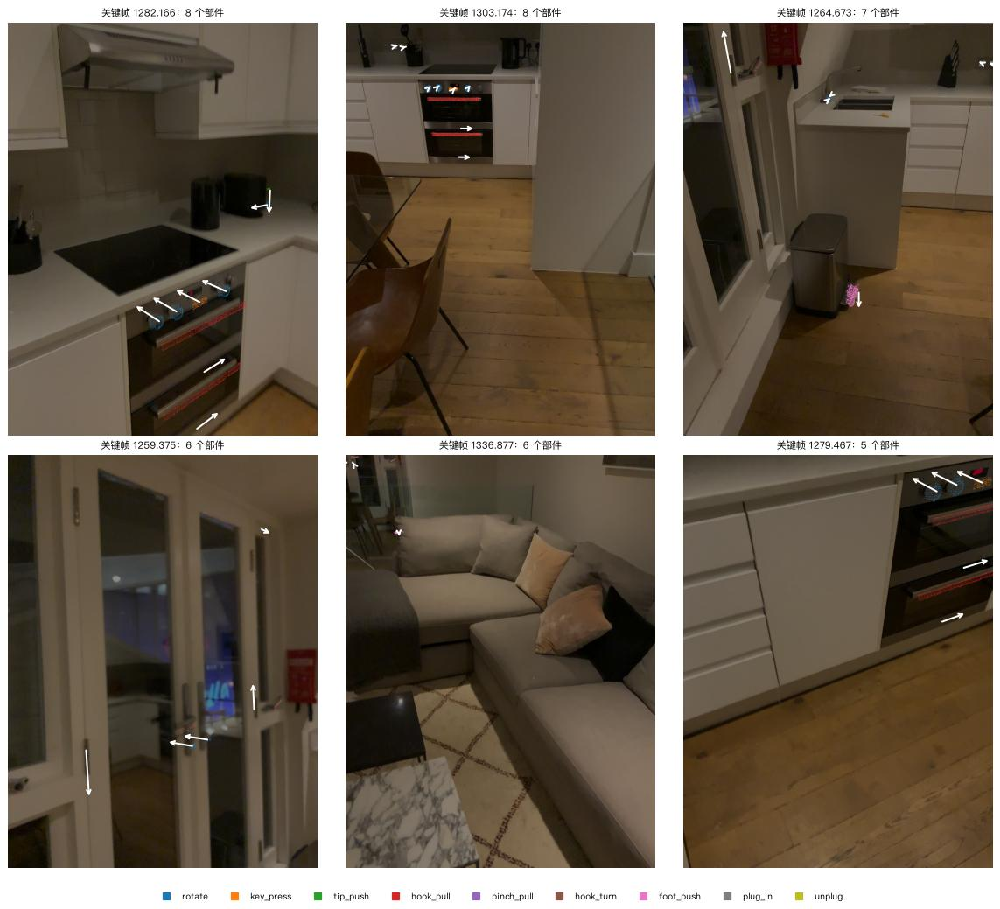

In [9]:
best_frames = sorted(range(len(keyframes)), key=lambda i: -len(set(np.unique(label_maps[i])) - {BACKGROUND}))[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 11.5))
for axis, i in zip(axes.flat, best_frames):
    frame, labels = gt_frames[i], label_maps[i]
    overlay = (frame.rgb * 0.55).astype(np.uint8)
    for p in set(np.unique(labels)) - {BACKGROUND}:
        overlay[labels == p] = (np.array(colour_of[elements[p].label]) * 255).astype(np.uint8)
    axis.imshow(overlay)
    for p in set(np.unique(labels)) - {BACKGROUND}:
        m = motions.get(elements[p].annot_id)
        if m is None:
            continue
        start, end = projected_axis(scan_xyz[m["motion_origin_idx"]], np.array(m["motion_dir"]), frame, 0.15)
        axis.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="white", lw=1.6))
    axis.set_title(f"关键帧 {keyframes[i]}：{len(set(np.unique(labels)) - {BACKGROUND})} 个部件", fontsize=9)
    axis.axis("off")
handles = [plt.Line2D([], [], marker="s", ls="", color=colour_of[a], label=a) for a in ACTIONS]
fig.legend(handles=handles, loc="lower center", ncol=9, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### Step 4 · 可执行 affordance（oracle 标签 + 输入深度和位姿）

对每个在某个关键帧中至少有 `MIN_PART_PIXELS` 个像素的部件，选像素最多的关键帧，计算一组能直接驱动人形的量：

| 量 | 怎么算（只用输入） |
|---|---|
| 接触点 | 标签中心像素，按输入深度提升到三维（部件像素深度的中位数） |
| 法向 | 接触点周围（去掉部件本身）的输入深度拟合平面，即部件所在的门板、墙面或台面，朝向相机 |
| 运动轴 | 本步仍是 oracle（SceneFun3D 运动标注），第 7 步换成预测 |
| 地面 | 所有关键帧输入点的高度中最常见的低值（ARKit 世界 +z 为重力向上） |
| 站立点 | 沿法向的水平分量后退 0.5 m（踩踏板为 0.45 m，身体圆柱半径取 0.15 m）落到地面；身体圆柱（半径 0.2 m）内有输入点就先再后退（最多 0.45 m，例如隔着台面够墙上的插座），再转 ±30°/±60° |
| 够得到 | 肩高 1.4 m 到接触点不超过 0.75 m；接触点离地低于 0.5 m 记为"需要下蹲" |

评测在扫描坐标系进行：接触点到真值部件点的距离（≤3 cm 算落在部件上）、法向与扫描法向的夹角、站立点在**激光扫描**里是否真的空闲。三种深度各算一遍，并且分别用 ARKit 和 COLMAP 位姿，把位姿误差单独看出来。

In [10]:
def voxels(points: np.ndarray) -> np.ndarray:
    cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
    return np.asarray(cloud.voxel_down_sample(VOXEL_M).points)


scan_occupied = voxels(scan_xyz[crop])
gt_floor = floor_height(scan_cm[:, 2])
visible_parts = [p for p in range(len(elements)) if seen_pixels[p].max() >= MIN_PART_PIXELS]
full_tree = cKDTree(scan_xyz[crop])
crop_index = np.flatnonzero(crop)


def gt_normal(p: int, viewer: np.ndarray) -> np.ndarray:
    # Normal of the supporting surface around the part (scan points nearby, the part itself removed).
    near = crop_index[full_tree.query_ball_point(part_points[p].mean(axis=0), GT_NORMAL_RADIUS_M)]
    near = np.setdiff1d(near, elements[p].indices)
    return surface_normal(scan_xyz[near], viewer)


def actionable_for(depths: list[np.ndarray], gt_pose: bool) -> pd.DataFrame:
    frames = [input_frame(i, d, gt_pose) for i, d in enumerate(depths)]
    observed = np.concatenate([backproject(f, stride=8)[0] for f in frames])
    floor, occupied = floor_height(observed @ UP_INPUT), voxels(observed)
    rows = []
    for p in visible_parts:
        i = int(np.argmax(seen_pixels[p]))
        frame, rows_cols = frames[i], np.argwhere(label_maps[i] == p)
        centre = np.median(rows_cols, axis=0)
        v, u = rows_cols[np.argmin(np.linalg.norm(rows_cols - centre, axis=1))]
        part_depth = frame.depth_m[rows_cols[:, 0], rows_cols[:, 1]]
        part_depth = part_depth[part_depth > 0]
        row = {"part": p, "动作": elements[p].label, "任务": task_of.get(elements[p].annot_id, ""),
               "关键帧": keyframes[i], "像素": len(rows_cols), "uv": (int(u), int(v))}
        if not len(part_depth):
            rows.append({**row, "有深度": False})
            continue
        ray = np.linalg.inv(frame.intrinsics) @ np.array([u, v, 1.0])
        contact = transform_points(frame.cam_to_world, (ray * np.median(part_depth))[None])[0]
        top, left = max(v - NORMAL_WINDOW_PX, 0), max(u - NORMAL_WINDOW_PX, 0)
        window = frame.depth_m[top:v + NORMAL_WINDOW_PX, left:u + NORMAL_WINDOW_PX]
        off_part = label_maps[i][top:v + NORMAL_WINDOW_PX, left:u + NORMAL_WINDOW_PX] != p
        ys, xs = np.nonzero((window > 0) & off_part)  # supporting surface around the part
        pixels = np.stack([xs + left, ys + top], axis=1)
        rays = np.linalg.inv(frame.intrinsics) @ np.vstack([pixels.T, np.ones(len(pixels))])
        neighbourhood = transform_points(frame.cam_to_world, (rays * window[ys, xs]).T)
        viewer = frame.cam_to_world[:3, 3]
        normal = surface_normal(neighbourhood, viewer)
        foot = elements[p].label == "foot_push"
        stand = plan_stand(contact, normal, UP_INPUT, floor, viewer, occupied, max_points=2,
                           distance=FOOT_STAND_DISTANCE_M if foot else STAND_DISTANCE_M,
                           radius=FOOT_BODY_RADIUS_M if foot else BODY_RADIUS_M)
        shoulder = stand.position + SHOULDER_M * UP_INPUT
        rows.append({**row, "有深度": True, "contact": contact, "normal": normal, "stand": stand.position,
                     "facing": stand.facing, "moved": stand.moved, "free_input": stand.free,
                     "接触点误差 cm": 100 * distance_to_part(contact, part_points[p]),
                     "法向误差 °": np.degrees(np.arccos(np.clip(normal @ gt_normal(p, viewer), -1, 1))),
                     "free_gt": is_free(stand.position, scan_occupied, UP, max_points=2),
                     "离地 m": contact @ UP_INPUT - floor, "肩到接触点 m": np.linalg.norm(shoulder - contact),
                     "站立点离真实地面 cm": 100 * (stand.position[2] - gt_floor)})
    table = pd.DataFrame(rows)
    table.attrs["floor"] = floor  # input-side floor height along UP_INPUT
    return table


results = {(name, pose): actionable_for(gt_depths if name == "真值深度" else sources[name][0], pose == "COLMAP")
           for name in ("LiDAR", MONO, "真值深度") for pose in ("ARKit", "COLMAP")}
summary_rows = []
for (name, pose), table in results.items():
    ok = table[table["有深度"]]
    summary_rows.append({"深度": name, "位姿": pose, "部件": len(table), "有深度": len(ok),
                         "接触点中位误差 cm": ok["接触点误差 cm"].median(),
                         f"落在部件上（≤{100 * ON_PART_M:.0f} cm）": (ok["接触点误差 cm"] <= 100 * ON_PART_M).mean(),
                         "法向中位误差 °": ok["法向误差 °"].median(),
                         "站立点在扫描中空闲": ok["free_gt"].mean(), "需要换位置": ok["moved"].mean(),
                         "站立点离真实地面 cm": ok["站立点离真实地面 cm"].median()})
actionable_summary = pd.DataFrame(summary_rows).set_index(["深度", "位姿"])
display(actionable_summary.style.format({"接触点中位误差 cm": "{:.1f}", f"落在部件上（≤{100 * ON_PART_M:.0f} cm）": "{:.0%}",
                                          "法向中位误差 °": "{:.0f}", "站立点在扫描中空闲": "{:.0%}",
                                          "需要换位置": "{:.0%}", "站立点离真实地面 cm": "{:+.1f}"}))

In [11]:
main = results[(MONO, "ARKit")]
per_part = main[main["有深度"]].assign(
    **{"LiDAR 误差 cm": results[("LiDAR", "ARKit")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       "真值深度 误差 cm": results[("真值深度", "ARKit")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       f"{MONO}+COLMAP 误差 cm": results[(MONO, "COLMAP")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       "够得到": lambda d: np.where(d["离地 m"] < LOW_PART_M, "需要下蹲", np.where(d["肩到接触点 m"] <= REACH_M, "是", "太远"))})
columns = ["动作", "任务", "像素", "接触点误差 cm", "LiDAR 误差 cm", "真值深度 误差 cm", f"{MONO}+COLMAP 误差 cm",
           "法向误差 °", "free_gt", "moved", "够得到"]
display(per_part[columns].rename(columns={"接触点误差 cm": f"{MONO} 误差 cm", "free_gt": "扫描中空闲", "moved": "换过位置"})
        .sort_values("动作").style.format(precision=1).hide(axis="index"))

动作,任务,像素,DA-V2 L × LiDAR 尺度 误差 cm,LiDAR 误差 cm,真值深度 误差 cm,DA-V2 L × LiDAR 尺度+COLMAP 误差 cm,法向误差 °,扫描中空闲,换过位置,够得到
foot_push,Open the trash can located in the kitchen near the sink,1009,0.3,0.5,0.6,0.8,4.6,True,False,需要下蹲
hook_pull,Open the glass door next to the black floor lamp,55,6.5,nan,2.5,0.1,7.6,True,False,是
hook_pull,Open the bottom oven door,662,9.0,6.0,3.8,13.8,5.5,True,True,需要下蹲
hook_pull,Open the top oven door,832,7.3,10.6,3.9,11.6,15.4,True,True,太远
hook_turn,Open the window located above the trash can in the kitchen,82,3.4,5.7,2.6,3.8,40.3,True,True,太远
hook_turn,Open the small window located near to the portable air conditioner,173,4.5,1.9,1.8,3.5,35.3,True,True,太远
hook_turn,Open the left balcony door located in the kitchen,151,12.0,1.0,4.8,16.8,29.4,True,False,是
hook_turn,Open the right balcony door located in the kitchen,87,14.5,nan,6.9,19.0,28.2,True,False,是
key_press,Turn on the TV using the remote control located on the TV stand,516,5.4,5.5,5.5,4.4,28.8,False,False,需要下蹲
key_press,,168,3.8,2.8,4.2,6.6,8.6,True,True,太远


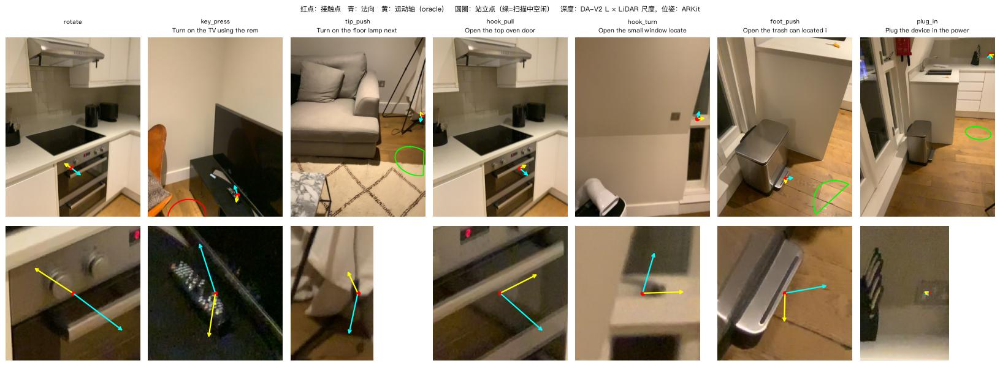

In [12]:
def footprint(frame: Frame, centre: np.ndarray, radius: float = 0.2) -> np.ndarray:
    angles = np.linspace(0, 2 * np.pi, 40)
    circle = centre + radius * np.stack([np.cos(angles), np.sin(angles), np.zeros_like(angles)], axis=1)
    uv, _, inside = project(circle, frame)
    return uv if inside.all() else uv[inside]


examples = []
for action in ACTIONS:  # one example per action type, the part seen with most pixels
    rows = main[(main["动作"] == action) & main["有深度"]].sort_values("像素", ascending=False)
    if len(rows):
        examples.append(rows.iloc[0])
examples = examples[:8]
fig, axes = plt.subplots(2, len(examples), figsize=(2.6 * len(examples), 7.2))
for column, row in enumerate(examples):
    i = keyframes.index(row["关键帧"])
    frame = input_frame(i, sources[MONO][0][i])
    m = motions.get(elements[row.part].annot_id)
    for r, zoom in enumerate((False, True)):
        axis = axes[r, column]
        axis.imshow(frame.rgb)
        u, v = row["uv"]
        start, normal_end = projected_axis(row["contact"], row["normal"], frame, 0.12)
        axis.annotate("", xy=normal_end, xytext=start, arrowprops=dict(arrowstyle="->", color="cyan", lw=1.8))
        if m is not None:
            _, motion_end = projected_axis(row["contact"], np.array(m["motion_dir"]), frame, 0.12)
            axis.annotate("", xy=motion_end, xytext=start, arrowprops=dict(arrowstyle="->", color="yellow", lw=1.8))
        axis.plot(u, v, "o", color="red", ms=5)
        ring = footprint(frame, row["stand"])
        if len(ring):
            axis.plot(ring[:, 0], ring[:, 1], color="lime" if row["free_gt"] else "red", lw=1.5)
        if zoom:
            axis.set_xlim(u - 80, u + 80)
            axis.set_ylim(v + 80, v - 80)
        axis.axis("off")
    axes[0, column].set_title(f"{row['动作']}\n{row['任务'][:28]}", fontsize=8)
fig.suptitle(f"红点：接触点　青：法向　黄：运动轴（oracle）　圆圈：站立点（绿=扫描中空闲）　深度：{MONO}，位姿：ARKit", fontsize=9)
plt.tight_layout()
plt.show()

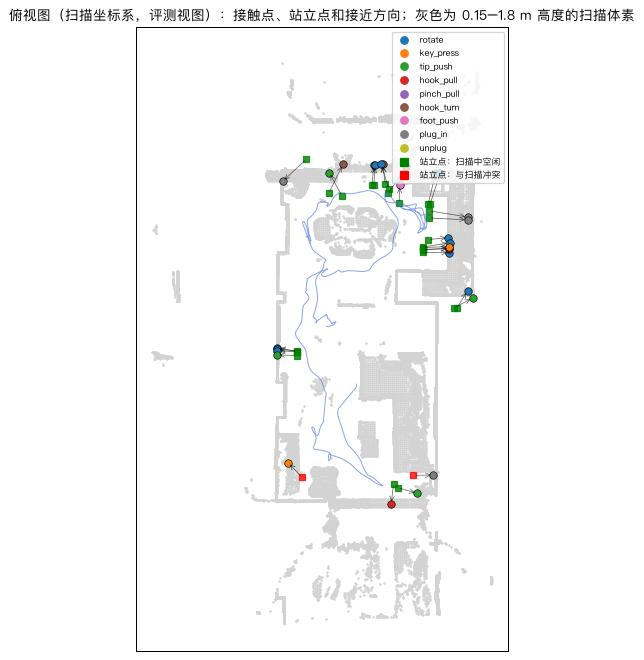

In [13]:
band = scan_occupied[(scan_occupied[:, 2] > gt_floor + 0.15) & (scan_occupied[:, 2] < gt_floor + 1.8)]
fig, axis = plt.subplots(figsize=(9, 9))
axis.scatter(band[:, 0], band[:, 1], s=1, c="lightgrey")
ok = main[main["有深度"]]
for _, row in ok.iterrows():
    colour = colour_of[row["动作"]]
    axis.plot(*row["contact"][:2], "o", color=colour, ms=6, mec="black", mew=0.5)
    axis.plot(*row["stand"][:2], "s", color="green" if row["free_gt"] else "red", ms=5, alpha=0.8)
    axis.annotate("", xy=row["contact"][:2], xytext=row["stand"][:2],
                  arrowprops=dict(arrowstyle="->", color="black", lw=0.6, alpha=0.6))
axis.plot(colmap_path[:, 0], colmap_path[:, 1], color="royalblue", lw=0.8, alpha=0.6)
handles = [plt.Line2D([], [], marker="o", ls="", color=colour_of[a], label=a) for a in ACTIONS]
handles += [plt.Line2D([], [], marker="s", ls="", color=c, label=l) for c, l in (("green", "站立点：扫描中空闲"), ("red", "站立点：与扫描冲突"))]
axis.legend(handles=handles, fontsize=7, loc="upper right")
axis.set_aspect("equal")
axis.set_title(f"俯视图（扫描坐标系，评测视图）：接触点、站立点和接近方向；灰色为 0.15–1.8 m 高度的扫描体素")
axis.set_xticks([])
axis.set_yticks([])
plt.show()

In [14]:
def as_list(value):
    return np.asarray(value, dtype=float).round(4).tolist()


def motion_fields(annot_id: str) -> dict:
    m = motions.get(annot_id)
    if m is None:
        return {"motion_type": None}
    return {"motion_type": m["motion_type"], "motion_dir_faro": as_list(m["motion_dir"]),
            "motion_origin_faro": as_list(scan_xyz[m["motion_origin_idx"]])}


records = [{"annot_id": elements[r.part].annot_id, "action": r["动作"], "task": r["任务"], "keyframe": r["关键帧"],
            "pixel": list(r["uv"]), "pixels": int(r["像素"]), "contact_faro": as_list(r["contact"]), "normal_faro": as_list(r["normal"]),
            "stand_faro": as_list(r["stand"]), "facing_faro": as_list(r["facing"]), "stand_free_in_scan": bool(r["free_gt"]),
            "stand_moved": bool(r["moved"]), "contact_error_cm": round(float(r["接触点误差 cm"]), 2),
            **motion_fields(elements[r.part].annot_id)}
           for _, r in main[main["有深度"]].iterrows()]
# The chosen input depth and the input cameras of every keyframe, for S1-02 (humanoid display).
inputs_dir = OUT / "inputs"
inputs_dir.mkdir(exist_ok=True)
for i, t in enumerate(keyframes):
    frame = input_frame(i, sources[MONO][0][i])
    np.savez_compressed(inputs_dir / f"{t}.npz", depth=frame.depth_m.astype(np.float16), intrinsics=frame.intrinsics,
                        cam_to_world=frame.cam_to_world)
manifest = {"visit": VISIT, "video": VIDEO, "keyframes": keyframes, "pixel_step": PIXEL_STEP, "mono_model": MONO,
            "mono_model_id": MONO_MODELS[MONO.split(" × ")[0]], "lidar_scaled": " × " in MONO, "depth_table": depth_table.reset_index().to_dict("records"),
            "pose_error": {"centre_cm_median": float(pose_err.centre_cm.median()),
                           "rotation_deg_median": float(pose_err.rotation_deg.median())},
            "actionable_summary": actionable_summary.reset_index().to_dict("records"),
            "floor_input": float(results[(MONO, "ARKit")].attrs["floor"]), "up_input": as_list(UP_INPUT),
            "gt_floor": float(gt_floor),
            "note": "oracle labels and motion axes; poses expressed in the Faro frame for evaluation only"}
(OUT / "actionable_oracle.json").write_text(json.dumps(records, indent=1, ensure_ascii=False))
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1, ensure_ascii=False, default=float))
print("saved:", *(str((OUT / n).relative_to(ROOT)) for n in ("actionable_oracle.json", "manifest.json")), sep="\n  ")

saved:
  runs/mem_s1/actionable_oracle.json
  runs/mem_s1/manifest.json


#### 读结果的方式

- **Step 1b**：部件处的深度误差比全图更重要；单目模型的选择只在这个开发场景上做过。
- **Step 2**：同一种深度换成 COLMAP 位姿后误差下降的部分，就是 ARKit 位姿的代价；换成真值深度后下降的部分，是深度的代价。
- **Step 4**：oracle 版的误差全部来自输入深度和位姿，因此是第 7 步（模型预测）的上限。站立点在扫描中空闲的比例说明只用输入点做的空闲检查是否可信。
- 这里的数字只针对一个场景、一个视频，用来看链路和误差来源，不是方法结论。

#### 本次运行记录（2026-11-10，40 个关键帧，720×960）

以下数字只针对这次执行；改动参数后应重新核对。

- **输入约定：** LiDAR 和 ARKit 相机需顺时针转 1 次才正，这只由 ARKit 位姿推算；转正后直接放大即可对上 hires 像素（中位相对误差 1.3%）。
- **深度：**
  - LiDAR 全图中位误差 2.4 cm，部件处 5.2 cm，覆盖 88% 的像素。
  - Depth Anything V2 的绝对尺度偏远约 33%，中位误差约 50 cm；逐帧乘 LiDAR 尺度后，Large 降到 4.7 cm，但部件处仍有 11.2 cm。
  - Depth Pro 在 M1 GPU 上的输出不可信，未纳入比较。
- **位姿：** ARKit 相机中心相对 COLMAP 的误差中位 7.2 cm，p90 15.8 cm，个别帧达 89 cm；朝向中位 1.2°。
- **深度 × 位姿分解（到扫描的中位距离）：**
  - 真值深度 + COLMAP 0.4 cm，换成 ARKit 位姿后 3.7 cm；
  - LiDAR + ARKit 3.3 cm，比"真值深度 + ARKit"还好，因为 LiDAR 和 ARKit 位姿来自同一台设备，彼此一致。
- **标签：** 38 个部件中 33 个至少在一个关键帧中可见；最佳关键帧里的像素数中位为 57。两个 pinch_pull 只有 2–5 个像素，没有生成条目。
- **可执行 affordance（29 个部件）：**
  - 接触点中位误差：LiDAR + ARKit 2.8 cm（54% 落在部件上）；单目 × LiDAR 尺度 + ARKit 7.7 cm（14%）；真值深度 + COLMAP 0.4 cm（97%）。
  - 最后一项说明链路本身正确，误差来自输入深度和 ARKit 位姿。
  - 支撑面法向的中位误差为 13–24°。
  - 站立点在扫描中真正空闲的比例为 75–97%。
- **对第 7 步的提示：**
  - 单目深度在小部件处的误差（约 11 cm）是主要瓶颈。
  - 只用输入点做空闲检查时，没观察到的空间被当成了空闲，违反"未知不等于空闲"，后续需要改。

**下一步：** [S1-02](#w1-s1-02) 按 `runs/mem_s1/actionable_oracle.json` 在关键帧上贴人形（站立 + 伸手 + 运动箭头），并在扫描里检查。

<a id="w1-s1-02"></a>

# 第 7 部分 · S1-02 人形走近并操作

<sub>原文件 `notebooks/mem/S1_02_humanoid_approach.ipynb`（11-10）· 生成方式：`notebooks/builders/build_mem_s1_02.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## S1-02 · 人形接近与操作（oracle 版）｜SceneFun3D 场景 421069

**这一步回答：** 用 S1-01 算出的可执行 affordance（接触点、支撑面法向、站立点、朝向、运动轴），能不能摆出一个"位置准、动作对"的人形？

| | 内容 |
|---|---|
| 输入 | S1-01 的 `runs/mem_s1/actionable_oracle.json` 与各关键帧的输入相机和深度；部件位置与运动轴仍是 oracle |
| 人形 | SMPL-X 中性体型；站立或下蹲（接触点离地低于 0.55 m）；面向部件，双脚落在输入估计的地面上，再用 IK 让手掌（foot_push 为右脚）到达接触点 |
| 画面 | **主画面**：贴在关键帧上，按输入深度做遮挡；**检查画面**：放进激光扫描（只用于评测），洋红色为真值部件 |
| 指标 | IK 残差；手掌／脚到真值部件的距离；双脚离真实地面的高度；身体与扫描冲突的顶点比例（不含手／脚附近） |
| 许可 | SMPL-X 模型文件只在本地 `data/body_models/` 使用，notebook 里只保存渲染图，不保存网格 |

运行前先执行 [S1-01](#w1-s1-01)。

### Step 0 · 参数与数据

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import pandas as pd
from IPython.display import display
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.frames import Frame
from affordance3d.geometry import project
from affordance3d.mem.body import JOINT, load_smplx
from affordance3d.mem.depth_models import MonoDepth
from affordance3d.mem.humanoid import pose_humanoid
from affordance3d.mem.inputs import index_video
from affordance3d.mem.render import look_at, overlay_body, rasterize, splat, to_camera
from affordance3d.scenefun3d import read_annotations, read_laser_scan

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "font.size": 9, "axes.unicode_minus": False,
                     "font.sans-serif": ["PingFang SC", "Heiti SC", "Noto Sans CJK SC", "Arial Unicode MS", "DejaVu Sans"]})

DATA = ROOT / "data" / "scenefun3d"
VISIT, VIDEO = "421069", "42444490"
S1 = ROOT / "runs" / "mem_s1"
MODEL_PATH = ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz"
PIXEL_STEP = 2
COLLISION_M, NEAR_EFFECTOR_M = 0.02, 0.15
VISIBLE_DEPTH_M = 0.15  # the contact counts as visible in a frame when the input depth agrees within this
CANDIDATE_STRIDE = 3  # display frames are searched over every 3rd video frame, not only the keyframes

records = json.loads((S1 / "actionable_oracle.json").read_text())
manifest = json.loads((S1 / "manifest.json").read_text())
UP, FLOOR = np.array(manifest["up_input"]), manifest["floor_input"]
keyframes = manifest["keyframes"]
vid = index_video(DATA, VISIT, VIDEO)
body_model = load_smplx(MODEL_PATH)


arkit_to_faro = np.linalg.inv(vid.faro_to_arkit)
HALF_HW = (1920 // PIXEL_STEP, 1440 // PIXEL_STEP)


def camera(t: str) -> tuple[np.ndarray, np.ndarray]:
    # Input camera of any video frame: hires intrinsics (subsampled) and the ARKit pose, expressed in the Faro frame.
    return np.diag([1 / PIXEL_STEP, 1 / PIXEL_STEP, 1.0]) @ vid.intrinsics(t), arkit_to_faro @ vid.arkit_pose(t)
scan_xyz, scan_rgb = read_laser_scan(DATA / VISIT / f"{VISIT}_laser_scan.ply")
crop = np.load(DATA / VISIT / f"{VISIT}_crop_mask.npy")
cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(scan_xyz[crop]))
cloud.colors = o3d.utility.Vector3dVector(scan_rgb[crop].astype(np.float64))
cloud = cloud.voxel_down_sample(0.01)
scan_cm, scan_cm_rgb = np.asarray(cloud.points), np.asarray(cloud.colors)
scan_tree = cKDTree(scan_cm)
part_points = {e.annot_id: scan_xyz[e.indices] for e in read_annotations(DATA / VISIT / f"{VISIT}_annotations.json")}
print(f"{len(records)} 个可执行 affordance；深度 {manifest['mono_model']}；SMPL-X: {MODEL_PATH.relative_to(ROOT)}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


29 个可执行 affordance；深度 DA-V2 L × LiDAR 尺度；SMPL-X: data/body_models/smplx/SMPLX_NEUTRAL.npz


### Step 1 · 每类动作选一个部件，并选一个适合展示的视频帧

展示帧在**整段视频**（每 3 帧取 1）里找，只用输入：接触点在画面内且可见（LiDAR 深度与接触点深度一致），站立处的身体（脚、腰、头三个点）尽量都在画面内，相机离接触点 1.5–4 m。选中的帧再用 S1-01 选出的单目深度算一次深度，用于遮挡。

In [2]:
candidates = vid.rgb_times[::CANDIDATE_STRIDE]
cameras = {t: camera(t) for t in candidates}


def display_score(record: dict, t: str) -> tuple[float, int]:
    intrinsics, pose = cameras[t]
    frame = Frame(0, np.zeros((1, 1, 3), np.uint8), np.zeros(HALF_HW, np.float32), intrinsics, pose)
    contact, stand = np.array(record["contact_faro"]), np.array(record["stand_faro"])
    uv, z, inside = project(np.vstack([contact, stand + np.outer([0.1, 0.9, 1.6], UP)]), frame)
    if not inside[0]:
        return -1.0, 0
    u, v = np.rint(uv[0]).astype(int)
    observed = vid.lidar_depth(t, HALF_HW)[v, u]
    if observed <= 0 or abs(observed - z[0]) > VISIBLE_DEPTH_M:
        return -1.0, 0
    distance = np.linalg.norm(contact - pose[:3, 3])
    in_view = int(inside[1:].sum())
    return in_view + (1.0 if 1.5 <= distance <= 4.0 else 0.0) - 0.1 * abs(distance - 2.5), in_view


examples = []
for action in sorted({r["action"] for r in records}):
    best = max((r for r in records if r["action"] == action), key=lambda r: r["pixels"])
    scores = {t: display_score(best, t) for t in candidates}
    shown = max(scores, key=lambda t: scores[t][0])
    examples.append({**best, "display_frame": shown, "body_points_in_view": scores[shown][1]})

mono = MonoDepth(manifest["mono_model_id"])
frames = {}
for e in examples:
    t = e["display_frame"]
    if t in frames:
        continue
    rgb = plt.imread(vid.rgb_path(t))
    depth = mono.predict(rgb, focal_px=float(vid.intrinsics(t)[0, 0]))[::PIXEL_STEP, ::PIXEL_STEP]
    if manifest["lidar_scaled"]:
        lidar = vid.lidar_depth(t, HALF_HW)
        both = (lidar > 0) & (depth > 0)
        depth = depth * np.median(lidar[both] / depth[both])
    intrinsics, pose = cameras[t]
    frames[t] = Frame(0, rgb[::PIXEL_STEP, ::PIXEL_STEP], depth.astype(np.float32), intrinsics, pose)
del mono
display(pd.DataFrame([{"动作": e["action"], "任务": e["task"] or "（无描述）", "部件像素": e["pixels"],
                       "标签所在关键帧": e["keyframe"], "展示帧": e["display_frame"],
                       "身体点在画面内（脚/腰/头）": e["body_points_in_view"]} for e in examples]))

W1110 13:38:50.681000 48896 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/503 [00:00<?, ?it/s]

/opt/anaconda3/envs/affordance3d/lib/python3.12/site-packages/transformers/image_processing_backends.py:135: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  image = torch.from_numpy(image)


,动作,任务,部件像素,标签所在关键帧,展示帧,身体点在画面内（脚/腰/头）
0,foot_push,Open the trash can located in the kitchen near...,1009,1267.272,1264.273,2
1,hook_pull,Open the top oven door,832,1282.166,1304.174,3
2,hook_turn,Open the small window located near to the port...,173,1254.177,1253.478,1
3,key_press,Turn on the TV using the remote control locate...,516,1321.167,1316.769,1
4,plug_in,Plug the device in the power supply located ne...,88,1264.673,1263.973,3
5,rotate,（无描述）,212,1282.166,1303.874,3
6,tip_push,Turn on the floor lamp next to the couch,54,1331.679,1327.381,3


### Step 2 · 摆人形：面向部件、双脚着地、IK 到接触点

In [3]:
gt_floor = manifest["gt_floor"]


def effector_position(human) -> np.ndarray:
    if human.effector == "right foot":
        return human.joints[JOINT["right_foot"]]
    side = human.effector.split()[0]
    return 0.5 * (human.joints[JOINT[f"{side}_wrist"]] + human.joints[JOINT[f"{side}_middle1"]])


posed, rows = [], []
for e in examples:
    human = pose_humanoid(body_model, np.array(e["contact_faro"]), np.array(e["normal_faro"]), np.array(e["stand_faro"]),
                          np.array(e["facing_faro"]), FLOOR, UP, e["action"])
    near_effector = np.linalg.norm(human.vertices - human.target, axis=1) < NEAR_EFFECTOR_M
    distances, _ = scan_tree.query(human.vertices[~near_effector])
    effector = effector_position(human)
    posed.append(human)
    rows.append({"动作": e["action"], "末端": human.effector, "姿态": human.posture,
                 "IK 残差 cm": 100 * human.reach_error_m,
                 "手掌/脚到真值部件 cm": 100 * np.min(np.linalg.norm(part_points[e["annot_id"]] - effector, axis=1)),
                 "双脚离真实地面 cm": 100 * (human.vertices[:, 2].min() - gt_floor),
                 "身体与扫描冲突": float(np.mean(distances < COLLISION_M)),
                 "站立点在扫描中空闲": e["stand_free_in_scan"]})
humanoid_table = pd.DataFrame(rows)
display(humanoid_table.style.format({"IK 残差 cm": "{:.1f}", "手掌/脚到真值部件 cm": "{:.1f}",
                                     "双脚离真实地面 cm": "{:+.1f}", "身体与扫描冲突": "{:.1%}"}).hide(axis="index"))

动作,末端,姿态,IK 残差 cm,手掌/脚到真值部件 cm,双脚离真实地面 cm,身体与扫描冲突,站立点在扫描中空闲
foot_push,right foot,standing,4.0,5.5,+4.7,0.0%,True
hook_pull,right hand,standing,4.3,1.7,+3.6,0.0%,True
hook_turn,right hand,standing,3.5,4.0,+5.7,1.1%,True
key_press,right hand,squatting,0.5,5.7,+3.4,2.9%,False
plug_in,right hand,standing,7.1,21.0,+3.9,0.0%,True
rotate,right hand,standing,1.7,3.6,+3.6,0.0%,True
tip_push,right hand,squatting,2.0,8.6,+1.5,0.0%,True


### Step 3 · 主画面：贴在关键帧上

人形按输入深度做遮挡（家具在前面时会挡住身体）；红点为接触点，黄色箭头为运动方向（平移部件）或转轴（转动部件），均为 oracle。

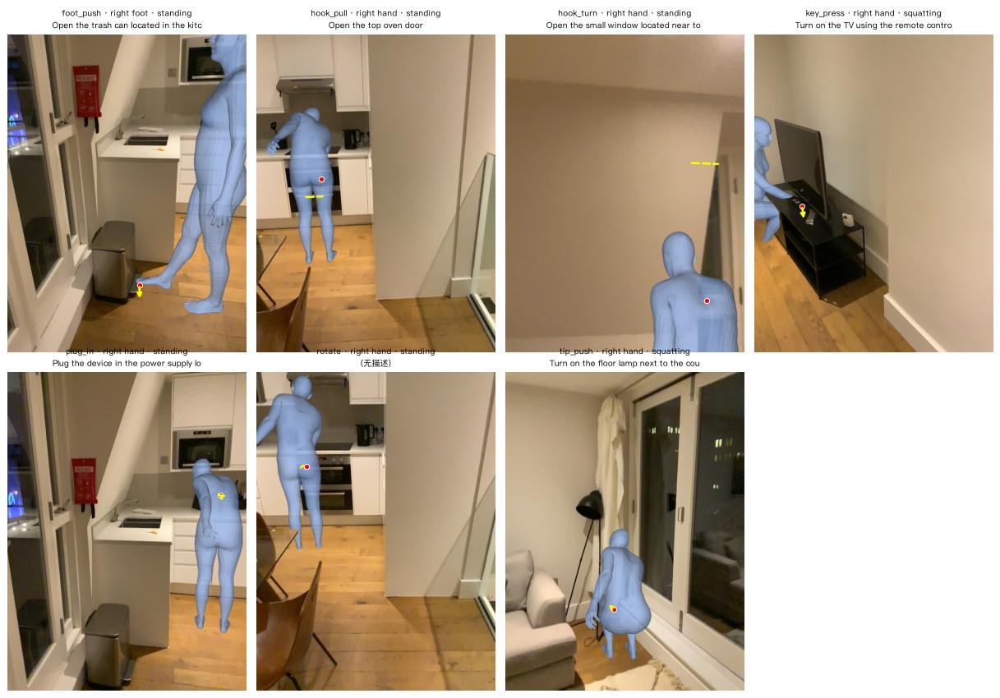

In [4]:
def draw_motion(axis, frame: Frame, e: dict) -> None:
    if e.get("motion_type") is None:
        return
    direction = np.array(e["motion_dir_faro"]) / np.linalg.norm(e["motion_dir_faro"])
    contact = np.array(e["contact_faro"])
    if e["motion_type"] == "trans":
        ends = np.stack([contact, contact + 0.15 * direction])
    else:
        origin = np.array(e["motion_origin_faro"])
        ends = np.stack([origin - 0.12 * direction, origin + 0.12 * direction])
    uv, _, inside = project(ends, frame)
    if inside.all():
        style = dict(arrowstyle="->", color="yellow", lw=2) if e["motion_type"] == "trans" else dict(arrowstyle="-", color="yellow", lw=2, ls="--")
        axis.annotate("", xy=uv[1], xytext=uv[0], arrowprops=style)


composites = []
for e, human in zip(examples, posed):
    frame = frames[e["display_frame"]]
    depth, shade = rasterize(to_camera(human.vertices, frame.cam_to_world), body_model.faces, frame.intrinsics, frame.image_hw)
    composites.append(overlay_body(frame.rgb, frame.depth_m, depth, shade, margin_m=0.05, alpha=0.85))

columns = 4
rows_n = int(np.ceil(len(examples) / columns))
fig, axes = plt.subplots(rows_n, columns, figsize=(3.4 * columns, 4.7 * rows_n))
for axis in axes.flat:
    axis.axis("off")
for axis, e, human, image in zip(axes.flat, examples, posed, composites):
    frame = frames[e["display_frame"]]
    axis.imshow(image)
    uv, _, inside = project(np.array([e["contact_faro"]]), frame)
    if inside[0]:
        axis.plot(*uv[0], "o", color="red", ms=5, mec="white", mew=0.8)
    draw_motion(axis, frame, e)
    axis.set_title(f"{e['action']} · {human.effector} · {human.posture}\n{(e['task'] or '（无描述）')[:38]}", fontsize=8)
plt.tight_layout()
plt.show()

### Step 4 · 检查画面：放进激光扫描（真值，只用于评测）

从侧后上方的虚拟相机看同一个人形（在几个方向里选视线最不被扫描点遮挡的一个）；扫描点为真实颜色，洋红色为真值部件，红点为预测的接触点。人形与真值部件的偏差主要来自 S1-01 中 ARKit 位姿与输入深度的误差。

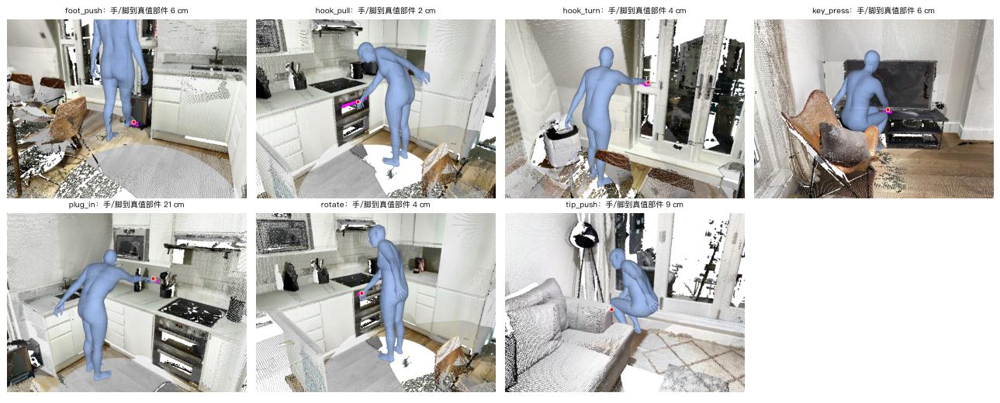

In [5]:
CHECK_HW = (600, 800)
CHECK_K = np.array([[620.0, 0, 399.5], [0, 620.0, 299.5], [0, 0, 1]])


CHECK_DISTANCE_M, CHECK_HEIGHT_M = 2.2, 0.9
CHECK_AZIMUTHS_DEG = (-50, 50, -25, 25, -75, 75, 0)  # around the direction from the part back to the person


def blocked(eye: np.ndarray, centre: np.ndarray) -> int:
    # Scan points close to the line of sight (ignoring the last 0.8 m around the person and the part).
    samples = eye + np.linspace(0.0, 1.0, 30)[:, None] * (centre - eye)
    keep = np.linalg.norm(samples - centre, axis=1) > 0.8
    return sum(len(n) for n in scan_tree.query_ball_point(samples[keep], 0.15))


def check_view(e: dict, human) -> np.ndarray:
    contact, stand = np.array(e["contact_faro"]), np.array(e["stand_faro"])
    centre = 0.5 * (contact + stand) + 0.3 * UP
    back = -np.array(e["facing_faro"])
    eyes = []
    for degrees in CHECK_AZIMUTHS_DEG:
        angle = np.radians(degrees)
        direction = back * np.cos(angle) + np.cross(UP, back) * np.sin(angle)
        eyes.append(centre + CHECK_DISTANCE_M * direction + CHECK_HEIGHT_M * UP)
    eye = min(eyes, key=lambda candidate: blocked(candidate, centre))  # clearest line of sight
    pose = look_at(eye, centre, UP)
    near = scan_tree.query_ball_point(centre, 3.0)
    points = np.vstack([scan_cm[near], part_points[e["annot_id"]]])
    colours = np.vstack([scan_cm_rgb[near], np.tile([1.0, 0.0, 1.0], (len(part_points[e["annot_id"]]), 1))])
    image, scene_depth = splat(to_camera(points, pose), colours, CHECK_K, CHECK_HW, radius_px=1)
    body_depth, shade = rasterize(to_camera(human.vertices, pose), body_model.faces, CHECK_K, CHECK_HW)
    composite = overlay_body((image * 255).astype(np.uint8), np.where(np.isfinite(scene_depth), scene_depth, 0),
                             body_depth, shade, margin_m=0.03, alpha=0.9)
    uv = (to_camera(contact[None], pose) @ CHECK_K.T)
    return composite, uv[0, :2] / uv[0, 2]


fig, axes = plt.subplots(rows_n, columns, figsize=(3.6 * columns, 2.9 * rows_n))
for axis in axes.flat:
    axis.axis("off")
for axis, e, human, row in zip(axes.flat, examples, posed, rows):
    image, contact_uv = check_view(e, human)
    axis.imshow(image)
    axis.plot(*contact_uv, "o", color="red", ms=4, mec="white", mew=0.6)
    axis.set_title(f"{e['action']}：手/脚到真值部件 {row['手掌/脚到真值部件 cm']:.0f} cm", fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
summary = {"examples": len(examples), "median_ik_residual_cm": float(humanoid_table["IK 残差 cm"].median()),
           "median_effector_to_gt_part_cm": float(humanoid_table["手掌/脚到真值部件 cm"].median()),
           "median_feet_to_gt_floor_cm": float(humanoid_table["双脚离真实地面 cm"].median()),
           "median_collision_fraction": float(humanoid_table["身体与扫描冲突"].median())}
(S1 / "humanoid_summary.json").write_text(json.dumps(summary, indent=1))
print(json.dumps(summary, indent=1, ensure_ascii=False))

{
 "examples": 7,
 "median_ik_residual_cm": 3.498220071196556,
 "median_effector_to_gt_part_cm": 5.535542680121741,
 "median_feet_to_gt_floor_cm": 3.643798828125,
 "median_collision_fraction": 0.0
}


#### 读结果的方式

- **主画面**看"像不像在操作"：站位、朝向、哪只手、是否下蹲，以及遮挡是否合理。
- **检查画面**和表格看"准不准"：手到真值部件的距离包含 S1-01 的位姿与深度误差；冲突比例高说明站立点或姿态穿进了家具。
- 这是 oracle 版（部件位置与运动轴来自标签），代表展示效果的上限；S1 第 7 步换成预测后再比较。
- 人形是运动学摆放，没有物理和手指动作；旋钮、插头这类需要手指的动作只表现为"手到位"。

#### 本次运行记录（2026-11-10）

- **规模：** 7 类动作各一例（pinch_pull、unplug 没有足够像素的部件）。IK 残差中位 3.5 cm。
- **手掌／脚到真值部件的距离：** 烤箱门把手 1.7 cm、烤箱旋钮 3.6 cm、窗把手 4.0 cm、垃圾桶踏板 5.5 cm、遥控器 5.7 cm、落地灯开关 8.6 cm、台面后墙上的插座 21.0 cm。
- **双脚离真实地面：** +1.5 到 +5.7 cm，来自 ARKit 位姿的高度偏差。
- **身体与扫描冲突：** 0–2.9% 的顶点。
- **失败案例：**
  - 墙上插座：站立点退到台面外以后，手够不到，需要更大幅度前倾或侧身。
  - 遥控器：站立点在扫描中不空闲（旁边有椅子）。
  - 窗户和遥控器两例的展示帧里只能看到部分身体。

**下一步：** 走近的短动画（LINGO／DartControl 在远程 A6000 生成，Mac 渲染）；第 6 步按任务描述检索部件与关键帧。

<a id="w1-pipeline"></a>

# 第 8 部分 · pipeline 工作文档

<sub>原文件 `notebooks/mem/pipeline.ipynb`（11-11 建，11-13 最后修改）· 生成方式：手写，没有 builder · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## mem pipeline：各环节的想法、要求和缺口

**工作文档** · 建立于 2026-11-11 · 配套：[演示 notebook](#w1-memdemo)（看图和数字）、[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 17 节（环节清单）

这份 notebook 只有文字，不需要运行。它把整条流程拆成 15 个环节，每个环节写清楚四件事：**想法**、**要求**、**现在怎么做**、**缺什么**，另附待定问题和建议先做的试验。

**每个环节的示例图**在 [pipeline_examples.ipynb](#w1-examples) 里，编号与这里相同。意见仍然写在这份文档里。

**怎么用**

- 每个环节后面有一个 **✏️ 你的更新** 格子，想法、修改意见、决定都可以写在那里；正文写得不对的地方也可以直接改。
- 改完保存，告诉我"读一下 pipeline"。我会对照上一次提交找出你改了什么，逐条回应，再把结论写回对应环节，并同步到 GitHub 和服务器。
- 我更新这个文件之前会先同步你的改动，不会覆盖你写的内容。

**状态标记**

| 标记 | 含义 |
| --- | --- |
| 真实 | 只用输入（视频、简单深度、设备位姿）算出 |
| ORACLE | 目前直接取自 SceneFun3D 的标注，以后要换成模型预测 |
| 部分 | 有一部分，核心内容还没有 |
| 缺 | 目前没有这个环节 |

"要求"都是我根据前两轮讨论起草的草案，不是已定的结论。数字全部来自场景 421069 的一个视频（42444490），只说明误差从哪里来，不是结果。

**更新记录**

- **2026-11-11：** 总览后面新增"总览的调整"一节（需求理解、总览 v2 提案、相关研究、我的观点和待定点）；文末新增环节 14（交互检测）和环节 15（事件与状态时间线）。环节 1–13 的正文没有改。

- **2026-11-11（第三轮讨论）：** 记录你的决定：需求理解正确、接受"不做稠密重建"的说法、精度分两个阶段、阶段选方案 B；存储倾向 implicit（隐式）的形式，具体形式未定。总览后面新增"记忆的存储形式"一节：implicit 的几种含义、参考文章的简介、隐式与显式的对照证据、放到我们流程里的做法和待定点。

- **2026-11-11（第四轮讨论）：** 存储形式定为 L2（每个关键帧的图，加部件 token 和薄索引）；几何量读取时现算；检索先用 affordance token 和传统语义找关键帧，再交给视觉语言模型；两种特征都存。据此改写了总览和全部 15 个环节。每个环节在场景 421069 上有了一个示例，见 [pipeline_examples.ipynb](#w1-examples)（编号相同，带图）。
- **2026-11-12（第五轮讨论）：** 你确认总览采用 L2、环节 14 和 15 保留；重建对照和关键帧的修改讨论之后再定。研究层面的点评、理想框架和路线写在[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 20 节，是提案。
- **2026-11-12（第六轮讨论）：** 采用"功能记忆"的主张，批准阶段 1。实验规格在[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 21 节。
- **2026-11-12（阶段 1 的结果）：** 30 个验证场景跑完。带图的结果在 [phase1_results.ipynb](#w1-phase1)，记录在[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 22、23 节。

### 已定的约定（前三轮讨论）

这些是各环节共同的前提，改动任何一条都会影响多个环节。

- **记忆从视频构建。** 输入只有 RGB、简单深度和设备位姿；激光扫描、由扫描渲染的深度、扫描配准的位姿只用于制作训练标签和评测。
- **单目深度为主**，用设备 LiDAR 校正尺度；纯 LiDAR 作为对照。允许使用设备位姿（ARKit、Aria）。
- **动作词表**沿用 SceneFun3D 的 9 类：rotate、key_press、tip_push、hook_pull、pinch_pull、hook_turn、foot_push、plug_in、unplug。
- **人形只用于展示**，但"怎么接近、位置准、动作对"是展示的核心：affordance 是为之后的动作做准备。
- **不自采数据**；可以使用 SMPL-X 和仅限研究用途的公开数据。
- **阶段安排（2026-11-11 改为方案 B）：** S1（SceneFun3D 静态视频）做完重建对照后，先用一段 HD-EPIC 视频把事件层的最小版本跑通；然后是 S2（FunGraph3D 交互视频，检验交互能否帮助构建记忆）和 S3 的其余部分（HD-EPIC，检验事件结构能否帮助检索）。
- **流程确认之前不做正式训练和完整评测**；GPU 作业只通过服务器队列运行。

**第三轮讨论新增（2026-11-11）：**

- **记忆带时间，并记录实际发生的动作。** 检索可以拿一个具体的动作当线索。
- **不做稠密重建。** 不融合稠密几何，不建网格，不做逐场景优化；允许使用设备自带的位姿和单帧深度。三维从证据帧现算，得到的是相对位置。
- **精度分两个阶段。** 先"找到并走到跟前"（几十厘米以内），由记忆负责；再"碰到"（3 cm 以内），由证据帧里部件附近的信息负责，或者到了跟前重新看一眼。
- **存储用 implicit（隐式）的形式。** 第四轮讨论定为 L2，见下。

**第四轮讨论新增（2026-11-11）：**

- **记忆采用 L2 形式。** 每个关键帧的图（原图、深度、位姿、时间、affordance map），加上部件 token 和事件 token。
- **薄索引保持显式。** 时间、相机位姿、证据帧编号、token 在帧里的位置，以及事件里离散的部分（第几次、起止时间、挂在哪个部件上）。
- **几何量不存。** 接触点、法向、站立点在读取时从证据帧现算；评测照旧。
- **检索分两步。** 先用 affordance map 上有特点的内容结合传统语义匹配、搜索关键帧，再交给视觉语言模型。
- **两种特征都存。** 图文对齐的特征和自监督特征。

**第六轮讨论新增（2026-11-12）：**

- **主张：功能记忆。** 环境记忆按"能对什么做什么、做过什么"来组织和写入，而不是按帧、按物体或按融合出的几何。
- **目标会议：** 以 NeurIPS 为主，ICCV 到阶段 2 的关口再定。
- **人形展示降为补充材料里的演示**（取代上面"人形只用于展示"一条里"展示的核心"的说法）。
- **阶段 1 已批准：** 30 个验证场景、修改关键帧选取、重建对照，优先用 GPU（走队列）。规格见[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 21 节。

### 总览（当前版本：L2 记忆，2026-11-11 第四轮讨论后）

记忆的形式已经定下来（L2）：**每个关键帧的图，加上部件 token 和一层很薄的显式索引。** 接触点等几何量不存，读取时从证据帧现算。检索分两步：先用 affordance token 和传统语义找关键帧，再交给视觉语言模型。

```text
写入（每段视频一次）
  输入        1 关键帧选取 ── 2 深度 ── 3 相机位姿
                ↓
  单帧理解    4 affordance map ── 5 部件运动 ── 14 交互检测
                ↓
  记忆        观察层  每个关键帧：原图、深度、位姿、时间、affordance map
              部件层  9 部件 token（两种特征 + 薄索引）── 6 跨帧关联
              事件层  15 事件 token 与状态时间线

读取（每个查询一次）
  查询        10 先找关键帧（affordance token + 传统语义）→ 再由视觉语言模型选出 token
                ↓
  现算几何    7 接触点 ── 8 法向、地面与站立点          只用证据帧和相邻几帧，不存
                ↓
  人形展示    11 末端姿态 ── 12 走近过程与画面

评测          13 准确度、成本、与重建对照
```

**每个环节都有一个真实数据上的示例**，见 [pipeline_examples.ipynb](#w1-examples)（编号相同，图可以直接拿去展示）。下表"示例里看到的"一栏来自那次运行：场景 421069 的一段视频，40 个关键帧，没有训练，没有用 GPU。**这些数字只说明每一步的行为，不是结果。**

| # | 环节 | 状态 | 示例里看到的 | 最主要的缺口 |
| --- | --- | --- | --- | --- |
| 1 | 关键帧选取 | 真实 | 取 10、20、40、80 帧时，看得到的部件是 12、24、29、34 个（共 38 个） | 交互前后的取帧，要等环节 14 |
| 2 | 深度 | 真实 | 单目深度全图中位误差 4.7 cm；部件处 11.2 cm | 小部件处的深度 |
| 3 | 相机位姿 | 真实 | 相机位置中位误差 7.2 cm，个别帧 89 cm | 同一个部件两次看到，位置相差中位 26 cm |
| 4 | affordance map | ORACLE | 40 帧里找出 62 个区域，覆盖 28 个真实部件；相机转得快的帧里标注和画面错位 | 没有模型；标注的对齐；相邻的同类部件会连成一个区域 |
| 5 | 部件运动 | ORACLE | 标注的运动轴画在帧上 | 没有预测方法；还没有进入 token |
| 6 | 跨帧关联 | 真实（初版） | 62 个 token 连成 39 个部件，真实部件 28 个；完全连对 14 个 | 主要靠位置，而位置误差和相邻部件的间距一样大 |
| 7 | 接触点 | 真实，读取时现算 | 中位误差 11.1 cm，落在部件上 13% | 小部件处的深度；多个 token 的证据还没合起来 |
| 8 | 法向、地面与站立点 | 真实，读取时现算 | 站立点在扫描里空闲 74% | 没看到的空间仍被当成空闲 |
| 9 | 部件 token | 真实（现成特征） | 每个 token 两个特征（384 维和 768 维）加薄索引；全部 token 的特征共 143 KB | 特征没有针对 affordance 训练 |
| 10 | 查询与检索 | 真实（现成模型） | 前 3 个关键帧里有正确部件：只用语义 83%，加上 affordance token 100%；视觉语言模型选对 18 个任务里的 10 个 | 小部件在整幅图里太小；动作类型还没用上 |
| 11 | 末端姿态 | 真实 | 用读出的几何量摆放人形 | 9 类动作只有伸手和伸脚两种姿态 |
| 12 | 走近过程与画面 | 真实 | 一段走近的短视频 | 不避障，脚会滑 |
| 13 | 评测 | 真实，单场景 | 接触点、站立点、关联、检索、存储大小、耗时 | 只有一个场景；重建对照组还没做 |
| 14 | 交互检测 | 做不了，只有示意 | SceneFun3D 的视频里没有人操作 | 需要带交互的视频 |
| 15 | 事件与状态时间线 | 做不了，只有示意 | 同上 | 同上 |

### 第 9 轮的决定（2026-11-13）

上面的总览和各环节的文字不改，这里只记第 9 轮之后的变化（依据：`helm/rounds/R9.md`，项目负责人在聊天里的回答）。

- **论文的重心（方案乙）：** 环节 10 的"按功能建索引、按动作类型检索"和"写一次、问很多次"的代价是论文要讲的东西。
- **环节 4（affordance map）：** 用现成的构建器（例如 SAM 3、Molmo、Functional-SLAM、FunGraph 的检测器）建，暂不算贡献；算不算，等"现成工具建图，交给记忆"的检查结果再定（账本 DF-4）。
- **环节 6（跨帧关联）：** 不再作为可能的贡献；Functional-SLAM 已经做了在线的跨画面合并。
- **动作方向：** C（能直接拿去做的回答）是论文里的一节，只对着标注打分；B（做过什么）并行做，作为横向比较，不进主表。
- **下一步：** 先量"记忆本身值多少"（c4、c1'、c2'）并换成 8B 模型，再做现成工具的检查。


#### 旧版总览 v1（2026-11-10 演示 notebook 里的流程，保留作对照）

```text
输入        1 关键帧选取 ── 2 深度 ── 3 相机位姿
              ↓
单帧理解    4 部件定位与动作类型（affordance map） ── 5 部件运动
              ↓
记忆构建    6 跨帧关联与合并 ── 7 接触点 ── 8 法向、地面与站立点 ── 9 条目内容
              ↓
查询        10 查询与检索
              ↓
人形展示    11 末端姿态 ── 12 走近过程与画面

评测        13 评测（贯穿所有环节）
```

| # | 环节 | 状态 | 最主要的缺口 |
| --- | --- | --- | --- |
| 1 | 关键帧选取 | 真实 | 38 个部件有 9 个没进记忆，原因没查清 |
| 2 | 深度 | 真实 | 部件处误差 11.2 cm，是全图的两倍多 |
| 3 | 相机位姿 | 真实 | 个别帧误差大，没有任何校正 |
| 4 | 部件定位与动作类型 | ORACLE | 没有模型，也没有批量制作训练标签的流程 |
| 5 | 部件运动 | ORACLE | 没有预测方法 |
| 6 | 跨帧关联与合并 | 缺 | 整个环节 |
| 7 | 接触点 | 真实 | 只用一帧；单目深度下只有 14% 落在部件上 |
| 8 | 法向、地面与站立点 | 真实 | 没看到的空间被当成空闲；不检查手是否够得着 |
| 9 | 条目内容 | 部分 | "动作结果"还没有自己的表示 |
| 10 | 查询与检索 | ORACLE | 没有真正的检索，也没有对照组 |
| 11 | 末端姿态 | 真实 | 9 类动作只有伸手和伸脚两种姿态 |
| 12 | 走近过程与画面 | 真实 | 不避障，脚会滑 |
| 13 | 评测 | 真实，单场景 | 只有一个场景；缺检索、运动和官方指标 |

### 总览的调整：加入时间和动作，不做稠密重建（2026-11-11）

这一节回应你对总览提出的两点。下面四格依次是：我对需求的理解、调整后的总览、相关研究、我的观点和需要你定的点。**状态（第三轮讨论后）：** 需求理解、"不做稠密重建"的说法、精度分两个阶段、阶段方案 B 已经由你确认，见本节末尾的决定表。总览 v2 和环节 14、15 要等存储形式定了再定，所以 **v1 的各环节正文仍然没有改动**。

#### 我对两点需求的理解

**需求一：记忆要有时间，检索可以用实际发生过的动作当线索，尤其是第一视角视频。**

- 记忆里的每次观察都带时间。
- 视频里实际发生的动作作为事件存下来：什么时候、对哪个部件、做了什么、结果如何。
- 检索时可以拿一个具体的动作当线索，例如"我拿刀之前打开的那个抽屉"、"烤箱上次是什么时候打开的"、"水龙头现在开着吗"。
- 所以记忆里要有三样东西：**能做什么**（affordance，现在已有）、**做过什么**（事件，现在没有）、**状态怎么随时间变**（现在没有）。

**需求二：用 affordance map 和深度代替重建，得到相对的三维位置。**

- 不建全局三维模型：不融合点云，不建网格，不做逐场景优化。
- 三维信息只来自"某一帧的深度 + 这一帧上的 affordance map"。
- 得到的是相对位置：部件相对于看到它的那一帧相机，以及部件与部件之间。
- 目标是成本明显更低，同时三维任务仍然做得了：定位部件、接触点、站位、相对位置类问题。

**两点其实是同一个设计。** 场景会随动作改变，融合出来的静态三维模型装不下"变化"，带时间的关键帧观察天然可以。合起来就是：

> 记忆 = 带时间的关键帧观察，加上从中整理出的部件和事件；需要三维时，从证据帧现算。

**你的回复（2026-11-11）：** 理解正确。另外，记忆和系统的存储你更倾向 implicit（隐式）的形式。

#### 总览 v2（提案）

**（第四轮讨论后：这一格的提案已经落实到最上面的"总览"里，这里保留作记录。）**

```text
输入        1 关键帧选取（均匀 + 动作前后） ── 2 深度 ── 3 相机位姿（只要求相近的关键帧之间可靠）
              ↓
单帧理解    4 affordance map：可能的动作 ── 5 部件运动 ── 14 交互检测：实际发生的动作（新增）
              ↓
记忆构建    观察层  每个关键帧：时间、位姿、深度、affordance map；不融合成全局模型
            部件层  6 跨帧关联与合并 → 7 接触点 → 8 站立点 → 9 条目内容        "能做什么"
            事件层  15 事件与状态时间线（新增）：何时、哪个部件、做了什么、前后状态  "做过什么"
              ↓
查询        10 空间 × 时间 × 动作 × 语义 → 部件 + 事件 + 证据帧；三维关系从证据帧现算
              ↓
人形展示    11 末端姿态 ── 12 走近过程与画面（也可以重放某个时刻发生过的动作）

评测        13 准确度 + 成本（与重建对照组比较）+ 时间类问题
```

**与 v1 相比，各环节的变化：**

| 环节 | 变化 |
| --- | --- |
| 1 关键帧选取 | 除了均匀取帧，在每次交互的前后各取一帧。接触前的一帧里部件没有被手挡住，接触后的一帧记录结果 |
| 2 深度 | 第一视角设备（Aria）没有 LiDAR，尺度改由设备定位给出的稀疏点来定 |
| 3 相机位姿 | 不再要求全程一致，只要求时间相近的关键帧之间可靠；隔得远的关系只保证方位和大致距离 |
| 6 跨帧关联与合并 | 还要把事件挂到部件上；同一个部件的外观会随状态改变（门开着和关着） |
| 7 接触点、8 站立点 | 以证据帧为参考来存（像素 + 深度），需要时再换算；是否空闲只看附近关键帧观察到的点 |
| 9 条目内容 | 增加时间字段（首次和最近一次看到、每次观察的时间）、当前状态、指向事件的链接；区分"预测的可能结果"和"观察到的结果" |
| 10 查询与检索 | 查询可以带时间和动作线索；增加一个对照：只有时间戳、没有动作结构的记忆 |
| 11、12 人形 | 除了"可以怎么做"，还能重放"当时是怎么做的" |
| 13 评测 | 增加成本指标和重建对照组；增加时间类问题 |
| 14 交互检测（新增） | 见文末环节 14 |
| 15 事件与状态时间线（新增） | 见文末环节 15 |

新增的两个环节编号接在 13 后面，避免改动已有编号；它们在流程中的位置以上图为准。

#### 相关研究

**核实方式：** 三个检索 agent 逐条打开论文页面（arXiv、项目页或会议页），与之前的调研文档相同，只读摘要和表格，没有精读全文，也没有复现。标 ★ 的六篇 2026 年论文由我另外单独复核过摘要；摘要里没有写明、只来自正文的说法，标注"未复核"。之前调研里已有的工作直接沿用原链接。

**A. 不做稠密重建：在二维里找，再用深度提升到三维**

| 工作 | 做法 | 对我们的意义 |
| --- | --- | --- |
| [EgoLoc](https://arxiv.org/abs/2212.06969)（ICCV 2023） | Ego4D 的三维定位任务：二维检测 + 单目深度 + 相机位姿反投影，多帧加权平均；输出的是物体相对于提问那一帧相机的位移。成功率 87.1%，原基线 8.7% | 最接近"相对坐标"的先例。弱点：受位姿覆盖限制；深度换成随机值后成功率从 80.5% 降到 34.2%；物体被移动后失败 |
| ★ [R4DSG](https://arxiv.org/abs/2608.11017)（ACM MM 2026） | 长第一视角视频，只用 RGB；"相对 4D 场景图"记忆，条目按时间、地点、物体、相对变化来索引；明确不建全局对齐的世界模型。EgoLifeQA 的 255 题子集上比文本检索基线高 6.7 个点，"何时"类问题高 12.5 个点 | 与两点需求都最接近：相对三维 + 时间。但它是物体级的，没有功能部件、affordance 和动作类型 |
| [OSNOM](https://arxiv.org/abs/2404.05072)（3DV 2025） | 把物体提升到三维，离开视野后继续跟踪。单目深度要对齐到一个重建出的网格来定尺度，网格平均每段视频要算 5 小时 | 说明"提升"可行；但它靠重建来定尺度，我们用设备深度或稀疏点来定 |
| [Fun3DU](https://arxiv.org/abs/2411.16310)（CVPR 2025）；★ [UniFunc3D](https://arxiv.org/abs/2603.23478)（NeurIPS 2026） | SceneFun3D 上的功能部件：用视觉语言模型在几十帧里找部件，再投回点云做多视角投票。Fun3DU 的 AP25 为 33.3，三维网络基线 OpenMask3D 只有 0.4；UniFunc3D 到 51.0 | 支持"在二维里找小部件比三维网络好"。但它们都需要现成的点云来投票。**只用少量关键帧、不用点云的做法，没有找到** |
| [VLM-Grounder](https://arxiv.org/abs/2410.13860)（CoRL 2024） | 只用带位姿的图像序列做三维物体定位，不用重建的点云。ScanRefer 上宽松标准 51.6，点云方法 36.4；严格标准持平（32.8 对 32.7） | 粗定位可以超过点云方法，精定位只是持平 |
| [3D-Mem](https://arxiv.org/abs/2411.17735)（CVPR 2025）；[Mobility VLA](https://arxiv.org/abs/2407.07775)（CoRL 2024） | 3D-Mem 用少量图像快照代替三维地图做问答。Mobility VLA 把一段巡视视频的帧连成图，到了附近用图像匹配定位，再按相对位移移动 | "图像就是记忆"的先例；Mobility VLA 是"近处精确、远处只靠连接关系"的做法 |
| [Video-3D LLM](https://arxiv.org/abs/2412.00493)（CVPR 2025）对比 [VG-LLM](https://arxiv.org/abs/2505.24625)（NeurIPS 2025） | 前者给每个图像块加上由深度和位姿算出的位置，后者只用 RGB。ScanRefer：58.1／51.7 对 41.6／14.9 | 深度和位姿不能省 |
| [VGGT](https://arxiv.org/abs/2503.11651)（CVPR 2025）；[CUT3R](https://arxiv.org/abs/2501.12387) | 前馈式重建。VGGT 处理 100 帧约 3 秒，占 21 GB 显存；24 GB 的显卡只放得下 60–80 帧；物体大幅运动时会失败。CUT3R 可在线运行，长序列会漂移 | 重建已经不慢了。"省算力"必须用数字说话，见下一格第 3 点 |
| [ArtiPoint](https://arxiv.org/abs/2509.01708)（CoRL 2025） | 手出现时触发一段交互，跟踪点的运动得到铰接类型和轴；只用深度和里程计，不做全局重建。轴误差约 15–17°，位置误差 7 cm | 不重建也能从交互估计部件怎么动（环节 5） |
| [EPIC-Aff](https://arxiv.org/abs/2309.02120)（ICCV 2023） | 由旁白动词、物体掩码和相机位姿自动生成 affordance 标签，并累积成一张地图；3.9 万张图，20 类动词 | 最接近"第一视角的 affordance 地图"，但依赖运动恢复结构；可作为环节 4 的训练或评测数据 |

**B. 带时间和事件的第一视角记忆**

| 工作 | 做法 | 对我们的意义 |
| --- | --- | --- |
| [AMEGO](https://arxiv.org/abs/2409.10917)（ECCV 2024） | 在线、不训练：把手—物交互整理成片段（起止帧、哪只手、哪个物体），加上地点片段；之后不看视频只查记忆。自带基准 2 万多个问题，36.3% 对最好的字幕基线 23.6% | 事件层的现成做法（环节 14、15）。只有二维，没有部件、affordance 和三维 |
| ★ [Pandora](https://arxiv.org/abs/2603.28732)（BMVC 2025） | Aria 眼镜的第一视角数据 → 带铰接部件（抽屉、柜门）和包含关系的三维场景图，机器人据此取出柜子里的物品 | 最接近"第一视角 + 部件"的工作；没有时间检索和动作类型。正文称用手部交互更新部件状态、用设备位姿加估计深度（未复核） |
| ★ [ChronoGraph](https://arxiv.org/abs/2609.39665)（2026，预印本） | "功能 4D 场景图"：把作用在 affordance 部件上的动作和状态变化连起来，包括观察到的和预期的变化；配有基准 | 在"部件 + 动作 → 结果"上最接近。它是给视觉语言模型推理用的表示，针对短片段（未复核），不是长视频上可检索的持久记忆 |
| ★ [Ledger](https://arxiv.org/abs/2610.10538)（2026，预印本） | 第一视角视频上的持久三维物体记忆：位置、历史、描述；回答空间问题时不再看视频。摘要称 HD-EPIC 上从 29.7% 提高到 42.6% | 物体级；靠位置变化推断物体被移动，不用动作 |
| [GESTO](https://arxiv.org/abs/2608.10886)；[EGG](https://arxiv.org/abs/2510.18697)；[Embodied VideoAgent](https://arxiv.org/abs/2501.00358)；[Lost & Found](https://arxiv.org/abs/2411.19162) | 之前调研里已有：把带时间的交互事件写进场景图或物体记忆 | 物体级；EGG 去掉事件层后时间类问题从 0.78 降到 0.10 |
| [EM²Mem](https://arxiv.org/abs/2609.00551)（2026，预印本） | 以事件为锚点的记忆单元 | 250 个问题上：结构化事件字段 71.2，压平成字幕 65.6，直接给原始帧 68.0。结构有帮助，但幅度不大 |
| [HD-EPIC](https://arxiv.org/abs/2502.04144)（CVPR 2025） | 26,650 个问题；真值有 59,454 个动作区间、1.99 万条物体搬移轨迹、带 413 个固定设施的数字孪生 | S3 的评测依据。有"和哪个设施交互了几次"、"物体在哪"这类问题；**没有找到部件状态（开或关）的标注** |

**C. 可执行的 affordance 和交互检测（环节 4、5、14）**

| 工作 | 做法 | 对我们的意义 |
| --- | --- | --- |
| [3DOI](https://arxiv.org/abs/2305.09664)（ICCV 2023） | 单张图加一个查询点 → 能不能动、转动还是平移、轴（二维）、推还是拉、接触位置、掩码、深度；1 万张图，其中 2 千张来自 EPIC-Kitchens | 输出形式和我们的条目最接近，可作为环节 4、5 的起点或对照 |
| [VRB](https://robo-affordances.github.io/)（CVPR 2023）；[RAM](https://arxiv.org/abs/2407.04689)（CoRL 2024） | 从人类视频学"接触点 + 接触后的运动方向"。RAM 用接触点处的深度提升到三维，方向取自局部法向 | 与我们环节 7、8 的做法相同：接触点深度加局部法向，不需要重建 |
| [A3VLM](https://arxiv.org/abs/2406.07549) | 单张 RGB → 可操作部件的框、三维轴、类型（转动或平移） | 环节 5 可以从单帧预测轴的一个证据 |
| [100DOH](https://arxiv.org/abs/2006.06669)（CVPR 2020）；[Hands23](https://proceedings.neurips.cc/paper_files/paper/2023/hash/612a7948f3294a02a63d970566ca8536-Abstract-Conference.html)（NeurIPS 2023） | 现成的手—物接触检测器，逐帧输出手的框、左右、是否接触、物体框；代码为 MIT 许可 | 环节 14 可直接用。它们不给起止时间和接触像素，要自己整理（AMEGO 的做法） |

**从这些文献得到的五点：**

1. **在二维里找部件再提升，在功能部件上已经超过三维网络。** 但现有方法都把结果投回现成的点云做多视角投票。只用少量关键帧、不用点云，是空位。
2. **深度和位姿不能省。** 相对三维可行（EgoLoc、R4DSG）；隔得远的关系需要显式的位姿，视觉语言模型自己推不出来。
3. **带事件的记忆在时间类问题上有增益。** 但没有人在同一份记忆上干净地比较过"只有时间戳"和"时间戳 + 动作结构"。也有反例：一些结构化记忆不如直接把帧交给大模型。
4. **没有找到把"能做什么"（部件级 affordance）和"做过什么、何时"（观察到的事件）存在同一份可检索记忆里的工作。** 最接近的是 ChronoGraph 和 Pandora，各缺一半。
5. **"看人操作能更好地找到小部件"没有直接证据。** 现有的间接证据是混合的。这是 S2 要检验的假设，也可能不成立。

#### 我的观点和需要你定的点

**1. 把两点需求合成一个主张。** 带时间的关键帧观察就是记忆；部件层和事件层是从观察里整理出来的索引；三维在查询时从证据帧现算。相近的工作各占一部分：R4DSG（相对三维 + 时间，物体级）、AMEGO（交互事件，只有二维）、Pandora 和 ChronoGraph（部件 + 状态，没有长视频检索）、Fun3DU 一类（在二维里找功能部件，但需要点云）。同时做到"功能部件级、不用点云、带事件时间线、可检索"的，我没有找到。

**2. "不重建"需要一个精确的说法，否则会被质疑。** 建议定为：不融合稠密几何，不建网格，不做逐场景优化；允许使用设备自带的位姿和单帧深度。要注意两点：

- 设备位姿本身来自设备内部的定位，所以准确的说法是"不做稠密重建"，而不是"不用任何三维"。
- 没有设备位姿的视频（普通的 EPIC-KITCHENS、网络视频）不在这个说法之内，除非另外估计位姿。

**3. "省算力"要用数字证明，而且对手已经很快。** VGGT 处理 100 帧只要约 3 秒。所以我建议把理由放在三处，并在评测里加一个重建对照组：

- **长视频：** 记忆的大小随部件和事件的数量增长，不随帧数和场景体积增长；前馈式重建一次只放得下几十到一两百帧。
- **场景会变：** 融合出的模型假设场景静止，动作一发生它就过时了。
- **小部件：** 融合会抹掉小部件；在 SceneFun3D 上，二维方法已经超过三维网络。
- **重建对照组：** 同一段视频、同样的标签，一边先融合点云再读接触点，一边只用关键帧，比较精度、耗时和存储。这个现在就能在场景 421069 上用 CPU 试。

**4. 相对坐标：建议"近处精确，远处只保证方位"。**

- 同一帧里的两个部件，相对位置直接由这一帧的深度给出，不受位姿误差影响。
- 不同帧之间要靠位姿，隔得越久越不准（ARKit 个别帧差 89 cm）。
- 因此接触点、站位、人形这些近处的量只依赖证据帧本身；远处的关系只保证方位和大致距离，到了跟前再重新定位。EgoLoc 和 Mobility VLA 都是这样做的。
- 需要一个试验来量化：两个部件相对位置的误差，随它们所在关键帧的时间间隔怎么变。

**5. 精度建议分两档。** 现在用单目深度，只有 14% 的接触点落在部件上。文献里小部件同样是难点：UniFunc3D 在占画面不到 0.1% 的部件上明显变差。建议把目标拆开：

- **找到并走到跟前**（几十厘米以内）：由记忆负责。
- **碰到**（3 cm 以内）：由证据帧里部件附近的信息负责（环节 2、7 的改进），或者到了跟前重新看一眼。

这会改变环节 2、7 的要求，也影响人形画面"位置准"的说法，需要你同意。

**6. 事件从哪里来。** 现成的手—物检测器是逐帧的，起止时间和接触位置要自己整理。接触的那一刻手会挡住部件，所以用接触前的一帧定位部件，用接触后的一帧记录结果。HD-EPIC 有动作区间和物体搬移的真值，但没有部件状态的标注；这部分真值要自己补，或者用有铰接状态的数据（Hoi!、RealFun4D）。

**7. 对阶段安排的影响。** S1 的 SceneFun3D 视频里没有人操作，事件层是空的：只能有"何时看到"，没有"何时做过"。带动作的时间检索要到有交互的数据上才能做。两个选择：

- **A：** 保持 S1 → S2 → S3。S1 只把部件层和"不重建"的对照做扎实。
- **B：** S1 做完重建对照后，先拿一段 HD-EPIC 视频把事件层的最小版本跑通，相当于把 S3 的一小部分提前。

我倾向 B：事件层决定条目和查询怎么设计，越早看到真实数据越好。顺序由你定。

**五件事的决定（2026-11-11，第三轮讨论）：**

| # | 问题 | 你的决定 |
| --- | --- | --- |
| 1 | 对两点需求的理解 | 正确。补充：记忆和系统的存储更倾向 implicit（隐式）的形式 |
| 2 | "不做稠密重建"的说法（第 2 点） | 接受 |
| 3 | 精度分两档（第 5 点） | 可以，分两个阶段 |
| 4 | 阶段选 A 还是 B（第 7 点） | B |
| 5 | 总览是否改用 v2，环节 14、15 是否保留 | 第三轮未定。第四轮你定了存储形式并要求按它改写文档，所以总览已改为 L2 版本，环节 14、15 保留（方案 B 需要它们）。第五轮（2026-11-12）你确认了这一条 |

第 3 条我的理解是：先做"找到并走到跟前"，再做"碰到"，两者的指标分开报告。理解得不对请直接改。

存储形式的讨论在下面"记忆的存储形式"一节。

#### ✏️ 总览 · 你的更新

（写在这一行下面）

### 记忆的存储形式：implicit（隐式）怎么做（2026-11-11，讨论中）

你在第三轮讨论里说：记忆和系统的存储更倾向 implicit 的形式；具体怎么存，你打算再读一些文章。这一节把"别人是怎么存的"摆出来，供你对照着读。下面四格依次是：implicit 指什么；参考文章的简介；文献里隐式和显式的对照证据；放到我们的流程里怎么做、我的建议和要你定的点。**这一节只是讨论材料，没有改任何环节的做法。**

#### "implicit" 在文献里指五种不同的东西

同一个词，各篇文章指的不是一回事。区别在两处：**记忆里的一个单元是什么**，以及**能不能单独取出某一条**。

用一件事举例（示意，不是数据里真有的事件）：**烤面包机的旋钮可以拧；10:32 有人拧过它。** 它在各种记忆里分别是这样的：

| 形式 | 这件事在记忆里是什么 | 怎么读出来 | 代表工作 |
| --- | --- | --- | --- |
| 显式条目（我们现在的做法） | 一条记录：动作 = rotate，接触点 = (x, y, z)，法向，站立点，证据帧 = 第 17 帧 | 按字段查 | 演示 notebook |
| 显式文字或图 | 一句话"10:32 拧了烤面包机的旋钮"，或者图上"人 → 拧 → 旋钮"的一条边 | 文字检索，再交给语言模型 | R4DSG、AMEGO |
| ① 记忆库 | 几个特征向量（旋钮那一小块画面的特征），每个都带着"哪一帧、几点、相机在哪" | 拿查询的特征去比相似度或做注意力，再按时间和位置筛 | SAM 2、XMem、WorldMem、3DLLM-Mem、ReKV |
| ② 带位置编码的 token | 关键帧切成小块，每块的特征上叠加了"这一块在三维里的位置"的编码；旋钮只是其中几块，没有单独的一条 | 全部交给一个语言模型去读 | Video-3D LLM、LLaVA-3D、LLaVA-4D |
| ③ 循环状态 | 一组数量固定的状态向量，每来一帧整体更新一次；旋钮的信息混在里面 | 只能让模型解码，取不出"旋钮那一条" | CUT3R |
| ④ 特征场 | 一个函数：给一个三维位置（和时间），返回那里的特征；旋钮就是特征像"可以拧"的那片区域 | 在空间里取点，与查询比相似度 | CLIP-Fields、D3Fields、4D LangSplat |
| ⑤ 直接存图 | 拍到旋钮的那几帧原图，加上时间 | 需要时让视觉语言模型重新看图 | 3D-Mem |

**三点观察：**

- **多数"隐式"记忆仍然有显式的索引。** ①、②、④、⑤ 都留着时间、相机位姿或位置，只有内容是特征。完全没有索引的只有 ③。
- **"隐式"和"不做稠密重建"不冲突。** ② 就是不重建的做法：用单帧深度和位姿算出每一小块的位置，再编码进特征里。
- **有两类做法与已定的约定冲突。** 需要逐场景优化的特征场（CLIP-Fields、4D LangSplat）违反"不做逐场景优化"；把记忆放进模型权重里的做法同理。不需要优化的特征场（D3Fields）不冲突。

#### 别人怎么存：参考文章的简介

每篇用同一个格式：先画出"写入、记忆、读取"，再列几条要点，最后一条是它对我们意味着什么。数字都出自论文正文或表格。

##### ① 记忆库：SAM 2 和 XMem（在视频里一直认出同一个东西）

[SAM 2](https://arxiv.org/abs/2408.00714)、[XMem](https://arxiv.org/abs/2207.07115)（ECCV 2022）

```text
写入   每处理完一帧 ──→ 这一帧的特征图和预测出的掩码融合成一张"记忆特征图"，再加一个代表这个物体的短向量
记忆   SAM 2：最近 6 帧，加上被人点过提示的帧，先进先出
       XMem：三层。每帧都更新的隐状态；最近几帧的高分辨率特征；由常用特征压成的少量原型（长期记忆）
读取   新一帧的特征对记忆做注意力 ──→ 得到"这个物体现在在哪"的掩码
```

- **一个单元：** 一帧里这个物体的特征图（SAM 2 是 64 维），加一个 256 维的物体向量。没有坐标，没有文字；SAM 2 只给最近几帧加了时间位置编码。
- **记忆变长怎么办：** SAM 2 直接丢掉最旧的。XMem 把工作记忆里用得最多的特征压成原型，放进长期记忆；长期记忆满了，再淘汰最少用到的。
- **几种记忆的对照：** XMem 三层都用是 89.8，去掉工作记忆、只靠每帧更新的隐状态是 38.7（Long-time Video）。SAM 2 试过把记忆先过一遍循环网络再存，没有提升，所以直接存特征。
- **要注意：** 长时间遮挡或画面拥挤时会跟丢、认错。两者都需要有人先在某一帧给出提示。
- **对我们：** 这是环节 6（跨帧认出同一个部件）现成的隐式做法。XMem "常用的留下、不常用的淘汰"是一种整理长期记忆的规则。

##### ① 记忆库：WorldMem（每个单元带位姿和时间）

[WorldMem](https://arxiv.org/abs/2504.12369)（NeurIPS 2025）

```text
写入   每生成一帧 ──→ 存下（这一帧的隐特征，相机位姿，时间戳）；全部保留，不合并
读取   第一步 挑：按"与当前视野重叠多少"减去"时间隔了多久"打分，去掉彼此太像的，留下 8 个单元
       第二步 读：当前帧的特征对这 8 个单元做注意力；位姿和时间先换算成相对当前帧的量，再编码进去
```

- **一个单元：** 内容是一帧的隐特征（隐式），索引是位姿和时间戳（显式）。600 个单元约 21 MB。
- **时间有什么用：** 同一个地方在不同时刻是两条记忆，所以放下的东西还在，麦子会长高。去掉时间条件，PSNR 从 25.12 降到 23.17。
- **怎么挑很重要：** 随机挑是 18.32，按视野重叠和时间挑是 23.12，再去掉重复的是 23.98。位姿用相对量编码（23.98）好于用绝对量（23.63）。
- **要注意：** 它是视频生成模型的记忆，位姿来自模拟器或标注；记忆随帧数线性增长；视野重叠判断不了遮挡。[VMem](https://arxiv.org/abs/2506.18903)（ICCV 2025）为此改用带遮挡的几何索引来挑帧，14.82 对 13.11。
- **对我们：** 最接近你说的"带 4D 时间戳"的隐式记忆。"显式的位姿和时间做索引，隐式的特征做内容，读的时候换算成相对量"可以直接借用，也和"相对坐标"的想法一致。

##### ① 记忆库：3DLLM-Mem（具身智能体的长期记忆）

[3DLLM-Mem](https://arxiv.org/abs/2505.22657)（NeurIPS 2025）

```text
写入   眼前看到的 ──→ 一组带三维位置编码的特征，留在模型的上下文里（工作记忆）
       离开这个房间 ──→ 这组特征加上时间编码，存进记忆库（情景记忆）
       回来后，如果自己动过这里的东西 ──→ 覆盖这一条
读取   用工作记忆的特征做查询，对记忆库做注意力；取回的特征与工作记忆拼在一起，交给语言模型
```

- **一个单元：** 一次观察的一组特征（就是下面 LLaVA-3D 的三维小块特征），加上时间编码。
- **读法的对照：** 用注意力融合，平均成功率是 37.6（域内）和 32.1（域外）；"先检索出几条，再放进上下文"是 22.3 和 15.6；只留最近的记忆是 21.1 和 13.7。
- **要注意：** 只处理智能体自己造成的变化；需要训练（约 2.6 万条轨迹）；动作是模拟器里预先定义的高层动作。
- **对我们：** 结构上最像"观察层 + 时间"的隐式长期记忆。它的读取是训练出来的注意力，不是相似度检索。

##### ② 带位置编码的 token：Video-3D LLM 和 LLaVA-3D

[Video-3D LLM](https://arxiv.org/abs/2412.00493)（CVPR 2025）、[LLaVA-3D](https://arxiv.org/abs/2409.18125)（ICCV 2025）

```text
写入   关键帧 ──→ 图像编码器 ──→ 每帧几百个小块的特征
       深度 + 位姿 ──→ 每个小块在世界里的坐标 ──→ 位置编码 ──→ 加到小块的特征上
记忆   8 到 32 帧的"带位置的小块特征"，按帧的顺序排好；没有点云，没有物体列表
读取   和问题一起交给语言模型；要输出三维框时，另接一个解码头
```

- **一个单元：** 一个图像小块的特征，加上它的三维位置编码。坐标本身不存，只以编码的形式进入特征。
- **需要什么：** 每帧的 RGB、深度和相机内外参；不需要点云，不需要逐场景优化。两者都要微调整个视频语言模型（8 到 16 块 A100）。
- **位置编码有多大用：** 去掉它，需要指出"在哪里"的任务明显变差（Scan2Cap：Video-3D LLM 从 83.8 降到 31.0，LLaVA-3D 从 84.1 降到 29.7），普通问答几乎不变（ScanQA 30.1 对 30.0）。
- **要注意：** 它不是长期记忆，每个场景取几十帧一次读完；没有时间，也不处理场景变化。让语言模型直接写出三维框效果很差（LLaVA-3D：7.8，接解码头后 50.1）。Video-3D LLM 做定位时仍然用了点云上的物体候选框。
- **对我们：** 这是"用深度和位姿代替重建"最直接的隐式写法。但 token 是按整帧均匀切的，小部件占不到一个小块。

##### ② 加上更新规则和分层：Dynam3D

[Dynam3D](https://arxiv.org/abs/2505.11383)（NeurIPS 2025）

```text
写入   新的一帧（RGB-D + 位姿）──→ 576 个小块特征，各带世界坐标
       先删旧：在新画面的视野里、却挡在新测到的深度前面的旧特征点，全部删掉
       再合并：每个二维分割块与最近的几个已有实例比较，一个小网络判断是不是同一个；是就合并，不是就新建
记忆   三层：小块特征点（带坐标）→ 实例 token（一个物体一个向量）→ 区域 token（几立方米一个向量）
读取   三层 token 和指令一起交给语言模型，输出下一步怎么走
```

- **一个单元：** 最底层是带坐标的小块特征；上面两层是由它们汇总出来的向量。
- **场景变化：** 靠"先删旧再写新"。记忆里只有最新状态，没有时间戳。
- **结果：** R2R-CE 成功率 52.9；去掉实例和区域两层降到 45.7。目标被人挪动的实机测试成功率 45%，只存视频帧的 NaVid 是 20%。每步 649 ms，其中更新记忆 83 ms。
- **代价：** 表示模型和导航模型各训练 8 到 9 天。
- **对我们：** 三层结构对应我们的观察层和部件层；合并规则就是环节 6。但它删掉了旧状态，而我们要回答"之前是什么状态"，所以旧的不能删，只能标上时间。

##### ③ 循环状态，以及它的问题：CUT3R 和 Point3R

[CUT3R](https://arxiv.org/abs/2501.12387)（CVPR 2025）、[Point3R](https://arxiv.org/abs/2507.02863)（NeurIPS 2025）

```text
CUT3R    记忆 = 768 个状态向量，数量固定
         写入：每来一帧，图像特征和状态互相做注意力，状态整体更新一次，旧内容被悄悄覆盖
         读取：同一次计算里读出这一帧的三维点和相机位姿；取不出任何单独的一条

Point3R  记忆 = 一批"指针"，每个指针 = 一个明确的三维位置 + 一个特征向量
         写入：新指针离已有的指针很近就合并（新的盖掉旧的），否则新增
         读取：当前帧的特征对所有指针做注意力，三维位置以位置编码的形式参与
```

- **对照：** 在长序列上，Point3R 的重建误差是 0.071，CUT3R 是 0.238（7-Scenes）。Point3R 的摘要直接写道：隐式记忆容量有限，会丢失较早帧的信息。CUT3R 的作者也说明，序列很长时会漂移。
- **另一个极端：** [StreamVGGT](https://arxiv.org/abs/2507.11539)（ICLR 2026）把每一帧的 token 全部缓存下来，精度高，但 200 帧就要 25 GB 显存。
- **要注意：** Point3R 的指针随探索范围增长；合并时新的盖掉旧的，同样不保留历史。
- **对我们：** 纯状态的记忆最"隐式"，但放不下长视频，也答不了"什么时候"。给特征配一个显式的地址（位置、时间），是这条线上后续工作的主要改进方向。

##### ④ 按需计算的特征场：D3Fields

[D3Fields](https://arxiv.org/abs/2309.16118)（CoRL 2024）

```text
写入   每个相机当前的一帧 ──→ DINOv2 特征图 + 实例掩码图 + 深度图（只存这三张图）
读取   给一个三维点 ──→ 投影到每个相机 ──→ 取那个像素的特征，按"这个点在该视角是否可见"加权平均
       ──→ 返回这个点的特征，以及它属于哪个物体
```

- **一个单元：** 没有持久的三维结构。"场"只是一个按需计算的函数，存下来的是每个视角的二维图。
- **需要什么：** 固定并标定好的多视角 RGB-D；不训练，不做逐场景优化。
- **结果：** 4 个相机建场 0.17 秒，需要逐场景训练的 F3RM 是 88 秒（A6000）。
- **要注意：** 每一步都用当前画面重算，不存历史，没有时间。
- **对我们：** 这正是"需要三维时从证据帧现算"的隐式版本：记忆就是每帧的特征图和深度图，查询时再投影。不同之处是我们的各个视角来自不同时刻，而且相机在动。

##### 第一视角：Ego-Topo

[Ego-Topo](https://arxiv.org/abs/2001.04583)（CVPR 2020）

```text
写入   每来一帧 ──→ 与每个已有区域比"是不是同一个地方"（学出来的相似度）
       像 ──→ 并入这个区域，记一次"到访"（起止帧）；不像 ──→ 新建一个区域
       再记一条从上一个区域走到这里的边
记忆   一张图：节点是活动区域，节点里是历次到访的视频片段；边是走动的先后
读取   节点的特征 = 历次到访片段特征的平均；用来预测这个区域能做什么、接下来会做什么
```

- **一个单元：** 一个区域，加上它的全部到访片段。图的结构和到访时间是显式的，"是不是同一个地方"和节点的内容是隐式的。
- **需要什么：** 只要 RGB，不用深度、位姿和重建。文中报告 SLAM 只能注册 EPIC-Kitchens 44% 的帧（EGTEA+ 是 6%）。
- **结果：** 区域 affordance 的 mAP，EPIC 上 29.4（SLAM 网格 26.6），EGTEA+ 上 51.6（SLAM 网格 41.8）。
- **要注意：** 粒度是区域，到不了部件；不记录物体的状态变化。
- **对我们：** 这是第一视角视频里"不靠重建、按活动组织空间"的先例。节点里存的是带时间的到访片段，和我们的"部件 + 事件时间线"是同一种结构，只是粒度粗。

##### affordance 记忆：Robo-ABC

[Robo-ABC](https://arxiv.org/abs/2401.07487)（ECCV 2024）

```text
写入   人操作物体的视频 ──→ 找到手刚接触物体的那一帧 ──→ 取手和物体交叠处的几个点
       ──→ 换到附近一帧没被手挡住的清晰画面 ──→ 存下（物体的裁剪图，接触点的像素位置）
读取   新物体的图 ──→ 按 CLIP 相似度取回最像的几条 ──→ 用扩散模型的特征逐点找对应，把接触点搬到新图上
```

- **一个单元：** 一张裁剪图加几个接触点的像素位置。特征不存，查询时现算。
- **需要什么：** 写入只要 RGB 视频，读取只要一张图；全部用现成模型，不训练。
- **结果：** 接触点成功率 60.7%，VRB 是 26.9%；真机抓取 85.7%。
- **要注意：** 记忆是跨场景的经验库，不是某个场景的记忆；没有时间。
- **对我们：** 写入步骤就是环节 14 到 15 要做的事：接触那一帧被手挡住，就换到邻近的清晰帧。它也说明"存图，读的时候再算特征"可行。

##### 其他读过的文章（每篇一行）

| 文章 | 记忆里存的是什么 | 值得看的一点 |
| --- | --- | --- |
| [Scene Memory Transformer](https://arxiv.org/abs/1903.03878)（CVPR 2019） | 每一步的观察存成一个向量，带位姿和时间，只追加 | 最早的"全都存下，读的时候再整理"；好于 LSTM 的循环状态（474.6 对 418.1） |
| [MA-LMM](https://arxiv.org/abs/2404.05726)（CVPR 2024） | 每帧的图像特征；超出上限时，把最像的相邻两帧取平均 | 合并（63.0）好于丢最旧的（61.3）；没有记忆是 48.3 |
| [ReKV](https://arxiv.org/abs/2503.00540)（ICLR 2025） | 语言模型读过每一帧之后的内部缓存，全部存到内存和硬盘 | 不训练；提问时取回最相关的 64 帧；每小时视频占 18.8 GB |
| [MemoryVLA](https://arxiv.org/abs/2508.19236)（ICLR 2026） | 每一步 256 个感知 token 和 1 个语义 token，带时间编码 | 机器人策略里的记忆库；去掉时间编码，71.9 降到 69.8 |
| [3D-Mem](https://arxiv.org/abs/2411.17735)（CVPR 2025） | 原图，每张图代表一簇一起出现的物体 | 直接存图，提问时让视觉语言模型看图；好于场景图 |
| [LLaVA-4D](https://arxiv.org/abs/2505.12253)（ICLR 2026） | 特征上叠加 (x, y, z, t) 的编码 | 只加位置 88.6，只加时间 82.7，都加 93.5；但深度和位姿来自重建 |
| [RNR-Map](https://arxiv.org/abs/2303.00304)（CVPR 2023） | 俯视网格，每格一个 32 维特征，是落在这一格的像素特征的平均 | 不需要逐场景优化，建图每秒 92 帧；旧的里程误差改不回来 |
| [MTU3D](https://arxiv.org/abs/2507.04047)（ICCV 2025） | 每个物体一条：三维框、掩码、两个特征向量 | 显式的框加隐式的特征；不需要先重建点云 |
| [CLIP-Fields](https://arxiv.org/abs/2210.05663)（RSS 2023） | 一个网络：输入三维位置，输出特征 | 每个场景要单独训练；不处理变化 |
| [4D LangSplat](https://arxiv.org/abs/2503.10437)（CVPR 2025） | 每个高斯带 3 个"状态原型"特征，随时间在它们之间过渡 | 状态变化的一种隐式表示；每个场景要优化 24,000 步 |
| [4DLangVGGT](https://arxiv.org/abs/2512.05060)（预印本） | 不存场景模型，前向一次得到每个像素随时间变化的特征 | 把上一行改成不需要逐场景优化 |
| [EgoEnv](https://arxiv.org/abs/2207.11365)（NeurIPS 2023） | 查询时刻前后 64 帧，每帧一个向量 | 第一视角；在模拟环境里训练，让特征能预测周围有什么 |
| [Interaction Hotspots](https://arxiv.org/abs/1812.04558)（ICCV 2019）、[UAD](https://arxiv.org/abs/2506.09284)（ICRA 2025） | 什么都不存：affordance 在网络权重里，给一张图现算热力图 | affordance map 本身的两种做法 |

**核实方式：** 正文的方法和实验部分由检索 agent 打开全文阅读并摘录原句；每篇的摘要我另外逐篇复核过（OpenEQA 除外，agent 读的是会议论文的 PDF）。上面的数字出自 agent 摘录的正文和表格，我没有逐个对照原表。标"预印本"的没有经过同行评审。

#### 隐式还是显式：文献里的对照证据

没有哪一种形式在所有任务上都赢。下表每一行都是同一个基准上的对照。

| 比的是什么 | 结果 | 出处 |
| --- | --- | --- |
| 原始帧，对文字记忆（具身问答） | 直接给帧 49.6；帧的文字描述 43.6；场景图的文字 36.5 到 38.9；不看图 33.5 | [OpenEQA](https://github.com/facebookresearch/open-eqa)（CVPR 2024）；给帧的一行只测了 500 题 |
| 存图，对场景图（边探索边问答） | 52.6 对 47.2 | 3D-Mem |
| 纯状态，对带地址的特征（流式三维重建） | 误差 0.238 对 0.071 | CUT3R 和 Point3R |
| 纯状态，对记忆库（视频里跟踪物体） | 38.7 对 89.8 | XMem 的消融 |
| 特征、文字、状态三种记忆（机器人，同一个模型，同样的记忆预算） | 过去帧的特征 44.51；文字子目标 32.70；循环状态 22.35；把文字换成标准答案是 84.08 | [RoboMME](https://arxiv.org/abs/2603.04639)（ICML 2026） |
| 文字和关键帧合用（机器人） | 只有文字 65.4；只有关键帧 72.6；两者都有 93.4 | [UniMem](https://arxiv.org/abs/2608.22869)（预印本） |
| 反例：文字赢（机器人，计数和进度类任务） | 文字记忆 85.7；关键帧 72.9；隐式记忆库 39.5 | [HeLM](https://arxiv.org/abs/2611.02660)（预印本） |
| 反例：状态式记忆赢（机器人） | 256 个循环更新的隐式 token，先经过专门的预训练：72.8；按规则选帧 67.8；文字加关键帧最高 42.0 | [Imprint](https://arxiv.org/abs/2610.14406)（预印本） |
| 位置要不要显式给 | 加上位置编码，需要指出位置的任务从 31.0 升到 83.8；不给深度和位姿、让模型自己从 RGB 里学，ScanRefer 是 41.6 对 58.1 | Video-3D LLM；VG-LLM（见上一节的相关研究） |
| 压缩时合并还是丢弃（第一视角） | 按重要性丢弃 45.12；合并取平均 41.87 | [EgoStream](https://arxiv.org/abs/2605.31557)（预印本） |

**我读出来的四点：**

1. **内容用特征或原图，好于先翻译成文字或场景图。** 外观、空间细节和运动尤其如此。文字的弱点主要在"写对"：RoboMME 里把文字换成标准答案，成绩从 32.70 升到 84.08。
2. **文字在计数和离散的进度上更好，也更省。** "第几次"、"做没做过"这类信息，用显式的记录更可靠。把两者合起来的 UniMem 明显好于只用其中一种。
3. **完全没有地址的状态式记忆，在多数对照里是最差的一档**（三维重建、视频分割、RoboMME）。有一个反例：Imprint 的状态式记忆经过专门的预训练后成绩最好，作者同时说明它比显式记忆难解释、难分析失败原因。
4. **压缩要小心，取平均会抹掉细节。** 按相似度合并好于直接丢最旧的（MA-LMM、MemoryVLA），但在第一视角的细节问题上，按重要性丢弃又好于合并。把特征平均进网格也是同样的道理。这和"融合会抹掉小部件"是同一个问题。

**没有找到的：**

- 把第一视角视频里人和物体的交互事件存成隐式特征的长期记忆。找到的第一视角记忆都是显式的文字或图。
- 不需要逐场景优化、为整个场景建立的 affordance 特征场。

每组只用了六个左右的检索词，所以只能说没有找到，不能说没有。

#### 放到我们的流程里：三种隐式程度，和我的建议

**你的想法里已经有一半是隐式的。** affordance map 本身就是隐式表示：它是每个像素上的分数或特征，不是一条条记录。真正要定的只有一件事：**从图上抽出来的东西，是写入时就算好、存成字段，还是只存图和特征、读取时再算。**

按隐式的程度可以分三档：

```text
L1 只存图
   存：每个关键帧的原图、深度、affordance 图（或它的特征图），加上时间和位姿。没有部件条目。
   读：在所有关键帧的图上找；找到后用那一帧的深度现算三维。
   相近的做法：D3Fields、3D-Mem、ReKV

L2 图 + token
   存：在 L1 上加一层索引。affordance 图上每个高分区域汇成几个特征向量（部件 token），
       每次交互的前后各汇成特征向量（事件 token），各自带时间和证据帧编号。
   读：先在 token 里按相似度找，再按时间和位置筛，最后回到图上现算三维。
   相近的做法：SAM 2、XMem、WorldMem、Dynam3D 的实例层

L3 token 交给模型读
   存：和 L2 一样，或者整帧的 token。
   读：把记忆 token 直接送进语言模型或动作模型，读取的能力靠训练得到。
   相近的做法：Video-3D LLM、3DLLM-Mem、MemoryVLA
```

| | L1 只存图 | L2 图 + token | L3 交给模型读 | 现在的显式条目 |
| --- | --- | --- | --- | --- |
| 要不要训练 | 不要 | 不要，用现成特征 | 要，数据量大 | 不要 |
| 长视频 | 每次查询要扫所有关键帧 | 可以，先查 token | 受模型上下文长度限制 | 可以 |
| 能不能逐环节检查 | 能，直接看图 | 能，token 指回证据帧 | 难 | 最容易 |
| 回答"什么时候" | 只有"何时看到" | 可以，事件 token 带时间 | 取决于训练 | 可以 |
| 接触点等几何量 | 读取时现算 | 读取时现算 | 要另接解码头 | 写入时算好 |

**我的建议：S1 先做 L1；到长视频和事件时升到 L2；L3 等流程确认、可以训练之后再考虑。**

- L1 和 L2 都符合已定的约定：不做稠密重建，不做逐场景优化，现在不训练。
- L1 是你最初想法最直接的实现："affordance map + 深度"就是记忆本身。在场景 421069 上，它可以和现在的显式条目、和重建对照组用同一套指标比较。
- L2 的索引只为两件事：长视频里不必每次扫全部关键帧；事件要能按时间查。
- 文献支持"薄的显式索引 + 隐式的内容"：WorldMem 用位姿和时间做索引，Point3R 用位置做地址，SAM 2 直接存特征而不过循环网络。纯状态式的记忆在多数对照里是最差的一档。

**建议保持显式的部分：**

- 时间戳、相机位姿、证据帧编号、token 在帧里的位置。它们是索引，数据量很小。
- 事件里离散的部分：第几次、起止时间、挂在哪个部件上。文献里这类信息用显式的记录更可靠。
- 其余都可以是隐式的：部件是什么、能怎么用、现在是什么状态、动作的结果。

**隐式带来的四个代价：**

1. **看不见，不好评测。** 每个环节要配一个"读出"：从特征和证据帧里读出接触点、动作类型、状态。评测指标照旧，只是作用在读出的结果上。读出的结果不存，或者只当缓存。
2. **读取端迟早要训练。** 相似度检索不用训练。动作类型、运动轴、状态这些，要么训练一个小的读出头，要么让视觉语言模型看证据帧。LLaVA-3D 的经验是让语言模型直接写三维坐标很差（7.8 对 50.1），几何量要靠专门的读出。
3. **存储不一定更小。** 场景 421069 的激光扫描是 133 MB，40 个关键帧的原图约 13 MB（按数据集里的文件大小）。现在的显式条目是几十 KB 的量级（我的估算，不含用于检查站位的观察点）。如果每个关键帧再存一张 37×37、1024 维的特征图，40 帧约 110 MB（我的估算，半精度）。所以特征要按区域存，不能整帧存。
4. **小部件会被平均掉。** 整帧均匀切块时，小部件占不到一个小块；合并相似 token 时，它又最先被抹掉。所以 token 要由 affordance map 决定取在哪里。

**affordance map 在隐式记忆里的角色。** 第 3、4 点指向同一个设计：**affordance map 决定记忆把容量花在哪里。** 画面里能操作的地方存高分辨率的特征，其余只留很粗的背景。别人用"相似就合并"（MA-LMM）或"视野重叠"（WorldMem）来挑，我们用"能不能操作"来挑。我认为这是这条路线有自己特点的地方。它目前只是假设，需要试验。

**两个阶段正好对应两种读法。** 第一阶段"找到并走到跟前"只需要在特征里检索出是哪个部件、在哪一帧。第二阶段"碰到"才需要从证据帧读出几何量。

**如果采用 L1 或 L2，各环节的变化：**

| 环节 | 变化 |
| --- | --- |
| 4 affordance map | 除了分数图，还要输出可以存下来的特征；它同时决定 token 取在哪里 |
| 6 跨帧关联与合并 | L1 不需要，读取时去重；L2 用特征相似度加粗略位置，做法参考 SAM 2 和 Dynam3D，但旧状态不删 |
| 7、8 接触点、法向、站立点 | 从"写入时算好"改为"读取时现算"，算法不变 |
| 9 条目内容 | 变成部件 token 加薄索引；原来的字段清单变成读出清单 |
| 10 查询与检索 | 特征相似度 × 时间 × 位置，再回到证据帧 |
| 15 事件与状态时间线 | 事件 token（接触前后的特征），加上显式的时间和次数 |
| 13 评测 | 增加存储大小和查询耗时；其余指标照旧 |

**需要你定的点（存储形式）：**

1. 你说的 implicit 更接近哪一档：L1、L2 还是 L3；或者是前面表里的 ③（纯状态）或 ④（特征场）。
2. 时间、位姿和事件的离散部分保持显式，是否接受。
3. 接触点、法向、站立点不再存，改为读取时现算，评测照旧，是否接受。
4. 谁来读记忆：相似度检索、小的读出头、视觉语言模型看证据帧，先做哪一种。
5. 特征用哪一种：图文对齐的特征（便于文字查询）；自监督特征（便于认出同一个部件，Robo-ABC 和 D3Fields 用的是这一类）；还是两种都存。

**你自己读文章时，建议的顺序：**

| 顺序 | 文章 | 读它是为了看什么 | 从哪里读起 |
| --- | --- | --- | --- |
| 1 | WorldMem | 带位姿和时间戳的记忆单元，按状态挑记忆 | 第 3.3 节 |
| 2 | SAM 2 或 XMem | 记忆库怎么写、怎么读、怎么整理 | SAM 2 第 4 节；XMem 第 3 节 |
| 3 | Video-3D LLM | 用深度和位姿给特征加位置 | 第 3.2 节，表 3 和表 5 |
| 4 | Point3R | 一张图对比四种记忆形式 | 图 1 |
| 5 | D3Fields | 不存三维，只存每个视角的图，查询时投影 | 第 3.2 节 |
| 6 | Ego-Topo | 第一视角、不重建、按活动组织空间 | 第 3.2 节 |
| 7 | RoboMME | 同一个模型上比较文字、特征、状态三种记忆 | 表 3 |

**五点的决定（2026-11-11，第四轮讨论）：**

| # | 问题 | 你的决定 |
| --- | --- | --- |
| 1 | 隐式到哪一档 | L2：图 + token |
| 2 | 时间、位姿和事件的离散部分保持显式 | 接受 |
| 3 | 接触点、法向、站立点不再存，读取时现算 | 接受 |
| 4 | 谁来读记忆 | 先用 affordance map 上比较有特点的内容结合传统语义匹配、搜索关键帧，再交给视觉语言模型 |
| 5 | 特征用哪一种 | 两种都存 |

这些决定已经写进最上面的"总览"和各环节的正文，并在 [pipeline_examples.ipynb](#w1-examples) 里各做了一个示例。

#### ✏️ 存储形式 · 你的更新

（写在这一行下面）

### 1 · 关键帧选取

**状态：** 真实

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 1"：相机走过的路线、关键帧的位置，以及取帧数量对部件覆盖的影响。

**想法：** 记忆以关键帧为单位，不做全局重建。从视频里挑少量帧，后面所有环节只在这些帧上计算。在 L2 记忆里，关键帧本身就是记忆的观察层。

**输入 → 输出：** 整段视频（RGB，10 FPS，1025 帧）→ 一组关键帧。

**要求（草案）：**
- 不能借助标注来选帧，否则等于提前知道部件在哪里。
- 每个功能部件至少在一帧里足够大、足够清楚。
- 帧数尽量少：关键帧的图是 L2 记忆里最占空间的部分。
- 同一方法能用于 S2 的交互视频和 S3 的长视频。

**现在：** 按时间均匀取 40 帧，工作分辨率 720×960（原始分辨率的一半）。为了能打分，只在有真值深度的帧里取。代码：`report/mem_demo_helpers.py` 的 `pick_keyframes`。

**示例里看到的：**
- 取 10、20、40、80 帧时，至少有 10 个像素可见的部件分别是 12、24、29、34 个（共 38 个）。从 40 帧加到 80 帧，多看到 5 个部件。所以 40 帧时没进记忆的 9 个部件里，至少有 5 个是取帧太少造成的。
- 均匀取帧会取到相机正在快速转动的帧。有区域的 22 个关键帧里，相机转速的中位数是 24°/s（最慢 3°/s，最快 55°/s）。转得快的帧画面模糊，而且投影的标注和画面对不上（见环节 4）。

**缺什么：**
- 没有按相机移动量或画面内容选帧，也没有剔除转得快、画面模糊的帧。
- 有人操作的视频里，要在每次交互的前后各取一帧：接触前的一帧里部件没有被手挡住，接触后的一帧记录结果。这依赖环节 14。
- 帧数再往上加（160、全部）还没试，所以还不能断定剩下的部件是不是视频里本来就看不清。

**待定：**
- 取多少帧。
- 选帧方式：按时间均匀、按相机移动量，还是按"出现了新内容"。
- 小部件处是否需要回到原始分辨率。

**建议下一步：** 在每个时间窗里选设备位姿转得最慢的一帧（只用输入），重跑示例，看标注错位、接触点误差和视觉语言模型的选择各改善多少。要给新的关键帧补算单目深度，只用 CPU。

#### ✏️ 1 · 你的更新

（写在这一行下面）

### 2 · 深度

**状态：** 真实

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 2"：同一帧的 RGB、LiDAR 深度、单目深度和真值深度并排。

**想法：** 用"简单深度"代替重建：每个关键帧一张深度图，把像素抬到三维。主用单目深度，因为任何视频都能用；设备 LiDAR 只用来校正尺度，并作为对照。

**输入 → 输出：** 关键帧 RGB，加上低分辨率 LiDAR 深度（256×192）→ 每帧一张以米为单位的深度图。

**要求（草案）：**
- 尺度正确，单位是米。
- 在小部件及其周围足够准。部件只有几厘米宽，深度差几厘米，接触点就落到部件外面。
- 不依赖激光扫描。
- 没有 LiDAR 的视频也要有办法定尺度。S3 的 HD-EPIC 由 Aria 眼镜拍摄，没有深度传感器。

**现在：** Depth Anything V2（室内米制版，Large）。它的原始输出偏远约 33%，所以每帧乘一个尺度（LiDAR 与预测之比的中位数）。校正后全图中位误差 4.7 cm，部件处 11.2 cm。纯 LiDAR 是 2.4 cm 和 5.2 cm，但只覆盖 88% 的像素。代码：`affordance3d/mem/depth_models.py`，`pipeline.py` 的 `lidar_scaled`。

**缺什么：**
- 部件处误差是全图的两倍多，原因没有拆开：是细小结构被抹平，还是一个全局尺度不够。
- 只校正了一个尺度，没有校正偏移，也没有分区域校正。
- 没有比较其他深度模型。Depth Pro 在 Mac 上输出不可信，需要在服务器上重测；MoGe-2、UniDepth V2 没试。
- 没有 LiDAR 时怎么定尺度，没试。

**待定：** 小部件处用哪种办法。
- A：部件附近优先用 LiDAR，空洞处用单目深度补。
- B：用 LiDAR 做"尺度 + 偏移"或分区域校正。
- C：不追求部件本身的深度，由周围表面推算（见环节 7）。
- D：以后把接触点深度作为模型的预测目标。

**建议先试：** 在部件周围比较 A、B、C 的误差，和环节 7 一起做。只用 CPU。

#### ✏️ 2 · 你的更新

（写在这一行下面）

### 3 · 相机位姿

**状态：** 真实

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 3"：设备位姿和真值位姿的对照，以及每个关键帧的误差。"环节 6"里有它对关联的影响。

**想法：** 用设备自带的位姿（ARKit）把各帧放进同一个坐标系，不做 SfM 或 SLAM。

**输入 → 输出：** ARKit 轨迹（60 FPS）→ 每个关键帧的相机位姿和重力方向。

**要求（草案）：**
- 时间相近的关键帧之间要可靠；隔得远的只要求方位和大致距离（第三轮讨论）。
- 同一个部件从相近的帧抬到三维后要落在一起（厘米级），否则环节 6 无法判断是不是同一个部件。
- 高度方向不能漂，否则地面和站立点会错。
- 只用设备数据。

**现在：** 直接使用。与真值相比，相机中心误差中位 7.2 cm，个别帧 89 cm；朝向误差中位 1.2°。高度漂移使人形双脚离真实地面 2–6 cm。为了打分，输入相机用真值配准变换到扫描坐标系，这是整体的刚体变换，不改变帧与帧之间的相对关系。代码：`affordance3d/mem/inputs.py`。

**示例里看到的：** 同一个部件在两个关键帧里各算一次位置，两次相差中位 26 cm（深度误差和位姿误差都在里面）。这和相邻部件的间距是同一个量级，所以环节 6 只靠位置分不清挨着的部件。

**缺什么：**
- 没有任何校正，也没有剔除明显有问题的帧。
- 上面的位置差里，深度和位姿各占多少没有拆开。
- 没有分析误差在时间上的分布：是否集中在某一段。

**待定：**
- 接受现状，还是在关键帧之间做轻量校正（例如用深度对齐相邻帧）。
- 是否剔除位姿明显有问题的帧。

**建议下一步：** 把位置差拆成深度和位姿两部分（各换成真值算一次），再决定先改哪一个。只用 CPU。

#### ✏️ 3 · 你的更新

（写在这一行下面）

### 4 · affordance map

**状态：** ORACLE

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 4"：几个关键帧上的 affordance map（颜色是动作类型）和从图上找出的区域。

**想法：** 在每个关键帧上标出哪里可以操作、属于哪一类动作。它和深度一起是记忆的全部原料。在 L2 记忆里它还有第二个作用：**决定 token 取在哪里**，也就是记忆把容量花在画面的哪些地方。

**输入 → 输出：** 关键帧 RGB（可选深度）→ 每个像素的动作类型（9 类，或"不可操作"）。连在一起的同类像素是一个区域，每个区域之后变成一个 token。

**要求（草案）：**
- 能找到小部件：把手、旋钮、按键、插座。
- 位置准到能确定接触点。
- 动作类型正确。
- 只看这一帧或邻近几帧，不看扫描。
- 在没见过的场景上有效。SceneFun3D 有官方的训练和验证划分。
- 能与公开方法对照。
- 相邻的同类部件能分开（示例里发现的新要求）。

**现在：** ORACLE。把扫描上标注的部件点用真值相机投影到帧上（深度容差 5 cm），取标注的动作类型，**去掉部件编号**。投影得到的是稀疏的点，所以用 7 像素的闭运算把同一类动作的点填成块，让它像模型预测的稠密图。代码：`affordance3d/mem/labels.py`，`tokens.py` 的 `action_map` 和 `find_regions`。

**示例里看到的：**
- 40 个关键帧里找出 62 个区域（至少 10 个像素），覆盖 28 个真实部件。有 3 个区域把相邻的同类部件连在了一起。不做填充时，同一个部件在一帧里会碎成几块，环节 6 就连不对。
- **标注和画面并不总是对得上。** 相机转得快的关键帧里，投影的标注偏离真实部件十几个像素；转得慢的帧基本重合（"环节 4"的第二张图）。这种错位有没有反映到接触点误差上，这次看不出来：v1 的 29 个条目里，接触点误差和证据帧相机转速的秩相关系数是 −0.38，转得快的帧误差并不更大。所以它对接触点的影响还不能下结论；它对"按标注位置取特征、画框"的影响是直接看得见的。

**缺什么：**
- 标注投影的对齐。原因还没有查清：可能是画面的曝光时刻和位姿的时刻不一致，也可能是画面模糊时真值位姿本身不准。制作训练标签之前必须解决，否则标签本身是偏的。
- 模型本身。
- 批量制作训练标签的流程：现在只对一个场景做了投影。
- 可以存下来的特征：现在 token 的特征来自两个通用的现成模型，不是 affordance 模型自己的特征。
- 区分相邻同类部件的办法。
- 这一环节自己的评测指标。

**待定：**
- 模型路线：在预训练视觉特征上训练小预测头，还是先看现成的分割或视觉语言模型不训练能做到什么程度。
- 只输出每个像素的动作类型，还是同时输出部件之间的分界。
- 训练规模和算力。训练需要 GPU，要走队列。

**建议下一步：** 不训练，先看现成模型在这 40 帧上能找到多少部件，作为基线；同时把标签制作做成可以批量运行的。

#### ✏️ 4 · 你的更新

（写在这一行下面）

### 5 · 部件运动

**状态：** ORACLE

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 5"：标注的运动轴画在关键帧上。运动现在只用于人形画面里的箭头，还没有进入 token。

**想法：** 记住部件怎么动：转动还是平移，绕哪根轴，朝哪个方向。它是"动作结果"的几何部分，也决定人形手的运动方向。

**输入 → 输出：** 部件在帧上的位置和深度 → 运动类型、轴的方向、轴的原点。

**要求（草案）：**
- 类型正确（转动或平移）。
- 方向准到画面上看起来对：抽屉向外，门绕铰链。
- 从输入得到。

**现在：** ORACLE。取自 SceneFun3D 的运动标注，38 个部件里 37 个有。演示里显示为黄色箭头。

**缺什么：**
- 预测方法。
- 误差度量还没用起来（轴夹角的函数已有：`actionable.py` 的 `axis_angle_deg`）。
- 数据集里没有运动范围（能开多大）。
- S1 是静态视频，看不到部件真的在动，只能从外观推断；S2 的交互视频里才有真实运动。

**待定：**
- S1 先保留标注，到 S2 再从交互视频里估计，还是 S1 就从外观预测。前一种正好是"交互帮助构建记忆"的检验点。
- 表示方式：直接回归方向，还是利用表面法向和重力来约束。

**建议先试：** 检查标注的轴是否几乎总是平行于重力、表面法向，或两者的叉积。如果是，运动可以由"类型 + 表面几何"得到，不必回归任意方向。只用 CPU。

#### ✏️ 5 · 你的更新

（写在这一行下面）

### 6 · 跨帧关联

**状态：** 真实（初版）

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 6"：连成同一个部件的 token 按时间排开，以及两张说明"为什么难"的图。

**想法：** 同一个部件会出现在多个关键帧里。把这些 token 连到同一个部件上，查询时才能把多帧的证据合起来，也才能说出"这个部件什么时候被看到过"。连起来的 token 全部保留，不取平均：取平均会抹掉小部件的细节。

**输入 → 输出：** 所有 token（特征和薄索引），加上各关键帧的深度和位姿 → 每个 token 属于哪个部件。

**要求（草案）：**
- 同一个部件不被拆成几个；相邻的不同部件（一排旋钮、一排抽屉把手）不被连在一起。
- 不使用标注的部件编号。
- 能随时间增量进行：新的关键帧来了，只和已有的部件比较。S2 和 S3 需要。
- 旧的 token 不删。场景变了以后，旧状态要留着回答"之前是什么样"。

**现在：** 按时间顺序逐个处理 token。在动作类型相同、位置相距不超过 30 cm、视觉特征相似度不低于 0.5 的已有部件里，选位置最近的一个连上；没有就新建一个部件。同一个关键帧里的两个区域不会连到同一个部件。位置由 token 自己那一帧的像素、深度和位姿现算。代码：`tokens.py` 的 `link_tokens`。

**示例里看到的：**
- 62 个 token 连成了 39 个部件，真实部件是 28 个；完全连对的有 14 个。
- 94% 的 token 所在的部件没有混进别的部件；一个真实部件平均有 83% 的 token 留在同一个部件里。
- 同一个部件两次看到时，算出的位置相差中位 26 cm，和相邻部件的间距是同一个量级。
- 挨得近的同类部件视觉特征几乎一样，相似度帮不上忙，只能靠位置。

**缺什么：**
- 更可靠的位置依据。现在每个 token 的位置各算各的，深度误差和位姿误差都在里面。
- 同一帧里部件之间的相对位置还没用上：相邻的两个旋钮在任何一帧里都是"左边那个"和"右边那个"。
- 置信度：见过几次，各次是否一致。

**待定：**
- 关联在写入时做（现在的做法），还是只在检索之后、在候选关键帧之间做。后一种更符合"需要时再算"，也不必一次连好整段视频。
- 是否用成对匹配（两个关键帧之间一次配好所有区域）代替逐个贪心。
- 阈值怎么定。30 cm 是按位置误差定的，换设备和场景可能不同。

**建议下一步：** 用同一帧里的相对位置做成对匹配，看"完全连对"能提高多少。只用 CPU。

#### ✏️ 6 · 你的更新

（写在这一行下面）

### 7 · 接触点

**状态：** 真实，读取时现算

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 7、8"：检索选出的 token 在证据帧上的接触点、法向和站立点。

**想法：** 手或脚应当碰到的那个三维点，是"位置准确"的核心量。它不存进记忆：查询选出 token 之后，回到这个 token 的证据帧，用那一帧的深度现算。这是精度的第二个阶段（"碰到"）；第一个阶段（"找到并走到跟前"）由检索负责。

**输入 → 输出：** token 的区域（证据帧上的像素）、这一帧的深度和位姿 → 一个三维点。

**要求（草案）：**
- 落在部件上。目前的标准是离真值部件不超过 3 cm。
- 对深度噪声稳健。
- 在人够得着的那一面，不在部件背面或内部。
- 算得快：每个查询都要算一次。

**现在：** 取区域的中心像素，深度取区域内深度的中位数，只用证据帧。代码：`pipeline.py` 的 `contact_and_normal`，`tokens.py` 的 `read_geometry`。

**示例里看到的：**

| 记忆 | 部件数 | 中位误差 | 落在部件上 |
| --- | --- | --- | --- |
| L2：读取时现算，不知道部件编号 | 39 | 11.1 cm | 13% |
| v1：写入时按部件编号算好存下 | 29 | 7.7 cm | 14% |

两行用的是同一帧的同一种深度（单目深度 × LiDAR 尺度）。两行的部件数不同：L2 把 28 个真实部件记成了 39 个，多出来的是没有连上的重复观察。这可能是它的中位误差更大的原因，还没有单独验证。 现算一次约 17 毫秒。v1 的另外两组对照（LiDAR：2.8 cm、54%；真值深度和位姿：0.4 cm、97%）说明计算链路本身是对的，误差来自深度和位姿。

**缺什么：**
- 小部件处的深度（环节 2）。
- 同一个部件的多个 token 还没有一起用：现在只用像素最多的那一个。
- 没有利用周围的表面。
- 接触点是区域中心，没有考虑该抓哪里，例如门把手应当握在远离转轴的一端。

**待定：**
- 提高精度的办法：A 用同一部件的多个 token 取中位数；B 沿视线与周围支撑面求交，再加一个小偏移；C 优先用 LiDAR；D 到了跟前重新看一眼。
- 接触点的定义：区域中心，还是随动作类型而定。

**建议下一步：** A、B、C 单独和组合的误差表。只用 CPU。

#### ✏️ 7 · 你的更新

（写在这一行下面）

### 8 · 法向、地面与站立点

**状态：** 真实，读取时现算

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 7、8"（与接触点画在同一张图上）。

**想法：** 人形从哪里、朝哪个方向接近部件。法向给出部件朝外的方向，地面给出脚的高度，站立点是人站的位置。和接触点一样，读取时从证据帧现算。

**输入 → 输出：** 接触点、证据帧的深度、证据帧前后几个关键帧观察到的点 → 支撑面法向、站立位置和朝向、是否空闲。地面高度是写入时存下的唯一一个场景级的数。

**要求（草案）：**
- 站立点在地面上，没有被占据，而且确实被看到过是空的。
- 从站立点手够得到接触点，必要时前倾或蹲下。
- 朝向面对部件。
- 部件在台面上方或朝上时，也有合理的站位。

**现在：**
- 法向：接触点周围 48×48 像素内（去掉区域本身的像素）拟合平面。
- 地面：写入时由所有关键帧观察到的点得到一个高度：最低 20% 的点里出现最多的那一档（每档 2 cm）。
- 站立点：沿水平法向后退 0.5 m（用脚的动作 0.45 m）；被挡就再退 0.15、0.3、0.45 m，还不行就转 ±30°、±60°。法向接近竖直时，改为从拍摄方向接近。
- 是否空闲：身体当作半径 0.2 m 的圆柱，只与证据帧和它前后各 3 个关键帧观察到的点（5 cm 体素）比较，不融合整段视频。
- 代码：`affordance3d/mem/actionable.py`，`tokens.py` 的 `read_geometry`。

**示例里看到的：** 站立点在真值扫描里空闲的比例，L2 是 74%，v1（与全部 40 个关键帧的点比较）是 93%。L2 低了 19 个百分点。只看相邻几帧时，没看到的空间更多，而没看到的空间被当成空闲，所以选出的站立点更容易其实被占着。

**缺什么：**
- 没看到的空间被当成空闲，与"未知不等于空闲"的原则不符。只看相邻几帧以后，没看到的空间更多。
- 不检查够不够得着：退得越远越够不着。
- 拟合窗口按像素而不是按米，远处部件的窗口实际很大。
- 法向没有稳健拟合，窗口跨两个面时会歪；也没有量过法向误差（真值可以从扫描算）。
- 地面只有一个高度，有台阶的场景不适用。

**待定：**
- 空闲检查看多少个相邻关键帧；或者改为只接受"确实看到是空的"的位置。
- 够得着的检查用什么形式。
- 多个候选站立点如何打分（距离、朝向、空闲程度）。

**建议下一步：** 把空间分成空闲、占据、未知三种，加上够得着的约束，重新统计"确实空闲且够得着"的比例。只用 CPU。

#### ✏️ 8 · 你的更新

（写在这一行下面）

### 9 · 部件 token（原"条目内容"）

**状态：** 真实（现成特征，未训练）

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 9"和"记忆里到底存了什么、有多大"。

**想法：** 记忆里每个部件存什么。第四轮讨论定为 L2：不存一条条写好的字段，存 **token**。一个 token 对应某个关键帧里的一个可操作区域，内容是特征（隐式），外加一层很薄的索引（显式）。"它是什么、能怎么用、现在什么样"在特征里；"什么时候、在哪一帧的哪里"在索引里。

**一个 token 里有什么：**

| 部分 | 内容 | 用来做什么 |
| --- | --- | --- |
| 视觉特征（隐式） | 自监督模型（DINOv2）在区域上的平均特征，384 维 | 认出同一个部件（环节 6） |
| 语义特征（隐式） | 图文模型（SigLIP 2）对"区域连同周围一圈"的编码，768 维 | 和文字查询比较（环节 10） |
| 薄索引（显式） | 时间、关键帧编号、区域中心的像素、区域的深度、像素数、动作类型 | 按时间和位置筛；回到证据帧 |

**不在 token 里的：** 接触点、法向、站立点（读取时现算，环节 7、8）；任务句子和部件编号（标注，只用于打分）；部件运动（环节 5，还没有进来）。

**要求（草案）：**
- 能回答五个问题：在哪里；能做什么；做了会怎样；怎么做；凭什么（证据帧）。前四个由读取时的读出回答，第五个由索引回答。
- 支持环节 10 的各类查询。
- 每个 token 都能指回它的证据帧，可以逐条检查。
- 容量花在可操作的区域上，不按整帧均匀存。
- 为事件留位置（环节 15）。

**现在：** 每个区域一个 token，两种特征都存。代码：`affordance3d/mem/tokens.py`（`PartToken`、`L2Memory`、`write_memory`），`encoders.py`。

**示例里看到的：**
- 写入一次用了 47 到 89 秒（CPU）：40 个关键帧得到 62 个 token。
- 实测大小：关键帧原图 13.64 MB，深度图 12.72 MB，affordance map 0.10 MB，全部 token 的特征 143 KB，薄索引 5.3 KB。对照：v1 的显式条目 15.6 KB，整个房间的激光扫描 133.21 MB。
- token 很小，记忆的大小几乎全在关键帧的图上。

**缺什么：**
- **动作结果。** token 里没有"做了会怎样"。在 L2 里它应当是事件 token 的内容（接触前后的特征），S1 的视频里没有。
- 特征没有针对 affordance 训练：两个都是通用的现成模型。
- 所属物体的语义：现在只靠裁剪图周围的一圈画面带进来。
- 置信度。
- 动作类型现在是索引里的一个显式标签，来自 ORACLE 的 affordance map。

**待定：**
- 语义特征裁多大一圈：太小看不出它属于什么物体，太大又把别的东西带进来。
- 每个部件留多少个 token：全部保留，还是只留最清楚的几个。
- 关键帧的图是否降分辨率，或只留可操作区域附近，来减小记忆。
- 动作类型保持显式标签，还是也变成特征。

**建议下一步：** 换几种裁剪大小，看环节 10 的检索结果怎么变。只用 CPU。

#### ✏️ 9 · 你的更新

（写在这一行下面）

### 10 · 查询与检索

**状态：** 真实（现成模型，未训练）

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 10a"和"环节 10b"。

**想法：** 用一句话从记忆里找到要操作的部件。第四轮讨论定为两步：**先用 affordance map 上有特点的内容结合传统语义匹配、搜索关键帧，再把找到的关键帧交给视觉语言模型。** 第一步快而粗，负责"在哪几帧里"；第二步慢而细，负责"是哪一个"。

**输入 → 输出：** 文字查询 → 一个 token，以及它所属的部件和证据帧。之后由环节 7、8 现算几何量。

**要求（草案）：**
- 支持按结果查（"打开落地灯"）、按动作查（"哪些东西可以拉开"）、按位置或物体查；有了事件之后，支持按时间和发生过的动作查。
- 返回的结果带证据帧。
- 有公平的对照：只用语义、不用 affordance 的检索（讨论稿第 4 节的对照组）。
- 有真值可评：SceneFun3D 标注了每条任务句子对应哪个部件。
- 第一步要快：记忆变长以后，它决定查询的耗时。

**现在：**
- **第一步，找关键帧。** 两种线索相加。传统语义：查询文字和整个关键帧的图文相似度。affordance token：查询文字和每个 token 的语义特征的相似度，一个关键帧取它最好的 token。两者各自标准化后相加，取前 3 个关键帧。
- **第二步，视觉语言模型。** 把这 3 个关键帧上的每个区域画框、编号，问模型"要完成这个任务应该操作几号"。模型是 Qwen3-VL-4B，在 CPU 上运行，没有训练。
- 代码：`affordance3d/mem/search.py`，`encoders.py`。

**示例里看到的**（24 条任务句子里，有 18 条所指的部件出现在关键帧里）：

| 找关键帧的办法 | 第 1 个就对 | 前 3 个里有对的 |
| --- | --- | --- |
| 只用传统语义（对照） | 67% | 83% |
| 只用 affordance token | 33% | 72% |
| 两者相加（现在的做法） | 83% | 100% |
| 两者相加，再加上从文字猜的动作类型 | 83% | 100% |

- 找关键帧每个查询约 0.2 毫秒。
- 视觉语言模型在 18 个任务里选对了 10 个部件，每个查询约 60 秒（CPU）。这 18 个任务的前 3 个关键帧里都有正确的部件，所以错的 8 个都错在第二步。其中 4 个是阳台门的任务，模型都答了同一个编号。
- 从任务文字猜动作类型只对了 18 个里的 7 个。"打开"可以是拉、转或者踩，光看文字分不出来，所以现在没有用它排序。

**缺什么：**
- 动作类型的用法。它是 affordance map 上最有特点的信息，但从文字里猜不准。
- 小部件在整幅关键帧里很小，视觉语言模型不容易看清。
- 时间和动作线索：要等事件层（环节 15）。
- 更多场景上的评测；现在只有 18 个任务。

**待定：**
- 动作类型怎么进入第一步：先由语言模型把查询改写成"要找的部件 + 要做的动作"；还是第一步不用，留给视觉语言模型。
- 交给视觉语言模型的形式：整幅关键帧加编号框（现在的做法），还是每个候选区域的放大图。
- 取前几个关键帧。
- 视觉语言模型用哪一个，是否上 GPU（要走队列）。

**建议下一步：** 把交给视觉语言模型的图换成候选区域的放大图，比较选对的比例。只用 CPU。

#### ✏️ 10 · 你的更新

（写在这一行下面）

### 11 · 末端姿态

**状态：** 真实

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 11、12"：用读取时现算的接触点、法向和站立点摆放的人形。

**想法：** 人形最后的姿势：站在站立点，面对部件，手或脚到接触点。画面要让人一眼看出位置准、动作对。

**输入 → 输出：** 读取时现算的接触点、法向和站立点，token 的动作类型，和地面高度 → SMPL-X 姿态。

**要求（草案）：**
- 手或脚落在部件上。
- 姿态自然：不穿过家具，关节不反折。
- 不同的动作类型看得出区别。
- 脚在地面上。

**现在：** 手掌瞄准接触点前方 3 cm。接触点低于 0.55 m 时蹲下。部件偏左用左手，否则用右手；foot_push 用右脚。姿态由 300 步迭代求出，只调脊柱和一条手臂（或一条腿）。没有手指动作。演示的 4 个查询里，手或脚到真值部件 1.6–8.6 cm，脚离真实地面 2.3–5.5 cm，身体与扫描的冲突不超过 0.1%。代码：`affordance3d/mem/humanoid.py`。

**缺什么：**
- 9 类动作只有伸手和伸脚两种姿态，捏、勾、按、转没有区别。
- 手的朝向没有约束，手掌不一定对着表面。
- 不演示动作本身：沿运动轴拉、转。
- 隔着台面够不到时，不会前倾或侧身。
- 穿模只是事后统计，没有作为约束。
- 只有一种体型。

**待定：**
- 每类动作一个手型预设是否足够。
- 是否加动作演示：手沿运动轴移动一小段，部件本身不动。
- 现在做，还是等生成式动作（环节 12）一起做。

**建议先试：** 给 9 类动作各做一个手型，在同一个部件上并排画出来比较。只用 CPU。

#### ✏️ 11 · 你的更新

（写在这一行下面）

### 12 · 走近过程与画面

**状态：** 真实

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 11、12"：贴在视频帧上的人形、扫描里的检查视角，以及一段走近的短视频。

**想法：** 人形怎么走到部件前，以及最后给人看的画面。

**输入 → 输出：** 站立点、末端姿态、视频帧 → 一段动画和静态图。

**要求（草案）：**
- 走的路径不穿过家具。
- 步态自然，脚不滑。
- 画面里同时看得到人和部件，遮挡关系正确。
- 能批量生成，每个查询一段。

**现在：** 起点在站立点朝相机方向最多 1.5 m 处。直线走 18 帧，再用 12 帧伸手。步态是简单的周期摆动。展示帧从整段视频里挑选，标准是部件可见、人在画面内、距离合适。人体用输入深度做遮挡。另有一个在扫描里的检查视角。代码：`humanoid.py` 的 `approach_frames`，`report/mem_demo_helpers.py`。

**缺什么：**
- 路径规划：现在不避障。
- 真实的步态：现在脚会滑。
- 从走到伸手的过渡是线性插值。
- 背景是静止的一帧，相机不动。
- 生成式动作模型（LINGO、DartControl）还没有安装。

**待定：**
- 是否换成生成式动作。需要 GPU，要走队列。
- 画面形式：贴在真实视频帧上、在三维里自由视角，还是两者并排。
- 需要细致到什么程度。

**建议先试：** 先定画面形式，再决定是否上生成式动作。

#### ✏️ 12 · 你的更新

（写在这一行下面）

### 13 · 评测

**状态：** 真实，单场景

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 13"和"记忆里到底存了什么、有多大"。

**想法：** 用激光扫描和标注给每个环节打分，并回答两个核心问题：加入动作信息的记忆是否更好；不做稠密重建能省多少、会差多少。

**要求（草案）：**
- 每个环节有自己的指标，能看出误差从哪里来。
- 多个场景，有训练和测试的划分。
- 与公开方法可比。
- 有对照组：只用语义的检索（讨论稿第 4 节）；先重建再读取的记忆（第三轮讨论）。
- 报告成本：存储大小、写入耗时、每个查询的耗时。
- 精度分两个阶段报告：先"找到并走到跟前"，再"碰到"。

**现在：** 一个场景，一个视频。
- 几何：接触点误差、落在部件上的比例（不超过 3 cm）、站立点在扫描里是否空闲、手或脚到部件的距离、脚离地高度、身体与扫描的冲突。
- 关联：完全连对的部件数、token 所在部件有没有混进别的部件。
- 检索：前 1 个、前 3 个关键帧里有没有正确部件；视觉语言模型选对的比例。
- 成本：各部分的字节数；写入和读取的耗时。
- 代码：`report/mem_demo_helpers.py` 的 `scoreboard`、`shots_table`，`report/mem_steps_helpers.py`。

**示例里看到的成本：**

| 项目 | 大小或耗时 |
| --- | --- |
| 关键帧原图（40 帧） | 13.64 MB |
| 深度图 | 12.72 MB |
| affordance map | 0.10 MB |
| 全部部件 token 的特征 | 143 KB |
| v1 的显式条目（对照） | 15.6 KB |
| 激光扫描（真值，不是输入） | 133.21 MB |
| 写入记忆 | 47 到 89 秒，每段视频一次 |
| 找关键帧 | 0.2 毫秒，每个查询 |
| 视觉语言模型读 3 个关键帧 | 60 秒，每个查询（CPU） |
| 现算接触点、法向、站立点 | 17 毫秒，每个查询 |

**缺什么：**
- 多场景。
- **重建对照组**：同一段视频先融合点云再读接触点，与 L2 比较精度、耗时和存储。按第三轮讨论，这是 S1 的下一步。
- 换成预测后需要的指标：部件发现率、动作类型准确率、运动轴误差。
- SceneFun3D 官方指标。它们定义在激光扫描的点上，我们需要把预测投回扫描才能比；而且公开方法以扫描为输入，设定不同。
- 时间类问题的评测，要等事件层。

**待定：**
- 开发阶段用多少个场景。
- 哪些指标作为主指标。

**这个环节随每个环节一起补，不单独做。**

#### ✏️ 13 · 你的更新

（写在这一行下面）

### 14 · 交互检测（新增，提案）

**状态：** 缺（S1 的视频里做不了）

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 14、15"：只有一张示意图，没有数据。

**想法：** 在第一视角视频里找出实际发生的动作：什么时候、哪只手、碰了哪个部件、做了哪一类动作。它是事件的来源，也是 affordance 的证据：被操作过的地方一定可以操作。

**输入 → 输出：** 视频帧，加上 affordance map → 交互片段：起止时间、哪只手、接触位置、被操作的部件、动作类型。

**要求（草案）：**
- 起止时间准到能取出"接触前"和"接触后"的帧。
- 能对应到部件层的条目上。
- 动作类型用同一套 9 类。
- 不依赖重建。

**现在：** 没有。S1 的视频里没有人操作。

**缺什么：**
- 整个环节。
- 数据：S2 的 FunGraph3D 交互视频没有时间标注；S3 的 HD-EPIC 有动作区间、手部掩码和物体搬移轨迹。

**待定：**
- 先用数据集标注的动作区间（ORACLE），还是直接用现成的检测器（100DOH、Hands23）。
- 接触位置怎么定：EPIC-Aff 取手和物体两个框重叠部分的中心。
- 动作类型怎么得到：由被操作部件的 affordance 类型直接给出，还是另外识别。

**建议先试：** 拿一段带交互的视频跑现成的手—物检测器，看起止时间和接触位置的质量。

#### ✏️ 14 · 你的更新

（写在这一行下面）

### 15 · 事件与状态时间线

**状态：** 缺（S1 的视频里做不了）

**示例：** [pipeline_examples.ipynb](#w1-examples) 的"环节 14、15"：一张示意图，没有数据。

**想法：** 把"做过什么"写进记忆。按第四轮讨论定下的形式，每个事件是一个**事件 token**：内容是接触前和接触后的特征（隐式），外加显式的离散部分。部件的"状态"不单独存，它就是这个部件最近一次事件之后的样子。

**一个事件 token 里有什么（设计，还没有实现）：**

| 部分 | 内容 |
| --- | --- |
| 特征（隐式） | 接触前一帧里部件区域的特征，接触后一帧里的特征；两种特征都存，与部件 token 相同 |
| 离散部分（显式） | 起止时间；挂在哪个部件上；是这个部件的第几次；动作类型 |
| 证据 | 接触前、接触后两个关键帧的编号 |

**输入 → 输出：** 交互片段（环节 14）和部件 token（环节 9）→ 事件 token，按时间排在各自的部件上。

**要求（草案）：**
- 每个事件挂在一个部件上，并带接触前后的证据帧。
- 没有观察到的时段记为未知，不把旧状态当成事实。
- 能回答"上次是什么时候"、"现在是什么状态"、"在某个动作之前或之后"。时间和次数靠显式的记录；状态本身靠视觉语言模型看接触后的证据帧。
- 可以关掉事件的特征，退化成只有时间戳的记忆，用作对照。

**现在：** 没有。部件 token 里只有"在哪些关键帧见过"的时间。

**缺什么：**
- 实现。
- 带交互的数据。按第三轮讨论，S1 的重建对照之后，先用一段 HD-EPIC 视频做最小版本。
- 真值：HD-EPIC 没有部件状态的标注。

**待定：**
- 状态是否完全不用词表（只靠特征和视觉语言模型现读），还是给常见的状态（开或关）留一个显式标签。文献里计数和离散的进度用显式记录更可靠，见"隐式还是显式"一格。
- 状态有没有变，由视觉语言模型比较前后两帧来判断，还是比较前后两个特征的距离。
- 事件是否记录操作者当时的位置，重放时需要。

**这个环节先定设计，再到带交互的视频上做。**

#### ✏️ 15 · 你的更新

（写在这一行下面）

### 依赖和建议顺序

- **环节 9 最先定。** 它决定环节 4、5 要预测什么，也决定环节 10 能查什么。
- **环节 2、6、7 一起看。** 三者共同决定接触点精度，这是目前最大的误差。
- **现在就能试（只用 CPU）：** 1、2、3、5 的轴检查、6、7、8、10、11。
- **需要 GPU，要走队列：** 4 的训练，12 的生成式动作。

建议顺序：9 → 2 和 7 → 6 → 8 → 10 → 4 和 5 → 11 和 12；环节 13 随每个环节一起补。顺序由你定。

**第四轮讨论之后（2026-11-11）：**

已经完成：存储形式定为 L2；每个环节在场景 421069 上有了一个示例（[pipeline_examples.ipynb](#w1-examples)）。上面按 v1 写的依赖和顺序保留作参考。

接下来的顺序（方案 B 不变）：

1. 你看示例，在各环节的格子里提意见，我按意见改。
2. 重建对照试验（环节 13）：同一段视频先融合点云再读接触点，和 L2 比较精度、耗时和存储。只用 CPU。第六轮（2026-11-12）你批准了：它和关键帧的修改都并入阶段 1，在 30 个验证场景上做，规格见讨论稿第 21 节。
3. 用一段 HD-EPIC 视频做事件层的最小版本（环节 14、15、10）。需要先下载这段视频并确认许可。
4. 然后是 S2 和 S3 的其余部分。

#### ✏️ 总体更新

不属于某一个环节的想法、顺序上的调整、新增或合并环节，都写在这里。

（写在这一行下面）

<a id="w1-examples"></a>

# 第 9 部分 · 每个环节的示例

<sub>原文件 `notebooks/mem/pipeline_examples.ipynb`（11-11）· 生成方式：`notebooks/builders/build_mem_pipeline_examples.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## mem pipeline：每个环节的一个示例
**配套文档：** [pipeline.ipynb](#w1-pipeline)（各环节的想法、要求和缺口，意见写在那里）· 场景 SceneFun3D 421069，视频 42444490 · 2026-11-11

这份 notebook 按 [pipeline.ipynb](#w1-pipeline) 的环节编号，用同一个真实场景给每个环节一个看得见的例子，方便理解每一步在做什么。记忆采用第四轮讨论定下的形式（L2）：**每个关键帧的图，加上部件 token 和一层很薄的显式索引；接触点等几何量不存，读取时现算；检索先用 affordance token 和传统语义找关键帧，再交给视觉语言模型。**

**读图之前请注意三点**

- **这是示例，不是结果。** 只有一个场景、一段视频、18 个可回答的任务，数字只用来说明每一步的行为和误差从哪里来。
- **affordance map 和部件运动仍然是 ORACLE**（取自 SceneFun3D 标注）。其余都只用输入算出：RGB、单目深度（按设备 LiDAR 校正尺度）、设备位姿。
- **没有训练任何东西，也没有用 GPU。** 两种特征和视觉语言模型都是现成的公开模型，在 CPU 上运行。

| 标记 | 含义 |
| --- | --- |
| 真实 | 只用输入算出 |
| ORACLE | 取自标注，以后换成模型预测 |
| 现成模型 | 公开模型，未训练、未调整 |
| 示意 | 这段视频里做不了，只画出打算怎么做 |
| 真值 | 激光扫描、扫描渲染的深度、配准位姿、部件编号：只用于打分和画图，从不作为输入 |

<sub>重新运行：先按 [演示 notebook](#w1-memdemo) 开头的说明准备场景数据和 SMPL-X；服务器上用 `python scripts/remote/fetch_models.py` 取两个模型；然后 Run All（CPU，约半小时，其中视觉语言模型约一刻钟，答案会缓存在 `runs/mem_l2/`）。</sub>

In [1]:
import contextlib
import io
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")  # no model-loading chatter in the outputs
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.features import DinoV2Extractor, fit_pca_coloring
from affordance3d.mem import pipeline as P
from affordance3d.mem import search as S
from affordance3d.mem import tokens as T
from affordance3d.mem.body import load_smplx
from affordance3d.mem.depth_models import depth_errors
from affordance3d.mem.encoders import VLM_REVISION, ImageTextEncoder, VisionLanguageModel
from report import mem_steps_helpers as H
from report.mem_demo_helpers import (humanoid_figure, inputs_figure, labels_figure, pick_keyframes, render_approach_video,
                                     scaled_mono_depths, scan_view, scoreboard, shots_for, shots_table)

from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 90)
torch.set_num_threads(48)  # shared server: leave most cores to others
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
ASSETS, RUNS = ROOT / "report" / "assets", ROOT / "runs" / "mem_l2"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
MONO_CACHE = ROOT / "runs" / "mem_s1" / "mono" / "DA-V2_L"
N_KEYFRAMES, VISUAL_INPUT_HW, TOP_KEYFRAMES = 40, (952, 714), 3
EXAMPLE_TASKS = ("Increase the toaster's intensity", "Open the top oven door",
                 "Open the trash can located in the kitchen near the sink", "Turn on the floor lamp next to the couch")

### 总览：写入一次，读取多次

上半部分是**写入**：一段视频只做一次，得到记忆。下半部分是**读取**：每来一个查询做一次。方框里的数字是 [pipeline.ipynb](#w1-pipeline) 的环节编号，颜色表示这个环节现在的状态。

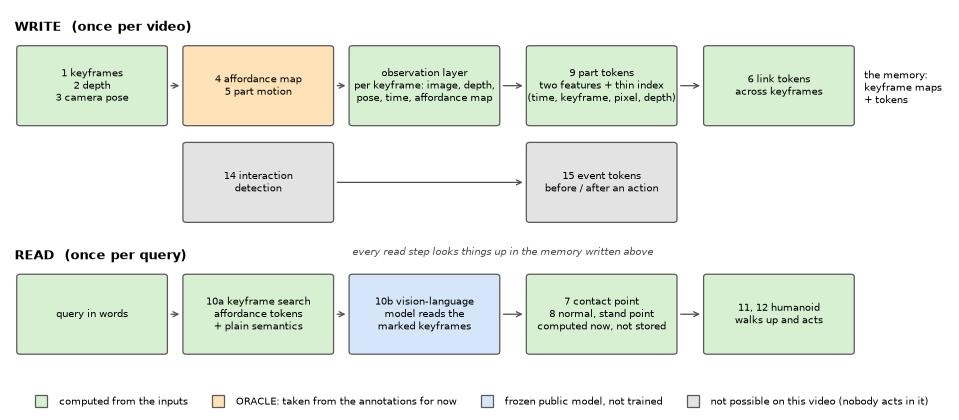

In [2]:
H.overview_figure()
plt.show()

### 环节 1 · 关键帧选取
> **这一步做什么：** 从 1025 帧视频里按时间均匀取 40 帧。之后的记忆只来自这 40 帧。
> **状态：** 真实。

**怎么看图：** 左上是相机走过的路线（俯视），彩色点是关键帧，颜色表示时间。右上是关键帧取多少会影响能看到多少个部件（"看到"指至少占 10 个像素，这个统计用了标注）。下面一排是其中 8 个关键帧。

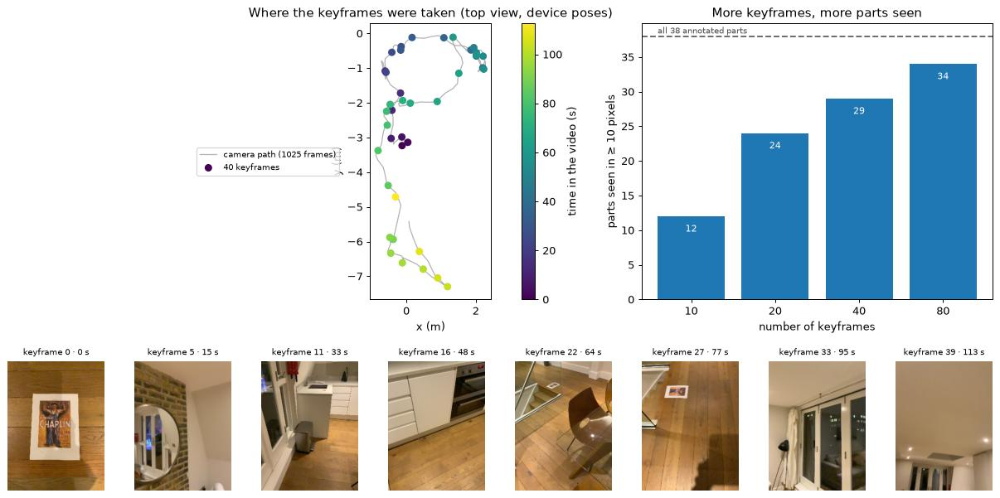

In [3]:
scene = P.load_scene(DATA, VISIT, VIDEO)
keyframes = pick_keyframes(scene, N_KEYFRAMES)
mono = scaled_mono_depths(scene, keyframes, MONO_ID, MONO_CACHE)
frames = [P.input_frame(scene, t, d) for t, d in zip(keyframes, mono)]  # what the memory may use
gt = P.gt_frames(scene, keyframes)  # ground-truth cameras: labels and scoring only
seconds = H.seconds_of(scene, keyframes)
seen_by_count = {n: H.parts_seen(scene, n) for n in (10, 20, 40, 80)}

H.keyframes_figure(scene, keyframes, frames, seen_by_count)
plt.show()

### 环节 2 · 深度
> **这一步做什么：** 给每个关键帧一张深度图。用单目深度模型（Depth Anything V2）估计，再按这一帧的设备 LiDAR 校正尺度。
> **状态：** 真实。最右一格是真值，只用于打分。

**怎么看图：** 第 2、3 格是两种可用的输入深度。LiDAR 更准但分辨率低、有空洞；单目深度是稠密的，小部件处误差更大。

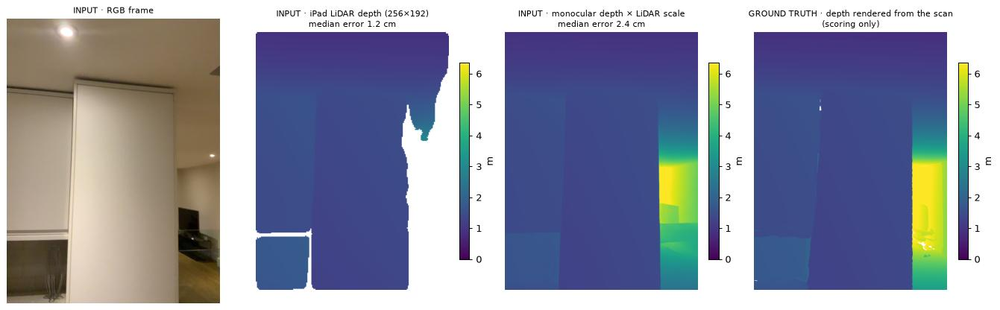

monocular depth × LiDAR scale, median error over the 40 keyframes: 4.7 cm


In [4]:
inputs_figure(scene, keyframes[18], mono[18], gt[18])
plt.show()
whole = [100 * depth_errors(m, g.depth_m)["median_abs_m"] for m, g in zip(mono, gt)]
print(f"monocular depth × LiDAR scale, median error over the {len(keyframes)} keyframes: {np.median(whole):.1f} cm")

### 环节 3 · 相机位姿
> **这一步做什么：** 每个关键帧的相机位置和朝向，直接用设备（ARKit）给出的。
> **状态：** 真实。灰色的真值位姿只用于对照。

**怎么看图：** 左边红线越长，这一帧的位姿误差越大。位姿误差会让"同一个部件在两帧里算出的位置"对不上，环节 6 会看到它的影响。

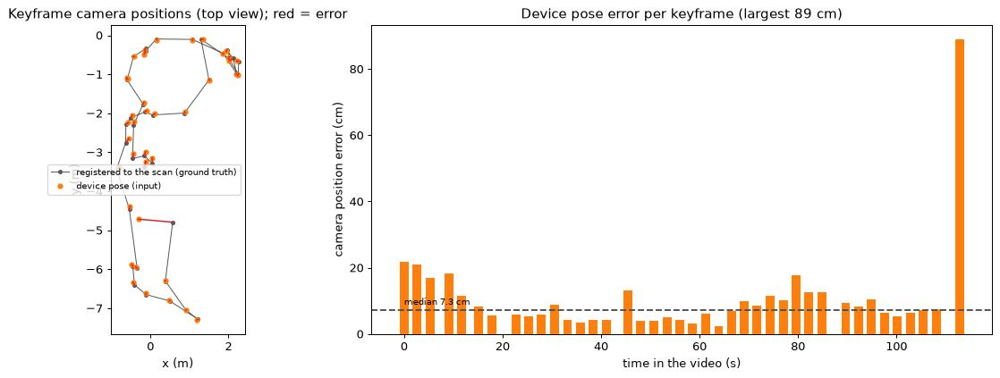

In [5]:
H.pose_figure(scene, keyframes, frames, gt)
plt.show()

### 环节 4 · affordance map
> **这一步做什么：** 给每个关键帧一张图，标出"哪些像素可以操作、用哪种动作"。连在一起的同一种动作的像素算一个**区域**（图里的白框）。
> **状态：** ORACLE。现在是把扫描上的标注投影到关键帧，并且**去掉了部件编号**：记忆只知道动作类型，不知道哪个区域是哪个部件。

**怎么看图：** 颜色是 9 类动作。白框和编号是从图上直接找出的区域，之后每个区域变成一个 token。投影出来的标注是稀疏的点，这里做了一步填充，让它像模型预测的稠密图。

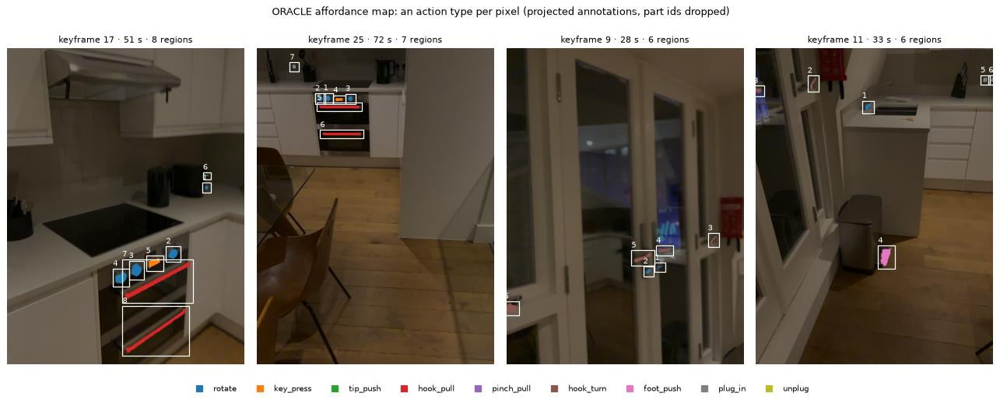

62 regions in 22 of 40 keyframes


In [6]:
part_labels = P.label_maps(scene, gt)  # ORACLE with part ids: kept aside, for scoring only
part_actions = [T.ACTIONS.index(element.label) for element in scene.elements]
action_maps = [T.action_map(labels, part_actions) for labels in part_labels]  # the affordance map: no part ids
regions = [T.find_regions(actions, frame.depth_m, k)[1] for k, (actions, frame) in enumerate(zip(action_maps, frames))]

H.affordance_figure(frames, action_maps, regions, seconds)
plt.show()
print(f"{sum(len(r) for r in regions)} regions in {sum(bool(r) for r in regions)} of {len(frames)} keyframes")

#### 标注和画面对得上吗（做示例时发现的问题）
> **检查什么：** 标注是用真值相机位姿投影到关键帧上的。如果投影出来的位置和画面里的真实部件错开，后面按这个位置取特征、取深度、画框都会偏。
> **状态：** 真值的问题，不是方法的问题；但它影响所有用 ORACLE 标注的环节，也影响以后制作训练标签。

**怎么看图：** 第一张图左边两格是相机转得最快的一个关键帧，右边两格是转得最慢的一个（都只放大有标注的部分）。黄色是投影出来的标注。相机转得快时，黄色明显偏离真实的旋钮和把手；转得慢时基本重合。相机转速由设备位姿算出，是输入，不需要真值。

第二张图检查这种错位是否已经反映在接触点误差上：每个点是 v1 的一个条目，横轴是它的证据帧里相机的转速，纵轴是接触点误差，图题是两者的秩相关系数。只有二十几个条目，这张图只能看趋势，不足以下结论。

原因还没有查清：可能是画面的曝光时刻和位姿的时刻不一致，也可能是画面模糊时真值位姿本身不准。

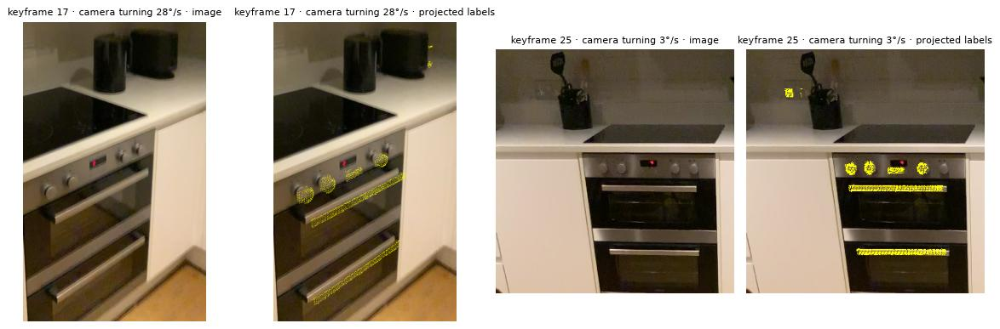

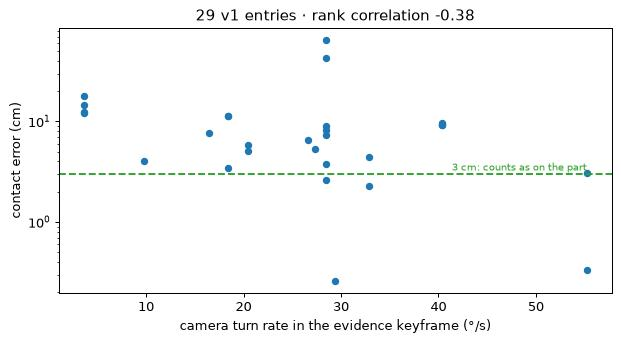

camera turn rate of the 22 keyframes with regions: median 24°/s, from 3 to 55°/s


In [7]:
rates = H.turn_rates(scene, keyframes)  # from device poses: an input
labelled = [k for k in range(len(frames)) if len(regions[k]) >= 4]
fastest, slowest = max(labelled, key=lambda k: rates[k]), min(labelled, key=lambda k: rates[k])
H.alignment_figure(frames, part_labels, rates, [fastest, slowest])
plt.show()
explicit = P.build_memory(scene, keyframes, frames, part_labels)  # v1: explicit entries, written with part ids
with_regions = [k for k in range(len(frames)) if regions[k]]
turn_figure, turn_correlation = H.turn_rate_figure(scene, explicit, dict(zip(keyframes, rates)))
plt.show()
print(f"camera turn rate of the {len(with_regions)} keyframes with regions: median {np.median(rates[with_regions]):.0f}°/s, "
      f"from {rates[with_regions].min():.0f} to {rates[with_regions].max():.0f}°/s")

### 环节 5 · 部件运动
> **这一步做什么：** 每个部件怎么动：转动还是平移，绕哪根轴或朝哪个方向。
> **状态：** ORACLE，直接取自标注。它现在只用于人形画面里的黄色箭头，还没有进入记忆的特征。

**怎么看图：** 白色箭头是标注的运动轴，投影到关键帧上。

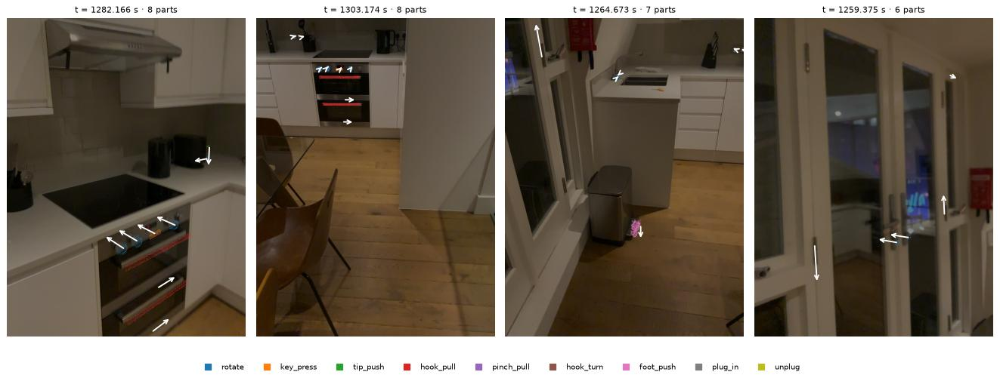

In [8]:
labels_figure(scene, gt, part_labels, keyframes)
plt.show()

---
## 写入记忆

### 环节 9 · 部件 token：两种特征，加一层薄索引
> **这一步做什么：** 把环节 4 的每个区域写成一个 **token**。
> - **视觉特征**（自监督模型 DINOv2）：区域覆盖的图像小块的特征取平均，用来认出"同一个部件"。
> - **语义特征**（图文模型 SigLIP 2）：把区域连同周围一圈裁出来编码，用来和文字查询比较。
> - **薄索引**（显式）：时间、哪个关键帧、区域中心的像素、到相机的深度、动作类型。
>
> **状态：** 真实（现成模型，未训练）。接触点、法向、站立点**不在这里存**。

**怎么看图：** 左：一个关键帧和它的区域。中：整帧的视觉特征（颜色相近表示特征相近）。右：图文模型实际看到的裁剪图，黄框是区域本身。下面的表是这几个 token 存下来的全部内容。

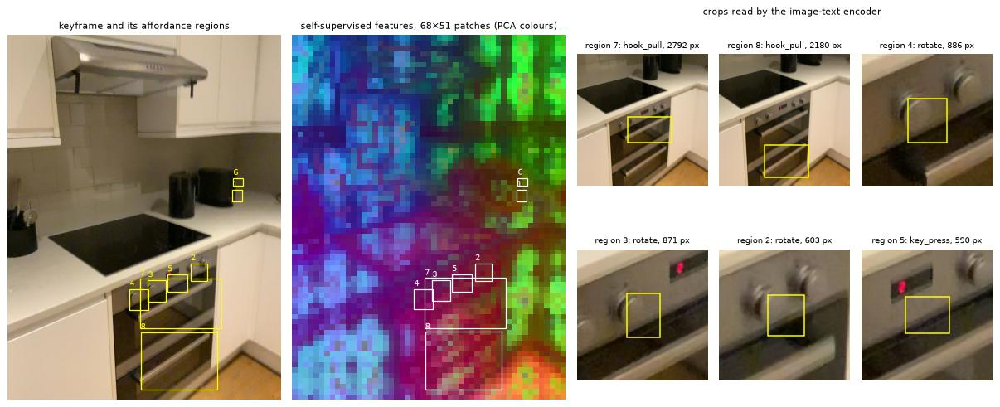

written in 89 s on the CPU: 62 tokens from 40 keyframes


,part,time,keyframe,action type,"pixel (u, v)",depth,pixels,visual feature,semantic feature
token,,,,,,,,,
27,19,50.7 s,17,rotate,"(604, 422)",2.27 m,92,384 numbers,768 numbers
28,14,50.7 s,17,rotate,"(503, 624)",1.42 m,603,384 numbers,768 numbers
29,15,50.7 s,17,rotate,"(392, 674)",1.24 m,871,384 numbers,768 numbers
30,20,50.7 s,17,rotate,"(346, 697)",1.18 m,886,384 numbers,768 numbers
31,16,50.7 s,17,key_press,"(444, 650)",1.33 m,590,384 numbers,768 numbers
32,21,50.7 s,17,tip_push,"(606, 386)",2.45 m,29,384 numbers,768 numbers


In [9]:
start = time.time()
dino = DinoV2Extractor(input_hw=VISUAL_INPUT_HW)
grids = [dino(frame.rgb).grid for frame in frames]
encoder = ImageTextEncoder()
keyframe_vectors = encoder.images([frame.rgb for frame in frames])  # whole keyframes, for plain semantic search
memory = T.write_memory(keyframes, frames, action_maps, grids, encoder.images, scene.up,
                        start_s=float(scene.vid.rgb_times[0]))
write_seconds = time.time() - start

colouring = fit_pca_coloring(np.concatenate([grid.reshape(-1, grid.shape[-1])[::7] for grid in grids]))
example_k = max(range(len(frames)), key=lambda k: len(regions[k]))
in_example = [i for i, token in enumerate(memory.tokens) if token.region.keyframe == example_k]
H.features_figure(frames[example_k], grids[example_k], colouring, [memory.tokens[i].region for i in in_example])
plt.show()
print(f"written in {write_seconds:.0f} s on the CPU: {len(memory.tokens)} tokens from {len(frames)} keyframes")
H.token_table(memory, in_example[:6])

### 环节 6 · 跨帧关联
> **这一步做什么：** 判断不同关键帧里的 token 是不是同一个部件。规则很简单：动作类型相同、算出的位置相距不超过 30 cm、视觉特征足够像，就连到最近的那个部件上；否则新建一个部件。同一个部件的 token 全部保留，不取平均。
> **状态：** 真实。没有用部件编号；编号只在这里用来打分。

**怎么看图：** 第一张图每行是一个部件的全部 token，按时间排列；绿框表示连对了，红框表示把别的部件连了进来。第二张图解释为什么难：左边，同一个部件两次看到时算出的位置并不重合（深度和位姿都有误差）；右边，挨得近的同类部件（比如相邻的旋钮）特征几乎一样，所以只能靠位置区分。

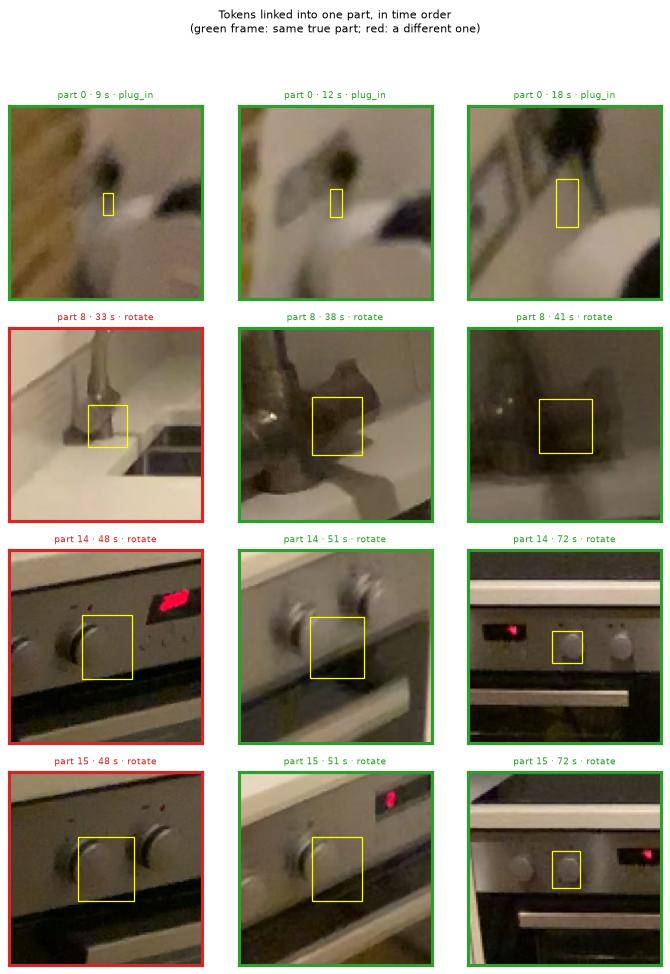

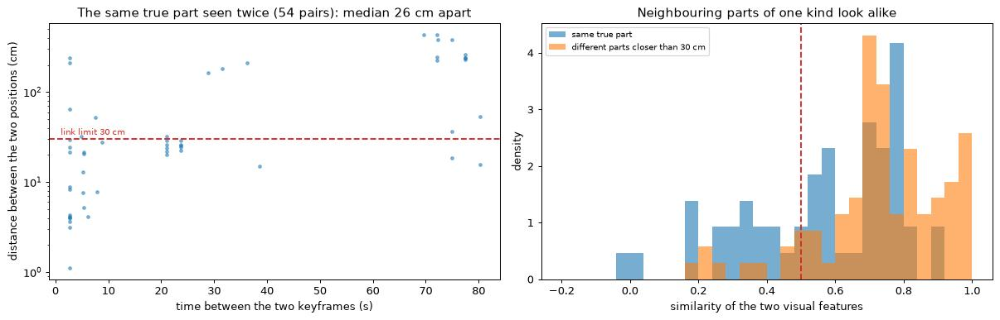

,tokens,true parts with a token,parts in the memory,tokens whose part is not mixed,a true part stays in one piece (mean share),parts linked exactly right
0,62,28,39,94%,83%,14 of 28


In [10]:
truth = H.truth_parts(memory, part_labels, len(scene.elements))  # ground truth, for scoring only
H.linking_figure(memory, frames, truth)
plt.show()
H.pair_figure(memory, frames, truth)
plt.show()
H.linking_scores(memory, truth)

### 记忆里到底存了什么、有多大
> **状态：** 实测的字节数。

L2 记忆 = 每个关键帧的图（原图、深度、affordance 图、位姿）+ 部件 token。下表把它和 v1 的显式条目、和整个房间的激光扫描放在一起比较。

In [11]:
H.storage_table(scene, DATA / VISIT / f"{VISIT}_laser_scan.ply", keyframes, frames, action_maps, memory, explicit)

size
group          what                                                            
L2 memory      keyframe images (as in the dataset)                     13.64 MB
               depth maps (16-bit PNG, millimetres)                    12.72 MB
               affordance maps (PNG)                                    0.10 MB
               camera poses, intrinsics                                  8.1 KB
               part tokens: features of 62 tokens (16-bit)              0.14 MB
               part tokens: thin index                                   5.3 KB
for comparison v1 explicit entries (29 parts)                           15.6 KB
               laser scan of the room (ground truth, never an input)  133.21 MB

---
## 读取记忆

### 环节 10a · 先找关键帧：affordance token 加传统语义
> **这一步做什么：** 给一句任务，先找出最可能包含目标部件的几个关键帧。两种线索相加：
> - **传统语义：** 任务文字和**整个关键帧**的图文相似度。没有 affordance 的记忆只能这样找。
> - **affordance token：** 任务文字和**每个可操作区域的裁剪图**的图文相似度，一个关键帧取它最好的区域。
>
> **状态：** 真实（现成模型）。对错用标注判断：关键帧里确实拍到了任务指的部件就算对。

**怎么看图：** 每行一个任务。左四张是只用传统语义排出的前四个关键帧，右四张是加上 affordance token 之后的前四个；绿框表示这个关键帧里有正确的部件，黄框是其中得分最高的区域。下面的表是全部可回答任务的统计。

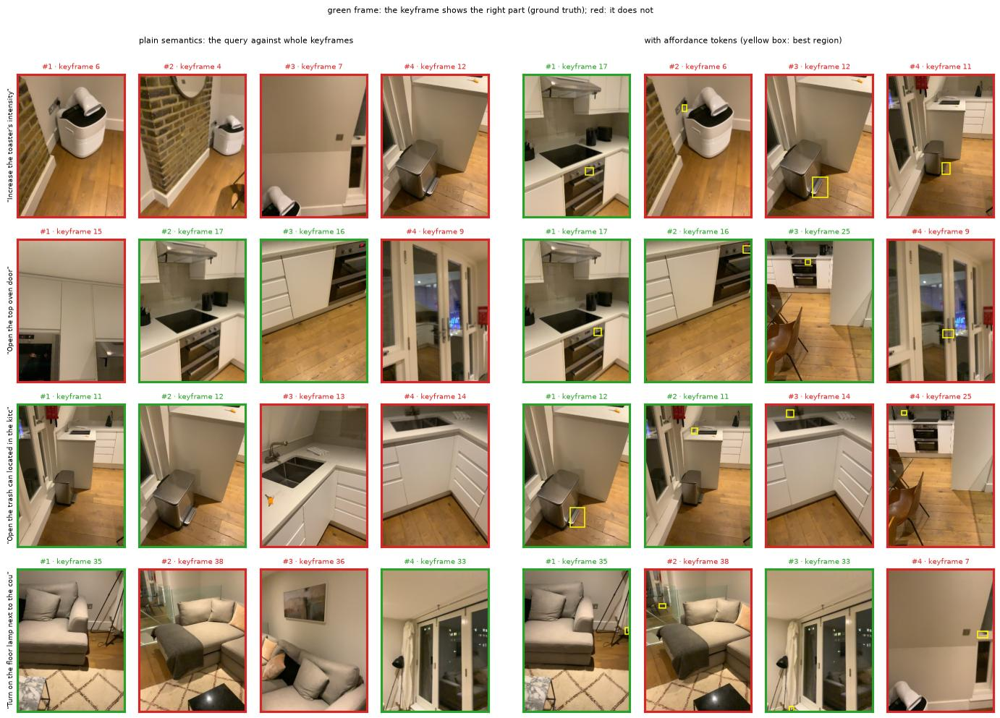

18 of 24 tasks name a part that some keyframe shows; search takes 0.2 ms per query
action type guessed from the task words alone is right for 7 of 18 tasks


,a right keyframe in the top 1,a right keyframe in the top 3,a right keyframe in the top 5
plain semantics (whole keyframes),67%,83%,83%
affordance tokens only,33%,72%,89%
both together (used below),83%,100%,100%
both + action type guessed from the words,83%,100%,100%


In [12]:
tasks = [task for task in H.tasks_of(scene, part_labels) if task.keyframes]  # tasks whose part is in some keyframe
query_vectors = encoder.texts([task.text for task in tasks])
token_vectors = np.array([token.semantic for token in memory.tokens])
token_keyframe = [token.region.keyframe for token in memory.tokens]
token_action = [token.region.action for token in memory.tokens]
start = time.time()
scores = [S.score_keyframes(q, keyframe_vectors, token_vectors, token_keyframe, token_action) for q in query_vectors]
search_ms = 1000 * (time.time() - start) / len(tasks)

examples = [next(i for i, task in enumerate(tasks) if task.text == text) for text in EXAMPLE_TASKS]
H.search_figure(frames, memory, [(tasks[i], scores[i]) for i in examples])
plt.show()
action_vectors = encoder.texts([S.ACTION_PROMPTS[name] for name in T.ACTIONS])
affinities = [S.action_affinity(q, action_vectors) for q in query_vectors]
with_action = [S.score_keyframes(q, keyframe_vectors, token_vectors, token_keyframe, token_action, a)
               for q, a in zip(query_vectors, affinities)]
hits = {"plain semantics (whole keyframes)": [S.first_hit(s.ranking("semantic"), t.keyframes) for s, t in zip(scores, tasks)],
        "affordance tokens only": [S.first_hit(s.ranking("afford"), t.keyframes) for s, t in zip(scores, tasks)],
        "both together (used below)": [S.first_hit(s.ranking(), t.keyframes) for s, t in zip(scores, tasks)],
        "both + action type guessed from the words": [S.first_hit(s.ranking(), t.keyframes) for s, t in zip(with_action, tasks)]}
guessed = [int(np.argmax(a)) in {part_actions[p] for p in task.parts} for a, task in zip(affinities, tasks)]
print(f"{len(tasks)} of {len(scene.tasks)} tasks name a part that some keyframe shows; search takes {search_ms:.1f} ms per query")
print(f"action type guessed from the task words alone is right for {sum(guessed)} of {len(tasks)} tasks")
H.search_table(hits)

**关于动作类型：** affordance map 上最有特点的信息是动作类型。这里试了一种最简单的用法：用文字编码器从任务句子里猜动作类型，再给同类型的区域加分。上面打印的那一行是它猜对的比例，表的最后一行是加上它之后的排序结果。猜错的原因很直接："打开"可以是拉、转或者踩，光看文字分不出来。所以下面的流程**先不用文字猜的动作类型排序**，把"这个区域该怎么操作"留给视觉语言模型结合画面判断。动作类型怎么用，是环节 10 留给你的一个待定点。

### 环节 10b · 再交给视觉语言模型
> **这一步做什么：** 把排在最前面的 3 个关键帧交给视觉语言模型，图上每个可操作区域都画了框和编号，问它"要完成这个任务应该操作几号"。它选出的编号对应一个 token。
> **状态：** 现成模型（Qwen3-VL-4B，CPU，未训练）。对错用标注判断。

**怎么看图：** 每个例子是模型实际看到的三张图，绿色粗框是它选的编号。下面的表列出每个任务的结果。

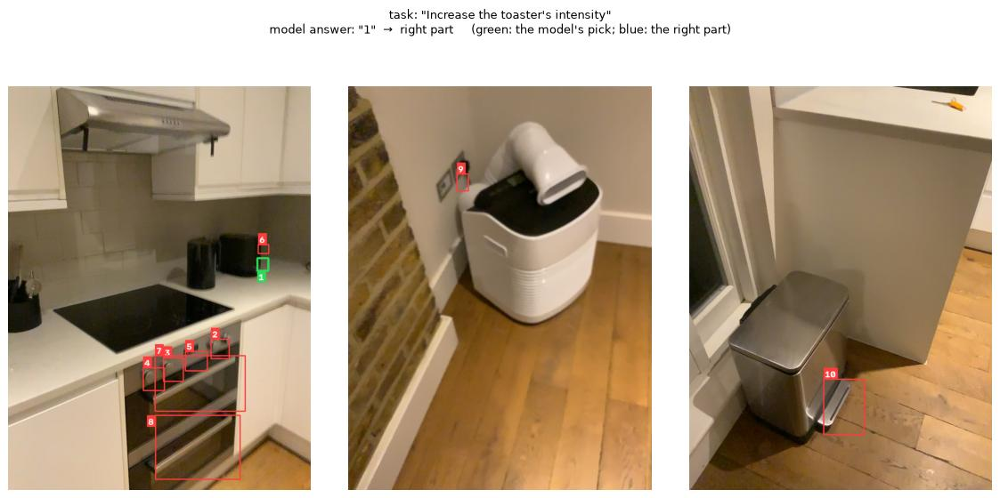

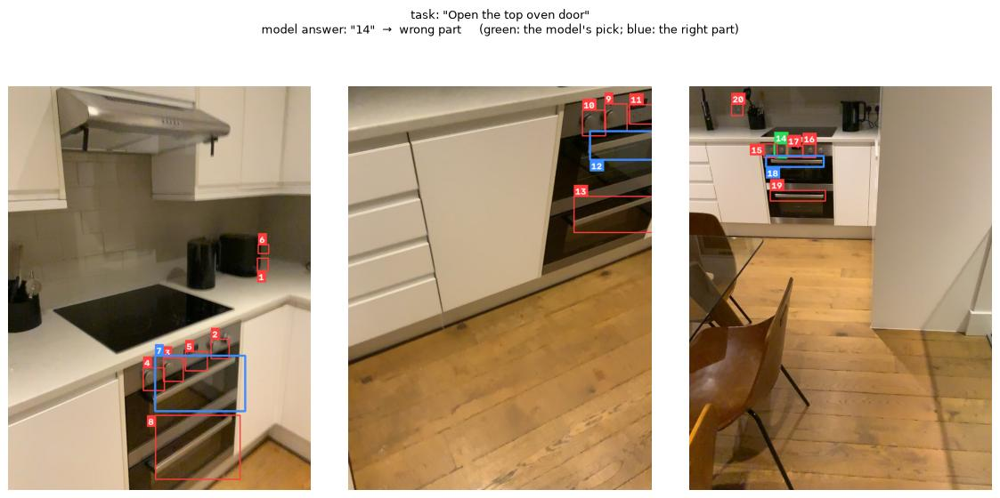

right part chosen: 10 of 18 tasks (18 had a right keyframe among the 3); median 60 s per task on the CPU


,task,a right keyframe among the 3,marks shown,model answer,right part chosen,seconds
0,Increase the toaster's intensity,True,10,1,True,59.8
1,Lock the left balcony door located in the kitchen,True,16,8,False,53.3
2,Lock the right balcony door located in the kitchen,True,16,8,False,66.0
3,Open the bottom oven door,True,20,19,True,49.9
4,Open the glass door next to the black floor lamp,True,11,2,True,59.9
5,Open the left balcony door located in the kitchen,True,14,8,False,76.4
6,Open the right balcony door located in the kitchen,True,14,8,False,142.3
7,Open the small window located near to the portable air conditioner,True,5,2,True,56.5
8,Open the top oven door,True,20,14,False,59.9
9,Open the trash can located in the kitchen near the sink,True,9,5,True,55.7


In [13]:
reader = H.CachedReader(RUNS / "vlm_answers.json", VisionLanguageModel)
rows, chosen_token = [], {}
for index, (task, score) in enumerate(zip(tasks, scores)):
    top = [int(k) for k in score.ranking()[:TOP_KEYFRAMES]]
    images, mark_tokens = H.marked_keyframes(frames, memory, top)
    prompt = S.mark_prompt(task.text, len(mark_tokens))
    reply = reader.ask(H.reading_key(VLM_REVISION, prompt, top, [memory.tokens[t].region.box for t in mark_tokens]), images, prompt)
    mark = S.parse_mark(reply["answer"], len(mark_tokens))
    token = mark_tokens[mark - 1] if mark else None
    chosen_token[index] = (top, mark, token, [n + 1 for n, t in enumerate(mark_tokens) if int(truth[t]) in task.parts])
    rows.append({"task": task.text, "a right keyframe among the 3": bool(task.keyframes & set(top)), "marks shown": len(mark_tokens),
                 "model answer": reply["answer"], "right part chosen": token is not None and int(truth[token]) in task.parts,
                 "seconds": reply["seconds"]})
readings = pd.DataFrame(rows)

for index in examples[:2]:
    top, mark, token, right = chosen_token[index]
    images, _ = H.marked_keyframes(frames, memory, top, chosen=mark, right=right)
    verdict = "right part" if rows[index]["right part chosen"] else "wrong part" if token is not None else "no valid number"
    H.reading_figure(images, tasks[index].text, rows[index]["model answer"], verdict)
    plt.show()
print(f"right part chosen: {int(readings['right part chosen'].sum())} of {len(readings)} tasks "
      f"({int(readings['a right keyframe among the 3'].sum())} had a right keyframe among the 3); "
      f"median {readings['seconds'].median():.0f} s per task on the CPU")
readings

### 环节 7、8 · 读取时现算：接触点、法向、站立点
> **这一步做什么：** 模型选出 token 之后，回到这个 token 的**证据帧**，用那一帧的深度现算三样东西：
> - **接触点**（红点）：区域中心的像素，加上区域深度的中位数。
> - **法向**（青色箭头）：接触点周围一小块表面的朝向。
> - **站立点**（圆环）：沿法向退半米落到地面；是否被挡，只看证据帧和它前后各 3 个关键帧里观察到的点。
>
> **状态：** 真实。这些量不在记忆里，每次查询时计算。

**怎么看图：** 上排是证据帧整幅图，下排是放大。标题里的"contact … cm"是接触点到它所标区域对应的真实部件的距离（真值，只用于打分）。如果上一步选错了部件，这里算出的就是那个错部件的几何量，标题里会写明。

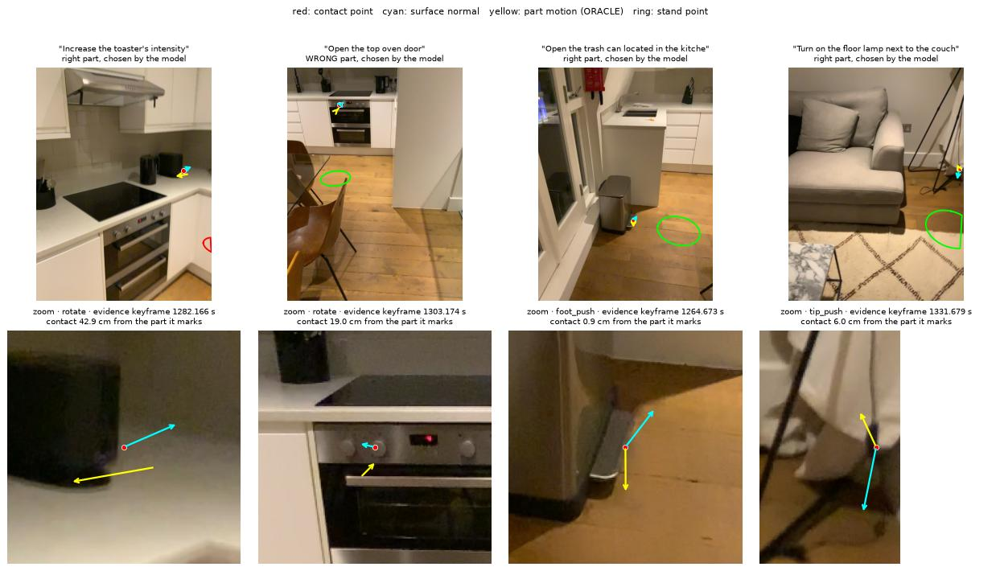

geometry computed at query time in 17 ms per token (median)


In [14]:
view = scan_view(scene)  # ground-truth scan, for scoring and display
by_time = dict(zip(keyframes, frames))
picked, read_ms = [], []
for index in examples:
    top, mark, token, _ = chosen_token[index]
    fallback = token is None
    if fallback:  # no valid answer: the best region among the keyframes that were shown, if any has one
        token = next((int(scores[index].best_token[k]) for k in top if scores[index].best_token[k] != S.NO_TOKEN), None)
    if token is None:
        continue
    start = time.time()
    readout = T.read_geometry(memory, token, frames, scene.up)
    read_ms.append(1000 * (time.time() - start))
    right = int(truth[token]) in tasks[index].parts
    note = ("right part" if right else "WRONG part") + (", search fallback" if fallback else ", chosen by the model")
    picked.append((f'"{tasks[index].text[:40]}"\n{note}', tasks[index].text, H.readout_entry(scene, memory, readout, int(truth[token]))))

H.readout_figure(scene, [title for title, _, _ in picked], [entry for _, _, entry in picked], by_time, view)
plt.show()
print(f"geometry computed at query time in {np.median(read_ms):.0f} ms per token (median)")

### 环节 11、12 · 人形走近并操作
> **这一步做什么：** 用上一步现算的接触点、法向和站立点摆放 SMPL-X 人形：站到站立点，面向部件，部件低就蹲下，把手（踩踏板时是脚）伸到接触点。展示用的画面从整段视频里挑一帧能同时看到人和部件的。
> **状态：** 真实（运动学，没有物理；走路是简单步态）。黄色箭头的部件运动是 ORACLE。

**怎么看图：** 上排贴在真实视频帧上，用输入深度处理遮挡。下排把同一个人放进激光扫描里检查，洋红色是真实部件。视频是同样内容的走近过程。

2 of 4 examples have a video frame that shows both the person and the part


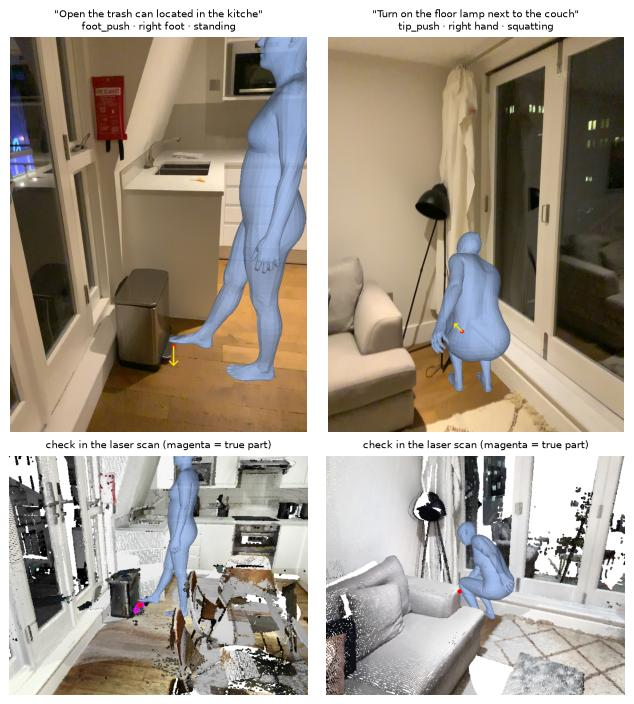

,query,acts with,hand/foot to true part,feet above true floor,body inside scan geometry
0,Open the trash can located in the kitchen near the sink,"right foot, standing",5.1 cm,+5.5 cm,0.0%
1,Turn on the floor lamp next to the couch,"right hand, squatting",9.0 cm,+2.3 cm,0.0%


In [15]:
body = load_smplx(ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz")
shots = shots_for(scene, [(text, entry) for _, text, entry in picked], memory.floor, body, MONO_ID, MONO_CACHE)
print(f"{len(shots)} of {len(picked)} examples have a video frame that shows both the person and the part")
humanoid_figure(scene, shots, body, view)
plt.show()
display(shots_table(scene, shots, view))
CLIP = ASSETS / "mem_l2_approach.mp4"
render_approach_video(scene, P.Memory(memory.times, (), memory.floor, np.zeros((0, 3))), body, shots, view, CLIP)
Video(str(CLIP), embed=True, width=960)

---
### 环节 13 · 评测
> **这一步做什么：** 对照激光扫描打分，并记录成本。
> **状态：** 真实，但只有一个场景。

第一张表比较两种记忆读出的几何量。**L2** 一行：每个部件取像素最多的那个 token，读取时现算。**v1** 一行：写入时就按部件编号算好存下的显式条目。两者用的是同一帧的同一种深度，所以接触点误差应当接近；差别来自 L2 不知道部件编号（区域可能把相邻部件连在一起，同一个部件也可能被拆成几个）。第二张表是这次运行的耗时。

In [16]:
l2_entries = H.readout_memory(scene, memory, frames, truth)
display(scoreboard(scene, {"L2: geometry read at query time, no part ids": l2_entries,
                           "v1: explicit entries written with part ids": explicit}, view))
timing = pd.DataFrame([("write the memory (features, tokens, links)", f"{write_seconds:.0f} s once per video"),
                       ("search keyframes", f"{search_ms:.1f} ms per query"),
                       ("vision-language model reads 3 marked keyframes", f"{readings['seconds'].median():.0f} s per query"),
                       ("contact point, normal, stand point", f"{np.median(read_ms):.0f} ms per query")],
                      columns=["step", "time on the CPU"]).set_index("step")
timing

,parts in memory,contact error (median),contact on the part (≤ 3 cm),stand point free in the scan
depth used to build the memory,,,,
"L2: geometry read at query time, no part ids",39 of 38,11.1 cm,13%,74%
v1: explicit entries written with part ids,29 of 38,7.7 cm,14%,93%


,time on the CPU
step,
"write the memory (features, tokens, links)",89 s once per video
search keyframes,0.2 ms per query
vision-language model reads 3 marked keyframes,60 s per query
"contact point, normal, stand point",17 ms per query


### 环节 14、15 · 交互检测、事件与状态时间线
> **状态：** 示意。SceneFun3D 的视频里没有人操作，这两个环节在这段视频上做不了，下面只画出打算怎么做。按第三轮讨论的安排，S1 做完重建对照之后，先用一段 HD-EPIC 视频把它们的最小版本跑通。

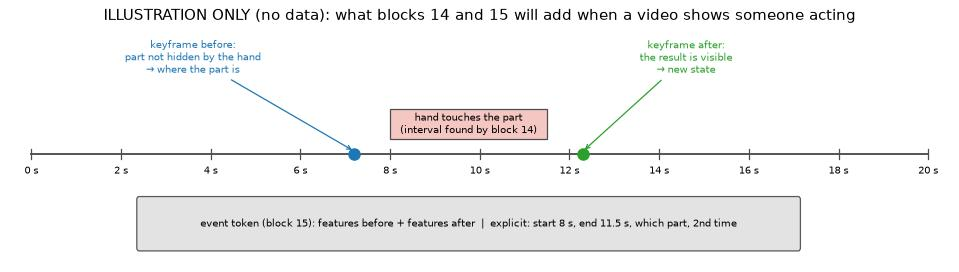

In [17]:
H.events_sketch()
plt.show()

---
### 这次运行的数字汇总

下表由上面各格的结果自动汇总，并保存到 `runs/mem_l2/summary.json`。再强调一次：一个场景、18 个任务，这些数字只说明流程能跑通、误差从哪里来。

In [18]:
recall = {name: S.recall_at(values, (1, 3)) for name, values in hits.items()}
link = H.linking_scores(memory, truth).iloc[0]
summary = {
    "keyframes": len(keyframes), "tokens": len(memory.tokens), "true parts with a token": int(link["true parts with a token"]),
    "parts in the memory": memory.n_parts, "parts linked exactly right": link["parts linked exactly right"],
    "tokens whose part is not mixed": link["tokens whose part is not mixed"],
    "a true part stays in one piece (mean share)": link["a true part stays in one piece (mean share)"],
    "regions that join two true parts": H.mixed_regions(memory, part_labels),
    "same true part seen twice: median distance (cm)": round(H.same_part_gap_cm(memory, frames, truth), 1),
    "parts seen with 10 / 20 / 40 / 80 keyframes": " / ".join(str(v) for v in seen_by_count.values()),
    "camera turn rate of the keyframes with regions, min / median / max (deg/s)": " / ".join(
        f"{value:.0f}" for value in (rates[with_regions].min(), np.median(rates[with_regions]), rates[with_regions].max())),
    "v1 contact error against camera turn rate: rank correlation": round(turn_correlation, 2),
    "answerable tasks": len(tasks),
    "right keyframe in top 1 / top 3, plain semantics": "{:.0%} / {:.0%}".format(*recall["plain semantics (whole keyframes)"].values()),
    "right keyframe in top 1 / top 3, with affordance tokens": "{:.0%} / {:.0%}".format(*recall["both together (used below)"].values()),
    "action type guessed from the words": f"{sum(guessed)} of {len(tasks)}",
    "right part chosen by the vision-language model": f"{int(readings['right part chosen'].sum())} of {len(readings)}",
    "write time (s)": round(write_seconds), "token features (KB)": round(memory.feature_bytes() / 1e3),
}
RUNS.mkdir(parents=True, exist_ok=True)
(RUNS / "summary.json").write_text(json.dumps(summary, indent=1))
pd.DataFrame(summary.items(), columns=["what", "this run"]).set_index("what")

,this run
what,
keyframes,40
tokens,62
true parts with a token,28
parts in the memory,39
parts linked exactly right,14 of 28
tokens whose part is not mixed,94%
a true part stays in one piece (mean share),83%
regions that join two true parts,3
same true part seen twice: median distance (cm),25.7


**请你看的几个点**（意见写在 [pipeline.ipynb](#w1-pipeline) 对应环节的格子里）

1. **环节 4：** 现在的 affordance map 是标注投影加填充。相邻的同类部件会连成一个区域，这在模型预测的图上同样会出现。是否需要让它同时输出"部件之间的分界"。
2. **环节 6：** 关联现在主要靠位置。同一个部件两次看到的位置差经常超过相邻部件的间距。可以改进的方向：用同一帧里部件之间的相对位置；或者只在检索到之后、在候选关键帧之间做关联。
3. **环节 10：** 找关键帧这一步，affordance token 是否按你设想的方式起作用；动作类型应该怎么进入检索。
4. **环节 10：** 视觉语言模型现在看的是整幅关键帧加编号框，小部件在图里很小。是否改成给它每个候选区域的放大图。
5. **环节 7、8：** 几何量读取时现算、不存，是否符合你对"隐式"的设想。
6. **画面：** 这些图里哪些适合对外展示，哪些需要换一种画法。

<a id="w1-phase1"></a>

# 第 10 部分 · 阶段 1 结果

<sub>原文件 `notebooks/mem/phase1_results.ipynb`（11-12 到 11-13）· 生成方式：`notebooks/builders/build_mem_phase1_results.py` · 原样并入，图和数字是当时运行的结果，没有重跑 · 原文件在提交 `3f2baae` 里</sub>

## 阶段 1 结果：记忆的 token 应该写在哪里
**配套文档：** [讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 21 节（实验规格，跑之前写定）· [pipeline.ipynb](#w1-pipeline)（各环节的想法）· [pipeline_examples.ipynb](#w1-examples)（每个环节的一个示例）· SceneFun3D 验证集的 30 个场景 · 2026-11-12

**这次实验回答的问题（预测 A）：** 记忆的预算相同时，由 affordance 决定位置的 token，是否比按其他方式取的 token 更常把正确的证据检索出来。

**读之前请注意**

- **affordance map 是 ORACLE**（标注投影得到，不带部件编号）。所以这里所有数字都是**上限**：它们说明"如果 affordance map 是对的，按它来写记忆值不值得"，不说明现在的模型能做到多少。换成模型预测的 affordance map 是阶段 2 的事。
- **没有训练任何东西。** 图文编码器（SigLIP 2）、通用分割模型（SAM）、视觉语言模型（Qwen3-VL-4B）、单目深度模型（Depth Anything V2）都是现成的公开模型。
- **判定标准在跑实验之前写定**（讨论稿第 21.6 节），本文第 10 节按原样套用，没有因为结果而修改。
- **图里的英文标签：** P0 whole keyframes = 只有整帧；P1 uniform grid = 均匀网格；P2 random places = 随机位置；P3 generic regions = 通用区域；P4 affordance regions = affordance 区域。每种写法在所有图里用同一种颜色。

<sub>重新运行：`python scripts/download_scenefun3d_keyframes.py` 取 30 个场景的关键帧；`bash scripts/remote/queue_phase1.sh` 把每个场景的作业放进 GPU 队列（结果写到 `runs/mem_phase1/`）；`python scripts/aggregate_mem_phase1.py` 汇总；然后 Run All（CPU，几分钟，第 3 节和第 8 节会在一个场景上重新算一遍检索）。</sub>

In [1]:
import contextlib
import io
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")  # no model-loading chatter in the outputs
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.mem import keyframes as K
from affordance3d.mem import phase1_stats as A
from affordance3d.mem import pipeline as P
from affordance3d.mem import search as S
from affordance3d.mem import tokens as T
from affordance3d.mem.encoders import ImageTextEncoder
from report import mem_phase1_helpers as R
from report import mem_steps_helpers as H
from report.mem_demo_helpers import scaled_mono_depths

from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()
plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_colwidth", 120)
torch.set_num_threads(48)  # shared server: leave most cores to others
DATA, RUNS = ROOT / "data" / "scenefun3d", ROOT / "runs" / "mem_phase1"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
results, summary = R.load_runs(RUNS)  # written by scripts/run_mem_phase1.py and scripts/aggregate_mem_phase1.py
diagnostics = R.load_diagnostics(RUNS)  # the follow-up check of section 11, written by scripts/diagnose_mem_phase1.py
print(f"{summary['scenes']} scenes, {summary['tasks']} answerable tasks")

30 scenes, 390 answerable tasks


### 1. 比较的是什么

**记忆的形式（L2）：** 每个关键帧存一张图，再加若干个 token。一个 token 对应关键帧里的一个小区域，存的是这个区域周围一块画面的图文特征。查询来了以后，用查询句子的特征去和整帧、和 token 分别比较，两个分数相加，给关键帧排序。

**这次只改变一件事：token 取在哪里。** 编码器、裁剪规则、打分公式、查询句子全部相同。

| 编号 | 写法 | token 取在哪里 |
| --- | --- | --- |
| P0 | 只有整帧 | 没有 token。没有 affordance 的记忆只能这样检索 |
| P1 | 均匀网格 | 每个关键帧切成固定的格子，每格一个 token |
| P2 | 随机位置 | 个数和大小与 P4 相同，位置随机。只改变"在哪里" |
| P3 | 通用区域 | 不知道 affordance 的分割模型（SAM）给出的区域，按大小与 P4 匹配后随机取 |
| P4 | affordance 区域 | affordance map（ORACLE）上的每一个连通区域 |

- **预算：** 以一个场景里 P4 的 token 数为 1 倍。主要比较在 1 倍上做，另外在 0.25 到 8 倍之间画曲线。
- **主要指标：** 排在第 1 位的关键帧里有没有任务所指的部件（下面叫"第一个关键帧对"），以及前 3 位里有没有。这个指标不依赖 token 的形状，对各种写法公平。
- **统计：** 同一个场景的任务共用一份记忆，所以按场景做自助抽样，给出 95% 置信区间；两种写法的差在同一批任务上成对比较。P2、P3 各用 5 个随机种子，取平均。

### 2. 数据

- **场景：** SceneFun3D 的 30 个验证场景（Fun3DU 和 UniFunc3D 用的 split0），每个场景用文件清单指定的一段视频。
- **关键帧：** 每段视频 40 帧。把视频按时间分成 40 段，每段取设备位姿转得最慢的一帧（只用输入）。
- **"可回答"的任务：** 任务所指的部件至少在一个关键帧里占 10 个像素。看不到的部件，任何写法都检索不到，所以主要数字只在可回答的任务上统计。

第二张表是关键帧处相机转动的快慢（由设备位姿算出）。相机转得快的帧里，标注和画面会错位，所以选转得慢的帧；"均匀取帧"一行是对照。

In [2]:
display(R.data_table(results, summary))
no_lidar = summary.get("keyframes_without_lidar", {})
print("keyframes whose LiDAR frame has no reliable pixel (depth scale taken from the other keyframes of the scene):",
      {visit: len(frames) for visit, frames in no_lidar.items()} or "none")
display(R.turn_rate_table(DATA, results))

,value
what,
scenes scored,30
scenes without an answerable task (not scored),0
tasks: all / answerable (the part is visible in a keyframe),445 / 390
keyframes per scene,40
annotated parts (all scenes run),561
"of these, visible in the steady keyframes / in evenly spaced keyframes",481 / 501
P4 tokens per scene: median (smallest to largest),63 (10 to 115)
generic regions per scene (pool of P3): median,2265


keyframes whose LiDAR frame has no reliable pixel (depth scale taken from the other keyframes of the scene): {'422842': 1, '423070': 1, '434888': 2, '438775': 1, '466112': 1, '466876': 1}


,keyframes,median turn rate (deg/s),90th percentile (deg/s),fastest (deg/s)
steady keyframes (used),1200.0,8.1,20.7,63.7
evenly spaced keyframes (for comparison),1200.0,21.0,42.0,116.2


### 3. 五种写法在画面上的样子

下面用一个场景的三个关键帧，画出预算为 1 倍时每种写法的 token 落在哪里。**这个场景不是挑出来的**：取的是"P4 与 P3 的差"在所有场景里居中的那一个（至少有 10 条可回答的任务）。

**怎么看图：** 每一行是同一个关键帧，每一列是一种写法，每个框是一个 token。三行分别是 affordance 区域最多、居中、最少的关键帧。P4 把 token 集中在有可操作部件的画面上；P1 平均铺开；P2、P3 的 token 总数与 P4 相同，但分散在所有关键帧里。

scene 468476: 51 affordance regions in 40 keyframes
keyframes without any token: {'P2 random places': 10, 'P3 generic regions': 15, 'P4 affordance regions': 17}


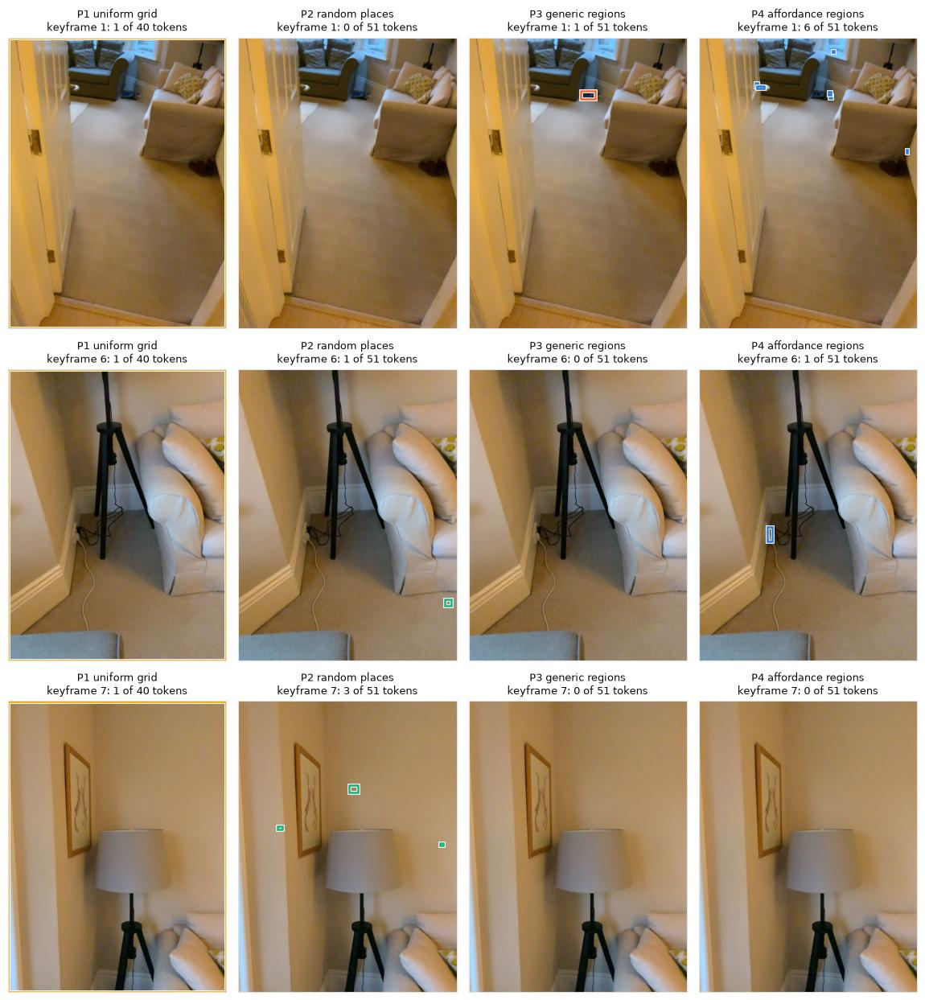

In [3]:
EXAMPLE = R.typical_scene(results)
example = next(result for result in results if result["visit"] == EXAMPLE)
scene = P.load_scene(DATA, EXAMPLE, example["video"])
times = K.scene_keyframes(scene, example["keyframes"], example["n_keyframes"])
mono = scaled_mono_depths(scene, times, MONO_ID, RUNS / "mono" / example["video"])  # cached by the GPU run
frames = [P.input_frame(scene, t, d) for t, d in zip(times, mono)]
labels = P.label_maps(scene, P.gt_frames(scene, times))  # ORACLE with part ids: scoring and drawing only
actions = [T.ACTIONS.index(e.label) if e.label in T.ACTIONS else T.NO_ACTION for e in scene.elements]
action_maps = [T.action_map(label, actions) for label in labels]  # the ORACLE affordance map: action types, no part ids
pool = R.generic_pool(RUNS / "regions" / f"{EXAMPLE}.json", frames[0].image_hw)
sets = R.token_sets(frames, action_maps, pool)  # the same random draws as the GPU run (seed 0)

per_keyframe = np.bincount([c.keyframe for c in sets[A.P4]], minlength=len(frames))
by_count = np.argsort(per_keyframe, kind="stable")
shown = [int(by_count[-1]), int(by_count[len(by_count) // 2]), int(by_count[0])]
empty = {R.POLICY_NAMES[name]: len(frames) - len({c.keyframe for c in sets[name]}) for name in (A.P2, A.P3, A.P4)}
print(f"scene {EXAMPLE}: {len(sets[A.P4])} affordance regions in {len(frames)} keyframes")
print("keyframes without any token:", empty)
set_matplotlib_formats("jpeg")
R.policies_figure(frames, sets, shown)
plt.show()

### 4. 主要结果：预算为 1 倍时

**怎么看图：** 左边是每种写法"第一个关键帧对"的比例，黑线是 95% 置信区间。右边是 P4 减去其他写法的差（同一批任务成对比较），横线是差值的 95% 置信区间；**区间不跨过 0，才算有差别**。

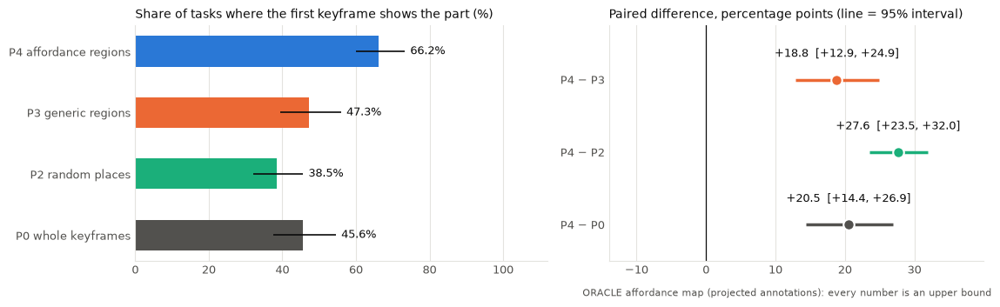

,value,"95% interval, low","95% interval, high"
P0,45.6,37.4,54.5
P2,38.5,32.0,45.6
P3,47.3,39.5,55.9
P4,66.2,60.0,73.3
P4 minus P0,20.5,14.4,26.9
P4 minus P2,27.6,23.5,32.0
P4 minus P3,18.8,12.9,24.9


In [4]:
set_matplotlib_formats("png")
R.headline_figure(summary, "first_keyframe_right", "the first keyframe shows the part")
plt.show()
display(R.rates_table(summary["first_keyframe_right"]))

同样的比较，换成"前 3 个关键帧里有没有"（之后交给视觉语言模型看的就是前 3 个关键帧）：

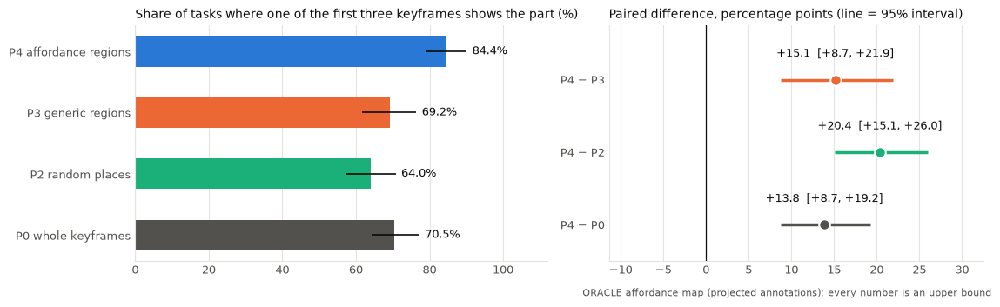

,value,"95% interval, low","95% interval, high"
P0,70.5,64.3,77.3
P2,64.0,57.3,70.8
P3,69.2,61.8,76.4
P4,84.4,79.1,90.1
P4 minus P0,13.8,8.7,19.2
P4 minus P2,20.4,15.1,26.0
P4 minus P3,15.1,8.7,21.9


In [5]:
R.headline_figure(summary, "right_keyframe_in_top3", "one of the first three keyframes shows the part")
plt.show()
display(R.rates_table(summary["right_keyframe_in_top3"]))

### 5. 预算曲线：多给 token 能不能追上

**怎么看图：** 横轴是记忆的预算（token 数相对于 P4 的倍数，对数刻度），纵轴是"第一个关键帧对"的比例，色带是 95% 置信区间。虚线是只有整帧（P0）的水平。点线是第 11 节加的一组：不写任何 token，只告诉检索哪些关键帧里有 affordance 区域（每帧一个比特）。**这条点线不低于图上任何一种不按 affordance 写的方法（图上只画了 30 个场景都跑了的设置），所以曲线之间的差距不能读成 token 的效率**，第 11 节把帧级信息和 token 分开。P4 最多只有 1 倍（affordance 区域就这么多），其他写法一直给到 8 倍。P1 的格子数是固定的几档，所以它的点不落在整数倍上。

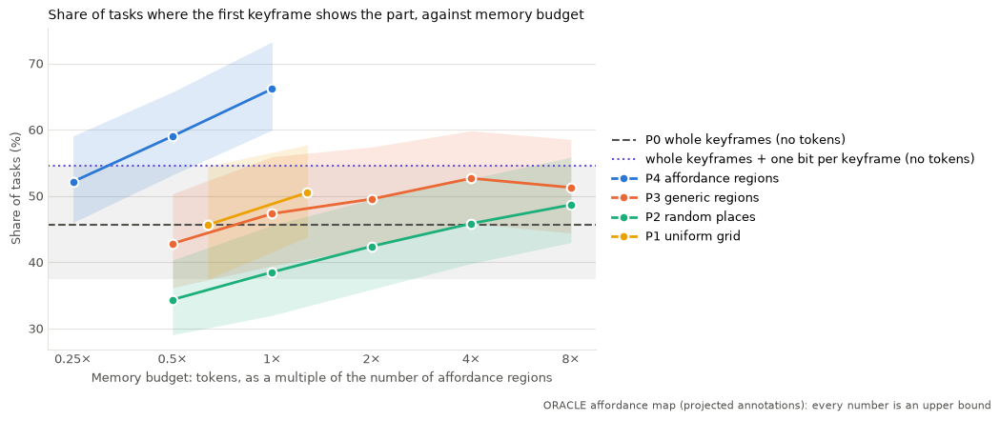

tokens  rate   low  high  scenes
policy                budget                                  
P4 affordance regions 0.25      15.0  52.2  46.0  59.1      30
                      0.50      31.0  59.0  53.2  65.7      30
                      1.00      62.0  66.2  60.0  73.3      30
P3 generic regions    0.50      31.0  42.8  36.2  50.3      30
                      1.00      62.0  47.3  39.5  55.9      30
                      2.00     123.0  49.5  42.3  57.4      30
                      4.00     247.0  52.7  45.9  59.8      30
                      8.00     493.0  51.3  44.4  58.5      30
P2 random places      0.50      31.0  34.4  29.1  40.3      30
                      1.00      62.0  38.5  32.0  45.6      30
                      2.00     123.0  42.4  35.9  49.5      30
                      4.00     247.0  45.8  39.8  52.6      30
                      8.00     493.0  48.7  43.0  55.9      30
P1 uniform grid 1x1   0.64      40.0  45.6  37.4  54.5      30
P1 uniform grid 2x1   1.28      80.0  50.5  43.8  57.7      30
P1 uniform grid 2x2   2.35     160.0  51.8  45.2  59.0      29
P1 uniform grid 3x2   3.50     240.0  51.8  45.4  59.4      28
P1 uniform grid 3x3   5.18     360.0  55.4  49.0  62.5      26
P1 uniform grid 4x3   6.72     480.0  51.6  43.2  61.8      22
P1 uniform grid 4x4   7.86     640.0  54.2  46.1  64.2      18
P1 uniform grid 6x4   10.61    960.0  54.1  45.5  65.1      10

In [6]:
R.budget_figure(results, "hit1", "the first keyframe shows the part", bit=diagnostics["first_keyframe_right"][R.BIT])
plt.show()
curves = pd.DataFrame([point for name in (A.P4, A.P3, A.P2, A.P1) for point in summary["curves"][name]])
curves[["rate", "low", "high"]] = (100 * curves[["rate", "low", "high"]]).round(1)
display(curves.round({"budget": 2, "tokens": 0}).set_index(["policy", "budget"]))

**多给预算以后再比一次。** 这一项不属于预先写定的判定规则，是为了排除一个可能的偏差而加的检查。

预算为 1 倍时，P2、P3 的 token 是散开取的，会有一些关键帧一个 token 也没有（第 3 节的输出里有那个场景的数目）；而打分公式给没有 token 的关键帧一个固定的低分。对 P4，"这一帧没有可操作的部件"是有用的信息；对 P2、P3，哪一帧没有 token 只是运气。预算到 4 至 8 倍时，P2、P3 这种靠运气的空关键帧基本没有了（第 11 节给出数目）。但 P4 从"哪些关键帧里有可操作的部件"得到的信息仍然在，所以下表同样不能读成 token 的效率。

下表是 **P4 在 1 倍预算下的结果，减去其他写法在更大预算下的结果**（同一批任务成对比较，单位是百分点）。

In [7]:
display(R.rates_table(summary["affordance_at_one_against_more"]))

,value,"95% interval, low","95% interval, high"
P4 at 1x minus P3 at 2x,16.6,11.2,22.8
P4 at 1x minus P3 at 4x,13.5,8.1,19.8
P4 at 1x minus P3 at 8x,14.9,9.2,21.3
P4 at 1x minus P2 at 2x,23.7,20.1,27.4
P4 at 1x minus P2 at 4x,20.3,17.1,24.2
P4 at 1x minus P2 at 8x,17.5,13.4,21.9
"P4 at 1x minus P1 uniform grid 1x1 (about 0.6x, 30 scenes)",20.5,14.4,26.9
"P4 at 1x minus P1 uniform grid 2x1 (about 1.3x, 30 scenes)",15.6,10.0,21.9
"P4 at 1x minus P1 uniform grid 2x2 (about 2.4x, 29 scenes)",14.1,8.6,19.5
"P4 at 1x minus P1 uniform grid 3x2 (about 3.5x, 28 scenes)",13.7,7.8,19.2


**token 比只有整帧多带来什么？** 同样是规格之外的补充：各种写法减去 P0（成对比较，百分点）。最后两行是 P4 只留四分之一和一半的 token，可以看作 affordance map 漏掉一部分部件时的情形。再下面是 P2、P3 在 1 倍预算下各个随机种子的最低和最高结果。

In [8]:
display(R.rates_table(summary["others_against_whole"]))
spread = pd.DataFrame(summary["seed_spread"]).T
spread[["lowest", "highest"]] = (100 * spread[["lowest", "highest"]]).round(1)
display(spread)

,value,"95% interval, low","95% interval, high"
P3 at 1x minus P0,1.7,-3.5,7.5
P3 at 4x minus P0,7.0,2.6,11.7
P3 at 8x minus P0,5.6,0.2,11.7
P2 at 1x minus P0,-7.1,-11.7,-2.3
P2 at 8x minus P0,3.0,-1.5,7.8
P1 uniform grid 2x1 minus P0,4.9,0.8,8.9
P4 at 0.25x minus P0,6.5,0.4,13.6
P4 at 0.5x minus P0,13.4,6.9,20.5


,seeds,lowest,highest
P2,5.0,36.7,41.5
P3,5.0,45.9,49.0


### 6. 逐个场景看

总体的差可能来自少数几个场景。下面把每个场景里"P4 减去另一种写法"的差从大到小排开。

**怎么看图：** 每根柱是一个场景。柱子朝上（P4 的颜色）表示这个场景里 P4 更好，朝下（另一种写法的颜色）表示另一种写法更好。每个场景的任务数从 3 条到 27 条不等，任务少的场景柱子会很长（P4 − P0 一格里最朝下的那一根，是只有 3 条任务的场景）。

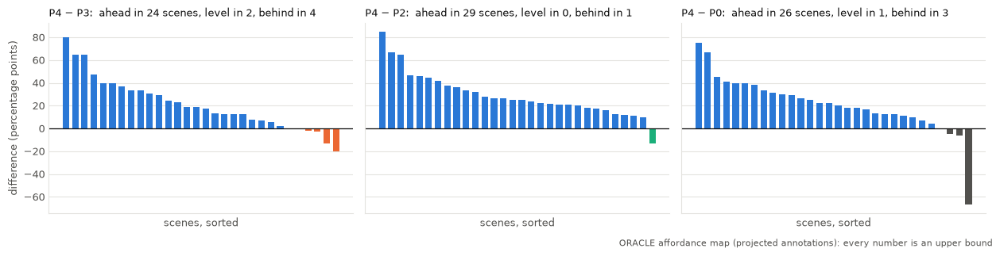

In [9]:
R.per_scene_figure(results)
plt.show()

### 7. 得分最高的 token 是否落在目标部件上

上面的指标只看关键帧对不对。这里再看一步：对查询得分最高的那个 token，它的区域是否盖住了任务所指的部件。同时给出区域的面积，避免"框大所以容易中"。

In [10]:
display(R.token_table(results))

,best token is on the target part (%),95% interval,tokens per scene,median region area (% of the image)
P4 affordance regions,30.0,24.7 to 36.2,61.7,0.06
P3 generic regions,5.4,3.4 to 8.0,61.7,0.06
P2 random places,1.0,0.5 to 1.5,61.7,0.06


### 8. 端到端：把前 3 个关键帧交给视觉语言模型

检索之后，把得分最高的 3 个关键帧连同 token 的编号框交给视觉语言模型，让它选一个框。选中的框盖住任务所指的部件，算对。只对 P4 和 P3 做。

**怎么看图：** 与第 4 节的画法相同。注意这一步的绝对数字不高：模型看的是整幅关键帧，小部件在图里很小（[pipeline.ipynb](#w1-pipeline) 环节 10 里记着这个缺口）。

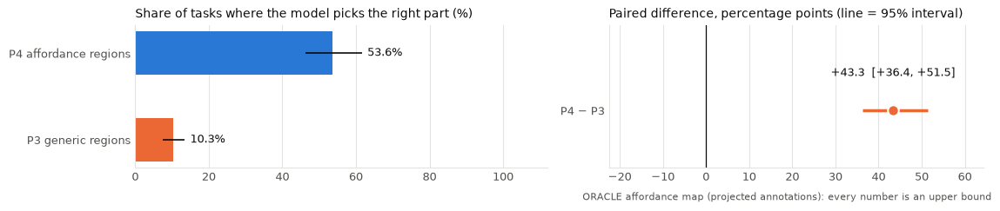

,value,"95% interval, low","95% interval, high"
P4 affordance regions,53.6,46.2,61.6
P3 generic regions,10.3,7.5,13.4
P4 minus P3,43.3,36.4,51.5


numbered boxes shown to the model per task, mean: {'P4 affordance regions': 10.6, 'P3 generic regions': 8.6}


In [11]:
R.reading_figure(summary)
plt.show()
display(R.rates_table({name: row for name, row in summary["reading"].items()}))
shown_marks = {name: float(np.mean([np.mean(result["reading"][name]["marks_shown"]) for result in results]))
               for name in R.READING_NAMES.values() if name in summary["reading"]}
print("numbered boxes shown to the model per task, mean:", {name: round(value, 1) for name, value in shown_marks.items()})

#### 几个具体的任务

还是第 3 节那个场景。在 CPU 上重新算一遍它的检索（与 GPU 上的结果逐条核对），然后按固定的规则取任务：先取"P4 对而 P3 错"的，再取"P4 对而 P2 错"的，再取"P4 错"的；没有就跳过。

**怎么看图：** 每一行是一条任务，每一列是一种写法排在第 1 位的关键帧。彩色框是这个关键帧里得分最高的 token；绿色圆圈是任务所指的部件（只有关键帧对的时候才有）。画面的边框绿色表示关键帧对，红色表示错。

same outcome as the GPU run: {'P0 whole keyframes': '14 of 14', 'P2 random places': '14 of 14', 'P3 generic regions': '14 of 14', 'P4 affordance regions': '14 of 14'}
ranking the keyframes for one query: 0.1 ms on the CPU (40 keyframes, 51 tokens); turning the query into a vector: 19 ms on the CPU


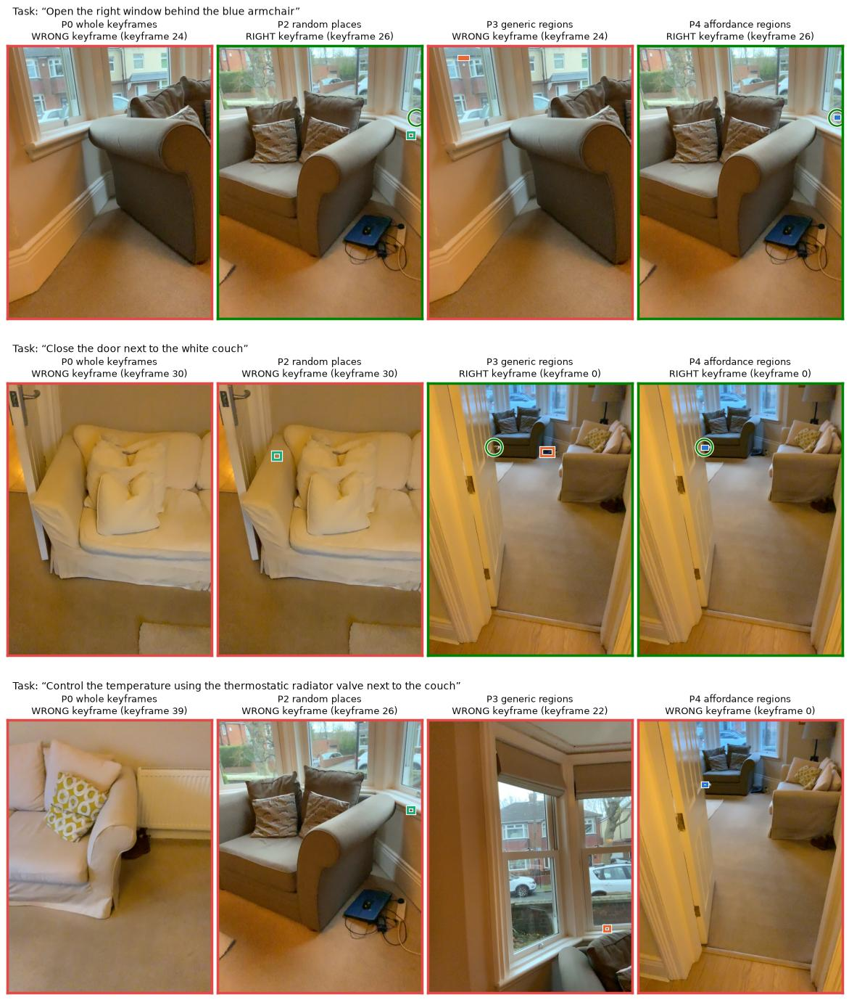

In [12]:
encoder = ImageTextEncoder()
keyframe_vectors = encoder.images([frame.rgb for frame in frames])
vectors = {name: encoder.images(R.crops_of(frames, sets[name])) for name in (A.P2, A.P3, A.P4)}
tasks = [task for task in H.tasks_of(scene, labels) if task.keyframes]
start = time.time()
queries = encoder.texts([task.text for task in tasks])
text_ms = 1000 * (time.time() - start) / len(tasks)
no_tokens = np.zeros((0, keyframe_vectors.shape[1]))
start = time.time()
picks = [{A.P0: R.first_pick(query, keyframe_vectors, [], no_tokens, task.keyframes),
          **{name: R.first_pick(query, keyframe_vectors, sets[name], vectors[name], task.keyframes) for name in (A.P2, A.P3, A.P4)}}
         for query, task in zip(queries, tasks)]
search_ms = 1000 * (time.time() - start) / (4 * len(tasks))

agreement = {}
for name in (A.P0, A.P2, A.P3, A.P4):  # the same tasks, the same token places: the CPU should repeat the GPU run
    stored = next(run for run in example["search"] if run["policy"].startswith(name) and run["seed"] == 0
                  and (name == A.P0 or run["budget"] == 1.0))["hit1"]
    agreement[R.POLICY_NAMES[name]] = f"{sum(int(pick[name].right) == hit for pick, hit in zip(picks, stored))} of {len(tasks)}"
print("same outcome as the GPU run:", agreement)
print(f"ranking the keyframes for one query: {search_ms:.1f} ms on the CPU ({len(frames)} keyframes, {len(sets[A.P4])} tokens); "
      f"turning the query into a vector: {text_ms:.0f} ms on the CPU")

chosen = R.choose_examples(picks, n=3)
set_matplotlib_formats("jpeg")
R.picks_figure(frames, [tasks[i].text for i in chosen], [picks[i] for i in chosen],
               [R.target_pixels(labels, tasks[i].parts) for i in chosen])
plt.show()

### 9. 几何和代价：要不要先重建

L2 记忆不存接触点，查询时从证据关键帧现算。对照做法是先把 40 个关键帧的深度融合成一份点云，再从点云上读。两种读法用同样的关键帧、同样的深度和位姿、同样的 ORACLE 标注；为了只比较读法，这张表按真实的部件编号统计。

**怎么看表：** "误差"是读出的接触点到扫描里这个部件的距离。"3 厘米以内"是能直接去碰的精度。第二行是完整的 L2 读法（部件由记忆自己跨帧关联，没有用部件编号），放在这里作参考。这里的"融合"是把同样的 40 张单目深度图投到一起、按体素去重，没有做多视角一致性检查，也不是 TSDF；所以它只说明"简单融合同样的深度图"并不更准。第二张表是在两种读法都读得出的部件上成对比较。最后一张表里的写入时间不含选关键帧、估计单目深度和预测 affordance map 的时间。

In [13]:
display(R.geometry_table(results, summary))
paired = pd.DataFrame(summary["geometry_paired"]).T
paired["single_frame_closer"] = (100 * paired["single_frame_closer"]).round(1)
display(paired.round(2).rename(columns={"parts": "parts read both ways", "median_difference_cm": "fused minus single keyframe, median (cm)",
                                        "low": "95% interval, low", "high": "95% interval, high",
                                        "single_frame_closer": "single keyframe closer (% of parts)",
                                        "read_ms_per_part": "read time per part (ms)"}))
display(R.cost_table(summary))

,parts,contact read,median error (cm),within 3 cm (% of read),within 3 cm (% of all parts),extra storage per scene (MB),build time per scene (s),read time per part (ms)
"one keyframe, read now (true part ids)",481.0,481.0,4.1,38.5,38.5,0.0,0.0,NaN
"one keyframe, read now (parts linked by the memory)",760.0,760.0,5.5,31.6,31.6,0.0,0.0,17.6
"fused cloud, 1 cm voxels",481.0,466.0,5.4,31.8,30.8,22.5,2.4,130.7
"fused cloud, 2 cm voxels",481.0,441.0,6.0,28.8,26.4,6.5,1.2,57.3
"fused cloud, 5 cm voxels",481.0,290.0,7.7,20.7,12.5,1.0,1.0,36.0


,parts read both ways,"fused minus single keyframe, median (cm)","95% interval, low","95% interval, high",single keyframe closer (% of parts),read time per part (ms)
fused 0.01 m,466.0,0.26,0.12,0.35,58.6,130.67
fused 0.02 m,441.0,0.36,0.21,0.69,60.3,57.33
fused 0.05 m,290.0,0.91,0.47,1.38,67.2,35.96


,value
what,
keyframe images (MB per scene),14.20
depth maps (MB per scene),13.20
affordance maps (MB per scene),0.09
token features (MB per scene),0.14
tokens per scene,61.70
"writing the memory (s per scene, affordance map given)",24.30
"model reading, P4 affordance regions (s per query, median)",1.30
"model reading, P3 generic regions (s per query, median)",1.30


### 10. 关口 G1 的判定

判定标准原文（讨论稿第 21.6 节，跑实验之前写定）。预算为 1 倍时：

- **通过：** P4 的"第一个关键帧对"高于 P3，差值的 95% 置信区间不包含 0；并且端到端选对的比例 P4 不低于 P3。
- **部分通过：** P4 只高于 P2（随机位置），与 P3 没有显著差别。
- **不通过：** P4 不高于 P2。

In [14]:
first, reading = summary["first_keyframe_right"], summary["reading"]
verdict = pd.DataFrame({
    "P4 minus P3, first keyframe right (points)": first["P4 minus P3"], "P4 minus P2, first keyframe right (points)": first["P4 minus P2"],
    "model picks the right part, P4 (%)": reading[R.READING_NAMES[A.P4]], "model picks the right part, P3 (%)": reading[R.READING_NAMES[A.P3]],
}).T[["rate", "low", "high"]]
display((100 * verdict).round(1).rename(columns={"rate": "value", "low": "95% interval, low", "high": "95% interval, high"}))
print("rule of section 21.6, category:", summary["rule_21_6_category"], "| whether gate G1 is passed is the project lead's decision")

,value,"95% interval, low","95% interval, high"
"P4 minus P3, first keyframe right (points)",18.8,12.9,24.9
"P4 minus P2, first keyframe right (points)",27.6,23.5,32.0
"model picks the right part, P4 (%)",53.6,46.2,61.6
"model picks the right part, P3 (%)",10.3,7.5,13.4


rule of section 21.6, category: passed | whether gate G1 is passed is the project lead's decision


### 11. 审稿后加的检查：增益从哪里来

这份结果交给项目负责人之前，由一位独立的审稿人审了一遍。他指出一个第 4、5 节没有分开的问题：

- 打分公式里，一个关键帧如果没有任何 token，token 这一项记为 −3 个标准差。
- 对 P4，"没有 token"等于"这个关键帧里没有标注的可操作部件"，而任务所指的部件一定在有 token 的关键帧里。所以 P4 同时得到了两样东西：**token 的内容**，和**"哪些关键帧值得看"这个帧级信息**。
- 对 P2、P3，哪个关键帧没有 token 只是运气。

下面的检查把这两样分开。计划和每种结果怎么读，是在算之前写定并提交的（讨论稿第 23.2 节）。P2、P3 用 3 个随机种子，只用 CPU；用 CPU 重算的结果与 GPU 上的原结果逐条相同。

| 对照组 | 它知道什么 |
| --- | --- |
| 整帧 + 每帧一个比特 | 哪些关键帧里有 affordance 区域；不用任何 token 的内容 |
| 放进 P4 关键帧的 P2、P3（图里带斜线） | 与 P4 相同的关键帧、每帧个数也相同；帧内的位置是随机的，或者是通用区域 |

**怎么看图：** 左边是六个对照组"第一个关键帧对"的比例，带斜线的两组拿到了与 P4 相同的关键帧。右边是成对比较的差：前三行分别是"只用标记""只用 token""两样都用（P4）"相对只有整帧高多少，这三个数不能简单相加，而且"只用 token"一组的 token 仍然只出现在有标记的关键帧里，所以它也带着一部分标记的作用；后两行是关键帧相同时，"帧内取在哪里"值多少。

CPU repeats the GPU run (task outcomes): {'P0': '390 of 390', 'P4': '390 of 390', 'P2': '1170 of 1170', 'P3': '1170 of 1170', 'P1': '390 of 390'}


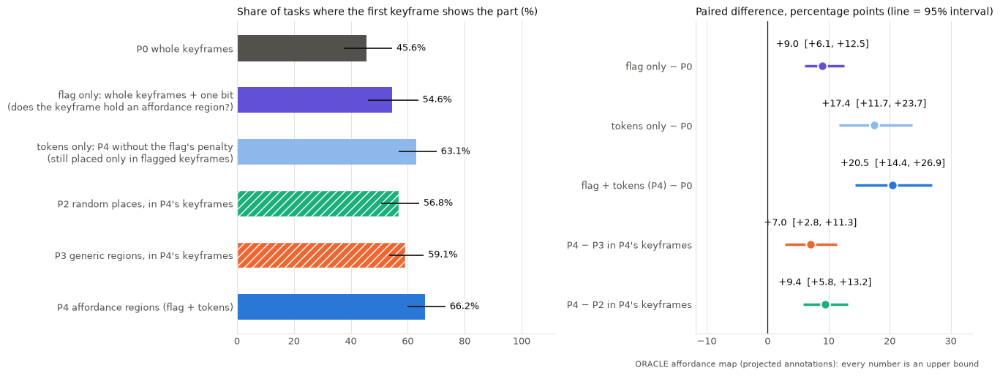

,value,"95% interval, low","95% interval, high"
P0 whole keyframes,45.6,37.4,54.5
P4 affordance regions,66.2,60.0,73.3
P3 generic regions,47.4,39.9,55.7
P2 random places,39.4,32.0,47.4
P1 uniform grid 2x1,50.5,43.8,57.7
whole keyframes + which keyframes hold an affordance region,54.6,46.1,63.7
"P4, no penalty for keyframes without a token",63.1,56.9,70.2
"P3, no penalty for keyframes without a token",48.2,41.0,56.2
"P2, no penalty for keyframes without a token",39.9,32.3,47.9
P3 in the keyframes of P4,59.1,53.4,65.7


In [15]:
print("CPU repeats the GPU run (task outcomes):", diagnostics["repeats_the_run"])
set_matplotlib_formats("png")
R.attribution_figure(diagnostics)
plt.show()
display(R.rates_table({**diagnostics["first_keyframe_right"], **diagnostics["differences"]}))

**结论会不会随打分公式里的两个常数改变？** 下表是每个对照组在 12 组常数下的结果（百分比）：token 一项的权重取 0.25、0.5、1、2；没有 token 的关键帧记 0、−1、−3。原实验用的是"权重 1、−3"。第二张表是 P4（原来的常数）减去每个基线在它自己最好的一组常数下的结果；基线的"最好"是在这 30 个场景上挑的，对基线偏乐观。第三张表是两种写法用同一组常数时，P4 减"放进 P4 关键帧的 P3"的差：token 的权重取 1 或 2 时区间都不含 0，取 0.5 或 0.25 时差变小，多数区间含 0。

最后几行输出：随机选一个关键帧的命中率；端到端一步里给模型看的框有没有一个在目标部件上；各种写法没有 token 的关键帧数；区域面积的中位数（放进 P4 关键帧的 P2 与 P4 完全相同，P3 是 P4 的 1.7 倍左右）；以及 P4 只留四分之一、一半的 token 时，有和没有扣分项的结果。

In [16]:
display(R.sweep_table(diagnostics))
print("best setting of each arm:", diagnostics["best_setting"])
display(R.rates_table(diagnostics["at_best_settings"]))
display(R.rates_table({setting: row["P4 minus P3 same keyframes"] for setting, row in diagnostics["same_setting"].items()}))
print("median region area in pixels:", diagnostics["median_region_area_px"],
      "| P3 in P4's keyframes against P4, median over scenes:", round(diagnostics["area_ratio_same_keyframes_to_p4"], 2))
print("P4 with a part of its tokens, minus P0 (points):",
      {name: f"{100 * row['minus P0']['rate']:+.1f} ({100 * row['minus P0']['low']:+.1f} to {100 * row['minus P0']['high']:+.1f})"
       for name, row in diagnostics["misses"].items()})
print("chance that a random keyframe is right:", {name: f"{100 * value:.1f}%" for name, value in diagnostics["chance"].items()})
print("tasks where a box shown to the model lies on the target part:",
      {name: f"{100 * row['rate']:.1f}% ({100 * row['low']:.1f} to {100 * row['high']:.1f})"
       for name, row in diagnostics["a_shown_box_is_on_the_target"].items()})
print("keyframes without any token, of 40 (mean over scenes):",
      {name: round(value, 1) for name, value in diagnostics["keyframes_without_a_token_of_40"].items()})

,P4 affordance regions,P3 in P4's keyframes,P2 in P4's keyframes,P3 generic regions,P2 random places,P1 uniform grid 2x1,one bit per keyframe
"weight 0.25, empty 0",54.4,53.1,51.1,51.0,47.0,48.2,45.6
"weight 0.25, empty -1",57.4,55.0,53.7,50.4,46.5,48.2,49.5
"weight 0.25, empty -3",60.0,57.9,56.8,50.0,46.3,48.2,53.1
"weight 0.5, empty 0",57.9,55.4,53.8,50.1,45.1,47.7,45.6
"weight 0.5, empty -1",60.5,57.6,56.8,49.7,44.4,47.7,51.5
"weight 0.5, empty -3",63.8,59.0,58.9,49.0,42.8,47.7,54.4
"weight 1, empty 0",63.1,57.5,55.0,48.2,39.9,50.5,45.6
"weight 1, empty -1",65.9,59.0,56.7,47.8,39.4,50.5,53.3
"weight 1, empty -3",66.2,59.1,56.8,47.4,39.4,50.5,54.6
"weight 2, empty 0",63.8,57.4,52.6,44.9,35.0,48.7,45.6


best setting of each arm: {'P4': 'weight 1, empty -3', 'P1': 'weight 1, empty 0', 'P2': 'weight 0.25, empty 0', 'P3': 'weight 0.25, empty 0', 'shortlist': 'weight 1, empty -3', 'P3 same keyframes': 'weight 1, empty -3', 'P2 same keyframes': 'weight 0.5, empty -3'}


,value,"95% interval, low","95% interval, high"
P4 (default) minus P1 at its best setting,15.6,10.0,21.9
P4 (default) minus P2 at its best setting,19.1,13.7,25.3
P4 (default) minus P3 at its best setting,15.1,9.9,20.4
P4 (default) minus shortlist at its best setting,11.5,5.5,17.3
P4 (default) minus P3 same keyframes at its best setting,7.0,2.8,11.3
P4 (default) minus P2 same keyframes at its best setting,7.3,3.8,10.9


,value,"95% interval, low","95% interval, high"
"weight 0.25, empty 0",1.3,-2.2,5.2
"weight 0.25, empty -1",2.5,-0.2,5.5
"weight 0.25, empty -3",2.1,-0.8,5.6
"weight 0.5, empty 0",2.6,-1.6,6.9
"weight 0.5, empty -1",2.9,-1.3,7.4
"weight 0.5, empty -3",4.9,0.5,10.0
"weight 1, empty 0",5.6,1.4,10.0
"weight 1, empty -1",6.9,2.8,11.4
"weight 1, empty -3",7.0,2.8,11.3
"weight 2, empty 0",6.4,0.9,11.4


median region area in pixels: {'P4': 429.0, 'P3 same keyframes': 784.25, 'P2 same keyframes': 429.0, 'P3': 425.25} | P3 in P4's keyframes against P4, median over scenes: 1.74
P4 with a part of its tokens, minus P0 (points): {'P4 with 0.25 of its tokens, empty -3': '+6.5 (+0.4 to +13.6)', 'P4 with 0.25 of its tokens, empty 0': '+6.0 (+0.6 to +12.3)', 'P4 with 0.5 of its tokens, empty -3': '+13.4 (+6.9 to +20.5)', 'P4 with 0.5 of its tokens, empty 0': '+10.8 (+5.0 to +17.3)'}
chance that a random keyframe is right: {'a random keyframe': '9.2%', 'a random keyframe among those with an affordance region': '17.3%'}
tasks where a box shown to the model lies on the target part: {'P4 affordance regions': '83.6% (78.2 to 89.3)', 'P3 generic regions': '20.0% (13.8 to 27.9)'}
keyframes without any token, of 40 (mean over scenes): {'P2 at 1x': 10.1, 'P3 at 1x': 14.9, 'P2 at 2x': 3.9, 'P3 at 2x': 8.0, 'P2 at 4x': 1.1, 'P3 at 4x': 3.2, 'P2 at 8x': 0.2, 'P3 at 8x': 1.2, 'P4 at 1x': 19.1}


### 12. 怎么读这些结果

**按预先写定的规则，G1 的条件都满足：** P4 比 P3 高，差值的区间不含 0；端到端选对的比例 P4 不低于 P3；P4 也高于 P2。**关口是否通过，由项目负责人决定。**

**结果说明了什么**（都是 ORACLE 的上限）

1. **预算相同时，P4 把正确的关键帧排在第 1 位的比例最高。** P4 66.2%，P3 47.3%，P0 45.6%，P2 38.5%。P4 比 P3 高 18.8 个百分点（区间 12.9 到 24.9）。
2. **这个增益里有两样东西：帧级的信息，和 token 本身（第 11 节）。** 只用帧级信息（每个关键帧一个比特，不写任何 token），比只有整帧高 9.0 个百分点（区间 6.1 到 12.5）。只用 token（去掉对空关键帧的扣分），高 17.4 个百分点（区间 11.7 到 23.7）；这里面仍然包含"token 只出现在有可操作部件的关键帧里"这一点，因为同样去掉扣分，把通用区域放进 P4 的关键帧也有 57.5%（比只有整帧高 11.9 个百分点）。两样都用，高 20.5 个百分点。
3. **关键帧相同时，取在 affordance 区域上比取在别处高 7 到 9 个百分点；这个数依赖检索时给 token 的权重。** 对通用区域是 7.0 个百分点（区间 2.8 到 11.3），对随机位置是 9.4 个百分点（区间 5.8 到 13.2）。18.8 是整套写法对 P3 的差，7.0 是其中"帧内取在哪里"的那一部分。token 的权重取 1 或 2 时这个差是 5.6 到 7.0 个百分点，区间都不含 0；权重降到 0.5 或 0.25 时缩小到 1.3 到 4.9 个百分点，多数区间含 0。
4. **不按 affordance 写的方法，在试过的预算里都没有追上；但这主要说明帧级的功能信息很值钱，不能读成 token 的效率。** 在 30 个场景都跑了的设置里，P3 最高是 4 倍预算时的 52.7%，而"每帧一个比特"不写任何 token 就是 54.6%。P4 在 1 倍预算下比 P3 在 8 倍预算下高 14.9 个百分点（区间 9.2 到 21.3）。每个基线取 12 组常数里最好的一组，P4 仍领先 15 个百分点以上。
5. **不按 affordance 取的 token，在 1 倍预算下比只有整帧多不出什么；预算加大后能多出几个百分点。** 1 倍时，通用区域 +1.7（区间 −3.5 到 +7.5），随机位置 −7.1（区间 −11.7 到 −2.3）。通用区域到 4 倍时是 +7.0（区间 2.6 到 11.7）。
6. **端到端的差距主要来自候选。** 视觉语言模型选对部件的比例：P4 53.6%，P3 10.3%。给模型看的框里有一个在目标部件上的任务，P4 是 83.6%，P3 只有 20.0%。
7. **简单融合同样的深度图，没有让接触点更准。** 从单个关键帧现算，中位误差 4.1 厘米；融合成 1 厘米体素的点云再读，是 5.4 厘米。在两种读法都读得出的 466 个部件上成对比较，融合的误差中位数多 0.26 厘米（区间 0.12 到 0.35）。

**结果没有说明什么**

- **这是最有利于 affordance 的设定。** affordance map 是标注投影来的，而 SceneFun3D 的任务只问标注过的功能部件：任务所指的部件一定在有 affordance 区域的关键帧里。换成模型预测的 affordance map，会漏、会错，增益会缩小；缩小多少，要到阶段 2 才知道。
- **漏掉部件时，增益会很快变小。** P4 随机只留四分之一的 token，比只有整帧只高 6.5 个百分点（区间 0.4 到 13.6）；去掉对空关键帧的扣分再算，也差不多（6.0 个百分点）。
- **没有测"普通物体"的查询。** affordance token 对这类查询会不会变差，这次回答不了。
- **P3 只是通用区域的一种取法。** 这里用的是 SAM 的分割结果，按大小与 P4 匹配后取。其他取法（例如开放词表检测器给出的区域）没有比；把全部分割区域都写进记忆的上限也没有跑。
- **接触精度仍然不够。** 两种读法落在 3 厘米以内的都不到四成。
- **没有成立的一项：** 选相机转得慢的帧，关键帧处的转速中位数从每秒 21.0 度降到 8.1 度，但看得到的部件没有变多，反而略少（561 个部件里 481 个；均匀取帧是 501 个）。

**与规格（讨论稿第 21 节）不同的地方**

- 6 个场景里共有 7 个关键帧，数据集给的 LiDAR 置信度整张为 0，无法按规格用 LiDAR 校正单目深度的尺度。这些帧改用同一场景其余关键帧的尺度中位数（只用输入）。
- 1 个场景里有一个 affordance 区域大到填满了算法线用的窗口。这种情况改用区域自身的表面算法线。
- 这两处修正之后，30 个场景全部在修正后的代码上重跑了一遍；原先成功的 23 个场景，结果与第一次逐条相同。
- 端到端一步里，P3 只用了一个随机种子的 token（规格写的是 5 个种子；检索指标用了 5 个）。
- "token 在目标部件上"的判断，给区域框留了 8 个像素的余量。
- P3 "按大小匹配"取的是面积最接近的区域，不同种子取到的区域有重叠，不是相互独立的抽取。
- 第 5 节后面的表和第 11 节，是规格之外加的检查，不参与第 10 节的判定。
- 预算曲线里，一档网格的 token 数超过 P4 的 12 倍时不跑，所以 token 少的场景里没有细网格；图上只画了 30 个场景都有的两档，全部档位在表里（最后一列是场景数）。

完整的记录在[讨论稿](../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 22、23 节，审稿意见和处理在 `helm/REVIEW.md`。